# Cyclistic Bike-Share Case Study
## Analyze Stage — Member vs Casual Rider Behavior

### Business Question
How do annual members and casual riders use Cyclistic bikes differently?

### Analysis Period
January–December 2025

### Objective
Analyze the validated annual Cyclistic trip dataset to identify
behavioral differences between members and casual riders.

In [1]:
import pandas as pd
from pathlib import Path

# Path to the validated annual dataset
annual_path = Path("../data/cleaned/cyclistic_2025_annual.parquet")

# Check that the file exists
print("File exists:", annual_path.exists())

# Load the validated annual dataset
annual_df = pd.read_parquet(annual_path)

print("Dataset loaded successfully.")
print("Rows:", len(annual_df))
print("Columns:", len(annual_df.columns))

File exists: True
Dataset loaded successfully.
Rows: 5552994
Columns: 21


In [2]:
# Display the column names
print("Columns in annual_df:")
print(annual_df.columns.tolist())

Columns in annual_df:
['ride_id', 'rideable_type', 'started_at', 'ended_at', 'start_station_name', 'start_station_id', 'end_station_name', 'end_station_id', 'start_lat', 'start_lng', 'end_lat', 'end_lng', 'member_casual', 'ride_duration_seconds', 'ride_length', 'short_duration_flag', 'extreme_duration_flag', 'negative_duration_flag', 'month_boundary_flag', 'day_of_week_num', 'day_of_week']


In [3]:
# Inspect the data types
annual_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5552994 entries, 0 to 5552993
Data columns (total 21 columns):
 #   Column                  Dtype          
---  ------                  -----          
 0   ride_id                 string         
 1   rideable_type           string         
 2   started_at              datetime64[ns] 
 3   ended_at                datetime64[ns] 
 4   start_station_name      string         
 5   start_station_id        string         
 6   end_station_name        string         
 7   end_station_id          string         
 8   start_lat               float64        
 9   start_lng               float64        
 10  end_lat                 float64        
 11  end_lng                 float64        
 12  member_casual           string         
 13  ride_duration_seconds   float64        
 14  ride_length             timedelta64[ns]
 15  short_duration_flag     bool           
 16  extreme_duration_flag   bool           
 17  negative_duration_flag  boo

## Step 2 — Analysis Baseline

Before comparing member and casual rider behavior, establish the overall
size and composition of the 2025 dataset.

We will examine:
- total number of rides
- rides by rider type
- percentage of rides by rider type
- flagged duration and month-boundary records

This provides a baseline for the detailed analysis that follows.

In [4]:
# Overall dataset size
total_rides = len(annual_df)

print("Total rides:", total_rides)

Total rides: 5552994


In [5]:
# Rides by rider type
rider_counts = annual_df["member_casual"].value_counts()

print(rider_counts)

member_casual
member    3553497
casual    1999497
Name: count, dtype: Int64


In [6]:
# Percentage of total rides by rider type
rider_share = (
    annual_df["member_casual"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print(rider_share)

member_casual
member    63.99
casual    36.01
Name: proportion, dtype: Float64


In [7]:
# Count flagged records
flag_counts = pd.Series({
    "short_duration": annual_df["short_duration_flag"].sum(),
    "extreme_duration": annual_df["extreme_duration_flag"].sum(),
    "negative_duration": annual_df["negative_duration_flag"].sum(),
    "month_boundary": annual_df["month_boundary_flag"].sum()
})

print(flag_counts)

short_duration       147401
extreme_duration       5585
negative_duration        29
month_boundary         1075
dtype: int64


## Step 3 — Monthly Riding Volume by Rider Type

We will compare member and casual trip volume across the 12 months of 2025.

The purpose is to determine whether the two rider groups show similar
or different seasonal usage patterns.

In [8]:
# Create a month field from the trip start timestamp
annual_df["month"] = annual_df["started_at"].dt.month

# Monthly trip counts by rider type
monthly_rider_counts = (
    annual_df
    .groupby(["month", "member_casual"])
    .size()
    .unstack(fill_value=0)
)

monthly_rider_counts

member_casual,casual,member
month,,
1,24124,114527
2,27757,124144
3,85862,212268
4,109239,262137
5,182770,319845
6,292006,386795
7,323352,440106
8,337878,452439
9,265268,449294


In [9]:
# Calculate total rides for each month
monthly_totals = monthly_rider_counts.sum(axis=1)

# Calculate the percentage share of each rider type within each month
monthly_rider_share = (
    monthly_rider_counts
    .div(monthly_totals, axis=0)
    .mul(100)
    .round(2)
)

monthly_rider_share

member_casual,casual,member
month,,
1,17.40,82.60
2,18.27,81.73
3,28.80,71.20
4,29.41,70.59
5,36.36,63.64
6,43.02,56.98
7,42.35,57.65
8,42.75,57.25
9,37.12,62.88


In [10]:
# Change in casual rider share compared with January
casual_share_change = (
    monthly_rider_share["casual"]
    - monthly_rider_share.loc[1, "casual"]
).round(2)

casual_share_change

month
1      0.00
2      0.87
3     11.40
4     12.01
5     18.96
6     25.62
7     24.95
8     25.35
9     19.72
10    17.28
11    10.39
12     2.60
Name: casual, dtype: float64

In [11]:
# Phase 3.1 — Ride duration quality check

negative_count = (
    annual_df["ride_duration_seconds"] < 0
).sum()

zero_count = (
    annual_df["ride_duration_seconds"] == 0
).sum()

short_count = (
    (annual_df["ride_duration_seconds"] >= 0) &
    (annual_df["ride_duration_seconds"] < 60)
).sum()

extreme_count = (
    annual_df["ride_duration_seconds"] > 24 * 60 * 60
).sum()

valid_duration_count = (
    annual_df["ride_duration_seconds"] >= 0
).sum()

print("Total rides:", len(annual_df))
print("Negative-duration rides:", negative_count)
print("Zero-duration rides:", zero_count)
print("Short rides (<1 minute):", short_count)
print("Extreme-duration rides (>24 hours):", extreme_count)
print("Valid-duration rides:", valid_duration_count)

Total rides: 5552994
Negative-duration rides: 29
Zero-duration rides: 0
Short rides (<1 minute): 147372
Extreme-duration rides (>24 hours): 5585
Valid-duration rides: 5552965


In [12]:
# Primary duration-analysis population
# Includes short rides and extreme rides.
# Only negative-duration rides are excluded because
# negative duration is not meaningful for duration analysis.

duration_df = annual_df.loc[
    annual_df["ride_duration_seconds"] >= 0
].copy()

# Duration in minutes
duration_df["ride_duration_minutes"] = (
    duration_df["ride_duration_seconds"] / 60
)

# Explicit analysis flags
duration_df["short_ride"] = (
    duration_df["ride_duration_seconds"] < 60
)

duration_df["extreme_ride"] = (
    duration_df["ride_duration_seconds"] > 24 * 60 * 60
)

print("Primary duration-analysis rows:", len(duration_df))
print("Short rides included:", duration_df["short_ride"].sum())
print("Extreme rides included:", duration_df["extreme_ride"].sum())

Primary duration-analysis rows: 5552965
Short rides included: 147372
Extreme rides included: 5585


In [13]:
# Phase 3.2 — Main duration statistics
# Short rides (<1 minute) are INCLUDED.

duration_summary = (
    duration_df
    .groupby("member_casual")["ride_duration_minutes"]
    .agg(
        ride_count="count",
        mean_minutes="mean",
        median_minutes="median",
        p25=lambda x: x.quantile(0.25),
        p75=lambda x: x.quantile(0.75),
        p90=lambda x: x.quantile(0.90),
        p95=lambda x: x.quantile(0.95),
        p99=lambda x: x.quantile(0.99),
        max_minutes="max"
    )
    .round(2)
)

duration_summary

,ride_count,mean_minutes,median_minutes,p25,p75,p90,p95,p99,max_minutes
member_casual,,,,,,,,,
casual,1999488,22.60,11.41,6.31,21.16,39.22,58.96,132.23,1574.90
member,3553477,12.33,8.58,5.03,14.51,23.28,30.75,51.02,1499.97


In [14]:
# Short-ride counts and shares by rider type

short_ride_summary = (
    duration_df
    .groupby("member_casual")
    .agg(
        total_rides=("ride_duration_minutes", "size"),
        short_rides=("short_ride", "sum")
    )
)

short_ride_summary["short_ride_share"] = (
    short_ride_summary["short_rides"]
    / short_ride_summary["total_rides"]
    * 100
)

short_ride_summary.round(2)

,total_rides,short_rides,short_ride_share
member_casual,,,
casual,1999488,79005,3.95
member,3553477,68367,1.92


In [15]:
short_ride_duration = (
    duration_df.loc[duration_df["short_ride"]]
    .groupby("member_casual")["ride_duration_minutes"]
    .agg(
        count="count",
        mean_minutes="mean",
        median_minutes="median"
    )
    .round(2)
)

short_ride_duration

,count,mean_minutes,median_minutes
member_casual,,,
casual,79005,0.39,0.35
member,68367,0.37,0.29


In [16]:
# Extreme-ride counts and shares by rider type

extreme_ride_summary = (
    duration_df
    .groupby("member_casual")
    .agg(
        total_rides=("ride_duration_minutes", "size"),
        extreme_rides=("extreme_ride", "sum")
    )
)

extreme_ride_summary["extreme_ride_share"] = (
    extreme_ride_summary["extreme_rides"]
    / extreme_ride_summary["total_rides"]
    * 100
)

extreme_ride_summary.round(2)

,total_rides,extreme_rides,extreme_ride_share
member_casual,,,
casual,1999488,4677,0.23
member,3553477,908,0.03


In [17]:
extreme_ride_duration = (
    duration_df.loc[duration_df["extreme_ride"]]
    .groupby("member_casual")["ride_duration_minutes"]
    .agg(
        count="count",
        mean_minutes="mean",
        median_minutes="median"
    )
    .round(2)
)

extreme_ride_duration

,count,mean_minutes,median_minutes
member_casual,,,
casual,4677,1499.44,1499.84
member,908,1498.59,1499.85


In [18]:
comparison = pd.DataFrame({
    "Metric": [
        "Mean ride duration (minutes)",
        "Median ride duration (minutes)",
        "P25 (minutes)",
        "P75 (minutes)",
        "P90 (minutes)",
        "P95 (minutes)",
        "P99 (minutes)"
    ],
    "Member": [
        duration_summary.loc["member", "mean_minutes"],
        duration_summary.loc["member", "median_minutes"],
        duration_summary.loc["member", "p25"],
        duration_summary.loc["member", "p75"],
        duration_summary.loc["member", "p90"],
        duration_summary.loc["member", "p95"],
        duration_summary.loc["member", "p99"]
    ],
    "Casual": [
        duration_summary.loc["casual", "mean_minutes"],
        duration_summary.loc["casual", "median_minutes"],
        duration_summary.loc["casual", "p25"],
        duration_summary.loc["casual", "p75"],
        duration_summary.loc["casual", "p90"],
        duration_summary.loc["casual", "p95"],
        duration_summary.loc["casual", "p99"]
    ]
})

comparison["Casual_minus_member"] = (
    comparison["Casual"] - comparison["Member"]
).round(2)

comparison.round(2)

,Metric,Member,Casual,Casual_minus_member
0,Mean ride duration (minutes),12.33,22.60,10.27
1,Median ride duration (minutes),8.58,11.41,2.83
2,P25 (minutes),5.03,6.31,1.28
3,P75 (minutes),14.51,21.16,6.65
4,P90 (minutes),23.28,39.22,15.94
5,P95 (minutes),30.75,58.96,28.21
6,P99 (minutes),51.02,132.23,81.21


In [19]:
# Sensitivity analysis 1:
# Exclude rides shorter than 1 minute.
# Negative-duration rides were already excluded.

no_short_duration_df = duration_df.loc[
    duration_df["ride_duration_seconds"] >= 60
].copy()

no_short_summary = (
    no_short_duration_df
    .groupby("member_casual")["ride_duration_minutes"]
    .agg(
        ride_count="count",
        mean_minutes="mean",
        median_minutes="median",
        p25=lambda x: x.quantile(0.25),
        p75=lambda x: x.quantile(0.75),
        p90=lambda x: x.quantile(0.90),
        p95=lambda x: x.quantile(0.95),
        p99=lambda x: x.quantile(0.99)
    )
    .round(2)
)

no_short_summary

,ride_count,mean_minutes,median_minutes,p25,p75,p90,p95,p99
member_casual,,,,,,,,
casual,1920483,23.51,11.92,6.83,21.80,40.22,60.27,134.97
member,3485110,12.57,8.74,5.21,14.68,23.47,30.97,51.37


In [20]:
short_sensitivity = pd.DataFrame({
    "Primary_including_short": duration_summary["mean_minutes"],
    "Excluding_<1_minute": no_short_summary["mean_minutes"]
})

short_sensitivity["Difference"] = (
    short_sensitivity["Primary_including_short"]
    - short_sensitivity["Excluding_<1_minute"]
).round(2)

short_sensitivity.round(2)

,Primary_including_short,Excluding_<1_minute,Difference
member_casual,,,
casual,22.60,23.51,-0.91
member,12.33,12.57,-0.24


In [21]:
# Sensitivity analysis 2:
# Exclude rides longer than 24 hours.

no_extreme_duration_df = duration_df.loc[
    duration_df["ride_duration_seconds"] <= 24 * 60 * 60
].copy()

no_extreme_summary = (
    no_extreme_duration_df
    .groupby("member_casual")["ride_duration_minutes"]
    .agg(
        ride_count="count",
        mean_minutes="mean",
        median_minutes="median",
        p25=lambda x: x.quantile(0.25),
        p75=lambda x: x.quantile(0.75),
        p90=lambda x: x.quantile(0.90),
        p95=lambda x: x.quantile(0.95),
        p99=lambda x: x.quantile(0.99)
    )
    .round(2)
)

no_extreme_summary

,ride_count,mean_minutes,median_minutes,p25,p75,p90,p95,p99
member_casual,,,,,,,,
casual,1994811,19.13,11.38,6.30,21.05,38.73,57.57,118.56
member,3552569,11.95,8.58,5.03,14.50,23.25,30.69,50.60


In [22]:
extreme_sensitivity = pd.DataFrame({
    "Primary_including_extreme": duration_summary["mean_minutes"],
    "Excluding_>24_hours": no_extreme_summary["mean_minutes"]
})

extreme_sensitivity["Difference"] = (
    extreme_sensitivity["Primary_including_extreme"]
    - extreme_sensitivity["Excluding_>24_hours"]
).round(2)

extreme_sensitivity.round(2)

,Primary_including_extreme,Excluding_>24_hours,Difference
member_casual,,,
casual,22.60,19.13,3.47
member,12.33,11.95,0.38


In [23]:
# Sensitivity analysis 3:
# Exclude rides shorter than 1 minute AND longer than 24 hours.

standard_duration_df = duration_df.loc[
    (duration_df["ride_duration_seconds"] >= 60) &
    (duration_df["ride_duration_seconds"] <= 24 * 60 * 60)
].copy()

standard_duration_summary = (
    standard_duration_df
    .groupby("member_casual")["ride_duration_minutes"]
    .agg(
        ride_count="count",
        mean_minutes="mean",
        median_minutes="median",
        p25=lambda x: x.quantile(0.25),
        p75=lambda x: x.quantile(0.75),
        p90=lambda x: x.quantile(0.90),
        p95=lambda x: x.quantile(0.95),
        p99=lambda x: x.quantile(0.99)
    )
    .round(2)
)

standard_duration_summary

,ride_count,mean_minutes,median_minutes,p25,p75,p90,p95,p99
member_casual,,,,,,,,
casual,1915806,19.91,11.89,6.82,21.68,39.69,58.80,120.62
member,3484202,12.18,8.74,5.21,14.67,23.45,30.91,50.92


In [24]:
duration_sensitivity = pd.DataFrame({
    "Primary: all valid rides": duration_summary["mean_minutes"],
    "Exclude <1 min": no_short_summary["mean_minutes"],
    "Exclude >24 hr": no_extreme_summary["mean_minutes"],
    "Exclude <1 min & >24 hr": standard_duration_summary["mean_minutes"]
})

duration_sensitivity.round(2)

,Primary: all valid rides,Exclude <1 min,Exclude >24 hr,Exclude <1 min & >24 hr
member_casual,,,,
casual,22.60,23.51,19.13,19.91
member,12.33,12.57,11.95,12.18


In [25]:
median_sensitivity = pd.DataFrame({
    "Primary: all valid rides": duration_summary["median_minutes"],
    "Exclude <1 min": no_short_summary["median_minutes"],
    "Exclude >24 hr": no_extreme_summary["median_minutes"],
    "Exclude <1 min & >24 hr": standard_duration_summary["median_minutes"]
})

median_sensitivity.round(2)

,Primary: all valid rides,Exclude <1 min,Exclude >24 hr,Exclude <1 min & >24 hr
member_casual,,,,
casual,11.41,11.92,11.38,11.89
member,8.58,8.74,8.58,8.74


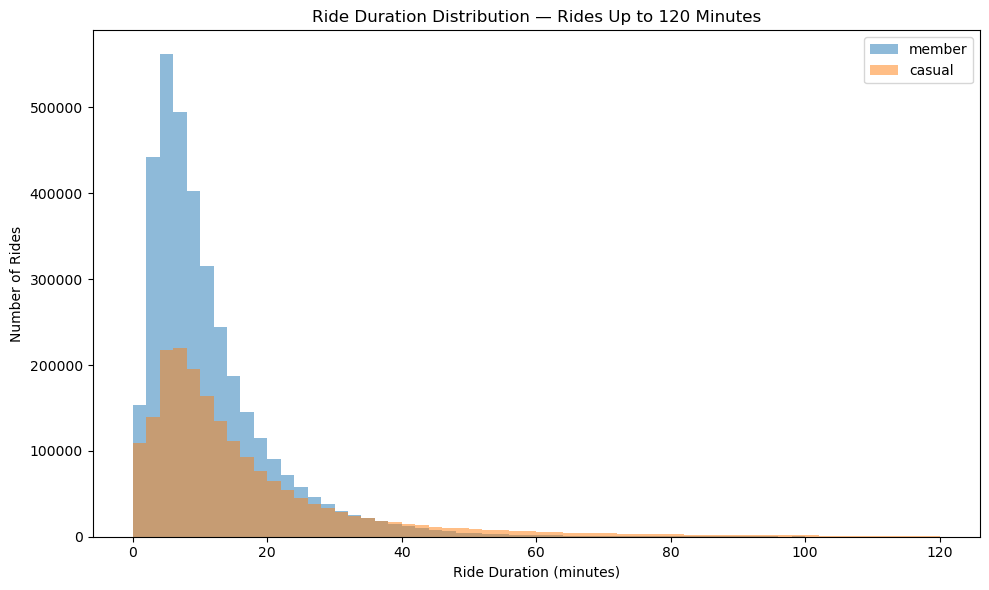

In [26]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

for rider_type in ["member", "casual"]:
    values = duration_df.loc[
        (duration_df["member_casual"] == rider_type) &
        (duration_df["ride_duration_minutes"] <= 120),
        "ride_duration_minutes"
    ]

    plt.hist(
        values,
        bins=60,
        alpha=0.5,
        label=rider_type
    )

plt.title("Ride Duration Distribution — Rides Up to 120 Minutes")
plt.xlabel("Ride Duration (minutes)")
plt.ylabel("Number of Rides")
plt.legend()
plt.tight_layout()

plt.show()

### Note on Short-Duration Ride Counts

The Process stage identified 147,401 rides with
`short_duration_flag = True`.

The Phase 3 duration-analysis population excludes the 29 negative-duration
records because negative elapsed time is not a meaningful ride duration.
Those 29 records were also counted by the Process-stage short-duration flag
because the flag was defined as `ride_duration_seconds < 60`.

Therefore:

147,401 short-duration flags
− 29 negative-duration records
= 147,372 valid rides under 1 minute.

The 29 negative-duration records remain retained in `annual_df` and are not
deleted or modified.

In [27]:
# Final Phase 3 evidence table
# Compare the primary duration population with the standard population.

phase3_final = pd.DataFrame({
    "Metric": [
        "Ride count",
        "Mean ride duration (minutes)",
        "Median ride duration (minutes)",
        "P25 (minutes)",
        "P75 (minutes)",
        "P90 (minutes)",
        "P95 (minutes)",
        "P99 (minutes)"
    ],

    "Member - Primary": [
        duration_summary.loc["member", "ride_count"],
        duration_summary.loc["member", "mean_minutes"],
        duration_summary.loc["member", "median_minutes"],
        duration_summary.loc["member", "p25"],
        duration_summary.loc["member", "p75"],
        duration_summary.loc["member", "p90"],
        duration_summary.loc["member", "p95"],
        duration_summary.loc["member", "p99"]
    ],

    "Casual - Primary": [
        duration_summary.loc["casual", "ride_count"],
        duration_summary.loc["casual", "mean_minutes"],
        duration_summary.loc["casual", "median_minutes"],
        duration_summary.loc["casual", "p25"],
        duration_summary.loc["casual", "p75"],
        duration_summary.loc["casual", "p90"],
        duration_summary.loc["casual", "p95"],
        duration_summary.loc["casual", "p99"]
    ],

    "Member - Standard": [
        standard_duration_summary.loc["member", "ride_count"],
        standard_duration_summary.loc["member", "mean_minutes"],
        standard_duration_summary.loc["member", "median_minutes"],
        standard_duration_summary.loc["member", "p25"],   # Added
        standard_duration_summary.loc["member", "p75"],
        standard_duration_summary.loc["member", "p90"],
        standard_duration_summary.loc["member", "p95"],
        standard_duration_summary.loc["member", "p99"]
    ],

    "Casual - Standard": [
        standard_duration_summary.loc["casual", "ride_count"],
        standard_duration_summary.loc["casual", "mean_minutes"],
        standard_duration_summary.loc["casual", "median_minutes"],
        standard_duration_summary.loc["casual", "p25"],   # Added
        standard_duration_summary.loc["casual", "p75"],
        standard_duration_summary.loc["casual", "p90"],
        standard_duration_summary.loc["casual", "p95"],
        standard_duration_summary.loc["casual", "p99"]
    ]
})

phase3_final.round(2)

,Metric,Member - Primary,Casual - Primary,Member - Standard,Casual - Standard
0,Ride count,3553477.00,1999488.00,3484202.00,1915806.00
1,Mean ride duration (minutes),12.33,22.60,12.18,19.91
2,Median ride duration (minutes),8.58,11.41,8.74,11.89
3,P25 (minutes),5.03,6.31,5.21,6.82
4,P75 (minutes),14.51,21.16,14.67,21.68
5,P90 (minutes),23.28,39.22,23.45,39.69
6,P95 (minutes),30.75,58.96,30.91,58.80
7,P99 (minutes),51.02,132.23,50.92,120.62


In [28]:
# Phase 4.1 — Check weekday fields

print("Missing day_of_week:",
      annual_df["day_of_week"].isna().sum())

print("Missing day_of_week_num:",
      annual_df["day_of_week_num"].isna().sum())

print("\nUnique day names:")
print(annual_df["day_of_week"].unique())

print("\nUnique day numbers:")
print(sorted(annual_df["day_of_week_num"].unique()))

Missing day_of_week: 0
Missing day_of_week_num: 0

Unique day names:
['Tuesday' 'Saturday' 'Thursday' 'Sunday' 'Friday' 'Monday' 'Wednesday']

Unique day numbers:
[np.int32(0), np.int32(1), np.int32(2), np.int32(3), np.int32(4), np.int32(5), np.int32(6)]


In [29]:
# Correct weekday order for analysis and visualization

weekday_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

annual_df["day_of_week"] = pd.Categorical(
    annual_df["day_of_week"],
    categories=weekday_order,
    ordered=True
)

duration_df["day_of_week"] = pd.Categorical(
    duration_df["day_of_week"],
    categories=weekday_order,
    ordered=True
)

standard_duration_df["day_of_week"] = pd.Categorical(
    standard_duration_df["day_of_week"],
    categories=weekday_order,
    ordered=True
)

In [30]:
# Phase 4.2 — Ride count by weekday and rider type

weekday_counts = (
    annual_df
    .groupby(
        ["day_of_week", "member_casual"],
        observed=False
    )
    .size()
    .reset_index(name="ride_count")
)

weekday_counts

,day_of_week,member_casual,ride_count
0,Monday,casual,228253
1,Monday,member,502767
2,Tuesday,casual,225586
3,Tuesday,member,563070
4,Wednesday,casual,221538
5,Wednesday,member,550154
6,Thursday,casual,258045
7,Thursday,member,576005
8,Friday,casual,320077
9,Friday,member,528989


In [31]:
# Phase 4.3 — Share of each rider type's rides by weekday

weekday_counts["rider_type_day_share"] = (
    weekday_counts
    .groupby("member_casual")["ride_count"]
    .transform(lambda x: x / x.sum() * 100)
)

weekday_counts["rider_type_day_share"] = (
    weekday_counts["rider_type_day_share"].round(2)
)

weekday_counts

,day_of_week,member_casual,ride_count,rider_type_day_share
0,Monday,casual,228253,11.42
1,Monday,member,502767,14.15
2,Tuesday,casual,225586,11.28
3,Tuesday,member,563070,15.85
4,Wednesday,casual,221538,11.08
5,Wednesday,member,550154,15.48
6,Thursday,casual,258045,12.91
7,Thursday,member,576005,16.21
8,Friday,casual,320077,16.01
9,Friday,member,528989,14.89


In [32]:
# Phase 4.4 — Rider composition within each weekday

weekday_composition = weekday_counts.copy()

weekday_composition["weekday_rider_share"] = (
    weekday_composition
    .groupby("day_of_week", observed=False)["ride_count"]
    .transform(lambda x: x / x.sum() * 100)
)

weekday_composition["weekday_rider_share"] = (
    weekday_composition["weekday_rider_share"].round(2)
)

weekday_composition

,day_of_week,member_casual,ride_count,rider_type_day_share,weekday_rider_share
0,Monday,casual,228253,11.42,31.22
1,Monday,member,502767,14.15,68.78
2,Tuesday,casual,225586,11.28,28.60
3,Tuesday,member,563070,15.85,71.40
4,Wednesday,casual,221538,11.08,28.71
5,Wednesday,member,550154,15.48,71.29
6,Thursday,casual,258045,12.91,30.94
7,Thursday,member,576005,16.21,69.06
8,Friday,casual,320077,16.01,37.70
9,Friday,member,528989,14.89,62.30


In [33]:
# Phase 4.5 — Easy-to-read ride count table

weekday_count_table = (
    weekday_counts
    .pivot(
        index="day_of_week",
        columns="member_casual",
        values="ride_count"
    )
    .reindex(weekday_order)
)

weekday_count_table

member_casual,casual,member
day_of_week,,
Monday,228253,502767
Tuesday,225586,563070
Wednesday,221538,550154
Thursday,258045,576005
Friday,320077,528989
Saturday,414206,450199
Sunday,331792,382313


In [34]:
# Share of each rider type's annual rides occurring on each weekday

weekday_share_table = (
    weekday_counts
    .pivot(
        index="day_of_week",
        columns="member_casual",
        values="rider_type_day_share"
    )
    .reindex(weekday_order)
)

weekday_share_table

member_casual,casual,member
day_of_week,,
Monday,11.42,14.15
Tuesday,11.28,15.85
Wednesday,11.08,15.48
Thursday,12.91,16.21
Friday,16.01,14.89
Saturday,20.72,12.67
Sunday,16.59,10.76


In [35]:
# Percentage composition of rides on each weekday

weekday_composition_table = (
    weekday_composition
    .pivot(
        index="day_of_week",
        columns="member_casual",
        values="weekday_rider_share"
    )
    .reindex(weekday_order)
)

weekday_composition_table

member_casual,casual,member
day_of_week,,
Monday,31.22,68.78
Tuesday,28.60,71.40
Wednesday,28.71,71.29
Thursday,30.94,69.06
Friday,37.70,62.30
Saturday,47.92,52.08
Sunday,46.46,53.54


In [36]:
# Validation: member + casual should equal approximately 100% each day

weekday_composition_check = (
    weekday_composition_table["member"]
    + weekday_composition_table["casual"]
)

weekday_composition_check

day_of_week
Monday       100.0
Tuesday      100.0
Wednesday    100.0
Thursday     100.0
Friday       100.0
Saturday     100.0
Sunday       100.0
dtype: float64

In [37]:
# Phase 4.6 — Ride duration by weekday and rider type

weekday_duration = (
    duration_df
    .groupby(
        ["day_of_week", "member_casual"],
        observed=False
    )["ride_duration_minutes"]
    .agg(
        mean_minutes="mean",
        median_minutes="median"
    )
    .reset_index()
    .round(2)
)

weekday_duration

,day_of_week,member_casual,mean_minutes,median_minutes
0,Monday,casual,22.33,10.97
1,Monday,member,11.89,8.25
2,Tuesday,casual,19.86,10.15
3,Tuesday,member,11.95,8.48
4,Wednesday,casual,18.72,9.82
5,Wednesday,member,11.78,8.41
6,Thursday,casual,19.84,10.19
7,Thursday,member,11.90,8.47
8,Friday,casual,22.51,11.32
9,Friday,member,12.28,8.49


In [38]:
# Mean duration table

weekday_mean_duration = (
    weekday_duration
    .pivot(
        index="day_of_week",
        columns="member_casual",
        values="mean_minutes"
    )
    .reindex(weekday_order)
)

weekday_mean_duration

member_casual,casual,member
day_of_week,,
Monday,22.33,11.89
Tuesday,19.86,11.95
Wednesday,18.72,11.78
Thursday,19.84,11.90
Friday,22.51,12.28
Saturday,25.26,13.48
Sunday,26.14,13.64


In [39]:
# Median duration table

weekday_median_duration = (
    weekday_duration
    .pivot(
        index="day_of_week",
        columns="member_casual",
        values="median_minutes"
    )
    .reindex(weekday_order)
)

weekday_median_duration

member_casual,casual,member
day_of_week,,
Monday,10.97,8.25
Tuesday,10.15,8.48
Wednesday,9.82,8.41
Thursday,10.19,8.47
Friday,11.32,8.49
Saturday,13.15,9.21
Sunday,13.25,9.07


In [40]:
# Duration difference: casual minus member

weekday_duration_difference = pd.DataFrame({
    "Member_mean": weekday_mean_duration["member"],
    "Casual_mean": weekday_mean_duration["casual"]
})

weekday_duration_difference["Casual_minus_member"] = (
    weekday_duration_difference["Casual_mean"]
    - weekday_duration_difference["Member_mean"]
).round(2)

weekday_duration_difference

,Member_mean,Casual_mean,Casual_minus_member
day_of_week,,,
Monday,11.89,22.33,10.44
Tuesday,11.95,19.86,7.91
Wednesday,11.78,18.72,6.94
Thursday,11.90,19.84,7.94
Friday,12.28,22.51,10.23
Saturday,13.48,25.26,11.78
Sunday,13.64,26.14,12.50


In [41]:
weekday_median_difference = pd.DataFrame({
    "Member_median": weekday_median_duration["member"],
    "Casual_median": weekday_median_duration["casual"]
})

weekday_median_difference["Casual_minus_member"] = (
    weekday_median_difference["Casual_median"]
    - weekday_median_difference["Member_median"]
).round(2)

weekday_median_difference

,Member_median,Casual_median,Casual_minus_member
day_of_week,,,
Monday,8.25,10.97,2.72
Tuesday,8.48,10.15,1.67
Wednesday,8.41,9.82,1.41
Thursday,8.47,10.19,1.72
Friday,8.49,11.32,2.83
Saturday,9.21,13.15,3.94
Sunday,9.07,13.25,4.18


In [42]:
# Total rides by weekday

weekday_total = (
    annual_df
    .groupby("day_of_week", observed=False)
    .size()
    .reindex(weekday_order)
)

weekday_total

day_of_week
Monday       731020
Tuesday      788656
Wednesday    771692
Thursday     834050
Friday       849066
Saturday     864405
Sunday       714105
dtype: int64

In [43]:
weekday_total_share = (
    weekday_total / weekday_total.sum() * 100
).round(2)

weekday_total_share

day_of_week
Monday       13.16
Tuesday      14.20
Wednesday    13.90
Thursday     15.02
Friday       15.29
Saturday     15.57
Sunday       12.86
dtype: float64

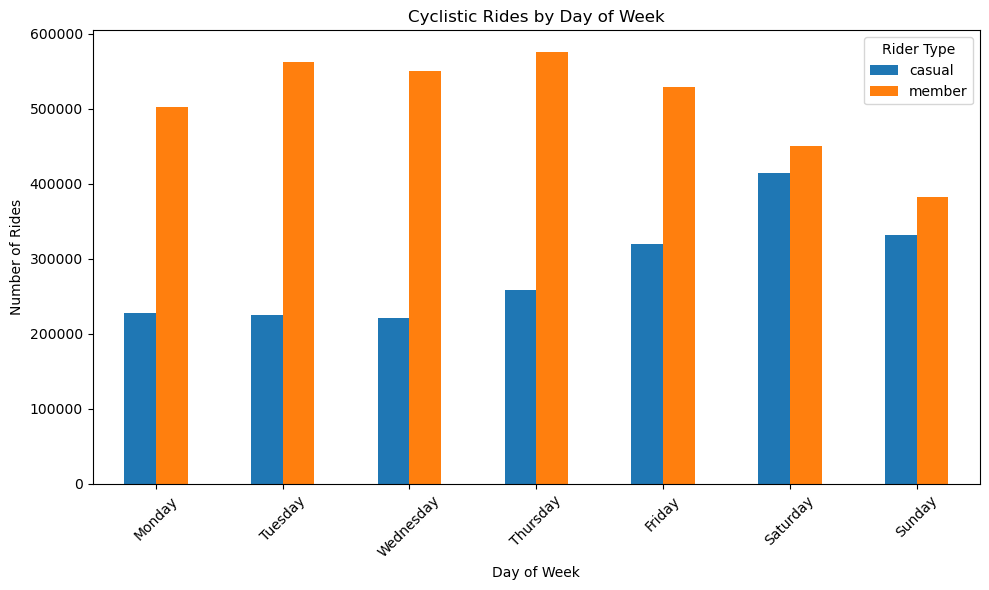

In [44]:
import matplotlib.pyplot as plt

weekday_count_table.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Cyclistic Rides by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Number of Rides")
plt.xticks(rotation=45)
plt.legend(title="Rider Type")
plt.tight_layout()

plt.show()

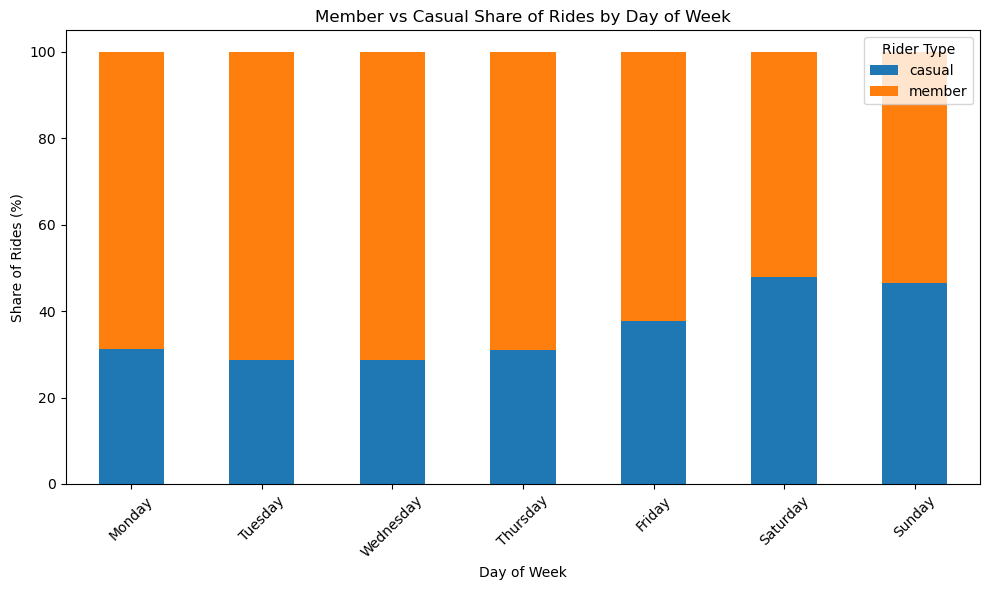

In [45]:
weekday_composition_table.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6)
)

plt.title("Member vs Casual Share of Rides by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Share of Rides (%)")
plt.xticks(rotation=45)
plt.legend(title="Rider Type")
plt.tight_layout()

plt.show()

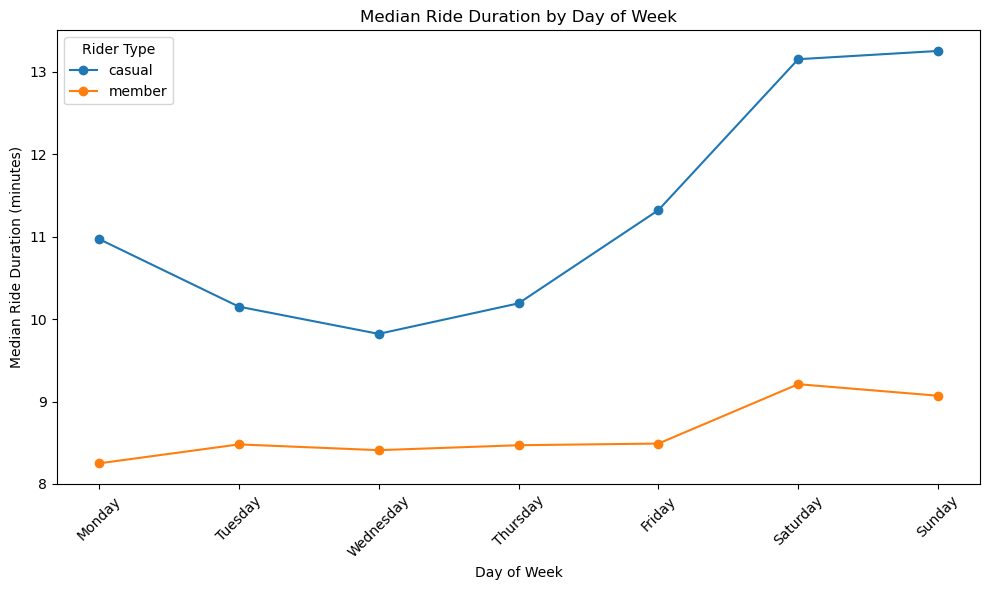

In [46]:
weekday_median_duration.plot(
    kind="line",
    marker="o",
    figsize=(10, 6)
)

plt.title("Median Ride Duration by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Median Ride Duration (minutes)")
plt.xticks(range(7), weekday_order, rotation=45)
plt.legend(title="Rider Type")
plt.tight_layout()

plt.show()

In [47]:
# Phase 4.7 — Weekday duration sensitivity
# Standard population: 1 minute <= ride duration <= 24 hours

weekday_duration_standard = (
    standard_duration_df
    .groupby(
        ["day_of_week", "member_casual"],
        observed=False
    )["ride_duration_minutes"]
    .agg(
        mean_minutes="mean",
        median_minutes="median"
    )
    .reset_index()
    .round(2)
)

weekday_duration_standard

,day_of_week,member_casual,mean_minutes,median_minutes
0,Monday,casual,19.70,11.42
1,Monday,member,11.76,8.40
2,Tuesday,casual,17.62,10.52
3,Tuesday,member,11.85,8.63
4,Wednesday,casual,16.36,10.18
5,Wednesday,member,11.63,8.56
6,Thursday,casual,17.45,10.59
7,Thursday,member,11.73,8.62
8,Friday,casual,19.60,11.82
9,Friday,member,12.14,8.65


In [48]:
weekday_standard_mean = (
    weekday_duration_standard
    .pivot(
        index="day_of_week",
        columns="member_casual",
        values="mean_minutes"
    )
    .reindex(weekday_order)
)

weekday_standard_median = (
    weekday_duration_standard
    .pivot(
        index="day_of_week",
        columns="member_casual",
        values="median_minutes"
    )
    .reindex(weekday_order)
)

print("Standard-population mean duration:")
display(weekday_standard_mean)

print("\nStandard-population median duration:")
display(weekday_standard_median)

Standard-population mean duration:


member_casual,casual,member
day_of_week,,
Monday,19.70,11.76
Tuesday,17.62,11.85
Wednesday,16.36,11.63
Thursday,17.45,11.73
Friday,19.60,12.14
Saturday,22.40,13.30
Sunday,23.10,13.45



Standard-population median duration:


member_casual,casual,member
day_of_week,,
Monday,11.42,8.40
Tuesday,10.52,8.63
Wednesday,10.18,8.56
Thursday,10.59,8.62
Friday,11.82,8.65
Saturday,13.77,9.43
Sunday,13.86,9.25


## Phase 4 — Day-of-Week Findings

The day-of-week analysis shows clear behavioral differences between annual
members and casual riders.

1. Casual riding activity is more concentrated toward the end of the week.
   Saturday accounts for 20.72% of casual riders' annual trips, compared
   with 12.67% of members' trips. Sunday accounts for 16.59% of casual
   trips compared with 10.76% of member trips.

2. The composition of rides changes substantially on weekends. Members
   account for 68.78% to 71.40% of rides from Monday through Thursday,
   while casual riders account for 47.92% of Saturday rides and 46.46%
   of Sunday rides.

3. Casual rides are longer than member rides on every day of the week.
   This difference is visible in both mean and median ride duration.

4. The duration difference is largest on the weekend. Using the standard
   duration population (1 minute to 24 hours), casual rides have a mean
   duration of 22.40 minutes on Saturday and 23.10 minutes on Sunday,
   compared with 13.30 and 13.45 minutes for members.

5. The weekday duration pattern remains after excluding rides shorter than
   one minute and longer than 24 hours. Therefore, the observed difference
   between casual and member ride duration is not dependent only on
   short-duration or extreme-duration observations.

These findings are descriptive and show behavioral differences in trip
activity and duration. They do not establish why these differences occur.

In [49]:
# Phase 5.1 — Create month fields for analysis

annual_df["analysis_month_num"] = annual_df["started_at"].dt.month
annual_df["analysis_month_name"] = annual_df["started_at"].dt.month_name()

duration_df["analysis_month_num"] = duration_df["started_at"].dt.month
duration_df["analysis_month_name"] = duration_df["started_at"].dt.month_name()

standard_duration_df["analysis_month_num"] = (
    standard_duration_df["started_at"].dt.month
)
standard_duration_df["analysis_month_name"] = (
    standard_duration_df["started_at"].dt.month_name()
)

In [50]:
month_order = [
    "January",
    "February",
    "March",
    "April",
    "May",
    "June",
    "July",
    "August",
    "September",
    "October",
    "November",
    "December"
]

annual_df["analysis_month_name"] = pd.Categorical(
    annual_df["analysis_month_name"],
    categories=month_order,
    ordered=True
)

duration_df["analysis_month_name"] = pd.Categorical(
    duration_df["analysis_month_name"],
    categories=month_order,
    ordered=True
)

standard_duration_df["analysis_month_name"] = pd.Categorical(
    standard_duration_df["analysis_month_name"],
    categories=month_order,
    ordered=True
)

In [51]:
# Phase 5.2 — Month field validation

print("Missing month numbers:",
      annual_df["analysis_month_num"].isna().sum())

print("Missing month names:",
      annual_df["analysis_month_name"].isna().sum())

print("\nUnique month numbers:")
print(sorted(annual_df["analysis_month_num"].unique()))

print("\nMonth names:")
print(annual_df["analysis_month_name"].unique())

Missing month numbers: 0
Missing month names: 0

Unique month numbers:
[np.int32(1), np.int32(2), np.int32(3), np.int32(4), np.int32(5), np.int32(6), np.int32(7), np.int32(8), np.int32(9), np.int32(10), np.int32(11), np.int32(12)]

Month names:
['January', 'December', 'February', 'March', 'April', ..., 'July', 'August', 'September', 'October', 'November']
Length: 12
Categories (12, object): ['January' < 'February' < 'March' < 'April' ... 'September' < 'October' < 'November' < 'December']


In [52]:
# Phase 5.3 — Monthly ride count by rider type

monthly_counts = (
    annual_df
    .groupby(
        ["analysis_month_name", "member_casual"],
        observed=False
    )
    .size()
    .reset_index(name="ride_count")
)

monthly_counts

,analysis_month_name,member_casual,ride_count
0,January,casual,24124
1,January,member,114527
2,February,casual,27757
3,February,member,124144
4,March,casual,85862
5,March,member,212268
6,April,casual,109239
7,April,member,262137
8,May,casual,182770
9,May,member,319845


In [53]:
monthly_count_table = (
    monthly_counts
    .pivot(
        index="analysis_month_name",
        columns="member_casual",
        values="ride_count"
    )
    .reindex(month_order)
)

monthly_count_table

member_casual,casual,member
analysis_month_name,,
January,24124,114527
February,27757,124144
March,85862,212268
April,109239,262137
May,182770,319845
June,292006,386795
July,323352,440106
August,337878,452439
September,265268,449294


In [54]:
monthly_total = (
    annual_df
    .groupby(
        "analysis_month_name",
        observed=False
    )
    .size()
    .reindex(month_order)
)

monthly_total

analysis_month_name
January      138651
February     151901
March        298130
April        371376
May          502615
June         678801
July         763458
August       790317
September    714562
October      646096
November     356512
December     140575
dtype: int64

In [55]:
monthly_total_share = (
    monthly_total / monthly_total.sum() * 100
).round(2)

monthly_total_share

analysis_month_name
January       2.50
February      2.74
March         5.37
April         6.69
May           9.05
June         12.22
July         13.75
August       14.23
September    12.87
October      11.64
November      6.42
December      2.53
dtype: float64

In [56]:
# Phase 5.4 — Monthly rider composition

monthly_composition = monthly_counts.copy()

monthly_composition["monthly_rider_share"] = (
    monthly_composition
    .groupby(
        "analysis_month_name",
        observed=False
    )["ride_count"]
    .transform(
        lambda x: x / x.sum() * 100
    )
)

monthly_composition["monthly_rider_share"] = (
    monthly_composition["monthly_rider_share"].round(2)
)

monthly_composition

,analysis_month_name,member_casual,ride_count,monthly_rider_share
0,January,casual,24124,17.40
1,January,member,114527,82.60
2,February,casual,27757,18.27
3,February,member,124144,81.73
4,March,casual,85862,28.80
5,March,member,212268,71.20
6,April,casual,109239,29.41
7,April,member,262137,70.59
8,May,casual,182770,36.36
9,May,member,319845,63.64


In [57]:
monthly_composition_table = (
    monthly_composition
    .pivot(
        index="analysis_month_name",
        columns="member_casual",
        values="monthly_rider_share"
    )
    .reindex(month_order)
)

monthly_composition_table

member_casual,casual,member
analysis_month_name,,
January,17.40,82.60
February,18.27,81.73
March,28.80,71.20
April,29.41,70.59
May,36.36,63.64
June,43.02,56.98
July,42.35,57.65
August,42.75,57.25
September,37.12,62.88


In [58]:
# Monthly composition validation

monthly_composition_check = (
    monthly_composition_table["member"]
    + monthly_composition_table["casual"]
)

monthly_composition_check

analysis_month_name
January      100.0
February     100.0
March        100.0
April        100.0
May          100.0
June         100.0
July         100.0
August       100.0
September    100.0
October      100.0
November     100.0
December     100.0
dtype: float64

In [59]:
# Phase 5.5 — Share of each rider type's annual rides by month

monthly_counts["rider_type_month_share"] = (
    monthly_counts
    .groupby("member_casual")["ride_count"]
    .transform(
        lambda x: x / x.sum() * 100
    )
)

monthly_counts["rider_type_month_share"] = (
    monthly_counts["rider_type_month_share"].round(2)
)

monthly_counts

,analysis_month_name,member_casual,ride_count,rider_type_month_share
0,January,casual,24124,1.21
1,January,member,114527,3.22
2,February,casual,27757,1.39
3,February,member,124144,3.49
4,March,casual,85862,4.29
5,March,member,212268,5.97
6,April,casual,109239,5.46
7,April,member,262137,7.38
8,May,casual,182770,9.14
9,May,member,319845,9.00


In [60]:
monthly_rider_distribution = (
    monthly_counts
    .pivot(
        index="analysis_month_name",
        columns="member_casual",
        values="rider_type_month_share"
    )
    .reindex(month_order)
)

monthly_rider_distribution

member_casual,casual,member
analysis_month_name,,
January,1.21,3.22
February,1.39,3.49
March,4.29,5.97
April,5.46,7.38
May,9.14,9.00
June,14.60,10.88
July,16.17,12.39
August,16.90,12.73
September,13.27,12.64


In [61]:
# Phase 5.6 — Monthly ride duration

monthly_duration = (
    duration_df
    .groupby(
        ["analysis_month_name", "member_casual"],
        observed=False
    )["ride_duration_minutes"]
    .agg(
        mean_minutes="mean",
        median_minutes="median"
    )
    .reset_index()
    .round(2)
)

monthly_duration

,analysis_month_name,member_casual,mean_minutes,median_minutes
0,January,casual,14.61,6.98
1,January,member,10.07,6.76
2,February,casual,14.65,7.22
3,February,member,10.05,6.90
4,March,casual,20.77,10.21
5,March,member,11.23,7.75
6,April,casual,21.67,10.34
7,April,member,11.33,7.96
8,May,casual,24.19,11.80
9,May,member,12.13,8.56


In [62]:
monthly_mean_duration = (
    monthly_duration
    .pivot(
        index="analysis_month_name",
        columns="member_casual",
        values="mean_minutes"
    )
    .reindex(month_order)
)

monthly_mean_duration

member_casual,casual,member
analysis_month_name,,
January,14.61,10.07
February,14.65,10.05
March,20.77,11.23
April,21.67,11.33
May,24.19,12.13
June,25.38,12.94
July,24.39,13.35
August,23.61,13.09
September,21.59,12.70


In [63]:
monthly_median_duration = (
    monthly_duration
    .pivot(
        index="analysis_month_name",
        columns="member_casual",
        values="median_minutes"
    )
    .reindex(month_order)
)

monthly_median_duration

member_casual,casual,member
analysis_month_name,,
January,6.98,6.76
February,7.22,6.90
March,10.21,7.75
April,10.34,7.96
May,11.80,8.56
June,12.82,9.42
July,12.41,9.37
August,12.87,9.47
September,11.50,9.13


In [64]:
# Phase 5.7 — Monthly duration difference

monthly_duration_difference = pd.DataFrame({
    "Member_mean": monthly_mean_duration["member"],
    "Casual_mean": monthly_mean_duration["casual"]
})

monthly_duration_difference["Casual_minus_member"] = (
    monthly_duration_difference["Casual_mean"]
    - monthly_duration_difference["Member_mean"]
).round(2)

monthly_duration_difference

,Member_mean,Casual_mean,Casual_minus_member
analysis_month_name,,,
January,10.07,14.61,4.54
February,10.05,14.65,4.60
March,11.23,20.77,9.54
April,11.33,21.67,10.34
May,12.13,24.19,12.06
June,12.94,25.38,12.44
July,13.35,24.39,11.04
August,13.09,23.61,10.52
September,12.70,21.59,8.89


In [65]:
monthly_median_difference = pd.DataFrame({
    "Member_median": monthly_median_duration["member"],
    "Casual_median": monthly_median_duration["casual"]
})

monthly_median_difference["Casual_minus_member"] = (
    monthly_median_difference["Casual_median"]
    - monthly_median_difference["Member_median"]
).round(2)

monthly_median_difference

,Member_median,Casual_median,Casual_minus_member
analysis_month_name,,,
January,6.76,6.98,0.22
February,6.90,7.22,0.32
March,7.75,10.21,2.46
April,7.96,10.34,2.38
May,8.56,11.80,3.24
June,9.42,12.82,3.40
July,9.37,12.41,3.04
August,9.47,12.87,3.40
September,9.13,11.50,2.37


In [66]:
# Phase 5.8 — Monthly duration sensitivity analysis

monthly_duration_standard = (
    standard_duration_df
    .groupby(
        ["analysis_month_name", "member_casual"],
        observed=False
    )["ride_duration_minutes"]
    .agg(
        mean_minutes="mean",
        median_minutes="median"
    )
    .reset_index()
    .round(2)
)

monthly_duration_standard

,analysis_month_name,member_casual,mean_minutes,median_minutes
0,January,casual,11.97,7.14
1,January,member,9.98,6.88
2,February,casual,12.38,7.38
3,February,member,9.96,7.00
4,March,casual,17.89,10.57
5,March,member,11.13,7.89
6,April,casual,18.66,10.71
7,April,member,11.27,8.08
8,May,casual,20.83,12.26
9,May,member,11.90,8.72


In [67]:
monthly_standard_mean = (
    monthly_duration_standard
    .pivot(
        index="analysis_month_name",
        columns="member_casual",
        values="mean_minutes"
    )
    .reindex(month_order)
)

monthly_standard_median = (
    monthly_duration_standard
    .pivot(
        index="analysis_month_name",
        columns="member_casual",
        values="median_minutes"
    )
    .reindex(month_order)
)

print("Standard-population monthly mean duration:")
display(monthly_standard_mean)

print("\nStandard-population monthly median duration:")
display(monthly_standard_median)

Standard-population monthly mean duration:


member_casual,casual,member
analysis_month_name,,
January,11.97,9.98
February,12.38,9.96
March,17.89,11.13
April,18.66,11.27
May,20.83,11.90
June,21.91,12.85
July,21.44,13.15
August,21.71,13.08
September,19.55,12.62



Standard-population monthly median duration:


member_casual,casual,member
analysis_month_name,,
January,7.14,6.88
February,7.38,7.00
March,10.57,7.89
April,10.71,8.08
May,12.26,8.72
June,13.38,9.58
July,12.98,9.56
August,13.45,9.66
September,11.96,9.29


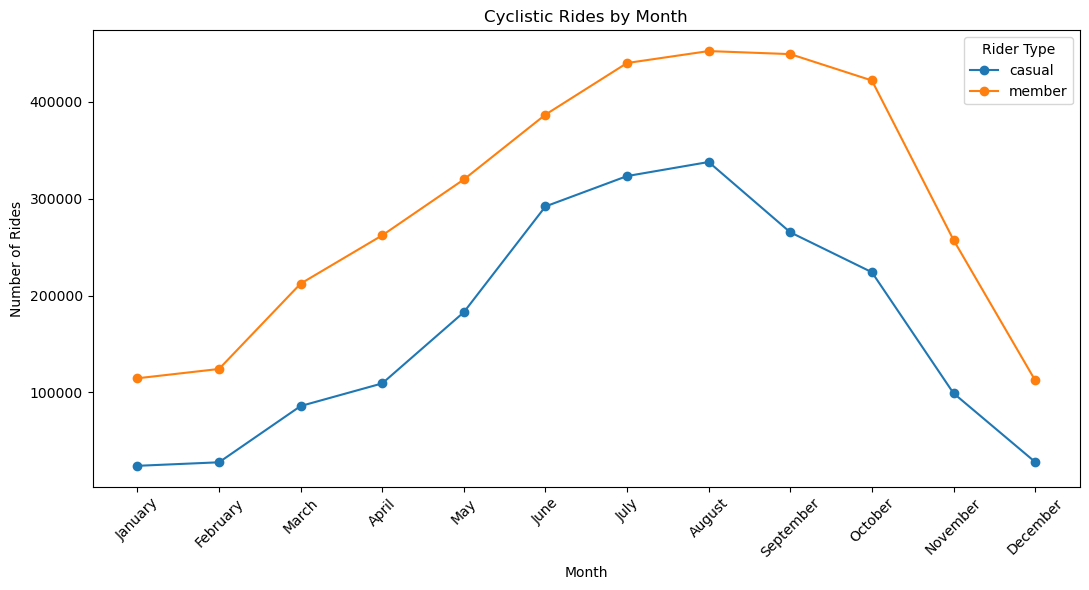

In [68]:
import matplotlib.pyplot as plt

monthly_count_table.plot(
    kind="line",
    marker="o",
    figsize=(11, 6)
)

plt.title("Cyclistic Rides by Month")
plt.xlabel("Month")
plt.ylabel("Number of Rides")
plt.xticks(range(12), month_order, rotation=45)
plt.legend(title="Rider Type")
plt.tight_layout()

plt.show()

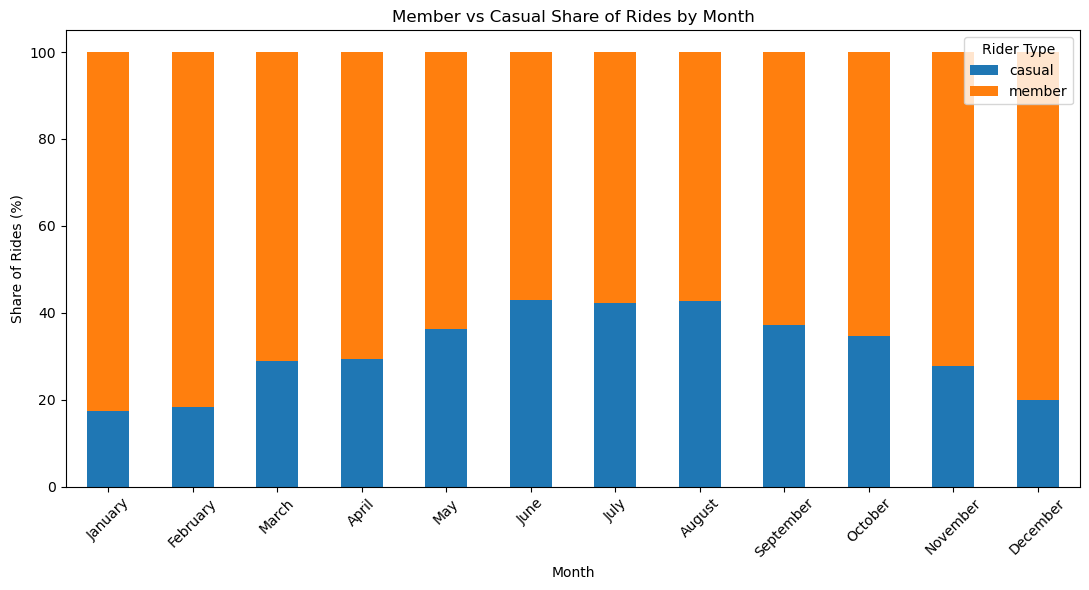

In [69]:
monthly_composition_table.plot(
    kind="bar",
    stacked=True,
    figsize=(11, 6)
)

plt.title("Member vs Casual Share of Rides by Month")
plt.xlabel("Month")
plt.ylabel("Share of Rides (%)")
plt.xticks(rotation=45)
plt.legend(title="Rider Type")
plt.tight_layout()

plt.show()

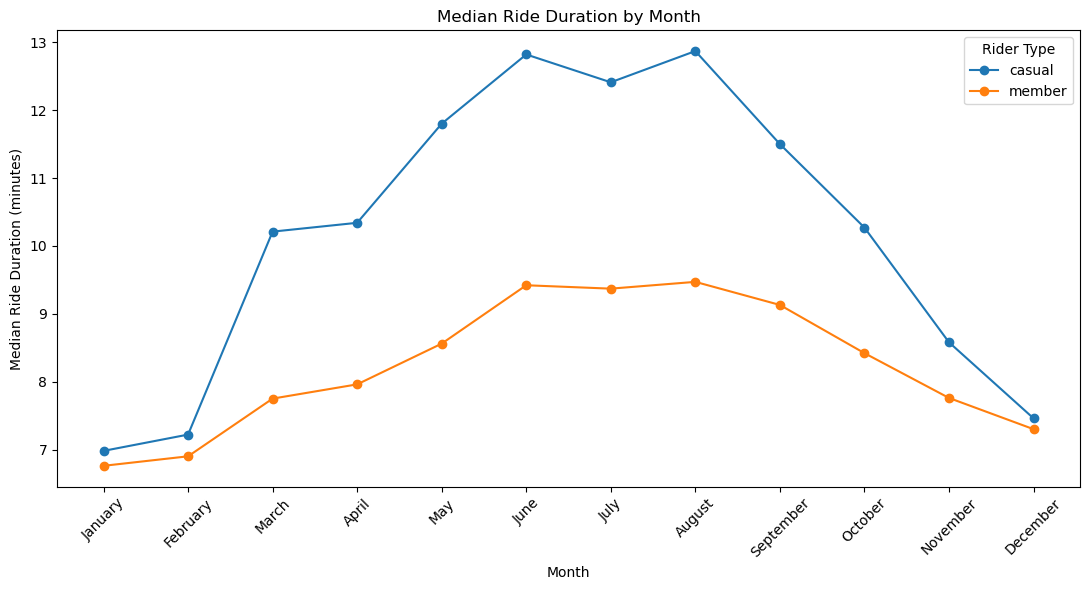

In [70]:
monthly_median_duration.plot(
    kind="line",
    marker="o",
    figsize=(11, 6)
)

plt.title("Median Ride Duration by Month")
plt.xlabel("Month")
plt.ylabel("Median Ride Duration (minutes)")
plt.xticks(range(12), month_order, rotation=45)
plt.legend(title="Rider Type")
plt.tight_layout()

plt.show()

In [71]:
# Phase 5.9 — Validate monthly distribution within each rider type

monthly_rider_distribution_check = (
    monthly_rider_distribution.sum()
)

monthly_rider_distribution_check

member_casual
casual    100.00
member     99.98
dtype: float64

In [72]:
# Phase 5.10 — Standard-population monthly duration difference

monthly_standard_mean_difference = pd.DataFrame({
    "Member_mean": monthly_standard_mean["member"],
    "Casual_mean": monthly_standard_mean["casual"]
})

monthly_standard_mean_difference["Casual_minus_member"] = (
    monthly_standard_mean_difference["Casual_mean"]
    - monthly_standard_mean_difference["Member_mean"]
).round(2)

monthly_standard_mean_difference

,Member_mean,Casual_mean,Casual_minus_member
analysis_month_name,,,
January,9.98,11.97,1.99
February,9.96,12.38,2.42
March,11.13,17.89,6.76
April,11.27,18.66,7.39
May,11.90,20.83,8.93
June,12.85,21.91,9.06
July,13.15,21.44,8.29
August,13.08,21.71,8.63
September,12.62,19.55,6.93


In [73]:
monthly_standard_median_difference = pd.DataFrame({
    "Member_median": monthly_standard_median["member"],
    "Casual_median": monthly_standard_median["casual"]
})

monthly_standard_median_difference["Casual_minus_member"] = (
    monthly_standard_median_difference["Casual_median"]
    - monthly_standard_median_difference["Member_median"]
).round(2)

monthly_standard_median_difference

,Member_median,Casual_median,Casual_minus_member
analysis_month_name,,,
January,6.88,7.14,0.26
February,7.00,7.38,0.38
March,7.89,10.57,2.68
April,8.08,10.71,2.63
May,8.72,12.26,3.54
June,9.58,13.38,3.80
July,9.56,12.98,3.42
August,9.66,13.45,3.79
September,9.29,11.96,2.67


## Phase 5 — Monthly / Seasonal Findings

The monthly analysis shows substantial variation in Cyclistic trip activity
throughout 2025.

1. Overall ride volume follows a clear annual pattern. Trip activity is
   relatively low in January and February, increases substantially from
   spring into the middle of the year, reaches its highest monthly level
   in August, and then declines toward November and December.

2. The share of casual rides changes substantially across the year. Casual
   riders represented 17.40% of January rides but 43.02% of June rides.
   Their share remained above 42% during July and August before declining
   toward the end of the year.

3. Casual riding activity is more concentrated in the middle of the year
   than member activity. August accounted for 16.90% of annual casual
   rides, while August accounted for 12.73% of annual member rides.

4. Casual rides are longer than member rides in every month when measured
   by both mean and median duration.

5. The duration difference is larger during the middle of the year.
   Using the standard duration population (1 minute to 24 hours), the
   largest mean difference occurred in June, when casual rides averaged
   21.91 minutes compared with 12.85 minutes for members.

6. The same pattern remains when using median duration. In the standard
   population, the largest median difference occurred in June, with
   casual rides at 13.38 minutes compared with 9.58 minutes for members.

7. These findings are descriptive. The analysis identifies differences
   in riding volume, rider composition, and duration across months, but
   does not establish the reasons or motivations behind those differences.

In [74]:
# Phase 6.1 — Bike type validation

print("Missing rideable_type:")
print(annual_df["rideable_type"].isna().sum())

print("\nUnique bike types:")
print(annual_df["rideable_type"].unique())

print("\nBike type counts:")
print(annual_df["rideable_type"].value_counts())

Missing rideable_type:
0

Unique bike types:
<StringArray>
['classic_bike', 'electric_bike']
Length: 2, dtype: string

Bike type counts:
rideable_type
electric_bike    3604953
classic_bike     1948041
Name: count, dtype: Int64


In [75]:
# Phase 6.2 — Overall bike-type counts

bike_type_counts = (
    annual_df["rideable_type"]
    .value_counts()
)

print("Bike-type counts:")
print(bike_type_counts)

print("\nTotal bike-type records:")
print(bike_type_counts.sum())

print("\nTotal annual rides:")
print(len(annual_df))

Bike-type counts:
rideable_type
electric_bike    3604953
classic_bike     1948041
Name: count, dtype: Int64

Total bike-type records:
5552994

Total annual rides:
5552994


In [76]:
# Overall share of each bike type

bike_type_share = (
    annual_df["rideable_type"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

bike_type_share

rideable_type
electric_bike    64.92
classic_bike     35.08
Name: proportion, dtype: Float64

In [77]:
# Phase 6.3 — Bike type usage by rider type

bike_type_rider_counts = (
    annual_df
    .groupby(
        ["member_casual", "rideable_type"],
        observed=False
    )
    .size()
    .reset_index(name="ride_count")
)

bike_type_rider_counts

,member_casual,rideable_type,ride_count
0,casual,classic_bike,672675
1,casual,electric_bike,1326822
2,member,classic_bike,1275366
3,member,electric_bike,2278131


In [78]:
bike_type_rider_table = (
    bike_type_rider_counts
    .pivot(
        index="member_casual",
        columns="rideable_type",
        values="ride_count"
    )
)

bike_type_rider_table

rideable_type,classic_bike,electric_bike
member_casual,,
casual,672675,1326822
member,1275366,2278131


In [79]:
# Phase 6.4 — Bike-type share within each rider group

bike_type_rider_counts["rider_type_bike_share"] = (
    bike_type_rider_counts
    .groupby("member_casual")["ride_count"]
    .transform(
        lambda x: x / x.sum() * 100
    )
)

bike_type_rider_counts["rider_type_bike_share"] = (
    bike_type_rider_counts["rider_type_bike_share"]
    .round(2)
)

bike_type_rider_counts

,member_casual,rideable_type,ride_count,rider_type_bike_share
0,casual,classic_bike,672675,33.64
1,casual,electric_bike,1326822,66.36
2,member,classic_bike,1275366,35.89
3,member,electric_bike,2278131,64.11


In [80]:
bike_type_rider_share_table = (
    bike_type_rider_counts
    .pivot(
        index="member_casual",
        columns="rideable_type",
        values="rider_type_bike_share"
    )
)

bike_type_rider_share_table

rideable_type,classic_bike,electric_bike
member_casual,,
casual,33.64,66.36
member,35.89,64.11


In [81]:
# Validate that each rider group's bike-type shares total 100%

bike_type_share_check = (
    bike_type_rider_share_table.sum(axis=1)
)

bike_type_share_check

member_casual
casual    100.0
member    100.0
dtype: float64

In [82]:
# Difference in bike-type share between casual and member riders

bike_type_share_difference = pd.DataFrame({
    "Member": bike_type_rider_share_table.loc["member"],
    "Casual": bike_type_rider_share_table.loc["casual"]
})

bike_type_share_difference["Casual_minus_member"] = (
    bike_type_share_difference["Casual"]
    - bike_type_share_difference["Member"]
).round(2)

bike_type_share_difference

,Member,Casual,Casual_minus_member
rideable_type,,,
classic_bike,35.89,33.64,-2.25
electric_bike,64.11,66.36,2.25


In [83]:
# Phase 6.5 — Bike type by month

bike_type_month_counts = (
    annual_df
    .groupby(
        ["analysis_month_name", "rideable_type"],
        observed=False
    )
    .size()
    .reset_index(name="ride_count")
)

bike_type_month_counts

,analysis_month_name,rideable_type,ride_count
0,January,classic_bike,49602
1,January,electric_bike,89049
2,February,classic_bike,52771
3,February,electric_bike,99130
4,March,classic_bike,110998
5,March,electric_bike,187132
6,April,classic_bike,138657
7,April,electric_bike,232719
8,May,classic_bike,186186
9,May,electric_bike,316429


In [84]:
bike_type_month_table = (
    bike_type_month_counts
    .pivot(
        index="analysis_month_name",
        columns="rideable_type",
        values="ride_count"
    )
    .reindex(month_order)
)

bike_type_month_table

rideable_type,classic_bike,electric_bike
analysis_month_name,,
January,49602,89049
February,52771,99130
March,110998,187132
April,138657,232719
May,186186,316429
June,254053,424748
July,265258,498200
August,281050,509267
September,239235,475327


In [85]:
bike_type_month_counts["monthly_bike_share"] = (
    bike_type_month_counts
    .groupby(
        "analysis_month_name",
        observed=False
    )["ride_count"]
    .transform(
        lambda x: x / x.sum() * 100
    )
)

bike_type_month_counts["monthly_bike_share"] = (
    bike_type_month_counts["monthly_bike_share"]
    .round(2)
)

bike_type_month_share_table = (
    bike_type_month_counts
    .pivot(
        index="analysis_month_name",
        columns="rideable_type",
        values="monthly_bike_share"
    )
    .reindex(month_order)
)

bike_type_month_share_table

rideable_type,classic_bike,electric_bike
analysis_month_name,,
January,35.77,64.23
February,34.74,65.26
March,37.23,62.77
April,37.34,62.66
May,37.04,62.96
June,37.43,62.57
July,34.74,65.26
August,35.56,64.44
September,33.48,66.52


In [86]:
# Monthly bike-type share validation

bike_type_month_share_check = (
    bike_type_month_share_table.sum(axis=1)
)

bike_type_month_share_check

analysis_month_name
January      100.0
February     100.0
March        100.0
April        100.0
May          100.0
June         100.0
July         100.0
August       100.0
September    100.0
October      100.0
November     100.0
December     100.0
dtype: float64

In [87]:
# Phase 6.6 — Bike type by weekday

bike_type_weekday_counts = (
    annual_df
    .groupby(
        ["day_of_week", "rideable_type"],
        observed=False
    )
    .size()
    .reset_index(name="ride_count")
)

bike_type_weekday_counts

,day_of_week,rideable_type,ride_count
0,Monday,classic_bike,266517
1,Monday,electric_bike,464503
2,Tuesday,classic_bike,277590
3,Tuesday,electric_bike,511066
4,Wednesday,classic_bike,262327
5,Wednesday,electric_bike,509365
6,Thursday,classic_bike,278934
7,Thursday,electric_bike,555116
8,Friday,classic_bike,285045
9,Friday,electric_bike,564021


In [88]:
bike_type_weekday_share = (
    bike_type_weekday_counts.copy()
)

bike_type_weekday_share["weekday_bike_share"] = (
    bike_type_weekday_share
    .groupby(
        "day_of_week",
        observed=False
    )["ride_count"]
    .transform(
        lambda x: x / x.sum() * 100
    )
)

bike_type_weekday_share["weekday_bike_share"] = (
    bike_type_weekday_share["weekday_bike_share"]
    .round(2)
)

bike_type_weekday_share_table = (
    bike_type_weekday_share
    .pivot(
        index="day_of_week",
        columns="rideable_type",
        values="weekday_bike_share"
    )
    .reindex(weekday_order)
)

bike_type_weekday_share_table

rideable_type,classic_bike,electric_bike
day_of_week,,
Monday,36.46,63.54
Tuesday,35.20,64.80
Wednesday,33.99,66.01
Thursday,33.44,66.56
Friday,33.57,66.43
Saturday,36.06,63.94
Sunday,37.24,62.76


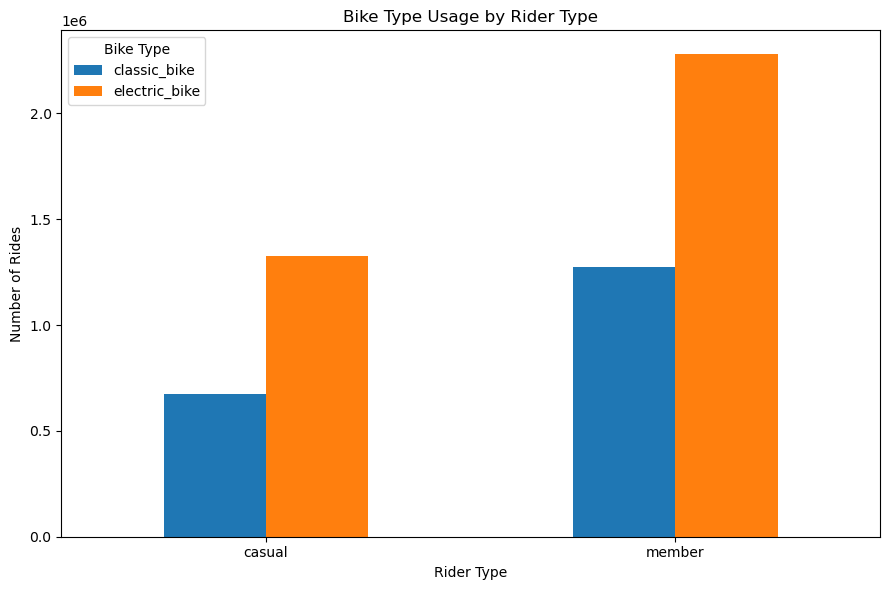

In [89]:
bike_type_rider_table.plot(
    kind="bar",
    figsize=(9, 6)
)

plt.title("Bike Type Usage by Rider Type")
plt.xlabel("Rider Type")
plt.ylabel("Number of Rides")
plt.xticks(rotation=0)
plt.legend(title="Bike Type")
plt.tight_layout()

plt.show()

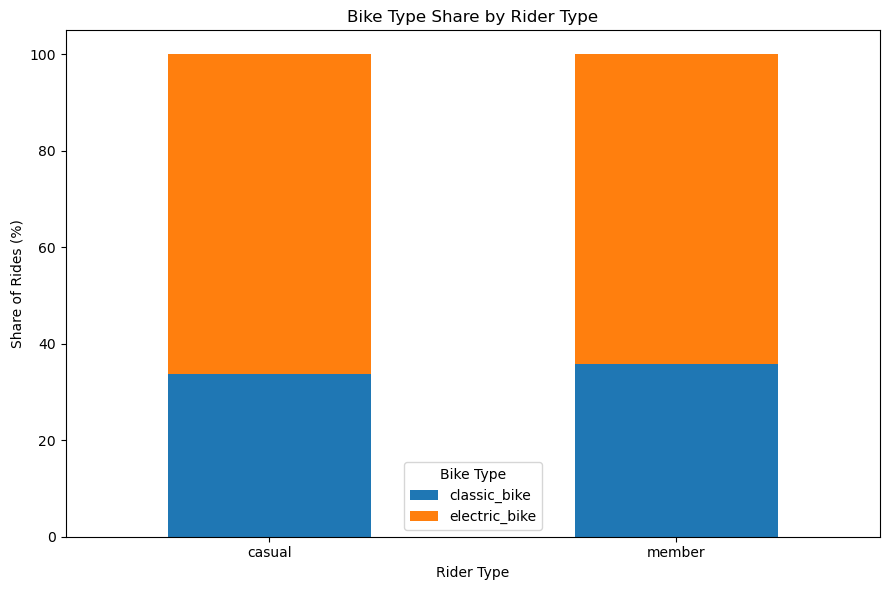

In [90]:
bike_type_rider_share_table.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 6)
)

plt.title("Bike Type Share by Rider Type")
plt.xlabel("Rider Type")
plt.ylabel("Share of Rides (%)")
plt.xticks(rotation=0)
plt.legend(title="Bike Type")
plt.tight_layout()

plt.show()

## Phase 6 — Bike Type Findings

The bike-type analysis shows that electric bikes were used more frequently
than classic bikes during 2025.

1. Electric bikes accounted for 64.92% of all recorded trips, while classic
   bikes accounted for 35.08%.

2. Electric-bike usage was the majority for both rider groups. Electric
   bikes represented 66.36% of casual riders' trips and 64.11% of member
   trips.

3. The difference between casual and member electric-bike share was 2.25
   percentage points, indicating that bike-type usage was relatively similar
   between the two rider groups.

4. Electric bikes remained the majority bike type in every month of 2025.
   Their monthly share ranged from 62.57% to 68.08%.

5. Electric bikes also remained the majority on every day of the week, with
   their share ranging from 62.76% to 66.56%.

Overall, bike type shows some difference between casual and member trips,
but the difference is relatively small compared with the stronger
behavioral differences observed by day of week and month.

These findings describe trip-level bike usage and should not be interpreted
as individual customer preference because the dataset does not contain a
customer identifier.

## Phase 7 — Station / Location Analysis

This phase examines where Cyclistic trips start and end, comparing
station-level trip activity between members and casual riders.

The analysis is performed at the trip level. It does not represent
individual customer behavior because the dataset does not contain a
customer identifier.

Station information is required for this phase, so records with the
required station fields missing will be excluded only from the relevant
station-level calculation. The master annual dataset remains unchanged.

In [76]:
# Phase 7.1 — Station data completeness

station_columns = [
    "start_station_id",
    "start_station_name",
    "end_station_id",
    "end_station_name"
]

station_completeness = pd.DataFrame({
    "missing_count": annual_df[station_columns].isna().sum(),
    "missing_percentage": (
        annual_df[station_columns].isna().mean() * 100
    ).round(2)
})

station_completeness

,missing_count,missing_percentage
start_station_id,1184673,21.33
start_station_name,1184673,21.33
end_station_id,1243305,22.39
end_station_name,1243305,22.39


In [77]:
# Check whether station ID and station name are missing together

start_station_missing_check = pd.Series({
    "both_missing": (
        annual_df["start_station_id"].isna() &
        annual_df["start_station_name"].isna()
    ).sum(),

    "name_only_missing": (
        annual_df["start_station_name"].isna() &
        annual_df["start_station_id"].notna()
    ).sum(),

    "id_only_missing": (
        annual_df["start_station_id"].isna() &
        annual_df["start_station_name"].notna()
    ).sum()
})

end_station_missing_check = pd.Series({
    "both_missing": (
        annual_df["end_station_id"].isna() &
        annual_df["end_station_name"].isna()
    ).sum(),

    "name_only_missing": (
        annual_df["end_station_name"].isna() &
        annual_df["end_station_id"].notna()
    ).sum(),

    "id_only_missing": (
        annual_df["end_station_id"].isna() &
        annual_df["end_station_name"].notna()
    ).sum()
})

print("Start-station completeness:")
print(start_station_missing_check)

print("\nEnd-station completeness:")
print(end_station_missing_check)

Start-station completeness:
both_missing         1184673
name_only_missing          0
id_only_missing            0
dtype: int64

End-station completeness:
both_missing         1243305
name_only_missing          0
id_only_missing            0
dtype: int64


In [78]:
# Phase 7.2 — Station ID / name consistency

start_name_variants = (
    annual_df.loc[
        annual_df["start_station_id"].notna() &
        annual_df["start_station_name"].notna(),
        ["start_station_id", "start_station_name"]
    ]
    .drop_duplicates()
    .groupby("start_station_id")
    .size()
)

end_name_variants = (
    annual_df.loc[
        annual_df["end_station_id"].notna() &
        annual_df["end_station_name"].notna(),
        ["end_station_id", "end_station_name"]
    ]
    .drop_duplicates()
    .groupby("end_station_id")
    .size()
)

print(
    "Start station IDs with multiple recorded names:",
    (start_name_variants > 1).sum()
)

print(
    "End station IDs with multiple recorded names:",
    (end_name_variants > 1).sum()
)

Start station IDs with multiple recorded names: 81
End station IDs with multiple recorded names: 86


In [79]:
# Coordinate consistency by station ID

start_coordinate_variants = (
    annual_df.loc[
        annual_df["start_station_id"].notna(),
        ["start_station_id", "start_lat", "start_lng"]
    ]
    .drop_duplicates()
    .groupby("start_station_id")
    .size()
)

end_coordinate_variants = (
    annual_df.loc[
        annual_df["end_station_id"].notna(),
        ["end_station_id", "end_lat", "end_lng"]
    ]
    .drop_duplicates()
    .groupby("end_station_id")
    .size()
)

print(
    "Start station IDs with multiple coordinate pairs:",
    (start_coordinate_variants > 1).sum()
)

print(
    "End station IDs with multiple coordinate pairs:",
    (end_coordinate_variants > 1).sum()
)

Start station IDs with multiple coordinate pairs: 2132
End station IDs with multiple coordinate pairs: 148


In [80]:
# Phase 7.3 — Start station activity

start_station_summary = (
    annual_df.loc[
        annual_df["start_station_id"].notna()
    ]
    .groupby("start_station_id", observed=True)
    .agg(
        station_name=("start_station_name", "first"),
        latitude=("start_lat", "first"),
        longitude=("start_lng", "first"),
        total_rides=("ride_id", "size"),
        member_rides=(
            "member_casual",
            lambda s: (s == "member").sum()
        ),
        casual_rides=(
            "member_casual",
            lambda s: (s == "casual").sum()
        )
    )
    .reset_index()
)

start_station_summary["casual_share"] = (
    start_station_summary["casual_rides"]
    / start_station_summary["total_rides"]
    * 100
).round(2)

start_station_summary["member_share"] = (
    start_station_summary["member_rides"]
    / start_station_summary["total_rides"]
    * 100
).round(2)

start_station_summary.head()

,start_station_id,station_name,latitude,longitude,total_rides,member_rides,casual_rides,casual_share,member_share
0,24321,Oconto Ave & Belmont Ave,41.937830,-87.807880,20,8,12,60.00,40.00
1,(ARCHIVE)CHI02077,Clark St & Lake St,41.886020,-87.630870,880,523,357,40.57,59.43
2,(ARCHIVE)CHI02078,Franklin St & Monroe St,41.880310,-87.635180,892,667,225,25.22,74.78
3,(ARCHIVE)CHI02079,Daley Center Plaza,41.884240,-87.629630,1433,926,507,35.38,64.62
4,000-CHI01831,Kedzie Ave & Jackson Blvd,41.877161,-87.706134,9,7,2,22.22,77.78


In [81]:
top_start_stations = (
    start_station_summary
    .sort_values("total_rides", ascending=False)
    .head(10)
    .copy()
)

top_start_stations

,start_station_id,station_name,latitude,longitude,total_rides,member_rides,casual_rides,casual_share,member_share
2605,CHI01747,Streeter Dr & Grand Ave,41.892278,-87.612043,54075,11302,42773,79.10,20.90
1424,CHI00374,DuSable Lake Shore Dr & Monroe St,41.880958,-87.616743,31105,6502,24603,79.10,20.90
1303,CHI00252,Michigan Ave & Oak St,41.900960,-87.623777,28477,9763,18714,65.72,34.28
1575,CHI00525,DuSable Lake Shore Dr & North Blvd,41.911722,-87.626804,28074,11650,16424,58.50,41.50
1350,CHI00299,Kingsbury St & Kinzie St,41.889177,-87.638506,27833,20911,6922,24.87,75.13
1470,CHI00420,Theater on the Lake,41.926277,-87.630834,22575,9292,13283,58.84,41.16
2600,CHI01742,Millennium Park,41.881032,-87.624084,21106,6127,14979,70.97,29.03
1332,CHI00281,Clark St & Elm St,41.902970,-87.631300,21015,13946,7069,33.64,66.36
1559,CHI00509,Clinton St & Washington Blvd,41.883380,-87.641170,20495,16927,3568,17.41,82.59
1446,CHI00396,Wells St & Concord Ln,41.912133,-87.634656,20226,13124,7102,35.11,64.89


In [82]:
top_casual_start_stations = (
    start_station_summary
    .sort_values("casual_rides", ascending=False)
    .head(10)
    .copy()
)

top_casual_start_stations

,start_station_id,station_name,latitude,longitude,total_rides,member_rides,casual_rides,casual_share,member_share
2605,CHI01747,Streeter Dr & Grand Ave,41.892278,-87.612043,54075,11302,42773,79.10,20.90
1424,CHI00374,DuSable Lake Shore Dr & Monroe St,41.880958,-87.616743,31105,6502,24603,79.10,20.90
1303,CHI00252,Michigan Ave & Oak St,41.900960,-87.623777,28477,9763,18714,65.72,34.28
1575,CHI00525,DuSable Lake Shore Dr & North Blvd,41.911722,-87.626804,28074,11650,16424,58.50,41.50
2600,CHI01742,Millennium Park,41.881032,-87.624084,21106,6127,14979,70.97,29.03
1470,CHI00420,Theater on the Lake,41.926277,-87.630834,22575,9292,13283,58.84,41.16
1583,CHI00533,Shedd Aquarium,41.867226,-87.615355,15407,2640,12767,82.86,17.14
1581,CHI00531,Dusable Harbor,41.886976,-87.612813,16319,4335,11984,73.44,26.56
2149,CHI01163,Michigan Ave & 8th St,41.872773,-87.623981,13475,4457,9018,66.92,33.08
1477,CHI00427,Montrose Harbor,41.963982,-87.638181,14690,5898,8792,59.85,40.15


In [83]:
top_member_start_stations = (
    start_station_summary
    .sort_values("member_rides", ascending=False)
    .head(10)
    .copy()
)

top_member_start_stations

,start_station_id,station_name,latitude,longitude,total_rides,member_rides,casual_rides,casual_share,member_share
1350,CHI00299,Kingsbury St & Kinzie St,41.889177,-87.638506,27833,20911,6922,24.87,75.13
1559,CHI00509,Clinton St & Washington Blvd,41.883380,-87.641170,20495,16927,3568,17.41,82.59
1284,CHI00233,Clinton St & Madison St,41.882752,-87.641190,19671,14554,5117,26.01,73.99
1548,CHI00498,Canal St & Madison St,41.882409,-87.639767,19694,14448,5246,26.64,73.36
1332,CHI00281,Clark St & Elm St,41.902970,-87.631300,21015,13946,7069,33.64,66.36
2630,CHI01772,State St & Chicago Ave,41.896617,-87.628579,18722,13296,5426,28.98,71.02
1446,CHI00396,Wells St & Concord Ln,41.912133,-87.634656,20226,13124,7102,35.11,64.89
1590,CHI00540,Wells St & Elm St,41.903222,-87.634324,19067,13099,5968,31.30,68.70
1345,CHI00294,Wells St & Huron St,41.894795,-87.634374,18826,12919,5907,31.38,68.62
2095,CHI01091,Clinton St & Jackson Blvd,41.878317,-87.640981,15780,11903,3877,24.57,75.43


In [84]:
# Phase 7.4 — End station activity

end_station_summary = (
    annual_df.loc[
        annual_df["end_station_id"].notna()
    ]
    .groupby("end_station_id", observed=True)
    .agg(
        station_name=("end_station_name", "first"),
        latitude=("end_lat", "first"),
        longitude=("end_lng", "first"),
        total_rides=("ride_id", "size"),
        member_rides=(
            "member_casual",
            lambda s: (s == "member").sum()
        ),
        casual_rides=(
            "member_casual",
            lambda s: (s == "casual").sum()
        )
    )
    .reset_index()
)

end_station_summary["casual_share"] = (
    end_station_summary["casual_rides"]
    / end_station_summary["total_rides"]
    * 100
).round(2)

end_station_summary["member_share"] = (
    end_station_summary["member_rides"]
    / end_station_summary["total_rides"]
    * 100
).round(2)

end_station_summary.head()

,end_station_id,station_name,latitude,longitude,total_rides,member_rides,casual_rides,casual_share,member_share
0,24321,Oconto Ave & Belmont Ave,41.937830,-87.807880,32,10,22,68.75,31.25
1,(ARCHIVE)CHI02077,Clark St & Lake St,41.886020,-87.630870,815,495,320,39.26,60.74
2,(ARCHIVE)CHI02078,Franklin St & Monroe St,41.880310,-87.635180,1107,877,230,20.78,79.22
3,(ARCHIVE)CHI02079,Daley Center Plaza,41.884240,-87.629630,1397,997,400,28.63,71.37
4,000-CHI01831,Kedzie Ave & Jackson Blvd,41.877161,-87.706134,11,6,5,45.45,54.55


In [85]:
top_end_stations = (
    end_station_summary
    .sort_values("total_rides", ascending=False)
    .head(10)
    .copy()
)

top_end_stations

,end_station_id,station_name,latitude,longitude,total_rides,member_rides,casual_rides,casual_share,member_share
2628,CHI01747,Streeter Dr & Grand Ave,41.892278,-87.612043,53592,9869,43723,81.58,18.42
1431,CHI00374,DuSable Lake Shore Dr & Monroe St,41.880958,-87.616743,29844,6902,22942,76.87,23.13
1582,CHI00525,DuSable Lake Shore Dr & North Blvd,41.911722,-87.626804,28758,10496,18262,63.50,36.50
1310,CHI00252,Michigan Ave & Oak St,41.900960,-87.623777,28044,9311,18733,66.80,33.20
1357,CHI00299,Kingsbury St & Kinzie St,41.889177,-87.638506,27424,21004,6420,23.41,76.59
1477,CHI00420,Theater on the Lake,41.926277,-87.630834,23083,8766,14317,62.02,37.98
2623,CHI01742,Millennium Park,41.881032,-87.624084,20998,5507,15491,73.77,26.23
1339,CHI00281,Clark St & Elm St,41.902970,-87.631300,20704,14456,6248,30.18,69.82
1566,CHI00509,Clinton St & Washington Blvd,41.883380,-87.641170,20315,16298,4017,19.77,80.23
1453,CHI00396,Wells St & Concord Ln,41.912133,-87.634656,20185,13197,6988,34.62,65.38


In [86]:
top_casual_end_stations = (
    end_station_summary
    .sort_values("casual_rides", ascending=False)
    .head(10)
    .copy()
)

top_casual_end_stations

,end_station_id,station_name,latitude,longitude,total_rides,member_rides,casual_rides,casual_share,member_share
2628,CHI01747,Streeter Dr & Grand Ave,41.892278,-87.612043,53592,9869,43723,81.58,18.42
1431,CHI00374,DuSable Lake Shore Dr & Monroe St,41.880958,-87.616743,29844,6902,22942,76.87,23.13
1310,CHI00252,Michigan Ave & Oak St,41.900960,-87.623777,28044,9311,18733,66.80,33.20
1582,CHI00525,DuSable Lake Shore Dr & North Blvd,41.911722,-87.626804,28758,10496,18262,63.50,36.50
2623,CHI01742,Millennium Park,41.881032,-87.624084,20998,5507,15491,73.77,26.23
1477,CHI00420,Theater on the Lake,41.926277,-87.630834,23083,8766,14317,62.02,37.98
1590,CHI00533,Shedd Aquarium,41.867226,-87.615355,14675,3339,11336,77.25,22.75
1588,CHI00531,Dusable Harbor,41.886976,-87.612813,15794,5385,10409,65.90,34.10
247,13022,Streeter Dr & Grand Ave,41.892278,-87.612043,11275,2345,8930,79.20,20.80
1484,CHI00427,Montrose Harbor,41.963982,-87.638181,14752,6146,8606,58.34,41.66


In [87]:
top_member_end_stations = (
    end_station_summary
    .sort_values("member_rides", ascending=False)
    .head(10)
    .copy()
)

top_member_end_stations

,end_station_id,station_name,latitude,longitude,total_rides,member_rides,casual_rides,casual_share,member_share
1357,CHI00299,Kingsbury St & Kinzie St,41.889177,-87.638506,27424,21004,6420,23.41,76.59
1566,CHI00509,Clinton St & Washington Blvd,41.883380,-87.641170,20315,16298,4017,19.77,80.23
1291,CHI00233,Clinton St & Madison St,41.882752,-87.641190,19521,14776,4745,24.31,75.69
1339,CHI00281,Clark St & Elm St,41.902970,-87.631300,20704,14456,6248,30.18,69.82
1555,CHI00498,Canal St & Madison St,41.882409,-87.639767,19445,14189,5256,27.03,72.97
2653,CHI01772,State St & Chicago Ave,41.896617,-87.628579,18646,13530,5116,27.44,72.56
1453,CHI00396,Wells St & Concord Ln,41.912133,-87.634656,20185,13197,6988,34.62,65.38
1597,CHI00540,Wells St & Elm St,41.903222,-87.634324,18745,12906,5839,31.15,68.85
1352,CHI00294,Wells St & Huron St,41.894795,-87.634374,17406,12281,5125,29.44,70.56
2106,CHI01091,Clinton St & Jackson Blvd,41.878317,-87.640981,15714,11623,4091,26.03,73.97


## Phase 7.4A — Station Identity Diagnostic

Before using station-level results for concentration analysis or mapping,
we need to determine whether different station IDs can represent the same
physical location and whether station IDs have materially different
coordinates across the year.

This check does not modify the master dataset or the existing station
summaries.

In [88]:
# Phase 7.4A — Same station name recorded under multiple station IDs

start_name_id_mapping = (
    annual_df.loc[
        annual_df["start_station_id"].notna() &
        annual_df["start_station_name"].notna(),
        ["start_station_name", "start_station_id"]
    ]
    .drop_duplicates()
)

start_names_multiple_ids = (
    start_name_id_mapping
    .groupby("start_station_name")["start_station_id"]
    .nunique()
    .sort_values(ascending=False)
)

print("Start station names associated with multiple station IDs:")
print(start_names_multiple_ids[start_names_multiple_ids > 1].head(20))

Start station names associated with multiple station IDs:
start_station_name
Daley Center Plaza                  4
Western Ave & Lake St               4
Clark St & Lake St                  4
Kedzie Ave & Jackson Blvd           4
Indiana Ave & 133rd St              4
Burling St & Diversey Pkwy          4
Franklin St & Monroe St             4
Damen Ave & Pierce Ave              3
Halsted St & Roscoe St              3
Damen Ave & Wabansia Ave            3
Halsted St & Fulton St              3
Kostner Ave & Devon Ave             3
Western Ave & Gunnison St           3
Western Ave & Grace St              3
Pine Grove Ave & Irving Park Rd     3
Western Ave & 81st St               3
Western Ave & Berteau Ave           3
Francisco Ave & Chicago Ave         3
Francisco Ave & Bloomingdale Ave    3
Racine Ave & Belmont Ave            3
Name: start_station_id, dtype: int64


In [89]:
# End station names associated with multiple station IDs

end_name_id_mapping = (
    annual_df.loc[
        annual_df["end_station_id"].notna() &
        annual_df["end_station_name"].notna(),
        ["end_station_name", "end_station_id"]
    ]
    .drop_duplicates()
)

end_names_multiple_ids = (
    end_name_id_mapping
    .groupby("end_station_name")["end_station_id"]
    .nunique()
    .sort_values(ascending=False)
)

print("End station names associated with multiple station IDs:")
print(end_names_multiple_ids[end_names_multiple_ids > 1].head(20))

End station names associated with multiple station IDs:
end_station_name
Western Ave & Lake St               4
Franklin St & Monroe St             4
Kedzie Ave & Jackson Blvd           4
Daley Center Plaza                  4
Burling St & Diversey Pkwy          4
Clark St & Lake St                  4
Damen Ave & Pierce Ave              3
LaSalle St & Washington St          3
Halsted St & Roscoe St              3
Western Ave & Gunnison St           3
Western Ave & Grace St              3
Damen Ave & Wabansia Ave            3
Western Ave & Berteau Ave           3
Western Ave & 81st St               3
Lincoln Ave & Balmoral Ave          3
Rockwell St & Fletcher St           3
Campbell Ave & Augusta Blvd         3
Rockwell St & Cermak Rd             3
Francisco Ave & Chicago Ave         3
Francisco Ave & Bloomingdale Ave    3
Name: end_station_id, dtype: int64


In [90]:
# Phase 7.4B — Same coordinates associated with multiple station IDs

start_location_id_mapping = (
    annual_df.loc[
        annual_df["start_station_id"].notna(),
        ["start_station_id", "start_station_name", "start_lat", "start_lng"]
    ]
    .dropna(subset=["start_lat", "start_lng"])
    .copy()
)

start_location_id_mapping["lat_rounded"] = (
    start_location_id_mapping["start_lat"].round(6)
)

start_location_id_mapping["lng_rounded"] = (
    start_location_id_mapping["start_lng"].round(6)
)

start_duplicate_locations = (
    start_location_id_mapping
    .groupby(
        ["lat_rounded", "lng_rounded"],
        observed=True
    )
    .agg(
        station_id_count=("start_station_id", "nunique"),
        station_ids=("start_station_id", lambda x: ", ".join(sorted(x.astype(str).unique())[:10])),
        station_names=("start_station_name", lambda x: ", ".join(sorted(x.dropna().astype(str).unique())[:10]))
    )
    .reset_index()
)

start_duplicate_locations = (
    start_duplicate_locations
    .loc[start_duplicate_locations["station_id_count"] > 1]
    .sort_values("station_id_count", ascending=False)
)

start_duplicate_locations.head(20)

,lat_rounded,lng_rounded,station_id_count,station_ids,station_names
117100,41.932418,-87.652705,4,"CHI00226, CHI02052, TA1306000014, chargingstx2","Wilton Ave & Diversey Pkwy, Wilton Ave & Diver..."
106379,41.918296,-87.652183,4,"CHI00257, CHI01747, CHI02022, chargingstx1","Bissell St & Armitage Ave*, Navy Pier, Sedgwic..."
118567,41.933140,-87.647760,4,"13208, CHI00327, CHI00505, TA1309000036","Burling St & Diversey Pkwy, Burling St & Diver..."
146282,41.978710,-87.755520,4,"1277.0, 1284.0, CHI01735, CHI01740","Public Rack - Forest Glen Station , Public Rac..."
17838,41.877161,-87.706134,4,"000-CHI01831, 24213, CHI01831, CHI02159",Kedzie Ave & Jackson Blvd
4509,41.801354,-87.662076,4,"1042, 915, CHI01381, CHI01496","Public Rack - Laflin St & 51st St, Public Rack..."
81665,41.899578,-87.689497,3,"410, CHI00888, CHI02104",Campbell Ave & Augusta Blvd
118644,41.933886,-87.707262,3,"436, CHI00926, CHI02085",Kedzie Ave & George St
70284,41.895745,-87.698653,3,"411, CHI00901, CHI02080",Francisco Ave & Chicago Ave
122712,41.939743,-87.658865,3,"13230, CHI00411, TA1308000019",Racine Ave & Belmont Ave


In [91]:
end_location_id_mapping = (
    annual_df.loc[
        annual_df["end_station_id"].notna(),
        ["end_station_id", "end_station_name", "end_lat", "end_lng"]
    ]
    .dropna(subset=["end_lat", "end_lng"])
    .copy()
)

end_location_id_mapping["lat_rounded"] = (
    end_location_id_mapping["end_lat"].round(6)
)

end_location_id_mapping["lng_rounded"] = (
    end_location_id_mapping["end_lng"].round(6)
)

end_duplicate_locations = (
    end_location_id_mapping
    .groupby(
        ["lat_rounded", "lng_rounded"],
        observed=True
    )
    .agg(
        station_id_count=("end_station_id", "nunique"),
        station_ids=("end_station_id", lambda x: ", ".join(sorted(x.astype(str).unique())[:10])),
        station_names=("end_station_name", lambda x: ", ".join(sorted(x.dropna().astype(str).unique())[:10]))
    )
    .reset_index()
)

end_duplicate_locations = (
    end_duplicate_locations
    .loc[end_duplicate_locations["station_id_count"] > 1]
    .sort_values("station_id_count", ascending=False)
)

end_duplicate_locations.head(20)

,lat_rounded,lng_rounded,station_id_count,station_ids,station_names
1478,41.933140,-87.647760,4,"13208, CHI00327, CHI00505, TA1309000036","Burling St & Diversey Pkwy, Burling St & Diver..."
1810,41.978710,-87.755520,4,"1277.0, 1284.0, CHI01735, CHI01740","Public Rack - Forest Glen Station , Public Rac..."
949,41.877161,-87.706134,4,"000-CHI01831, 24213, CHI01831, CHI02159",Kedzie Ave & Jackson Blvd
1471,41.932418,-87.652705,4,"CHI00226, CHI02052, TA1306000014, chargingstx2","Wilton Ave & Diversey Pkwy, Wilton Ave & Diver..."
1169,41.895745,-87.698653,3,"411, CHI00901, CHI02080",Francisco Ave & Chicago Ave
811,41.851644,-87.690621,3,"425, CHI00896, CHI02146",Rockwell St & Cermak Rd
1563,41.944540,-87.654678,3,"18001, 632, CHI00674",Clark St & Newport St
1812,41.979461,-87.693013,3,"442, CHI00930, CHI02149",Lincoln Ave & Balmoral Ave
1559,41.943739,-87.664020,3,"13071, CHI00234, CHI00834","N Southport Ave & W Newport Ave, Southport Ave..."
1480,41.934003,-87.690823,3,"472, CHI00940, CHI02084",Elston Ave & George St


In [92]:
start_coordinate_variation = (
    annual_df.loc[
        annual_df["start_station_id"].notna(),
        [
            "start_station_id",
            "start_station_name",
            "start_lat",
            "start_lng"
        ]
    ]
    .dropna(subset=["start_lat", "start_lng"])
    .groupby("start_station_id", observed=True)
    .agg(
        min_lat=("start_lat", "min"),
        max_lat=("start_lat", "max"),
        min_lng=("start_lng", "min"),
        max_lng=("start_lng", "max"),
        station_name_count=("start_station_name", "nunique"),
        total_rows=("start_station_id", "size")
    )
    .reset_index()
)

coordinate_pair_counts = (
    annual_df.loc[
        annual_df["start_station_id"].notna(),
        ["start_station_id", "start_lat", "start_lng"]
    ]
    .dropna(subset=["start_lat", "start_lng"])
    .drop_duplicates()
    .groupby("start_station_id")
    .size()
    .rename("coordinate_pair_count")
    .reset_index()
)

start_coordinate_variation = (
    start_coordinate_variation
    .merge(
        coordinate_pair_counts,
        on="start_station_id",
        how="left"
    )
)

start_coordinate_variation["lat_range"] = (
    start_coordinate_variation["max_lat"]
    - start_coordinate_variation["min_lat"]
)

start_coordinate_variation["lng_range"] = (
    start_coordinate_variation["max_lng"]
    - start_coordinate_variation["min_lng"]
)

start_coordinate_variation = (
    start_coordinate_variation
    .loc[start_coordinate_variation["coordinate_pair_count"] > 1]
    .sort_values("total_rows", ascending=False)
)

start_coordinate_variation.head(20)

,start_station_id,min_lat,max_lat,min_lng,max_lng,station_name_count,total_rows,coordinate_pair_count,lat_range,lng_range
2605,CHI01747,41.892145,41.918296,-87.652183,-87.611815,3,54075,341,0.026150,0.040368
1424,CHI00374,41.880867,41.881225,-87.616888,-87.616656,1,31105,624,0.000358,0.000232
1303,CHI00252,41.900732,41.901915,-87.623932,-87.623492,1,28477,742,0.001184,0.000440
1575,CHI00525,41.911613,41.911839,-87.626976,-87.626706,1,28074,340,0.000226,0.000270
1350,CHI00299,41.886214,41.889318,-87.642471,-87.638192,2,27833,1719,0.003104,0.004279
1470,CHI00420,41.925946,41.926279,-87.631313,-87.630834,1,22575,160,0.000333,0.000479
2600,CHI01742,41.880978,41.881413,-87.624246,-87.623964,1,21106,297,0.000435,0.000282
1332,CHI00281,41.892132,41.904360,-87.635815,-87.630192,1,21015,690,0.012228,0.005623
1559,CHI00509,41.882596,41.884361,-87.642209,-87.639715,1,20495,997,0.001765,0.002494
1446,CHI00396,41.911729,41.912318,-87.635365,-87.634395,1,20226,751,0.000590,0.000970


## Phase 7.4D — Station Name / Physical Location Consistency

The previous checks showed that station IDs can be associated with
multiple station names and multiple coordinate locations.

Before finalizing the station-level analysis, this check evaluates whether
a station name itself corresponds consistently to one physical location.

This diagnostic does not modify the master dataset.

In [93]:
# Phase 7.4D — Start station name / location consistency

start_name_location = (
    annual_df.loc[
        annual_df["start_station_name"].notna(),
        [
            "start_station_name",
            "start_station_id",
            "start_lat",
            "start_lng"
        ]
    ]
    .dropna(subset=["start_lat", "start_lng"])
    .copy()
)

# Summarize station name consistency
start_name_location_summary = (
    start_name_location
    .groupby("start_station_name", observed=True)
    .agg(
        station_id_count=("start_station_id", "nunique"),
        min_lat=("start_lat", "min"),
        max_lat=("start_lat", "max"),
        min_lng=("start_lng", "min"),
        max_lng=("start_lng", "max"),
        total_rows=("start_station_name", "size")
    )
    .reset_index()
)

# Count unique coordinate pairs for each station name
start_unique_coordinates = (
    start_name_location[
        [
            "start_station_name",
            "start_lat",
            "start_lng"
        ]
    ]
    .drop_duplicates()
    .groupby("start_station_name", observed=True)
    .size()
    .rename("unique_coordinate_pairs")
    .reset_index()
)

# Add unique coordinate count
start_name_location_summary = (
    start_name_location_summary
    .merge(
        start_unique_coordinates,
        on="start_station_name",
        how="left"
    )
)

# Calculate geographic variation
start_name_location_summary["lat_range"] = (
    start_name_location_summary["max_lat"]
    - start_name_location_summary["min_lat"]
)

start_name_location_summary["lng_range"] = (
    start_name_location_summary["max_lng"]
    - start_name_location_summary["min_lng"]
)

# Show stations with the largest variation first
start_name_location_summary = (
    start_name_location_summary
    .sort_values(
        ["lat_range", "lng_range"],
        ascending=False
    )
)

start_name_location_summary.head(20)

,start_station_name,station_id_count,min_lat,max_lat,min_lng,max_lng,total_rows,unique_coordinate_pairs,lat_range,lng_range
664,Lincoln Ave & Roscoe St*,2,41.800262,41.943422,-87.670959,-87.589253,8190,82,0.143160,0.081706
240,Columbus Dr & Randolph St,2,41.765361,41.884951,-87.620120,-87.572651,21546,823,0.119590,0.047469
448,Halsted St & Lake St,1,41.885404,41.961618,-87.691204,-87.641241,1251,85,0.076214,0.049963
783,Morgan St & Hubbard St,1,41.890076,41.961618,-87.691204,-87.652445,1692,80,0.071542,0.038759
1684,Southport Ave & Wrightwood Ave,2,41.860521,41.928990,-87.664028,-87.636331,8605,230,0.068468,0.027697
848,Peoria St & Jackson Blvd,2,41.877358,41.928858,-87.663984,-87.648119,13608,492,0.051500,0.015866
622,Larrabee St & North Ave,2,41.864397,41.910266,-87.680336,-87.643431,5733,304,0.045869,0.036905
1661,Sheridan Rd & Montrose Ave,2,41.918090,41.961694,-87.654691,-87.648494,12278,465,0.043605,0.006196
390,Franklin St & Jackson Blvd,2,41.877172,41.919158,-87.794581,-87.632563,15742,443,0.041986,0.162018
1784,Wabash Ave & 9th St,2,41.846296,41.883087,-87.640530,-87.624926,13303,368,0.036791,0.015604


In [94]:
# Phase 7.4D — End station name / location consistency

end_name_location = (
    annual_df.loc[
        annual_df["end_station_name"].notna(),
        [
            "end_station_name",
            "end_station_id",
            "end_lat",
            "end_lng"
        ]
    ]
    .dropna(subset=["end_lat", "end_lng"])
    .copy()
)

# Summarize station name consistency
end_name_location_summary = (
    end_name_location
    .groupby("end_station_name", observed=True)
    .agg(
        station_id_count=("end_station_id", "nunique"),
        min_lat=("end_lat", "min"),
        max_lat=("end_lat", "max"),
        min_lng=("end_lng", "min"),
        max_lng=("end_lng", "max"),
        total_rows=("end_station_name", "size")
    )
    .reset_index()
)

# Count unique coordinate pairs for each station name
end_unique_coordinates = (
    end_name_location[
        [
            "end_station_name",
            "end_lat",
            "end_lng"
        ]
    ]
    .drop_duplicates()
    .groupby("end_station_name", observed=True)
    .size()
    .rename("unique_coordinate_pairs")
    .reset_index()
)

# Add unique coordinate count
end_name_location_summary = (
    end_name_location_summary
    .merge(
        end_unique_coordinates,
        on="end_station_name",
        how="left"
    )
)

# Calculate geographic variation
end_name_location_summary["lat_range"] = (
    end_name_location_summary["max_lat"]
    - end_name_location_summary["min_lat"]
)

end_name_location_summary["lng_range"] = (
    end_name_location_summary["max_lng"]
    - end_name_location_summary["min_lng"]
)

# Show stations with the largest variation first
end_name_location_summary = (
    end_name_location_summary
    .sort_values(
        ["lat_range", "lng_range"],
        ascending=False
    )
)

end_name_location_summary.head(20)

,end_station_name,station_id_count,min_lat,max_lat,min_lng,max_lng,total_rows,unique_coordinate_pairs,lat_range,lng_range
145,Canal St & Jackson Blvd,2,41.878125,41.921239,-87.663273,-87.639968,11827,2,0.043114,0.023305
619,Larrabee St & Kingsbury St 1,1,41.897764,41.918021,-87.643799,-87.642884,1450,2,0.020257,0.000915
811,Noble St & Potomac Ave,1,41.891310,41.905533,-87.663980,-87.662715,134,2,0.014223,0.001265
1821,Wells St & Evergreen Ave,2,41.906724,41.914855,-87.634830,-87.634825,14113,2,0.008131,0.000005
1892,Wood St & Walnut St,1,41.878620,41.886125,-87.671984,-87.669130,258,2,0.007505,0.002854
97,Buckingham Fountain,2,41.869590,41.876368,-87.623961,-87.620559,9894,2,0.006778,0.003402
1854,Western Ave & Fillmore St,2,41.868563,41.874723,-87.686422,-87.686234,2165,2,0.006160,0.000188
195,Clark St & Armitage Ave,2,41.912436,41.918306,-87.636282,-87.632285,24037,2,0.005870,0.003997
407,Green St & Chicago Ave,1,41.893392,41.896210,-87.650737,-87.649020,1603,2,0.002818,0.001717
549,Kilbourn Ave & Milwaukee Ave,2,41.947071,41.948923,-87.740035,-87.740008,402,2,0.001853,0.000027


## Phase 7.4E — Physical Station Location Diagnostic

The previous checks showed that station IDs and station names do not always
correspond one-to-one with a single geographic location.

This diagnostic groups coordinates after rounding them to identify
geographically co-located station records.

The original station IDs, station names, and coordinates are not modified.
This is only used to evaluate the most appropriate unit for physical
station-location analysis.

In [95]:
# Phase 7.4E — Start physical-location diagnostic

start_location_diag = (
    annual_df.loc[
        annual_df["start_station_id"].notna() &
        annual_df["start_lat"].notna() &
        annual_df["start_lng"].notna(),
        [
            "start_station_id",
            "start_station_name",
            "start_lat",
            "start_lng"
        ]
    ]
    .copy()
)

# Round coordinates to 4 decimal places.
# This creates a practical geographic location key while absorbing
# very small coordinate differences.

start_location_diag["location_lat"] = (
    start_location_diag["start_lat"].round(4)
)

start_location_diag["location_lng"] = (
    start_location_diag["start_lng"].round(4)
)

start_location_groups = (
    start_location_diag
    .groupby(
        ["location_lat", "location_lng"],
        observed=True
    )
    .agg(
        total_rides=("start_station_id", "size"),
        station_id_count=("start_station_id", "nunique"),
        station_name_count=("start_station_name", "nunique"),
        station_ids=(
            "start_station_id",
            lambda x: ", ".join(sorted(x.astype(str).unique())[:10])
        ),
        station_names=(
            "start_station_name",
            lambda x: ", ".join(
                sorted(x.dropna().astype(str).unique())[:10]
            )
        )
    )
    .reset_index()
    .sort_values("total_rides", ascending=False)
)

start_location_groups.head(20)

,location_lat,location_lng,total_rides,station_id_count,station_name_count,station_ids,station_names
6403,41.8923,-87.6120,64915,2,3,"13022, CHI01747","NAVY PIER, Navy Pier, Streeter Dr & Grand Ave"
3299,41.8810,-87.6167,38902,2,1,"13300, CHI00374",DuSable Lake Shore Dr & Monroe St
5745,41.8892,-87.6385,37325,3,2,"CHI00299, CHI02181, KA1503000043","Kingsbury St & Kinzie St, Kingsbury St & Kinzi..."
7635,41.9010,-87.6238,34492,2,1,"13042, CHI00252",Michigan Ave & Oak St
8318,41.9117,-87.6268,33597,4,3,"CHI00303, CHI00525, CHI01772, LF-005","DuSable Lake Shore Dr & North Blvd, Sedgwick S..."
4095,41.8834,-87.6412,29144,2,1,"CHI00509, WL-012",Clinton St & Washington Blvd
3656,41.8824,-87.6398,28581,2,1,"13341, CHI00498",Canal St & Madison St
3780,41.8828,-87.6412,28436,3,2,"CHI00233, CHI00509, TA1305000032","Clinton St & Madison St, Clinton St & Washingt..."
3296,41.8810,-87.6241,27121,2,1,"13008, CHI01742",Millennium Park
9056,41.9263,-87.6308,27082,2,1,"CHI00420, TA1308000001",Theater on the Lake


In [96]:
# Phase 7.4E — End physical-location diagnostic

end_location_diag = (
    annual_df.loc[
        annual_df["end_station_id"].notna() &
        annual_df["end_lat"].notna() &
        annual_df["end_lng"].notna(),
        [
            "end_station_id",
            "end_station_name",
            "end_lat",
            "end_lng"
        ]
    ]
    .copy()
)

end_location_diag["location_lat"] = (
    end_location_diag["end_lat"].round(4)
)

end_location_diag["location_lng"] = (
    end_location_diag["end_lng"].round(4)
)

end_location_groups = (
    end_location_diag
    .groupby(
        ["location_lat", "location_lng"],
        observed=True
    )
    .agg(
        total_rides=("end_station_id", "size"),
        station_id_count=("end_station_id", "nunique"),
        station_name_count=("end_station_name", "nunique"),
        station_ids=(
            "end_station_id",
            lambda x: ", ".join(sorted(x.astype(str).unique())[:10])
        ),
        station_names=(
            "end_station_name",
            lambda x: ", ".join(
                sorted(x.dropna().astype(str).unique())[:10]
            )
        )
    )
    .reset_index()
    .sort_values("total_rides", ascending=False)
)

end_location_groups.head(20)

,location_lat,location_lng,total_rides,station_id_count,station_name_count,station_ids,station_names
1119,41.8923,-87.6120,64866,2,3,"13022, CHI01747","NAVY PIER, Navy Pier, Streeter Dr & Grand Ave"
1090,41.8892,-87.6385,38435,2,1,"CHI00299, KA1503000043",Kingsbury St & Kinzie St
988,41.8810,-87.6167,37921,2,1,"13300, CHI00374",DuSable Lake Shore Dr & Monroe St
1284,41.9117,-87.6268,34671,2,1,"CHI00525, LF-005",DuSable Lake Shore Dr & North Blvd
1196,41.9010,-87.6238,34627,2,1,"13042, CHI00252",Michigan Ave & Oak St
1022,41.8834,-87.6412,30533,2,1,"CHI00509, WL-012",Clinton St & Washington Blvd
1000,41.8824,-87.6398,29301,2,1,"13341, CHI00498",Canal St & Madison St
1004,41.8828,-87.6412,29166,3,2,"CHI00233, CHI00509, TA1305000032","Clinton St & Madison St, Clinton St & Washingt..."
1405,41.9263,-87.6308,27853,2,1,"CHI00420, TA1308000001",Theater on the Lake
1288,41.9121,-87.6347,27535,2,1,"CHI00396, TA1308000050",Wells St & Concord Ln


## Phase 7.4F — Station ID and Name Combination Diagnostic

Previous diagnostics showed that station IDs and station names do not
always have a one-to-one relationship, and that trip coordinates can vary
substantially.

Therefore, the next step is to examine station ID + station name
combinations as the recorded station unit.

This diagnostic evaluates:
- trip volume
- member/casual composition
- number of coordinate pairs
- geographic variation

The master dataset is not modified.

In [97]:
# Phase 7.4F — Start station ID + name analysis

start_station_pair = (
    annual_df.loc[
        annual_df["start_station_id"].notna() &
        annual_df["start_station_name"].notna(),
        [
            "start_station_id",
            "start_station_name",
            "start_lat",
            "start_lng",
            "member_casual"
        ]
    ]
    .copy()
)

# Basic station ID + name summary

start_pair_summary = (
    start_station_pair
    .groupby(
        ["start_station_id", "start_station_name"],
        observed=True
    )
    .agg(
        total_rides=("member_casual", "size"),
        member_rides=(
            "member_casual",
            lambda s: (s == "member").sum()
        ),
        casual_rides=(
            "member_casual",
            lambda s: (s == "casual").sum()
        ),
        min_lat=("start_lat", "min"),
        max_lat=("start_lat", "max"),
        min_lng=("start_lng", "min"),
        max_lng=("start_lng", "max")
    )
    .reset_index()
)

# Count unique coordinate pairs

start_pair_coordinates = (
    start_station_pair[
        [
            "start_station_id",
            "start_station_name",
            "start_lat",
            "start_lng"
        ]
    ]
    .dropna(subset=["start_lat", "start_lng"])
    .drop_duplicates()
    .groupby(
        ["start_station_id", "start_station_name"],
        observed=True
    )
    .size()
    .rename("unique_coordinate_pairs")
    .reset_index()
)

start_pair_summary = (
    start_pair_summary
    .merge(
        start_pair_coordinates,
        on=["start_station_id", "start_station_name"],
        how="left"
    )
)

start_pair_summary["lat_range"] = (
    start_pair_summary["max_lat"]
    - start_pair_summary["min_lat"]
)

start_pair_summary["lng_range"] = (
    start_pair_summary["max_lng"]
    - start_pair_summary["min_lng"]
)

start_pair_summary["casual_share"] = (
    start_pair_summary["casual_rides"]
    / start_pair_summary["total_rides"]
    * 100
).round(2)

start_pair_summary["member_share"] = (
    start_pair_summary["member_rides"]
    / start_pair_summary["total_rides"]
    * 100
).round(2)

start_pair_summary = (
    start_pair_summary
    .sort_values("total_rides", ascending=False)
)

start_pair_summary.head(20)

,start_station_id,start_station_name,total_rides,member_rides,casual_rides,min_lat,max_lat,min_lng,max_lng,unique_coordinate_pairs,lat_range,lng_range,casual_share,member_share
2672,CHI01747,Navy Pier,35135,7721,27414,41.892278,41.918296,-87.652183,-87.612043,2,0.026018,0.040140,78.02,21.98
1480,CHI00374,DuSable Lake Shore Dr & Monroe St,31105,6502,24603,41.880867,41.881225,-87.616888,-87.616656,624,0.000358,0.000232,79.10,20.90
1356,CHI00252,Michigan Ave & Oak St,28477,9763,18714,41.900732,41.901915,-87.623932,-87.623492,742,0.001184,0.000440,65.72,34.28
1634,CHI00525,DuSable Lake Shore Dr & North Blvd,28074,11650,16424,41.911613,41.911839,-87.626976,-87.626706,340,0.000226,0.000270,58.50,41.50
1404,CHI00299,Kingsbury St & Kinzie St,27190,20367,6823,41.886214,41.889318,-87.642471,-87.638192,1668,0.003104,0.004279,25.09,74.91
1528,CHI00420,Theater on the Lake,22575,9292,13283,41.925946,41.926279,-87.631313,-87.630834,160,0.000333,0.000479,58.84,41.16
2665,CHI01742,Millennium Park,21106,6127,14979,41.880978,41.881413,-87.624246,-87.623964,297,0.000435,0.000282,70.97,29.03
1386,CHI00281,Clark St & Elm St,21015,13946,7069,41.892132,41.904360,-87.635815,-87.630192,690,0.012228,0.005623,33.64,66.36
1618,CHI00509,Clinton St & Washington Blvd,20495,16927,3568,41.882596,41.884361,-87.642209,-87.639715,997,0.001765,0.002494,17.41,82.59
1502,CHI00396,Wells St & Concord Ln,20226,13124,7102,41.911729,41.912318,-87.635365,-87.634395,751,0.000590,0.000970,35.11,64.89


In [98]:
start_pair_summary.head(20)[
    [
        "start_station_id",
        "start_station_name",
        "total_rides",
        "member_rides",
        "casual_rides",
        "casual_share",
        "unique_coordinate_pairs",
        "lat_range",
        "lng_range"
    ]
]

,start_station_id,start_station_name,total_rides,member_rides,casual_rides,casual_share,unique_coordinate_pairs,lat_range,lng_range
2672,CHI01747,Navy Pier,35135,7721,27414,78.02,2,0.026018,0.040140
1480,CHI00374,DuSable Lake Shore Dr & Monroe St,31105,6502,24603,79.10,624,0.000358,0.000232
1356,CHI00252,Michigan Ave & Oak St,28477,9763,18714,65.72,742,0.001184,0.000440
1634,CHI00525,DuSable Lake Shore Dr & North Blvd,28074,11650,16424,58.50,340,0.000226,0.000270
1404,CHI00299,Kingsbury St & Kinzie St,27190,20367,6823,25.09,1668,0.003104,0.004279
1528,CHI00420,Theater on the Lake,22575,9292,13283,58.84,160,0.000333,0.000479
2665,CHI01742,Millennium Park,21106,6127,14979,70.97,297,0.000435,0.000282
1386,CHI00281,Clark St & Elm St,21015,13946,7069,33.64,690,0.012228,0.005623
1618,CHI00509,Clinton St & Washington Blvd,20495,16927,3568,17.41,997,0.001765,0.002494
1502,CHI00396,Wells St & Concord Ln,20226,13124,7102,35.11,751,0.000590,0.000970


In [99]:
# Phase 7.4F — End station ID + name analysis

end_station_pair = (
    annual_df.loc[
        annual_df["end_station_id"].notna() &
        annual_df["end_station_name"].notna(),
        [
            "end_station_id",
            "end_station_name",
            "end_lat",
            "end_lng",
            "member_casual"
        ]
    ]
    .copy()
)

end_pair_summary = (
    end_station_pair
    .groupby(
        ["end_station_id", "end_station_name"],
        observed=True
    )
    .agg(
        total_rides=("member_casual", "size"),
        member_rides=(
            "member_casual",
            lambda s: (s == "member").sum()
        ),
        casual_rides=(
            "member_casual",
            lambda s: (s == "casual").sum()
        ),
        min_lat=("end_lat", "min"),
        max_lat=("end_lat", "max"),
        min_lng=("end_lng", "min"),
        max_lng=("end_lng", "max")
    )
    .reset_index()
)

end_pair_coordinates = (
    end_station_pair[
        [
            "end_station_id",
            "end_station_name",
            "end_lat",
            "end_lng"
        ]
    ]
    .dropna(subset=["end_lat", "end_lng"])
    .drop_duplicates()
    .groupby(
        ["end_station_id", "end_station_name"],
        observed=True
    )
    .size()
    .rename("unique_coordinate_pairs")
    .reset_index()
)

end_pair_summary = (
    end_pair_summary
    .merge(
        end_pair_coordinates,
        on=["end_station_id", "end_station_name"],
        how="left"
    )
)

end_pair_summary["lat_range"] = (
    end_pair_summary["max_lat"]
    - end_pair_summary["min_lat"]
)

end_pair_summary["lng_range"] = (
    end_pair_summary["max_lng"]
    - end_pair_summary["min_lng"]
)

end_pair_summary["casual_share"] = (
    end_pair_summary["casual_rides"]
    / end_pair_summary["total_rides"]
    * 100
).round(2)

end_pair_summary["member_share"] = (
    end_pair_summary["member_rides"]
    / end_pair_summary["total_rides"]
    * 100
).round(2)

end_pair_summary = (
    end_pair_summary
    .sort_values("total_rides", ascending=False)
)

end_pair_summary.head(20)

,end_station_id,end_station_name,total_rides,member_rides,casual_rides,min_lat,max_lat,min_lng,max_lng,unique_coordinate_pairs,lat_range,lng_range,casual_share,member_share
2700,CHI01747,Navy Pier,34777,6752,28025,41.892278,41.892278,-87.612043,-87.612043,1,0.000000,0.000000,80.58,19.42
1492,CHI00374,DuSable Lake Shore Dr & Monroe St,29844,6902,22942,41.880958,41.880958,-87.616743,-87.616743,1,0.000000,0.000000,76.87,23.13
1646,CHI00525,DuSable Lake Shore Dr & North Blvd,28758,10496,18262,41.911722,41.911722,-87.626804,-87.626804,1,0.000000,0.000000,63.50,36.50
1368,CHI00252,Michigan Ave & Oak St,28044,9311,18733,41.900960,41.900960,-87.623777,-87.623777,1,0.000000,0.000000,66.80,33.20
1416,CHI00299,Kingsbury St & Kinzie St,26805,20482,6323,41.889070,41.889177,-87.638607,-87.638350,3,0.000107,0.000257,23.59,76.41
1540,CHI00420,Theater on the Lake,23083,8766,14317,41.926277,41.926277,-87.630834,-87.630834,1,0.000000,0.000000,62.02,37.98
2693,CHI01742,Millennium Park,20998,5507,15491,41.881032,41.881032,-87.624084,-87.624084,1,0.000000,0.000000,73.77,26.23
1398,CHI00281,Clark St & Elm St,20704,14456,6248,41.902970,41.903322,-87.632999,-87.631300,2,0.000352,0.001699,30.18,69.82
1630,CHI00509,Clinton St & Washington Blvd,20315,16298,4017,41.882810,41.883380,-87.641950,-87.641170,4,0.000570,0.000780,19.77,80.23
1514,CHI00396,Wells St & Concord Ln,20185,13197,6988,41.912133,41.912133,-87.634656,-87.634656,1,0.000000,0.000000,34.62,65.38


In [100]:
end_pair_summary.head(20)[
    [
        "end_station_id",
        "end_station_name",
        "total_rides",
        "member_rides",
        "casual_rides",
        "casual_share",
        "unique_coordinate_pairs",
        "lat_range",
        "lng_range"
    ]
]

,end_station_id,end_station_name,total_rides,member_rides,casual_rides,casual_share,unique_coordinate_pairs,lat_range,lng_range
2700,CHI01747,Navy Pier,34777,6752,28025,80.58,1,0.000000,0.000000
1492,CHI00374,DuSable Lake Shore Dr & Monroe St,29844,6902,22942,76.87,1,0.000000,0.000000
1646,CHI00525,DuSable Lake Shore Dr & North Blvd,28758,10496,18262,63.50,1,0.000000,0.000000
1368,CHI00252,Michigan Ave & Oak St,28044,9311,18733,66.80,1,0.000000,0.000000
1416,CHI00299,Kingsbury St & Kinzie St,26805,20482,6323,23.59,3,0.000107,0.000257
1540,CHI00420,Theater on the Lake,23083,8766,14317,62.02,1,0.000000,0.000000
2693,CHI01742,Millennium Park,20998,5507,15491,73.77,1,0.000000,0.000000
1398,CHI00281,Clark St & Elm St,20704,14456,6248,30.18,2,0.000352,0.001699
1630,CHI00509,Clinton St & Washington Blvd,20315,16298,4017,19.77,4,0.000570,0.000780
1514,CHI00396,Wells St & Concord Ln,20185,13197,6988,34.62,1,0.000000,0.000000


In [101]:
# Phase 7.4F — Bike type composition of station records

start_pair_bike_type = (
    annual_df.loc[
        annual_df["start_station_id"].notna() &
        annual_df["start_station_name"].notna(),
        [
            "start_station_id",
            "start_station_name",
            "rideable_type"
        ]
    ]
    .groupby(
        [
            "start_station_id",
            "start_station_name",
            "rideable_type"
        ],
        observed=True
    )
    .size()
    .rename("ride_count")
    .reset_index()
)

start_pair_bike_type["share_within_station"] = (
    start_pair_bike_type
    .groupby(
        ["start_station_id", "start_station_name"],
        observed=True
    )["ride_count"]
    .transform(lambda s: s / s.sum() * 100)
    .round(2)
)

start_pair_bike_type.head(20)

,start_station_id,start_station_name,rideable_type,ride_count,share_within_station
0,24321,Oconto Ave & Belmont Ave,classic_bike,7,35.00
1,24321,Oconto Ave & Belmont Ave,electric_bike,13,65.00
2,(ARCHIVE)CHI02077,Clark St & Lake St,classic_bike,405,46.02
3,(ARCHIVE)CHI02077,Clark St & Lake St,electric_bike,475,53.98
4,(ARCHIVE)CHI02078,Franklin St & Monroe St,classic_bike,298,33.41
5,(ARCHIVE)CHI02078,Franklin St & Monroe St,electric_bike,594,66.59
6,(ARCHIVE)CHI02079,Daley Center Plaza,classic_bike,713,49.76
7,(ARCHIVE)CHI02079,Daley Center Plaza,electric_bike,720,50.24
8,000-CHI01831,Kedzie Ave & Jackson Blvd,classic_bike,4,44.44
9,000-CHI01831,Kedzie Ave & Jackson Blvd,electric_bike,5,55.56


## Phase 7 — Final Station Analysis Methodology

For station-level trip analysis, the analytical station unit is defined as
the combination of `station_id` and `station_name` as recorded in the trip
data.

This approach was selected because the 2025 dataset contains:
- multiple station IDs associated with the same station name,
- multiple station names associated with the same station ID, and
- substantial coordinate variation for some station ID/name records.

Therefore, station ID alone was not used as the final analytical unit.

Station activity is measured using trip counts and rider-type composition:
- total rides
- member rides
- casual rides
- member share
- casual share

Records with missing station ID and station name are excluded only from
station-level calculations because they cannot be assigned to a recorded
station.

The master annual dataset is not modified.

Coordinates are treated as supporting location information rather than
the primary definition of a station. Because some start-station
coordinates show substantial variation, geographic mapping is not used
as the basis for the station rankings.

In [102]:
# Phase 7.5 — Final start-station activity summary

final_start_station_summary = (
    start_pair_summary[
        [
            "start_station_id",
            "start_station_name",
            "total_rides",
            "member_rides",
            "casual_rides",
            "member_share",
            "casual_share"
        ]
    ]
    .sort_values("total_rides", ascending=False)
    .reset_index(drop=True)
)

final_start_station_summary.head(20)

,start_station_id,start_station_name,total_rides,member_rides,casual_rides,member_share,casual_share
0,CHI01747,Navy Pier,35135,7721,27414,21.98,78.02
1,CHI00374,DuSable Lake Shore Dr & Monroe St,31105,6502,24603,20.90,79.10
2,CHI00252,Michigan Ave & Oak St,28477,9763,18714,34.28,65.72
3,CHI00525,DuSable Lake Shore Dr & North Blvd,28074,11650,16424,41.50,58.50
4,CHI00299,Kingsbury St & Kinzie St,27190,20367,6823,74.91,25.09
5,CHI00420,Theater on the Lake,22575,9292,13283,41.16,58.84
6,CHI01742,Millennium Park,21106,6127,14979,29.03,70.97
7,CHI00281,Clark St & Elm St,21015,13946,7069,66.36,33.64
8,CHI00509,Clinton St & Washington Blvd,20495,16927,3568,82.59,17.41
9,CHI00396,Wells St & Concord Ln,20226,13124,7102,64.89,35.11


In [103]:
top10_start_by_total = (
    final_start_station_summary
    .head(10)
    .copy()
)

top10_start_by_total

,start_station_id,start_station_name,total_rides,member_rides,casual_rides,member_share,casual_share
0,CHI01747,Navy Pier,35135,7721,27414,21.98,78.02
1,CHI00374,DuSable Lake Shore Dr & Monroe St,31105,6502,24603,20.90,79.10
2,CHI00252,Michigan Ave & Oak St,28477,9763,18714,34.28,65.72
3,CHI00525,DuSable Lake Shore Dr & North Blvd,28074,11650,16424,41.50,58.50
4,CHI00299,Kingsbury St & Kinzie St,27190,20367,6823,74.91,25.09
5,CHI00420,Theater on the Lake,22575,9292,13283,41.16,58.84
6,CHI01742,Millennium Park,21106,6127,14979,29.03,70.97
7,CHI00281,Clark St & Elm St,21015,13946,7069,66.36,33.64
8,CHI00509,Clinton St & Washington Blvd,20495,16927,3568,82.59,17.41
9,CHI00396,Wells St & Concord Ln,20226,13124,7102,64.89,35.11


In [104]:
top10_start_by_casual = (
    final_start_station_summary
    .sort_values("casual_rides", ascending=False)
    .head(10)
    .copy()
)

top10_start_by_casual

,start_station_id,start_station_name,total_rides,member_rides,casual_rides,member_share,casual_share
0,CHI01747,Navy Pier,35135,7721,27414,21.98,78.02
1,CHI00374,DuSable Lake Shore Dr & Monroe St,31105,6502,24603,20.90,79.10
2,CHI00252,Michigan Ave & Oak St,28477,9763,18714,34.28,65.72
3,CHI00525,DuSable Lake Shore Dr & North Blvd,28074,11650,16424,41.50,58.50
14,CHI01747,Streeter Dr & Grand Ave,18762,3532,15230,18.83,81.17
6,CHI01742,Millennium Park,21106,6127,14979,29.03,70.97
5,CHI00420,Theater on the Lake,22575,9292,13283,41.16,58.84
28,CHI00533,Shedd Aquarium,15407,2640,12767,17.14,82.86
19,CHI00531,Dusable Harbor,16319,4335,11984,26.56,73.44
41,CHI01163,Michigan Ave & 8th St,13475,4457,9018,33.08,66.92


In [105]:
top10_start_by_member = (
    final_start_station_summary
    .sort_values("member_rides", ascending=False)
    .head(10)
    .copy()
)

top10_start_by_member

,start_station_id,start_station_name,total_rides,member_rides,casual_rides,member_share,casual_share
4,CHI00299,Kingsbury St & Kinzie St,27190,20367,6823,74.91,25.09
8,CHI00509,Clinton St & Washington Blvd,20495,16927,3568,82.59,17.41
11,CHI00233,Clinton St & Madison St,19671,14554,5117,73.99,26.01
10,CHI00498,Canal St & Madison St,19694,14448,5246,73.36,26.64
7,CHI00281,Clark St & Elm St,21015,13946,7069,66.36,33.64
15,CHI01772,State St & Chicago Ave,18722,13296,5426,71.02,28.98
9,CHI00396,Wells St & Concord Ln,20226,13124,7102,64.89,35.11
12,CHI00540,Wells St & Elm St,19067,13099,5968,68.70,31.30
13,CHI00294,Wells St & Huron St,18826,12919,5907,68.62,31.38
26,CHI01091,Clinton St & Jackson Blvd,15780,11903,3877,75.43,24.57


In [106]:
# Phase 7.5 — Final end-station activity summary

final_end_station_summary = (
    end_pair_summary[
        [
            "end_station_id",
            "end_station_name",
            "total_rides",
            "member_rides",
            "casual_rides",
            "member_share",
            "casual_share"
        ]
    ]
    .sort_values("total_rides", ascending=False)
    .reset_index(drop=True)
)

final_end_station_summary.head(20)

,end_station_id,end_station_name,total_rides,member_rides,casual_rides,member_share,casual_share
0,CHI01747,Navy Pier,34777,6752,28025,19.42,80.58
1,CHI00374,DuSable Lake Shore Dr & Monroe St,29844,6902,22942,23.13,76.87
2,CHI00525,DuSable Lake Shore Dr & North Blvd,28758,10496,18262,36.50,63.50
3,CHI00252,Michigan Ave & Oak St,28044,9311,18733,33.20,66.80
4,CHI00299,Kingsbury St & Kinzie St,26805,20482,6323,76.41,23.59
5,CHI00420,Theater on the Lake,23083,8766,14317,37.98,62.02
6,CHI01742,Millennium Park,20998,5507,15491,26.23,73.77
7,CHI00281,Clark St & Elm St,20704,14456,6248,69.82,30.18
8,CHI00509,Clinton St & Washington Blvd,20315,16298,4017,80.23,19.77
9,CHI00396,Wells St & Concord Ln,20185,13197,6988,65.38,34.62


In [107]:
top10_end_by_total = (
    final_end_station_summary
    .head(10)
    .copy()
)

top10_end_by_total

,end_station_id,end_station_name,total_rides,member_rides,casual_rides,member_share,casual_share
0,CHI01747,Navy Pier,34777,6752,28025,19.42,80.58
1,CHI00374,DuSable Lake Shore Dr & Monroe St,29844,6902,22942,23.13,76.87
2,CHI00525,DuSable Lake Shore Dr & North Blvd,28758,10496,18262,36.50,63.50
3,CHI00252,Michigan Ave & Oak St,28044,9311,18733,33.20,66.80
4,CHI00299,Kingsbury St & Kinzie St,26805,20482,6323,76.41,23.59
5,CHI00420,Theater on the Lake,23083,8766,14317,37.98,62.02
6,CHI01742,Millennium Park,20998,5507,15491,26.23,73.77
7,CHI00281,Clark St & Elm St,20704,14456,6248,69.82,30.18
8,CHI00509,Clinton St & Washington Blvd,20315,16298,4017,80.23,19.77
9,CHI00396,Wells St & Concord Ln,20185,13197,6988,65.38,34.62


In [108]:
top10_end_by_casual = (
    final_end_station_summary
    .sort_values("casual_rides", ascending=False)
    .head(10)
    .copy()
)

top10_end_by_casual

,end_station_id,end_station_name,total_rides,member_rides,casual_rides,member_share,casual_share
0,CHI01747,Navy Pier,34777,6752,28025,19.42,80.58
1,CHI00374,DuSable Lake Shore Dr & Monroe St,29844,6902,22942,23.13,76.87
3,CHI00252,Michigan Ave & Oak St,28044,9311,18733,33.20,66.80
2,CHI00525,DuSable Lake Shore Dr & North Blvd,28758,10496,18262,36.50,63.50
13,CHI01747,Streeter Dr & Grand Ave,18650,3062,15588,16.42,83.58
6,CHI01742,Millennium Park,20998,5507,15491,26.23,73.77
5,CHI00420,Theater on the Lake,23083,8766,14317,37.98,62.02
31,CHI00533,Shedd Aquarium,14675,3339,11336,22.75,77.25
21,CHI00531,Dusable Harbor,15794,5385,10409,34.10,65.90
65,13022,Streeter Dr & Grand Ave,11275,2345,8930,20.80,79.20


In [109]:
top10_end_by_member = (
    final_end_station_summary
    .sort_values("member_rides", ascending=False)
    .head(10)
    .copy()
)

top10_end_by_member

,end_station_id,end_station_name,total_rides,member_rides,casual_rides,member_share,casual_share
4,CHI00299,Kingsbury St & Kinzie St,26805,20482,6323,76.41,23.59
8,CHI00509,Clinton St & Washington Blvd,20315,16298,4017,80.23,19.77
10,CHI00233,Clinton St & Madison St,19521,14776,4745,75.69,24.31
7,CHI00281,Clark St & Elm St,20704,14456,6248,69.82,30.18
11,CHI00498,Canal St & Madison St,19445,14189,5256,72.97,27.03
14,CHI01772,State St & Chicago Ave,18646,13530,5116,72.56,27.44
9,CHI00396,Wells St & Concord Ln,20185,13197,6988,65.38,34.62
12,CHI00540,Wells St & Elm St,18745,12906,5839,68.85,31.15
17,CHI00294,Wells St & Huron St,17406,12281,5125,70.56,29.44
22,CHI01091,Clinton St & Jackson Blvd,15714,11623,4091,73.97,26.03


## Phase 7.6 — Station Concentration

This section measures how much of the recorded station activity is
accounted for by the highest-volume station ID/name combinations.

Because station information is missing for some trips, concentration is
calculated using only trips with recorded station ID and station name.

The master annual dataset is not modified.

In [110]:
# Phase 7.6 — Start station concentration

known_start_total = final_start_station_summary["total_rides"].sum()
known_start_member = final_start_station_summary["member_rides"].sum()
known_start_casual = final_start_station_summary["casual_rides"].sum()

top10_start_total_share = (
    top10_start_by_total["total_rides"].sum()
    / known_start_total
    * 100
)

top10_start_casual_share = (
    top10_start_by_casual["casual_rides"].sum()
    / known_start_casual
    * 100
)

top10_start_member_share = (
    top10_start_by_member["member_rides"].sum()
    / known_start_member
    * 100
)

print("Known start-station trips:", known_start_total)
print("Known start member trips:", known_start_member)
print("Known start casual trips:", known_start_casual)

print(
    "\nTop 10 start records' share of known total station trips:",
    round(top10_start_total_share, 2), "%"
)

print(
    "Top 10 start records' share of known casual station trips:",
    round(top10_start_casual_share, 2), "%"
)

print(
    "Top 10 start records' share of known member station trips:",
    round(top10_start_member_share, 2), "%"
)

Known start-station trips: 4368321
Known start member trips: 2801214
Known start casual trips: 1567107

Top 10 start records' share of known total station trips: 5.85 %
Top 10 start records' share of known casual station trips: 10.49 %
Top 10 start records' share of known member station trips: 5.16 %


In [111]:
# Phase 7.6 — End station concentration

known_end_total = final_end_station_summary["total_rides"].sum()
known_end_member = final_end_station_summary["member_rides"].sum()
known_end_casual = final_end_station_summary["casual_rides"].sum()

top10_end_total_share = (
    top10_end_by_total["total_rides"].sum()
    / known_end_total
    * 100
)

top10_end_casual_share = (
    top10_end_by_casual["casual_rides"].sum()
    / known_end_casual
    * 100
)

top10_end_member_share = (
    top10_end_by_member["member_rides"].sum()
    / known_end_member
    * 100
)

print("Known end-station trips:", known_end_total)
print("Known end member trips:", known_end_member)
print("Known end casual trips:", known_end_casual)

print(
    "\nTop 10 end records' share of known total station trips:",
    round(top10_end_total_share, 2), "%"
)

print(
    "Top 10 end records' share of known casual station trips:",
    round(top10_end_casual_share, 2), "%"
)

print(
    "Top 10 end records' share of known member station trips:",
    round(top10_end_member_share, 2), "%"
)

Known end-station trips: 4309689
Known end member trips: 2796321
Known end casual trips: 1513368

Top 10 end records' share of known total station trips: 5.88 %
Top 10 end records' share of known casual station trips: 10.84 %
Top 10 end records' share of known member station trips: 5.14 %


In [112]:
# Number of distinct recorded station ID/name combinations

start_station_combination_count = len(final_start_station_summary)
end_station_combination_count = len(final_end_station_summary)

print(
    "Distinct recorded start station ID/name combinations:",
    start_station_combination_count
)

print(
    "Distinct recorded end station ID/name combinations:",
    end_station_combination_count
)

Distinct recorded start station ID/name combinations: 3443
Distinct recorded end station ID/name combinations: 3471


## Phase 7.7 — Start Station Rider Composition

This section examines the rider composition of recorded start station ID/name combinations.

The analysis uses:
- total recorded rides,
- casual rides,
- member rides,
- casual share,
- member share.

To reduce the influence of very small station records, only recorded station ID/name combinations with at least 1,000 total rides are included in the composition ranking.

This minimum-trip filter is used only for this analysis and does not modify the master annual dataset.

Because station information is missing for some trips, station-level percentages are calculated only from trips with recorded start station ID and station name.

The analytical station unit remains the recorded combination of station ID and station name.

In [113]:
# Phase 7.7 — Start station baseline

start_known_casual_share = (
    known_start_casual
    / known_start_total
    * 100
)

start_known_member_share = (
    known_start_member
    / known_start_total
    * 100
)

print(
    "Known-start casual share:",
    round(start_known_casual_share, 2),
    "%"
)

print(
    "Known-start member share:",
    round(start_known_member_share, 2),
    "%"
)

Known-start casual share: 35.87 %
Known-start member share: 64.13 %


In [114]:
# Phase 7.7 — Start stations with high casual share

start_composition = final_start_station_summary[
    final_start_station_summary["total_rides"] >= 1000
].copy()

start_composition["casual_share_gap_pp"] = (
    start_composition["casual_share"]
    - start_known_casual_share
)

start_composition["member_share_gap_pp"] = (
    start_composition["member_share"]
    - start_known_member_share
)

top_start_casual_share = (
    start_composition
    .sort_values(
        ["casual_share", "casual_rides"],
        ascending=[False, False]
    )
    .head(15)
)

top_start_casual_share[
    [
        "start_station_id",
        "start_station_name",
        "total_rides",
        "casual_rides",
        "member_rides",
        "casual_share",
        "member_share",
        "casual_share_gap_pp"
    ]
]

,start_station_id,start_station_name,total_rides,casual_rides,member_rides,casual_share,member_share,casual_share_gap_pp
28,CHI00533,Shedd Aquarium,15407,12767,2640,82.86,17.14,46.985645
547,15541.1.1,Buckingham Fountain,2400,1988,412,82.83,17.17,46.955645
103,CHI01749,Field Museum,9478,7802,1676,82.32,17.68,46.445645
14,CHI01747,Streeter Dr & Grand Ave,18762,15230,3532,81.17,18.83,45.295645
270,15544,Shedd Aquarium,5070,4081,989,80.49,19.51,44.615645
491,13029,Field Museum,2849,2271,578,79.71,20.29,43.835645
1,CHI00374,DuSable Lake Shore Dr & Monroe St,31105,24603,6502,79.10,20.90,43.225645
128,13300,DuSable Lake Shore Dr & Monroe St,8525,6723,1802,78.86,21.14,42.985645
0,CHI01747,Navy Pier,35135,27414,7721,78.02,21.98,42.145645
251,CHI00607,McCormick Place,5291,4009,1282,75.77,24.23,39.895645


In [115]:
# Phase 7.7 — Start stations with highest casual ride volume

top_start_casual_volume = (
    start_composition
    .sort_values(
        ["casual_rides", "casual_share"],
        ascending=[False, False]
    )
    .head(15)
)

top_start_casual_volume[
    [
        "start_station_id",
        "start_station_name",
        "total_rides",
        "casual_rides",
        "member_rides",
        "casual_share",
        "member_share"
    ]
]

,start_station_id,start_station_name,total_rides,casual_rides,member_rides,casual_share,member_share
0,CHI01747,Navy Pier,35135,27414,7721,78.02,21.98
1,CHI00374,DuSable Lake Shore Dr & Monroe St,31105,24603,6502,79.10,20.90
2,CHI00252,Michigan Ave & Oak St,28477,18714,9763,65.72,34.28
3,CHI00525,DuSable Lake Shore Dr & North Blvd,28074,16424,11650,58.50,41.50
14,CHI01747,Streeter Dr & Grand Ave,18762,15230,3532,81.17,18.83
6,CHI01742,Millennium Park,21106,14979,6127,70.97,29.03
5,CHI00420,Theater on the Lake,22575,13283,9292,58.84,41.16
28,CHI00533,Shedd Aquarium,15407,12767,2640,82.86,17.14
19,CHI00531,Dusable Harbor,16319,11984,4335,73.44,26.56
41,CHI01163,Michigan Ave & 8th St,13475,9018,4457,66.92,33.08


In [116]:
# Phase 7.7 — Start stations with high member share

top_start_member_share = (
    start_composition
    .sort_values(
        ["member_share", "member_rides"],
        ascending=[False, False]
    )
    .head(15)
)

top_start_member_share[
    [
        "start_station_id",
        "start_station_name",
        "total_rides",
        "member_rides",
        "casual_rides",
        "member_share",
        "casual_share",
        "member_share_gap_pp"
    ]
]

,start_station_id,start_station_name,total_rides,member_rides,casual_rides,member_share,casual_share,member_share_gap_pp
742,13215,Rhodes Ave & 32nd St,1438,1324,114,92.07,7.93,27.944355
621,13217,Calumet Ave & 33rd St,1982,1730,252,87.29,12.71,23.164355
426,TA1309000011,Ellis Ave & 58th St,3323,2871,452,86.40,13.60,22.274355
658,13285,Wood St & Taylor St (Temp),1809,1562,247,86.35,13.65,22.224355
636,13080,Hermitage Ave & Polk St,1911,1647,264,86.19,13.81,22.064355
543,TA1307000139,MLK Jr Dr & 29th St,2434,2088,346,85.78,14.22,21.654355
492,KA1504000104,Paulina St & Flournoy St,2848,2438,410,85.60,14.40,21.474355
533,13216,State St & 33rd St,2552,2178,374,85.34,14.66,21.214355
710,CHI00245,Larrabee St & Kingsbury St 1,1573,1342,231,85.31,14.69,21.184355
329,13138,Canal St & Jackson Blvd,4132,3517,615,85.12,14.88,20.994355


## Phase 7.7B — End Station Rider Composition

This section examines the rider composition of recorded end station ID/name combinations.

Only recorded station ID/name combinations with at least 1,000 total rides are included in the composition ranking.

The minimum-trip filter is used only for this analysis and does not modify the master annual dataset.

Because some trips have missing end-station information, the percentages are calculated only from trips with recorded end station ID and station name.

In [117]:
# Phase 7.7 — End station baseline

end_known_casual_share = (
    known_end_casual
    / known_end_total
    * 100
)

end_known_member_share = (
    known_end_member
    / known_end_total
    * 100
)

print(
    "Known-end casual share:",
    round(end_known_casual_share, 2),
    "%"
)

print(
    "Known-end member share:",
    round(end_known_member_share, 2),
    "%"
)

Known-end casual share: 35.12 %
Known-end member share: 64.88 %


In [118]:
# Phase 7.7 — End stations with high casual share

end_composition = final_end_station_summary[
    final_end_station_summary["total_rides"] >= 1000
].copy()

end_composition["casual_share_gap_pp"] = (
    end_composition["casual_share"]
    - end_known_casual_share
)

end_composition["member_share_gap_pp"] = (
    end_composition["member_share"]
    - end_known_member_share
)

top_end_casual_share = (
    end_composition
    .sort_values(
        ["casual_share", "casual_rides"],
        ascending=[False, False]
    )
    .head(15)
)

top_end_casual_share[
    [
        "end_station_id",
        "end_station_name",
        "total_rides",
        "casual_rides",
        "member_rides",
        "casual_share",
        "member_share",
        "casual_share_gap_pp"
    ]
]

,end_station_id,end_station_name,total_rides,casual_rides,member_rides,casual_share,member_share,casual_share_gap_pp
13,CHI01747,Streeter Dr & Grand Ave,18650,15588,3062,83.58,16.42,48.46452
0,CHI01747,Navy Pier,34777,28025,6752,80.58,19.42,45.46452
65,13022,Streeter Dr & Grand Ave,11275,8930,2345,79.20,20.80,44.08452
603,15541.1.1,Buckingham Fountain,2024,1603,421,79.20,20.80,44.08452
31,CHI00533,Shedd Aquarium,14675,11336,3339,77.25,22.75,42.13452
1,CHI00374,DuSable Lake Shore Dr & Monroe St,29844,22942,6902,76.87,23.13,41.75452
134,13300,DuSable Lake Shore Dr & Monroe St,8077,6187,1890,76.60,23.40,41.48452
145,CHI01749,Field Museum,7879,5947,1932,75.48,24.52,40.36452
569,13029,Field Museum,2249,1696,553,75.41,24.59,40.29452
583,CHI00588,Streeter Dr/Grand Ave,2152,1594,558,74.07,25.93,38.95452


In [119]:
# Phase 7.7 — End stations with highest casual ride volume

top_end_casual_volume = (
    end_composition
    .sort_values(
        ["casual_rides", "casual_share"],
        ascending=[False, False]
    )
    .head(15)
)

top_end_casual_volume[
    [
        "end_station_id",
        "end_station_name",
        "total_rides",
        "casual_rides",
        "member_rides",
        "casual_share",
        "member_share"
    ]
]

,end_station_id,end_station_name,total_rides,casual_rides,member_rides,casual_share,member_share
0,CHI01747,Navy Pier,34777,28025,6752,80.58,19.42
1,CHI00374,DuSable Lake Shore Dr & Monroe St,29844,22942,6902,76.87,23.13
3,CHI00252,Michigan Ave & Oak St,28044,18733,9311,66.80,33.20
2,CHI00525,DuSable Lake Shore Dr & North Blvd,28758,18262,10496,63.50,36.50
13,CHI01747,Streeter Dr & Grand Ave,18650,15588,3062,83.58,16.42
6,CHI01742,Millennium Park,20998,15491,5507,73.77,26.23
5,CHI00420,Theater on the Lake,23083,14317,8766,62.02,37.98
31,CHI00533,Shedd Aquarium,14675,11336,3339,77.25,22.75
21,CHI00531,Dusable Harbor,15794,10409,5385,65.90,34.10
65,13022,Streeter Dr & Grand Ave,11275,8930,2345,79.20,20.80


In [120]:
# Phase 7.7 — End stations with high member share

top_end_member_share = (
    end_composition
    .sort_values(
        ["member_share", "member_rides"],
        ascending=[False, False]
    )
    .head(15)
)

top_end_member_share[
    [
        "end_station_id",
        "end_station_name",
        "total_rides",
        "member_rides",
        "casual_rides",
        "member_share",
        "casual_share",
        "member_share_gap_pp"
    ]
]

,end_station_id,end_station_name,total_rides,member_rides,casual_rides,member_share,casual_share,member_share_gap_pp
772,13215,Rhodes Ave & 32nd St,1316,1227,89,93.24,6.76,28.35548
502,KA1504000104,Paulina St & Flournoy St,2780,2511,269,90.32,9.68,25.43548
740,CHI00245,Larrabee St & Kingsbury St 1,1450,1291,159,89.03,10.97,24.14548
637,13080,Hermitage Ave & Polk St,1885,1658,227,87.96,12.04,23.07548
656,13217,Calumet Ave & 33rd St,1781,1559,222,87.54,12.46,22.65548
847,KA1503000038,Shields Ave & 31st St,1023,888,135,86.80,13.20,21.91548
256,TA1309000004,LaSalle St & Jackson Blvd,5171,4471,700,86.46,13.54,21.57548
544,TA1309000064,Wolcott Ave & Polk St,2435,2095,340,86.04,13.96,21.15548
705,13285,Wood St & Taylor St (Temp),1561,1333,228,85.39,14.61,20.50548
507,13216,State St & 33rd St,2732,2326,406,85.14,14.86,20.25548


## Phase 7.8 — Final Station Summary & Quality Check

This section consolidates the main findings from the station/location analysis.

The station analysis uses the recorded combination of station ID and station name as the analytical station unit.

Only records with the required station ID and station name are included in station-level calculations. The master annual dataset is not modified.

The main station measures are:
- recorded station activity,
- rider-type composition,
- casual ride volume,
- member ride volume,
- casual share,
- member share,
- concentration of activity in the highest-volume station records.

A minimum of 1,000 total recorded trips is used only for the rider-composition ranking in Phase 7.7.

In [121]:
# Phase 7.8 — Final station metrics

phase7_station_metrics = pd.DataFrame({
    "metric": [
        "Total annual trips",
        "Known start-station trips",
        "Known end-station trips",
        "Known start casual share",
        "Known start member share",
        "Known end casual share",
        "Known end member share",
        "Distinct recorded start station ID/name combinations",
        "Distinct recorded end station ID/name combinations",
        "Top 10 start records share of known total",
        "Top 10 start records share of known casual trips",
        "Top 10 start records share of known member trips",
        "Top 10 end records share of known total",
        "Top 10 end records share of known casual trips",
        "Top 10 end records share of known member trips"
    ],
    "value": [
        len(annual_df),
        known_start_total,
        known_end_total,
        start_known_casual_share,
        start_known_member_share,
        end_known_casual_share,
        end_known_member_share,
        start_station_combination_count,
        end_station_combination_count,
        top10_start_total_share,
        top10_start_casual_share,
        top10_start_member_share,
        top10_end_total_share,
        top10_end_casual_share,
        top10_end_member_share
    ]
})

phase7_station_metrics

,metric,value
0,Total annual trips,5.552994e+06
1,Known start-station trips,4.368321e+06
2,Known end-station trips,4.309689e+06
3,Known start casual share,3.587436e+01
4,Known start member share,6.412564e+01
5,Known end casual share,3.511548e+01
6,Known end member share,6.488452e+01
7,Distinct recorded start station ID/name combin...,3.443000e+03
8,Distinct recorded end station ID/name combinat...,3.471000e+03
9,Top 10 start records share of known total,5.846594e+00


In [122]:
# Phase 7.8 — Quality check: station totals reconcile

start_reconciliation = (
    known_start_member + known_start_casual
    == known_start_total
)

end_reconciliation = (
    known_end_member + known_end_casual
    == known_end_total
)

print("Start station reconciliation:", start_reconciliation)
print("End station reconciliation:", end_reconciliation)

print(
    "Start member + casual:",
    known_start_member + known_start_casual
)

print(
    "Known start total:",
    known_start_total
)

print(
    "\nEnd member + casual:",
    known_end_member + known_end_casual
)

print(
    "Known end total:",
    known_end_total
)

Start station reconciliation: True
End station reconciliation: True
Start member + casual: 4368321
Known start total: 4368321

End member + casual: 4309689
Known end total: 4309689


In [123]:
# Phase 7.8 — Quality check: rider shares

print(
    "Start rider shares:",
    round(start_known_casual_share + start_known_member_share, 2),
    "%"
)

print(
    "End rider shares:",
    round(end_known_casual_share + end_known_member_share, 2),
    "%"
)

Start rider shares: 100.0 %
End rider shares: 100.0 %


In [124]:
# Phase 7.8 — Quality check: station-level totals

start_count_errors = (
    final_start_station_summary["total_rides"]
    !=
    final_start_station_summary["casual_rides"]
    + final_start_station_summary["member_rides"]
).sum()

end_count_errors = (
    final_end_station_summary["total_rides"]
    !=
    final_end_station_summary["casual_rides"]
    + final_end_station_summary["member_rides"]
).sum()

print(
    "Start station records with count mismatch:",
    start_count_errors
)

print(
    "End station records with count mismatch:",
    end_count_errors
)

Start station records with count mismatch: 0
End station records with count mismatch: 0


In [125]:
# Phase 7.8 — Quality check: share values

start_invalid_shares = (
    (
        final_start_station_summary["casual_share"] < 0
    )
    |
    (
        final_start_station_summary["casual_share"] > 100
    )
    |
    (
        final_start_station_summary["member_share"] < 0
    )
    |
    (
        final_start_station_summary["member_share"] > 100
    )
).sum()

end_invalid_shares = (
    (
        final_end_station_summary["casual_share"] < 0
    )
    |
    (
        final_end_station_summary["casual_share"] > 100
    )
    |
    (
        final_end_station_summary["member_share"] < 0
    )
    |
    (
        final_end_station_summary["member_share"] > 100
    )
).sum()

print(
    "Start station records with invalid share values:",
    start_invalid_shares
)

print(
    "End station records with invalid share values:",
    end_invalid_shares
)

Start station records with invalid share values: 0
End station records with invalid share values: 0


In [126]:
# Phase 7.8 — Station records included in Phase 7.7

print(
    "Start station records with at least 1,000 trips:",
    len(start_composition)
)

print(
    "End station records with at least 1,000 trips:",
    len(end_composition)
)

Start station records with at least 1,000 trips: 851
End station records with at least 1,000 trips: 850


In [127]:
# Phase 7.8 — Overlap between top casual-volume start and end station records

start_casual_keys = set(
    zip(
        top_start_casual_volume["start_station_id"],
        top_start_casual_volume["start_station_name"]
    )
)

end_casual_keys = set(
    zip(
        top_end_casual_volume["end_station_id"],
        top_end_casual_volume["end_station_name"]
    )
)

casual_volume_overlap = start_casual_keys.intersection(
    end_casual_keys
)

print(
    "Number of overlapping recorded station ID/name combinations:",
    len(casual_volume_overlap)
)

print("\nOverlapping station records:")

for station_id, station_name in sorted(casual_volume_overlap):
    print(station_id, "|", station_name)

Number of overlapping recorded station ID/name combinations: 13

Overlapping station records:
13022 | Streeter Dr & Grand Ave
CHI00252 | Michigan Ave & Oak St
CHI00374 | DuSable Lake Shore Dr & Monroe St
CHI00413 | Clark St & Lincoln Ave
CHI00420 | Theater on the Lake
CHI00427 | Montrose Harbor
CHI00525 | DuSable Lake Shore Dr & North Blvd
CHI00531 | Dusable Harbor
CHI00533 | Shedd Aquarium
CHI01163 | Michigan Ave & 8th St
CHI01742 | Millennium Park
CHI01747 | Navy Pier
CHI01747 | Streeter Dr & Grand Ave


In [128]:
# Phase 7.8 — Final start-station casual summary

final_start_casual_summary = (
    top_start_casual_volume[
        [
            "start_station_id",
            "start_station_name",
            "total_rides",
            "casual_rides",
            "member_rides",
            "casual_share",
            "member_share"
        ]
    ]
    .copy()
)

final_start_casual_summary

,start_station_id,start_station_name,total_rides,casual_rides,member_rides,casual_share,member_share
0,CHI01747,Navy Pier,35135,27414,7721,78.02,21.98
1,CHI00374,DuSable Lake Shore Dr & Monroe St,31105,24603,6502,79.10,20.90
2,CHI00252,Michigan Ave & Oak St,28477,18714,9763,65.72,34.28
3,CHI00525,DuSable Lake Shore Dr & North Blvd,28074,16424,11650,58.50,41.50
14,CHI01747,Streeter Dr & Grand Ave,18762,15230,3532,81.17,18.83
6,CHI01742,Millennium Park,21106,14979,6127,70.97,29.03
5,CHI00420,Theater on the Lake,22575,13283,9292,58.84,41.16
28,CHI00533,Shedd Aquarium,15407,12767,2640,82.86,17.14
19,CHI00531,Dusable Harbor,16319,11984,4335,73.44,26.56
41,CHI01163,Michigan Ave & 8th St,13475,9018,4457,66.92,33.08


In [129]:
# Phase 7.8 — Final end-station casual summary

final_end_casual_summary = (
    top_end_casual_volume[
        [
            "end_station_id",
            "end_station_name",
            "total_rides",
            "casual_rides",
            "member_rides",
            "casual_share",
            "member_share"
        ]
    ]
    .copy()
)

final_end_casual_summary

,end_station_id,end_station_name,total_rides,casual_rides,member_rides,casual_share,member_share
0,CHI01747,Navy Pier,34777,28025,6752,80.58,19.42
1,CHI00374,DuSable Lake Shore Dr & Monroe St,29844,22942,6902,76.87,23.13
3,CHI00252,Michigan Ave & Oak St,28044,18733,9311,66.80,33.20
2,CHI00525,DuSable Lake Shore Dr & North Blvd,28758,18262,10496,63.50,36.50
13,CHI01747,Streeter Dr & Grand Ave,18650,15588,3062,83.58,16.42
6,CHI01742,Millennium Park,20998,15491,5507,73.77,26.23
5,CHI00420,Theater on the Lake,23083,14317,8766,62.02,37.98
31,CHI00533,Shedd Aquarium,14675,11336,3339,77.25,22.75
21,CHI00531,Dusable Harbor,15794,10409,5385,65.90,34.10
65,13022,Streeter Dr & Grand Ave,11275,8930,2345,79.20,20.80


## Final Phase 7 Methodology

Station-level analysis was performed using the combination of recorded `station_id` and `station_name` as the analytical station unit.

This approach was used because the 2025 dataset contains station ID/name inconsistencies and coordinate variation for some records. Therefore, station ID alone was not treated as a guaranteed unique physical-station key.

Trips with missing station ID and station name were excluded only from station-level calculations that required those fields. These trips remain in the master annual dataset.

Coordinates were treated as supporting location information rather than the primary definition of a station.

For rider-composition rankings, a minimum threshold of 1,000 recorded trips was applied as an analysis-specific filter. This filter does not modify the master dataset.

Station analysis is descriptive. High casual or member shares describe the recorded rider composition of station ID/name combinations and do not establish the reason for that pattern.

# Phase 8 — Cross-Analysis

Phase 8 combines the behavioral dimensions examined in the earlier analysis phases.

The purpose is to identify relationships that are not fully visible when each variable is examined separately.

The first cross-analysis examines rider type together with day of week.

## Phase 8.1 — Rider Type × Day of Week

This section combines rider type and day-of-week behavior.

The analysis compares:
- ride volume,
- each rider group's share of annual activity by weekday,
- rider composition within each weekday,
- ride duration by weekday,
- casual-versus-member duration differences.

Ride counts use the full annual dataset.

Duration statistics use the established standard-duration population:
1 minute <= ride duration <= 24 hours.

The master annual dataset is not modified.

In [155]:
# Phase 8.1 — Integrated rider type × weekday analysis

weekday_rider = (
    annual_df
    .groupby(["day_of_week", "member_casual"], observed=True)
    .agg(
        ride_count=("ride_id", "count"),
        mean_duration_min=("ride_duration_seconds", "mean"),
        median_duration_min=("ride_duration_seconds", "median")
    )
    .reset_index()
)

weekday_rider

,day_of_week,member_casual,ride_count,mean_duration_min,median_duration_min
0,Monday,casual,228253,1339.869988,658.2620
1,Monday,member,502767,713.150395,494.8270
2,Tuesday,casual,225586,1191.471394,608.8320
3,Tuesday,member,563070,717.155231,508.8070
4,Wednesday,casual,221538,1122.956470,589.0180
5,Wednesday,member,550154,707.077520,504.6060
6,Thursday,casual,258045,1190.292798,611.1210
7,Thursday,member,576005,713.817825,507.9620
8,Friday,casual,320077,1350.340992,679.1670
9,Friday,member,528989,736.650071,509.1560


In [156]:
# Phase 8.1 — Standard duration population

standard_duration_df = annual_df[
    annual_df["ride_duration_seconds"].between(60, 24 * 60 * 60)
].copy()

print(
    "Standard duration population:",
    len(standard_duration_df)
)

Standard duration population: 5400008


In [157]:
# Phase 8.1 — Weekday duration by rider type

weekday_duration = (
    standard_duration_df
    .groupby(["day_of_week", "member_casual"], observed=True)
    .agg(
        mean_duration_min=("ride_duration_seconds", lambda x: x.mean() / 60),
        median_duration_min=("ride_duration_seconds", lambda x: x.median() / 60)
    )
    .reset_index()
)

weekday_duration

,day_of_week,member_casual,mean_duration_min,median_duration_min
0,Monday,casual,19.699367,11.422558
1,Monday,member,11.757136,8.396008
2,Tuesday,casual,17.615906,10.518408
3,Tuesday,member,11.845756,8.628867
4,Wednesday,casual,16.360071,10.182783
5,Wednesday,member,11.626052,8.555392
6,Thursday,casual,17.448413,10.585350
7,Thursday,member,11.725500,8.615950
8,Friday,casual,19.599456,11.816150
9,Friday,member,12.141539,8.645667


In [158]:
# Phase 8.1 — Casual vs member duration gap by weekday

weekday_duration_wide = (
    weekday_duration
    .pivot(
        index="day_of_week",
        columns="member_casual",
        values=[
            "mean_duration_min",
            "median_duration_min"
        ]
    )
)

weekday_duration_wide.columns = [
    f"{metric}_{rider_type}"
    for metric, rider_type in weekday_duration_wide.columns
]

weekday_duration_wide = weekday_duration_wide.reset_index()

weekday_duration_wide["mean_gap_min"] = (
    weekday_duration_wide["mean_duration_min_casual"]
    - weekday_duration_wide["mean_duration_min_member"]
)

weekday_duration_wide["median_gap_min"] = (
    weekday_duration_wide["median_duration_min_casual"]
    - weekday_duration_wide["median_duration_min_member"]
)

weekday_duration_wide

,day_of_week,mean_duration_min_casual,mean_duration_min_member,median_duration_min_casual,median_duration_min_member,mean_gap_min,median_gap_min
0,Monday,19.699367,11.757136,11.422558,8.396008,7.942231,3.026550
1,Tuesday,17.615906,11.845756,10.518408,8.628867,5.770150,1.889542
2,Wednesday,16.360071,11.626052,10.182783,8.555392,4.734019,1.627392
3,Thursday,17.448413,11.725500,10.585350,8.615950,5.722913,1.969400
4,Friday,19.599456,12.141539,11.816150,8.645667,7.457917,3.170483
5,Saturday,22.401703,13.304733,13.769617,9.425792,9.096970,4.343825
6,Sunday,23.102187,13.445723,13.859000,9.252150,9.656464,4.606850


In [159]:
# Phase 8.1 — Rider composition within each weekday

weekday_composition = (
    annual_df
    .groupby(
        ["day_of_week", "member_casual"],
        observed=True
    )
    .size()
    .reset_index(name="ride_count")
)

weekday_totals = (
    weekday_composition
    .groupby("day_of_week", observed=True)["ride_count"]
    .transform("sum")
)

weekday_composition["share_within_day"] = (
    weekday_composition["ride_count"]
    / weekday_totals
    * 100
)

weekday_composition

,day_of_week,member_casual,ride_count,share_within_day
0,Monday,casual,228253,31.223906
1,Monday,member,502767,68.776094
2,Tuesday,casual,225586,28.603853
3,Tuesday,member,563070,71.396147
4,Wednesday,casual,221538,28.708086
5,Wednesday,member,550154,71.291914
6,Thursday,casual,258045,30.938793
7,Thursday,member,576005,69.061207
8,Friday,casual,320077,37.697541
9,Friday,member,528989,62.302459


In [160]:
# Phase 8.1 — Final integrated weekday table

weekday_counts = (
    annual_df
    .groupby(
        ["day_of_week", "member_casual"],
        observed=True
    )
    .size()
    .reset_index(name="ride_count")
)

weekday_counts_wide = (
    weekday_counts
    .pivot(
        index="day_of_week",
        columns="member_casual",
        values="ride_count"
    )
    .reset_index()
)

weekday_counts_wide.columns.name = None

weekday_counts_wide = weekday_counts_wide.rename(
    columns={
        "casual": "casual_rides",
        "member": "member_rides"
    }
)

weekday_counts_wide["total_rides"] = (
    weekday_counts_wide["casual_rides"]
    + weekday_counts_wide["member_rides"]
)

weekday_counts_wide["casual_share"] = (
    weekday_counts_wide["casual_rides"]
    / weekday_counts_wide["total_rides"]
    * 100
)

weekday_counts_wide["member_share"] = (
    weekday_counts_wide["member_rides"]
    / weekday_counts_wide["total_rides"]
    * 100
)

weekday_final = weekday_counts_wide.merge(
    weekday_duration_wide[
        [
            "day_of_week",
            "mean_duration_min_casual",
            "mean_duration_min_member",
            "median_duration_min_casual",
            "median_duration_min_member",
            "mean_gap_min",
            "median_gap_min"
        ]
    ],
    on="day_of_week",
    how="left"
)

weekday_final

,day_of_week,casual_rides,member_rides,total_rides,casual_share,member_share,mean_duration_min_casual,mean_duration_min_member,median_duration_min_casual,median_duration_min_member,mean_gap_min,median_gap_min
0,Monday,228253,502767,731020,31.223906,68.776094,19.699367,11.757136,11.422558,8.396008,7.942231,3.026550
1,Tuesday,225586,563070,788656,28.603853,71.396147,17.615906,11.845756,10.518408,8.628867,5.770150,1.889542
2,Wednesday,221538,550154,771692,28.708086,71.291914,16.360071,11.626052,10.182783,8.555392,4.734019,1.627392
3,Thursday,258045,576005,834050,30.938793,69.061207,17.448413,11.725500,10.585350,8.615950,5.722913,1.969400
4,Friday,320077,528989,849066,37.697541,62.302459,19.599456,12.141539,11.816150,8.645667,7.457917,3.170483
5,Saturday,414206,450199,864405,47.918048,52.081952,22.401703,13.304733,13.769617,9.425792,9.096970,4.343825
6,Sunday,331792,382313,714105,46.462635,53.537365,23.102187,13.445723,13.859000,9.252150,9.656464,4.606850


In [161]:
# Phase 8.1 — Weekday vs weekend analysis

phase8_day_category_df = annual_df[
    [
        "ride_id",
        "member_casual",
        "ride_duration_seconds",
        "day_of_week"
    ]
].copy()

phase8_day_category_df["day_category"] = (
    phase8_day_category_df["day_of_week"]
    .map({
        "Monday": "Weekday",
        "Tuesday": "Weekday",
        "Wednesday": "Weekday",
        "Thursday": "Weekday",
        "Friday": "Weekday",
        "Saturday": "Weekend",
        "Sunday": "Weekend"
    })
)

phase8_day_category_df.head()

,ride_id,member_casual,ride_duration_seconds,day_of_week,day_category
0,7569BC890583FCD7,member,837.477,Tuesday,Weekday
1,013609308856B7FC,member,304.344,Saturday,Weekend
2,EACACD3CE0607C0D,member,695.500,Thursday,Weekday
3,EAA2485BA64710D3,member,214.233,Thursday,Weekday
4,7F8BE2471C7F746B,member,154.429,Thursday,Weekday


In [162]:
# Phase 8.1 — Weekday/weekend duration by rider type

phase8_duration_df = phase8_day_category_df[
    phase8_day_category_df["ride_duration_seconds"].between(
        60,
        24 * 60 * 60
    )
].copy()

day_category_duration = (
    phase8_duration_df
    .groupby(
        ["day_category", "member_casual"],
        observed=True
    )
    .agg(
        mean_duration_min=("ride_duration_seconds", "mean"),
        median_duration_min=("ride_duration_seconds", "median")
    )
    .reset_index()
)

day_category_duration["mean_duration_min"] = (
    day_category_duration["mean_duration_min"] / 60
)

day_category_duration["median_duration_min"] = (
    day_category_duration["median_duration_min"] / 60
)

day_category_duration

,day_category,member_casual,mean_duration_min,median_duration_min
0,Weekday,casual,18.244162,10.921483
1,Weekday,member,11.816918,8.571733
2,Weekend,casual,22.713290,13.808550
3,Weekend,member,13.369572,9.346483


In [163]:
# Count rides by weekday/weekend and user type

weekday_weekend_counts = (
    phase8_day_category_df
    .groupby(
        ["day_category", "member_casual"],
        observed=True
    )
    .size()
    .reset_index(name="ride_count")
)

# Calculate total rides within each category

category_totals = (
    weekday_weekend_counts
    .groupby("day_category", observed=True)["ride_count"]
    .transform("sum")
)

# Calculate member/casual share

weekday_weekend_counts["share_within_category"] = (
    weekday_weekend_counts["ride_count"]
    / category_totals
    * 100
).round(2)

weekday_weekend_counts

,day_category,member_casual,ride_count,share_within_category
0,Weekday,casual,1253499,31.54
1,Weekday,member,2720985,68.46
2,Weekend,casual,745998,47.26
3,Weekend,member,832512,52.74


In [165]:
# Phase 8.1 — Final weekday vs weekend comparison

# Count rides by weekday/weekend and rider type
day_category_counts = (
    phase8_day_category_df
    .groupby(
        ["day_category", "member_casual"],
        observed=True
    )
    .size()
    .reset_index(name="ride_count")
)

# Calculate total rides within each category
day_category_totals = (
    day_category_counts
    .groupby("day_category", observed=True)["ride_count"]
    .transform("sum")
)

# Calculate rider-type share within weekday/weekend
day_category_counts["share_within_category"] = (
    day_category_counts["ride_count"]
    / day_category_totals
    * 100
).round(2)

# Pivot ride counts and shares
day_category_final = (
    day_category_counts
    .pivot(
        index="day_category",
        columns="member_casual",
        values=[
            "ride_count",
            "share_within_category"
        ]
    )
)

# Flatten column names
day_category_final.columns = [
    f"{metric}_{rider_type}"
    for metric, rider_type in day_category_final.columns
]

day_category_final = day_category_final.reset_index()


# Pivot duration results
day_category_duration_final = (
    day_category_duration
    .pivot(
        index="day_category",
        columns="member_casual",
        values=[
            "mean_duration_min",
            "median_duration_min"
        ]
    )
)

# Flatten duration column names
day_category_duration_final.columns = [
    f"{metric}_{rider_type}"
    for metric, rider_type in day_category_duration_final.columns
]

day_category_duration_final = (
    day_category_duration_final
    .reset_index()
)


# Merge counts, shares, and duration
day_category_final = (
    day_category_final
    .merge(
        day_category_duration_final,
        on="day_category",
        how="left"
    )
)

day_category_final

,day_category,ride_count_casual,ride_count_member,share_within_category_casual,share_within_category_member,mean_duration_min_casual,mean_duration_min_member,median_duration_min_casual,median_duration_min_member
0,Weekday,1253499.0,2720985.0,31.54,68.46,18.244162,11.816918,10.921483,8.571733
1,Weekend,745998.0,832512.0,47.26,52.74,22.713290,13.369572,13.808550,9.346483


In [166]:
# Phase 8.1 — Quality check

print(
    "Total weekday/weekend rides:",
    day_category_final.filter(
        regex=r"^ride_count_"
    ).sum(axis=1).sum()
)

print(
    "Annual dataset rides:",
    len(annual_df)
)

print(
    "Ride-count difference:",
    day_category_final.filter(
        regex=r"^ride_count_"
    ).sum(axis=1).sum()
    - len(annual_df)
)

Total weekday/weekend rides: 5552994.0
Annual dataset rides: 5552994
Ride-count difference: 0.0


In [167]:
# Phase 8.1 — Share of each rider group's annual rides
# occurring on weekdays versus weekends

rider_group_totals = (
    annual_df
    .groupby("member_casual", observed=True)
    .size()
    .rename("annual_rides")
)

day_category_group = (
    phase8_day_category_df
    .groupby(
        ["day_category", "member_casual"],
        observed=True
    )
    .size()
    .rename("ride_count")
    .reset_index()
)

day_category_group["rider_group_annual_share"] = (
    day_category_group["ride_count"]
    /
    day_category_group["member_casual"].map(rider_group_totals)
    * 100
)

day_category_group[
    [
        "day_category",
        "member_casual",
        "ride_count",
        "rider_group_annual_share"
    ]
]

,day_category,member_casual,ride_count,rider_group_annual_share
0,Weekday,casual,1253499,62.690717
1,Weekday,member,2720985,76.572036
2,Weekend,casual,745998,37.309283
3,Weekend,member,832512,23.427964


## Phase 8.2 — Rider Type × Month / Season

This section combines rider type with monthly activity.

The analysis compares:
- monthly ride volume,
- rider composition within each month,
- each rider group's share of annual rides by month,
- monthly ride duration,
- the casual-versus-member duration difference,
- monthly casual share relative to the annual baseline.

Month-based analysis uses `started_at`, consistent with the established Phase 5 methodology.

The master annual dataset is not modified.

In [168]:
# Phase 8.2 — Monthly analysis dataframe

phase8_month_df = annual_df[
    [
        "ride_id",
        "started_at",
        "member_casual",
        "ride_duration_seconds"
    ]
].copy()

phase8_month_df["month_num"] = (
    phase8_month_df["started_at"].dt.month
)

phase8_month_df["month"] = (
    phase8_month_df["started_at"].dt.month_name()
)

phase8_month_df.head()

,ride_id,started_at,member_casual,ride_duration_seconds,month_num,month
0,7569BC890583FCD7,2025-01-21 17:23:54.538,member,837.477,1,January
1,013609308856B7FC,2025-01-11 15:44:06.795,member,304.344,1,January
2,EACACD3CE0607C0D,2025-01-02 15:16:27.730,member,695.500,1,January
3,EAA2485BA64710D3,2025-01-23 08:49:05.814,member,214.233,1,January
4,7F8BE2471C7F746B,2025-01-16 08:38:32.338,member,154.429,1,January


In [169]:
# Phase 8.2 — Set correct month order

month_order = [
    "January",
    "February",
    "March",
    "April",
    "May",
    "June",
    "July",
    "August",
    "September",
    "October",
    "November",
    "December"
]

phase8_month_df["month"] = pd.Categorical(
    phase8_month_df["month"],
    categories=month_order,
    ordered=True
)

In [170]:
# Phase 8.2 — Monthly ride counts by rider type

monthly_counts = (
    phase8_month_df
    .groupby(
        ["month", "member_casual"],
        observed=True
    )
    .size()
    .reset_index(name="ride_count")
)

monthly_counts

,month,member_casual,ride_count
0,January,casual,24124
1,January,member,114527
2,February,casual,27757
3,February,member,124144
4,March,casual,85862
5,March,member,212268
6,April,casual,109239
7,April,member,262137
8,May,casual,182770
9,May,member,319845


In [171]:
# Phase 8.2 — Rider composition within each month

monthly_totals = (
    monthly_counts
    .groupby("month", observed=True)["ride_count"]
    .transform("sum")
)

monthly_counts["share_within_month"] = (
    monthly_counts["ride_count"]
    / monthly_totals
    * 100
)

monthly_counts

,month,member_casual,ride_count,share_within_month
0,January,casual,24124,17.399081
1,January,member,114527,82.600919
2,February,casual,27757,18.273086
3,February,member,124144,81.726914
4,March,casual,85862,28.800188
5,March,member,212268,71.199812
6,April,casual,109239,29.414663
7,April,member,262137,70.585337
8,May,casual,182770,36.363817
9,May,member,319845,63.636183


In [172]:
# Phase 8.2 — Share of each rider group's annual rides by month

rider_group_month_totals = (
    phase8_month_df
    .groupby(
        "member_casual",
        observed=True
    )
    .size()
    .rename("annual_rides")
)

monthly_group_distribution = (
    phase8_month_df
    .groupby(
        ["month", "member_casual"],
        observed=True
    )
    .size()
    .rename("ride_count")
    .reset_index()
)

monthly_group_distribution["rider_group_annual_share"] = (
    monthly_group_distribution["ride_count"]
    /
    monthly_group_distribution["member_casual"]
        .map(rider_group_month_totals)
    * 100
)

monthly_group_distribution

,month,member_casual,ride_count,rider_group_annual_share
0,January,casual,24124,1.206503
1,January,member,114527,3.222938
2,February,casual,27757,1.388199
3,February,member,124144,3.493573
4,March,casual,85862,4.294180
5,March,member,212268,5.973496
6,April,casual,109239,5.463324
7,April,member,262137,7.376874
8,May,casual,182770,9.140799
9,May,member,319845,9.000852


In [173]:
# Phase 8.2 — Standard monthly duration population

phase8_month_duration_df = phase8_month_df[
    phase8_month_df["ride_duration_seconds"].between(
        60,
        24 * 60 * 60
    )
].copy()

print(
    "Standard monthly duration population:",
    len(phase8_month_duration_df)
)

Standard monthly duration population: 5400008


In [174]:
# Phase 8.2 — Monthly duration by rider type

monthly_duration = (
    phase8_month_duration_df
    .groupby(
        ["month", "member_casual"],
        observed=True
    )
    .agg(
        mean_duration_min=(
            "ride_duration_seconds",
            "mean"
        ),
        median_duration_min=(
            "ride_duration_seconds",
            "median"
        )
    )
    .reset_index()
)

monthly_duration["mean_duration_min"] = (
    monthly_duration["mean_duration_min"] / 60
)

monthly_duration["median_duration_min"] = (
    monthly_duration["median_duration_min"] / 60
)

monthly_duration

,month,member_casual,mean_duration_min,median_duration_min
0,January,casual,11.973313,7.137617
1,January,member,9.979503,6.879067
2,February,casual,12.381231,7.382300
3,February,member,9.957846,7.004050
4,March,casual,17.885366,10.569108
5,March,member,11.129125,7.887300
6,April,casual,18.655632,10.707458
7,April,member,11.273498,8.083400
8,May,casual,20.831747,12.264600
9,May,member,11.900135,8.716992


In [175]:
# Phase 8.2 — Monthly casual vs member duration gap

monthly_duration_wide = (
    monthly_duration
    .pivot(
        index="month",
        columns="member_casual",
        values=[
            "mean_duration_min",
            "median_duration_min"
        ]
    )
)

monthly_duration_wide.columns = [
    f"{metric}_{rider_type}"
    for metric, rider_type in monthly_duration_wide.columns
]

monthly_duration_wide = (
    monthly_duration_wide
    .reset_index()
)

monthly_duration_wide["mean_gap_min"] = (
    monthly_duration_wide["mean_duration_min_casual"]
    -
    monthly_duration_wide["mean_duration_min_member"]
)

monthly_duration_wide["median_gap_min"] = (
    monthly_duration_wide["median_duration_min_casual"]
    -
    monthly_duration_wide["median_duration_min_member"]
)

monthly_duration_wide

,month,mean_duration_min_casual,mean_duration_min_member,median_duration_min_casual,median_duration_min_member,mean_gap_min,median_gap_min
0,January,11.973313,9.979503,7.137617,6.879067,1.993811,0.258550
1,February,12.381231,9.957846,7.382300,7.004050,2.423385,0.378250
2,March,17.885366,11.129125,10.569108,7.887300,6.756241,2.681808
3,April,18.655632,11.273498,10.707458,8.083400,7.382134,2.624058
4,May,20.831747,11.900135,12.264600,8.716992,8.931612,3.547608
5,June,21.908679,12.846527,13.379342,9.582967,9.062152,3.796375
6,July,21.438596,13.154966,12.983950,9.560375,8.283630,3.423575
7,August,21.710086,13.078290,13.446983,9.657075,8.631796,3.789908
8,September,19.551890,12.616358,11.957967,9.288067,6.935532,2.669900
9,October,18.094226,12.120904,10.713650,8.566492,5.973322,2.147158


In [176]:
# Phase 8.2 — Monthly casual share relative to annual baseline

annual_casual_share = (
    (annual_df["member_casual"] == "casual").sum()
    / len(annual_df)
    * 100
)

monthly_casual_share = (
    monthly_counts[
        monthly_counts["member_casual"] == "casual"
    ][
        [
            "month",
            "share_within_month"
        ]
    ]
    .copy()
)

monthly_casual_share["casual_share_gap_vs_annual_pp"] = (
    monthly_casual_share["share_within_month"]
    - annual_casual_share
)

monthly_casual_share

,month,share_within_month,casual_share_gap_vs_annual_pp
0,January,17.399081,-18.608467
2,February,18.273086,-17.734463
4,March,28.800188,-7.207361
6,April,29.414663,-6.592885
8,May,36.363817,0.356269
10,June,43.017910,7.010361
12,July,42.353607,6.346059
14,August,42.752212,6.744664
16,September,37.123161,1.115612
18,October,34.675652,-1.331896


In [178]:
# Phase 8.2 — Final monthly cross-analysis table

monthly_counts_wide = (
    monthly_counts
    .pivot(
        index="month",
        columns="member_casual",
        values="ride_count"
    )
    .reset_index()
)

monthly_counts_wide.columns.name = None

monthly_counts_wide = (
    monthly_counts_wide
    .rename(
        columns={
            "casual": "casual_rides",
            "member": "member_rides"
        }
    )
)

monthly_counts_wide["total_rides"] = (
    monthly_counts_wide["casual_rides"]
    +
    monthly_counts_wide["member_rides"]
)

monthly_counts_wide["casual_share"] = (
    monthly_counts_wide["casual_rides"]
    /
    monthly_counts_wide["total_rides"]
    * 100
)

monthly_counts_wide["member_share"] = (
    monthly_counts_wide["member_rides"]
    /
    monthly_counts_wide["total_rides"]
    * 100
)

monthly_final = (
    monthly_counts_wide
    .merge(
        monthly_casual_share[
            [
                "month",
                "casual_share_gap_vs_annual_pp"
            ]
        ],
        on="month",
        how="left"
    )
    .merge(
        monthly_group_distribution[
            [
                "month",
                "member_casual",
                "rider_group_annual_share"
            ]
        ],
        on="month",
        how="left"
    )
)

monthly_final

,month,casual_rides,member_rides,total_rides,casual_share,member_share,casual_share_gap_vs_annual_pp,member_casual,rider_group_annual_share
0,January,24124,114527,138651,17.399081,82.600919,-18.608467,casual,1.206503
1,January,24124,114527,138651,17.399081,82.600919,-18.608467,member,3.222938
2,February,27757,124144,151901,18.273086,81.726914,-17.734463,casual,1.388199
3,February,27757,124144,151901,18.273086,81.726914,-17.734463,member,3.493573
4,March,85862,212268,298130,28.800188,71.199812,-7.207361,casual,4.294180
5,March,85862,212268,298130,28.800188,71.199812,-7.207361,member,5.973496
6,April,109239,262137,371376,29.414663,70.585337,-6.592885,casual,5.463324
7,April,109239,262137,371376,29.414663,70.585337,-6.592885,member,7.376874
8,May,182770,319845,502615,36.363817,63.636183,0.356269,casual,9.140799
9,May,182770,319845,502615,36.363817,63.636183,0.356269,member,9.000852


In [179]:
# Phase 8.2 — Final monthly rider composition table

monthly_rider_final = (
    monthly_counts_wide
    .merge(
        monthly_casual_share[
            [
                "month",
                "casual_share_gap_vs_annual_pp"
            ]
        ],
        on="month",
        how="left"
    )
)

monthly_rider_final

,month,casual_rides,member_rides,total_rides,casual_share,member_share,casual_share_gap_vs_annual_pp
0,January,24124,114527,138651,17.399081,82.600919,-18.608467
1,February,27757,124144,151901,18.273086,81.726914,-17.734463
2,March,85862,212268,298130,28.800188,71.199812,-7.207361
3,April,109239,262137,371376,29.414663,70.585337,-6.592885
4,May,182770,319845,502615,36.363817,63.636183,0.356269
5,June,292006,386795,678801,43.017910,56.982090,7.010361
6,July,323352,440106,763458,42.353607,57.646393,6.346059
7,August,337878,452439,790317,42.752212,57.247788,6.744664
8,September,265268,449294,714562,37.123161,62.876839,1.115612
9,October,224038,422058,646096,34.675652,65.324348,-1.331896


In [180]:
# Phase 8.2 — Final monthly duration table

monthly_duration_final = (
    monthly_duration_wide.copy()
)

monthly_duration_final

,month,mean_duration_min_casual,mean_duration_min_member,median_duration_min_casual,median_duration_min_member,mean_gap_min,median_gap_min
0,January,11.973313,9.979503,7.137617,6.879067,1.993811,0.258550
1,February,12.381231,9.957846,7.382300,7.004050,2.423385,0.378250
2,March,17.885366,11.129125,10.569108,7.887300,6.756241,2.681808
3,April,18.655632,11.273498,10.707458,8.083400,7.382134,2.624058
4,May,20.831747,11.900135,12.264600,8.716992,8.931612,3.547608
5,June,21.908679,12.846527,13.379342,9.582967,9.062152,3.796375
6,July,21.438596,13.154966,12.983950,9.560375,8.283630,3.423575
7,August,21.710086,13.078290,13.446983,9.657075,8.631796,3.789908
8,September,19.551890,12.616358,11.957967,9.288067,6.935532,2.669900
9,October,18.094226,12.120904,10.713650,8.566492,5.973322,2.147158


In [181]:
# Phase 8.2 — Final rider-group annual monthly distribution

monthly_distribution_final = (
    monthly_group_distribution
    .pivot(
        index="month",
        columns="member_casual",
        values="rider_group_annual_share"
    )
    .reset_index()
)

monthly_distribution_final.columns.name = None

monthly_distribution_final = (
    monthly_distribution_final
    .rename(
        columns={
            "casual": "casual_annual_share",
            "member": "member_annual_share"
        }
    )
)

monthly_distribution_final

,month,casual_annual_share,member_annual_share
0,January,1.206503,3.222938
1,February,1.388199,3.493573
2,March,4.294180,5.973496
3,April,5.463324,7.376874
4,May,9.140799,9.000852
5,June,14.603973,10.884911
6,July,16.171667,12.385152
7,August,16.898150,12.732218
8,September,13.266737,12.643714
9,October,11.204718,11.877258


In [182]:
# Phase 8.2 — Quality check: monthly totals

monthly_total_check = (
    monthly_rider_final["total_rides"].sum()
)

print(
    "Monthly total rides:",
    monthly_total_check
)

print(
    "Annual total rides:",
    len(annual_df)
)

print(
    "Difference:",
    monthly_total_check - len(annual_df)
)

Monthly total rides: 5552994
Annual total rides: 5552994
Difference: 0


In [183]:
# Phase 8.2 — Quality check: monthly rider counts

monthly_count_errors = (
    monthly_rider_final["total_rides"]
    !=
    monthly_rider_final["casual_rides"]
    +
    monthly_rider_final["member_rides"]
).sum()

print(
    "Months with count mismatch:",
    monthly_count_errors
)

Months with count mismatch: 0


In [184]:
# Phase 8.2 — Quality check: monthly rider shares

monthly_share_errors = (
    (
        monthly_rider_final["casual_share"]
        +
        monthly_rider_final["member_share"]
    ).round(8)
    != 100
).sum()

print(
    "Months with share mismatch:",
    monthly_share_errors
)

Months with share mismatch: 0


In [185]:
# Phase 8.2 — Quality check: annual rider-group distribution

casual_distribution_total = (
    monthly_distribution_final["casual_annual_share"].sum()
)

member_distribution_total = (
    monthly_distribution_final["member_annual_share"].sum()
)

print(
    "Casual monthly distribution total:",
    casual_distribution_total
)

print(
    "Member monthly distribution total:",
    member_distribution_total
)

Casual monthly distribution total: 100.0
Member monthly distribution total: 100.0


## Phase 8.3 — Rider Type × Bike Type

This section combines rider type and bike type to examine whether the two rider groups use the available bike types differently.

The analysis compares:
- ride volume by rider type and bike type,
- bike-type composition within each rider group,
- rider composition within each bike type,
- the difference in bike-type share between casual and member trips.

Both `electric_bike` and `classic_bike` are included.

The master annual dataset is not modified.

The analysis remains trip-level because the dataset does not contain a customer identifier.

In [186]:
# Phase 8.3 — Bike type analysis dataframe

phase8_bike_df = annual_df[
    [
        "ride_id",
        "member_casual",
        "rideable_type"
    ]
].copy()

phase8_bike_df.head()

,ride_id,member_casual,rideable_type
0,7569BC890583FCD7,member,classic_bike
1,013609308856B7FC,member,electric_bike
2,EACACD3CE0607C0D,member,classic_bike
3,EAA2485BA64710D3,member,classic_bike
4,7F8BE2471C7F746B,member,electric_bike


In [187]:
# Phase 8.3 — Validate bike types

print(
    "Unique bike types:"
)

print(
    phase8_bike_df["rideable_type"].value_counts(dropna=False)
)

print(
    "\nMissing bike type values:",
    phase8_bike_df["rideable_type"].isna().sum()
)

Unique bike types:
rideable_type
electric_bike    3604953
classic_bike     1948041
Name: count, dtype: Int64

Missing bike type values: 0


In [188]:
# Phase 8.3 — Rider type × bike type ride counts

bike_rider_counts = (
    phase8_bike_df
    .groupby(
        ["member_casual", "rideable_type"],
        observed=True
    )
    .size()
    .reset_index(name="ride_count")
)

bike_rider_counts

,member_casual,rideable_type,ride_count
0,casual,classic_bike,672675
1,casual,electric_bike,1326822
2,member,classic_bike,1275366
3,member,electric_bike,2278131


In [189]:
# Phase 8.3 — Bike-type composition within each rider group

rider_group_totals_bike = (
    phase8_bike_df
    .groupby(
        "member_casual",
        observed=True
    )
    .size()
)

bike_rider_counts["share_within_rider_group"] = (
    bike_rider_counts["ride_count"]
    /
    bike_rider_counts["member_casual"].map(rider_group_totals_bike)
    * 100
)

bike_rider_counts

,member_casual,rideable_type,ride_count,share_within_rider_group
0,casual,classic_bike,672675,33.642211
1,casual,electric_bike,1326822,66.357789
2,member,classic_bike,1275366,35.890448
3,member,electric_bike,2278131,64.109552


In [190]:
# Phase 8.3 — Casual vs member bike-type share difference

bike_share_wide = (
    bike_rider_counts
    .pivot(
        index="rideable_type",
        columns="member_casual",
        values="share_within_rider_group"
    )
    .reset_index()
)

bike_share_wide.columns.name = None

bike_share_wide = (
    bike_share_wide.rename(
        columns={
            "casual": "casual_share",
            "member": "member_share"
        }
    )
)

bike_share_wide["casual_minus_member_pp"] = (
    bike_share_wide["casual_share"]
    -
    bike_share_wide["member_share"]
)

bike_share_wide

,rideable_type,casual_share,member_share,casual_minus_member_pp
0,classic_bike,33.642211,35.890448,-2.248237
1,electric_bike,66.357789,64.109552,2.248237


In [191]:
# Phase 8.3 — Rider composition within each bike type

bike_totals = (
    phase8_bike_df
    .groupby(
        "rideable_type",
        observed=True
    )
    .size()
)

bike_rider_counts["share_within_bike_type"] = (
    bike_rider_counts["ride_count"]
    /
    bike_rider_counts["rideable_type"].map(bike_totals)
    * 100
)

bike_rider_counts

,member_casual,rideable_type,ride_count,share_within_rider_group,share_within_bike_type
0,casual,classic_bike,672675,33.642211,34.530844
1,casual,electric_bike,1326822,66.357789,36.805528
2,member,classic_bike,1275366,35.890448,65.469156
3,member,electric_bike,2278131,64.109552,63.194472


In [192]:
# Phase 8.3 — Final rider type × bike type table

bike_rider_final = (
    bike_rider_counts[
        [
            "member_casual",
            "rideable_type",
            "ride_count",
            "share_within_rider_group",
            "share_within_bike_type"
        ]
    ]
    .copy()
)

bike_rider_final

,member_casual,rideable_type,ride_count,share_within_rider_group,share_within_bike_type
0,casual,classic_bike,672675,33.642211,34.530844
1,casual,electric_bike,1326822,66.357789,36.805528
2,member,classic_bike,1275366,35.890448,65.469156
3,member,electric_bike,2278131,64.109552,63.194472


In [193]:
# Phase 8.3 — Quality check: total bike-type trips

bike_total_check = (
    bike_rider_final["ride_count"].sum()
)

print(
    "Bike-type total rides:",
    bike_total_check
)

print(
    "Annual dataset rides:",
    len(annual_df)
)

print(
    "Difference:",
    bike_total_check - len(annual_df)
)

Bike-type total rides: 5552994
Annual dataset rides: 5552994
Difference: 0


In [194]:
# Phase 8.3 — Quality check: bike shares within rider groups

rider_group_share_check = (
    bike_rider_final
    .groupby(
        "member_casual",
        observed=True
    )["share_within_rider_group"]
    .sum()
)

rider_group_share_check

member_casual
casual    100.0
member    100.0
Name: share_within_rider_group, dtype: float64

In [195]:
# Phase 8.3 — Quality check: rider shares within bike types

bike_type_share_check = (
    bike_rider_final
    .groupby(
        "rideable_type",
        observed=True
    )["share_within_bike_type"]
    .sum()
)

bike_type_share_check

rideable_type
classic_bike     100.0
electric_bike    100.0
Name: share_within_bike_type, dtype: float64

In [196]:
# Phase 8.3 — Final bike-type difference summary

bike_difference_summary = (
    bike_share_wide[
        [
            "rideable_type",
            "casual_share",
            "member_share",
            "casual_minus_member_pp"
        ]
    ]
    .copy()
)

bike_difference_summary

,rideable_type,casual_share,member_share,casual_minus_member_pp
0,classic_bike,33.642211,35.890448,-2.248237
1,electric_bike,66.357789,64.109552,2.248237


## Phase 8.4 — Rider Type × Station / Location

This phase combines station-level activity with rider type and other behavioral dimensions.

The first analysis examines the highest-casual-volume recorded start station ID/name combinations together with weekday versus weekend activity.

The station analytical unit remains the recorded combination of `station_id` and `station_name`.

Only trips with recorded start station ID and station name are included.

The master annual dataset is not modified.

### Phase 8.4A — Start Station × Rider Type × Weekday/Weekend

This section examines whether rider composition changes between weekdays and weekends at the highest-casual-volume recorded start station combinations.

The 15 recorded start station ID/name combinations with the highest casual ride volume from Phase 7.7 are used.

The analysis compares:
- weekday ride volume,
- weekend ride volume,
- casual share within weekdays,
- casual share within weekends,
- the weekend-minus-weekday casual-share difference.

This is a descriptive station-level analysis.

In [198]:
# Phase 8.4A — Start station analysis dataframe

phase8_start_station_df = annual_df[
    [
        "ride_id",
        "start_station_id",
        "start_station_name",
        "member_casual",
        "day_of_week"
    ]
].copy()

phase8_start_station_df["day_category"] = (
    phase8_start_station_df["day_of_week"]
    .map({
        "Monday": "Weekday",
        "Tuesday": "Weekday",
        "Wednesday": "Weekday",
        "Thursday": "Weekday",
        "Friday": "Weekday",
        "Saturday": "Weekend",
        "Sunday": "Weekend"
    })
)

phase8_start_station_df.head()

,ride_id,start_station_id,start_station_name,member_casual,day_of_week,day_category
0,7569BC890583FCD7,KA1503000072,Wacker Dr & Washington St,member,Tuesday,Weekday
1,013609308856B7FC,TA1309000061,Halsted St & Wrightwood Ave,member,Saturday,Weekend
2,EACACD3CE0607C0D,13235,Southport Ave & Waveland Ave,member,Thursday,Weekday
3,EAA2485BA64710D3,13235,Southport Ave & Waveland Ave,member,Thursday,Weekday
4,7F8BE2471C7F746B,13235,Southport Ave & Waveland Ave,member,Thursday,Weekday


In [199]:
# Phase 8.4A — Select the top 15 casual-volume start station records

top_start_station_keys = (
    top_start_casual_volume[
        [
            "start_station_id",
            "start_station_name"
        ]
    ]
    .drop_duplicates()
)

phase8_top_start_stations = (
    phase8_start_station_df
    .merge(
        top_start_station_keys,
        on=[
            "start_station_id",
            "start_station_name"
        ],
        how="inner",
        validate="many_to_one"
    )
)

print(
    "Trips belonging to the 15 selected start station records:",
    len(phase8_top_start_stations)
)

print(
    "Expected trips based on Phase 7.7:",
    top_start_casual_volume["total_rides"].sum()
)

Trips belonging to the 15 selected start station records: 294658
Expected trips based on Phase 7.7: 294658


In [200]:
# Phase 8.4A — Start station ride counts by day category and rider type

start_station_day_counts = (
    phase8_top_start_stations
    .groupby(
        [
            "start_station_id",
            "start_station_name",
            "day_category",
            "member_casual"
        ],
        observed=True
    )
    .size()
    .reset_index(name="ride_count")
)

start_station_day_counts

,start_station_id,start_station_name,day_category,member_casual,ride_count
0,13022,Streeter Dr & Grand Ave,Weekday,casual,4708
1,13022,Streeter Dr & Grand Ave,Weekday,member,1891
2,13022,Streeter Dr & Grand Ave,Weekend,casual,3759
3,13022,Streeter Dr & Grand Ave,Weekend,member,945
4,CHI00252,Michigan Ave & Oak St,Weekday,casual,10355
5,CHI00252,Michigan Ave & Oak St,Weekday,member,6823
6,CHI00252,Michigan Ave & Oak St,Weekend,casual,8359
7,CHI00252,Michigan Ave & Oak St,Weekend,member,2940
8,CHI00360,Adler Planetarium,Weekday,casual,4796
9,CHI00360,Adler Planetarium,Weekday,member,1806


In [201]:
# Phase 8.4A — Casual share within each station/day category

station_day_totals = (
    start_station_day_counts
    .groupby(
        [
            "start_station_id",
            "start_station_name",
            "day_category"
        ],
        observed=True
    )["ride_count"]
    .transform("sum")
)

start_station_day_counts["casual_share"] = (
    start_station_day_counts["ride_count"]
    /
    station_day_totals
    * 100
)

start_station_day_counts

,start_station_id,start_station_name,day_category,member_casual,ride_count,casual_share
0,13022,Streeter Dr & Grand Ave,Weekday,casual,4708,71.344143
1,13022,Streeter Dr & Grand Ave,Weekday,member,1891,28.655857
2,13022,Streeter Dr & Grand Ave,Weekend,casual,3759,79.910714
3,13022,Streeter Dr & Grand Ave,Weekend,member,945,20.089286
4,CHI00252,Michigan Ave & Oak St,Weekday,casual,10355,60.280591
5,CHI00252,Michigan Ave & Oak St,Weekday,member,6823,39.719409
6,CHI00252,Michigan Ave & Oak St,Weekend,casual,8359,73.979998
7,CHI00252,Michigan Ave & Oak St,Weekend,member,2940,26.020002
8,CHI00360,Adler Planetarium,Weekday,casual,4796,72.644653
9,CHI00360,Adler Planetarium,Weekday,member,1806,27.355347


In [202]:
# Phase 8.4A — Pivot rider counts

start_station_day_wide = (
    start_station_day_counts
    .pivot(
        index=[
            "start_station_id",
            "start_station_name",
            "day_category"
        ],
        columns="member_casual",
        values=[
            "ride_count",
            "casual_share"
        ]
    )
)

start_station_day_wide.columns = [
    f"{metric}_{rider_type}"
    for metric, rider_type in start_station_day_wide.columns
]

start_station_day_wide = (
    start_station_day_wide
    .reset_index()
)

start_station_day_wide.columns.name = None

start_station_day_wide

,start_station_id,start_station_name,day_category,ride_count_casual,ride_count_member,casual_share_casual,casual_share_member
0,13022,Streeter Dr & Grand Ave,Weekday,4708.0,1891.0,71.344143,28.655857
1,13022,Streeter Dr & Grand Ave,Weekend,3759.0,945.0,79.910714,20.089286
2,CHI00252,Michigan Ave & Oak St,Weekday,10355.0,6823.0,60.280591,39.719409
3,CHI00252,Michigan Ave & Oak St,Weekend,8359.0,2940.0,73.979998,26.020002
4,CHI00360,Adler Planetarium,Weekday,4796.0,1806.0,72.644653,27.355347
5,CHI00360,Adler Planetarium,Weekend,3189.0,977.0,76.548248,23.451752
6,CHI00374,DuSable Lake Shore Dr & Monroe St,Weekday,13398.0,3907.0,77.422710,22.577290
7,CHI00374,DuSable Lake Shore Dr & Monroe St,Weekend,11205.0,2595.0,81.195652,18.804348
8,CHI00413,Clark St & Lincoln Ave,Weekday,4072.0,6980.0,36.844010,63.155990
9,CHI00413,Clark St & Lincoln Ave,Weekend,3580.0,3352.0,51.644547,48.355453


In [203]:
# Phase 8.4A — Final station/day composition table

start_station_day_final = (
    start_station_day_counts[
        [
            "start_station_id",
            "start_station_name",
            "day_category",
            "ride_count",
            "member_casual",
            "casual_share"
        ]
    ]
    .pivot(
        index=[
            "start_station_id",
            "start_station_name",
            "day_category"
        ],
        columns="member_casual",
        values=[
            "ride_count",
            "casual_share"
        ]
    )
)

start_station_day_final.columns = [
    f"{metric}_{rider_type}"
    for metric, rider_type in start_station_day_final.columns
]

start_station_day_final = (
    start_station_day_final
    .reset_index()
)

start_station_day_final.columns.name = None

start_station_day_final

,start_station_id,start_station_name,day_category,ride_count_casual,ride_count_member,casual_share_casual,casual_share_member
0,13022,Streeter Dr & Grand Ave,Weekday,4708.0,1891.0,71.344143,28.655857
1,13022,Streeter Dr & Grand Ave,Weekend,3759.0,945.0,79.910714,20.089286
2,CHI00252,Michigan Ave & Oak St,Weekday,10355.0,6823.0,60.280591,39.719409
3,CHI00252,Michigan Ave & Oak St,Weekend,8359.0,2940.0,73.979998,26.020002
4,CHI00360,Adler Planetarium,Weekday,4796.0,1806.0,72.644653,27.355347
5,CHI00360,Adler Planetarium,Weekend,3189.0,977.0,76.548248,23.451752
6,CHI00374,DuSable Lake Shore Dr & Monroe St,Weekday,13398.0,3907.0,77.422710,22.577290
7,CHI00374,DuSable Lake Shore Dr & Monroe St,Weekend,11205.0,2595.0,81.195652,18.804348
8,CHI00413,Clark St & Lincoln Ave,Weekday,4072.0,6980.0,36.844010,63.155990
9,CHI00413,Clark St & Lincoln Ave,Weekend,3580.0,3352.0,51.644547,48.355453


In [204]:
# Phase 8.4A — Rename final station/day columns

start_station_day_final = (
    start_station_day_final
    .rename(
        columns={
            "ride_count_casual": "casual_rides",
            "ride_count_member": "member_rides",
            "casual_share_casual": "casual_share",
            "casual_share_member": "member_share"
        }
    )
)

start_station_day_final

,start_station_id,start_station_name,day_category,casual_rides,member_rides,casual_share,member_share
0,13022,Streeter Dr & Grand Ave,Weekday,4708.0,1891.0,71.344143,28.655857
1,13022,Streeter Dr & Grand Ave,Weekend,3759.0,945.0,79.910714,20.089286
2,CHI00252,Michigan Ave & Oak St,Weekday,10355.0,6823.0,60.280591,39.719409
3,CHI00252,Michigan Ave & Oak St,Weekend,8359.0,2940.0,73.979998,26.020002
4,CHI00360,Adler Planetarium,Weekday,4796.0,1806.0,72.644653,27.355347
5,CHI00360,Adler Planetarium,Weekend,3189.0,977.0,76.548248,23.451752
6,CHI00374,DuSable Lake Shore Dr & Monroe St,Weekday,13398.0,3907.0,77.422710,22.577290
7,CHI00374,DuSable Lake Shore Dr & Monroe St,Weekend,11205.0,2595.0,81.195652,18.804348
8,CHI00413,Clark St & Lincoln Ave,Weekday,4072.0,6980.0,36.844010,63.155990
9,CHI00413,Clark St & Lincoln Ave,Weekend,3580.0,3352.0,51.644547,48.355453


In [205]:
# Phase 8.4A — Compare weekday and weekend station composition

start_station_day_comparison = (
    start_station_day_final
    .pivot(
        index=[
            "start_station_id",
            "start_station_name"
        ],
        columns="day_category",
        values=[
            "casual_rides",
            "member_rides",
            "casual_share",
            "member_share"
        ]
    )
)

start_station_day_comparison.columns = [
    f"{metric}_{day_category.lower()}"
    for metric, day_category in start_station_day_comparison.columns
]

start_station_day_comparison = (
    start_station_day_comparison
    .reset_index()
)

start_station_day_comparison.columns.name = None

start_station_day_comparison

,start_station_id,start_station_name,casual_rides_weekday,casual_rides_weekend,member_rides_weekday,member_rides_weekend,casual_share_weekday,casual_share_weekend,member_share_weekday,member_share_weekend
0,13022,Streeter Dr & Grand Ave,4708.0,3759.0,1891.0,945.0,71.344143,79.910714,28.655857,20.089286
1,CHI00252,Michigan Ave & Oak St,10355.0,8359.0,6823.0,2940.0,60.280591,73.979998,39.719409,26.020002
2,CHI00360,Adler Planetarium,4796.0,3189.0,1806.0,977.0,72.644653,76.548248,27.355347,23.451752
3,CHI00374,DuSable Lake Shore Dr & Monroe St,13398.0,11205.0,3907.0,2595.0,77.422710,81.195652,22.577290,18.804348
4,CHI00413,Clark St & Lincoln Ave,4072.0,3580.0,6980.0,3352.0,36.844010,51.644547,63.155990,48.355453
5,CHI00420,Theater on the Lake,7030.0,6253.0,5601.0,3691.0,55.656718,62.882140,44.343282,37.117860
6,CHI00427,Montrose Harbor,4777.0,4015.0,3591.0,2307.0,57.086520,63.508383,42.913480,36.491617
7,CHI00525,DuSable Lake Shore Dr & North Blvd,8882.0,7542.0,7348.0,4302.0,54.725816,63.677812,45.274184,36.322188
8,CHI00531,Dusable Harbor,6833.0,5151.0,2753.0,1582.0,71.281035,76.503787,28.718965,23.496213
9,CHI00533,Shedd Aquarium,7312.0,5455.0,1677.0,963.0,81.343865,84.995326,18.656135,15.004674


In [206]:
# Phase 8.4A — Weekend vs weekday casual-share difference

start_station_day_comparison["casual_share_weekend_minus_weekday_pp"] = (
    start_station_day_comparison["casual_share_weekend"]
    -
    start_station_day_comparison["casual_share_weekday"]
)

start_station_day_comparison

,start_station_id,start_station_name,casual_rides_weekday,casual_rides_weekend,member_rides_weekday,member_rides_weekend,casual_share_weekday,casual_share_weekend,member_share_weekday,member_share_weekend,casual_share_weekend_minus_weekday_pp
0,13022,Streeter Dr & Grand Ave,4708.0,3759.0,1891.0,945.0,71.344143,79.910714,28.655857,20.089286,8.566571
1,CHI00252,Michigan Ave & Oak St,10355.0,8359.0,6823.0,2940.0,60.280591,73.979998,39.719409,26.020002,13.699407
2,CHI00360,Adler Planetarium,4796.0,3189.0,1806.0,977.0,72.644653,76.548248,27.355347,23.451752,3.903595
3,CHI00374,DuSable Lake Shore Dr & Monroe St,13398.0,11205.0,3907.0,2595.0,77.422710,81.195652,22.577290,18.804348,3.772942
4,CHI00413,Clark St & Lincoln Ave,4072.0,3580.0,6980.0,3352.0,36.844010,51.644547,63.155990,48.355453,14.800537
5,CHI00420,Theater on the Lake,7030.0,6253.0,5601.0,3691.0,55.656718,62.882140,44.343282,37.117860,7.225422
6,CHI00427,Montrose Harbor,4777.0,4015.0,3591.0,2307.0,57.086520,63.508383,42.913480,36.491617,6.421863
7,CHI00525,DuSable Lake Shore Dr & North Blvd,8882.0,7542.0,7348.0,4302.0,54.725816,63.677812,45.274184,36.322188,8.951995
8,CHI00531,Dusable Harbor,6833.0,5151.0,2753.0,1582.0,71.281035,76.503787,28.718965,23.496213,5.222752
9,CHI00533,Shedd Aquarium,7312.0,5455.0,1677.0,963.0,81.343865,84.995326,18.656135,15.004674,3.651461


In [211]:
# Phase 8.4A — Exact overall weekend vs weekday casual-share difference

overall_weekday_counts = (
    phase8_day_category_df[
        phase8_day_category_df["day_category"] == "Weekday"
    ]["member_casual"]
    .value_counts()
)

overall_weekend_counts = (
    phase8_day_category_df[
        phase8_day_category_df["day_category"] == "Weekend"
    ]["member_casual"]
    .value_counts()
)

overall_weekday_casual_share = (
    overall_weekday_counts["casual"]
    / overall_weekday_counts.sum()
    * 100
)

overall_weekend_casual_share = (
    overall_weekend_counts["casual"]
    / overall_weekend_counts.sum()
    * 100
)

overall_weekend_minus_weekday_pp = (
    overall_weekend_casual_share
    - overall_weekday_casual_share
)

print(
    "Exact overall weekday casual share:",
    overall_weekday_casual_share,
    "%"
)

print(
    "Exact overall weekend casual share:",
    overall_weekend_casual_share,
    "%"
)

print(
    "Exact overall weekend-minus-weekday difference:",
    overall_weekend_minus_weekday_pp,
    "pp"
)

Exact overall weekday casual share: 31.538660112859933 %
Exact overall weekend casual share: 47.25963091776422 %
Exact overall weekend-minus-weekday difference: 15.720970804904287 pp


In [212]:
# Recalculate station-level difference relative to exact overall difference

start_station_day_comparison["difference_vs_overall_pp"] = (
    start_station_day_comparison[
        "casual_share_weekend_minus_weekday_pp"
    ]
    - overall_weekend_minus_weekday_pp
)

start_station_day_comparison

,start_station_id,start_station_name,casual_rides_weekday,casual_rides_weekend,member_rides_weekday,member_rides_weekend,casual_share_weekday,casual_share_weekend,member_share_weekday,member_share_weekend,casual_share_weekend_minus_weekday_pp,difference_vs_overall_pp
0,13022,Streeter Dr & Grand Ave,4708.0,3759.0,1891.0,945.0,71.344143,79.910714,28.655857,20.089286,8.566571,-7.154400
1,CHI00252,Michigan Ave & Oak St,10355.0,8359.0,6823.0,2940.0,60.280591,73.979998,39.719409,26.020002,13.699407,-2.021564
2,CHI00360,Adler Planetarium,4796.0,3189.0,1806.0,977.0,72.644653,76.548248,27.355347,23.451752,3.903595,-11.817376
3,CHI00374,DuSable Lake Shore Dr & Monroe St,13398.0,11205.0,3907.0,2595.0,77.422710,81.195652,22.577290,18.804348,3.772942,-11.948029
4,CHI00413,Clark St & Lincoln Ave,4072.0,3580.0,6980.0,3352.0,36.844010,51.644547,63.155990,48.355453,14.800537,-0.920434
5,CHI00420,Theater on the Lake,7030.0,6253.0,5601.0,3691.0,55.656718,62.882140,44.343282,37.117860,7.225422,-8.495548
6,CHI00427,Montrose Harbor,4777.0,4015.0,3591.0,2307.0,57.086520,63.508383,42.913480,36.491617,6.421863,-9.299107
7,CHI00525,DuSable Lake Shore Dr & North Blvd,8882.0,7542.0,7348.0,4302.0,54.725816,63.677812,45.274184,36.322188,8.951995,-6.768976
8,CHI00531,Dusable Harbor,6833.0,5151.0,2753.0,1582.0,71.281035,76.503787,28.718965,23.496213,5.222752,-10.498218
9,CHI00533,Shedd Aquarium,7312.0,5455.0,1677.0,963.0,81.343865,84.995326,18.656135,15.004674,3.651461,-12.069510


In [208]:
# Phase 8.4A — Quality check: station/day rider shares

station_day_share_check = (
    (
        start_station_day_final["casual_share"]
        +
        start_station_day_final["member_share"]
    ).round(8)
    != 100
).sum()

print(
    "Station/day categories with share mismatch:",
    station_day_share_check
)

Station/day categories with share mismatch: 0


In [209]:
# Phase 8.4A — Quality check: selected station count

selected_start_station_count = (
    start_station_day_comparison[
        [
            "start_station_id",
            "start_station_name"
        ]
    ]
    .drop_duplicates()
    .shape[0]
)

print(
    "Selected recorded start station combinations:",
    selected_start_station_count
)

Selected recorded start station combinations: 15


In [210]:
# Phase 8.4A — Stations with the largest weekend increase in casual share

top_start_weekend_shift = (
    start_station_day_comparison
    .sort_values(
        "casual_share_weekend_minus_weekday_pp",
        ascending=False
    )
)

top_start_weekend_shift

,start_station_id,start_station_name,casual_rides_weekday,casual_rides_weekend,member_rides_weekday,member_rides_weekend,casual_share_weekday,casual_share_weekend,member_share_weekday,member_share_weekend,casual_share_weekend_minus_weekday_pp,difference_vs_overall_pp
11,CHI01742,Millennium Park,8616.0,6363.0,4665.0,1462.0,64.874633,81.316294,35.125367,18.683706,16.441661,0.721661
10,CHI01163,Michigan Ave & 8th St,5111.0,3907.0,3274.0,1183.0,60.954085,76.758350,39.045915,23.241650,15.804265,0.084265
4,CHI00413,Clark St & Lincoln Ave,4072.0,3580.0,6980.0,3352.0,36.844010,51.644547,63.155990,48.355453,14.800537,-0.919463
1,CHI00252,Michigan Ave & Oak St,10355.0,8359.0,6823.0,2940.0,60.280591,73.979998,39.719409,26.020002,13.699407,-2.020593
7,CHI00525,DuSable Lake Shore Dr & North Blvd,8882.0,7542.0,7348.0,4302.0,54.725816,63.677812,45.274184,36.322188,8.951995,-6.768005
0,13022,Streeter Dr & Grand Ave,4708.0,3759.0,1891.0,945.0,71.344143,79.910714,28.655857,20.089286,8.566571,-7.153429
12,CHI01747,Navy Pier,14606.0,12808.0,4922.0,2799.0,74.795166,82.065740,25.204834,17.934260,7.270574,-8.449426
5,CHI00420,Theater on the Lake,7030.0,6253.0,5601.0,3691.0,55.656718,62.882140,44.343282,37.117860,7.225422,-8.494578
6,CHI00427,Montrose Harbor,4777.0,4015.0,3591.0,2307.0,57.086520,63.508383,42.913480,36.491617,6.421863,-9.298137
8,CHI00531,Dusable Harbor,6833.0,5151.0,2753.0,1582.0,71.281035,76.503787,28.718965,23.496213,5.222752,-10.497248


### Phase 8.4B — End Station × Rider Type × Weekday/Weekend

This section examines whether rider composition changes between weekdays and weekends at the highest-casual-volume recorded end station ID/name combinations.

The 15 recorded end station ID/name combinations with the highest casual ride volume from Phase 7.7 are used.

The analysis compares:
- weekday ride volume,
- weekend ride volume,
- casual share within weekdays,
- casual share within weekends,
- the weekend-minus-weekday casual-share difference,
- the difference between the station-level shift and the overall dataset shift.

The station analytical unit remains the recorded combination of station ID and station name.

This is a descriptive station-level analysis.

In [213]:
# Phase 8.4B — End station analysis dataframe

phase8_end_station_df = annual_df[
    [
        "ride_id",
        "end_station_id",
        "end_station_name",
        "member_casual",
        "day_of_week"
    ]
].copy()

phase8_end_station_df["day_category"] = (
    phase8_end_station_df["day_of_week"]
    .map({
        "Monday": "Weekday",
        "Tuesday": "Weekday",
        "Wednesday": "Weekday",
        "Thursday": "Weekday",
        "Friday": "Weekday",
        "Saturday": "Weekend",
        "Sunday": "Weekend"
    })
)

phase8_end_station_df.head()

,ride_id,end_station_id,end_station_name,member_casual,day_of_week,day_category
0,7569BC890583FCD7,TA1306000029,McClurg Ct & Ohio St,member,Tuesday,Weekday
1,013609308856B7FC,TA1308000019,Racine Ave & Belmont Ave,member,Saturday,Weekend
2,EACACD3CE0607C0D,13278,Broadway & Cornelia Ave,member,Thursday,Weekday
3,EAA2485BA64710D3,13071,Southport Ave & Roscoe St,member,Thursday,Weekday
4,7F8BE2471C7F746B,13071,Southport Ave & Roscoe St,member,Thursday,Weekday


In [214]:
# Phase 8.4B — Select the top 15 casual-volume end station records

top_end_station_keys = (
    top_end_casual_volume[
        [
            "end_station_id",
            "end_station_name"
        ]
    ]
    .drop_duplicates()
)

phase8_top_end_stations = (
    phase8_end_station_df
    .merge(
        top_end_station_keys,
        on=[
            "end_station_id",
            "end_station_name"
        ],
        how="inner",
        validate="many_to_one"
    )
)

print(
    "Trips belonging to the 15 selected end station records:",
    len(phase8_top_end_stations)
)

print(
    "Expected trips based on Phase 7.7:",
    top_end_casual_volume["total_rides"].sum()
)

Trips belonging to the 15 selected end station records: 302560
Expected trips based on Phase 7.7: 302560


In [215]:
# Phase 8.4B — End station ride counts by day category and rider type

end_station_day_counts = (
    phase8_top_end_stations
    .groupby(
        [
            "end_station_id",
            "end_station_name",
            "day_category",
            "member_casual"
        ],
        observed=True
    )
    .size()
    .reset_index(name="ride_count")
)

end_station_day_counts

,end_station_id,end_station_name,day_category,member_casual,ride_count
0,13022,Streeter Dr & Grand Ave,Weekday,casual,5067
1,13022,Streeter Dr & Grand Ave,Weekday,member,1561
2,13022,Streeter Dr & Grand Ave,Weekend,casual,3863
3,13022,Streeter Dr & Grand Ave,Weekend,member,784
4,CHI00252,Michigan Ave & Oak St,Weekday,casual,10406
5,CHI00252,Michigan Ave & Oak St,Weekday,member,6426
6,CHI00252,Michigan Ave & Oak St,Weekend,casual,8327
7,CHI00252,Michigan Ave & Oak St,Weekend,member,2885
8,CHI00313,Wabash Ave & Grand Ave,Weekday,casual,4599
9,CHI00313,Wabash Ave & Grand Ave,Weekday,member,6499


In [216]:
# Phase 8.4B — Casual share within each end station/day category

end_station_day_totals = (
    end_station_day_counts
    .groupby(
        [
            "end_station_id",
            "end_station_name",
            "day_category"
        ],
        observed=True
    )["ride_count"]
    .transform("sum")
)

end_station_day_counts["casual_share"] = (
    end_station_day_counts["ride_count"]
    / end_station_day_totals
    * 100
)

end_station_day_counts

,end_station_id,end_station_name,day_category,member_casual,ride_count,casual_share
0,13022,Streeter Dr & Grand Ave,Weekday,casual,5067,76.448401
1,13022,Streeter Dr & Grand Ave,Weekday,member,1561,23.551599
2,13022,Streeter Dr & Grand Ave,Weekend,casual,3863,83.128900
3,13022,Streeter Dr & Grand Ave,Weekend,member,784,16.871100
4,CHI00252,Michigan Ave & Oak St,Weekday,casual,10406,61.822719
5,CHI00252,Michigan Ave & Oak St,Weekday,member,6426,38.177281
6,CHI00252,Michigan Ave & Oak St,Weekend,casual,8327,74.268641
7,CHI00252,Michigan Ave & Oak St,Weekend,member,2885,25.731359
8,CHI00313,Wabash Ave & Grand Ave,Weekday,casual,4599,41.439899
9,CHI00313,Wabash Ave & Grand Ave,Weekday,member,6499,58.560101


In [217]:
# Phase 8.4B — Final end station/day composition table

end_station_day_final = (
    end_station_day_counts[
        [
            "end_station_id",
            "end_station_name",
            "day_category",
            "ride_count",
            "member_casual",
            "casual_share"
        ]
    ]
    .pivot(
        index=[
            "end_station_id",
            "end_station_name",
            "day_category"
        ],
        columns="member_casual",
        values=[
            "ride_count",
            "casual_share"
        ]
    )
)

end_station_day_final.columns = [
    f"{metric}_{rider_type}"
    for metric, rider_type in end_station_day_final.columns
]

end_station_day_final = (
    end_station_day_final
    .reset_index()
)

end_station_day_final.columns.name = None

end_station_day_final = (
    end_station_day_final
    .rename(
        columns={
            "ride_count_casual": "casual_rides",
            "ride_count_member": "member_rides",
            "casual_share_casual": "casual_share",
            "casual_share_member": "member_share"
        }
    )
)

end_station_day_final

,end_station_id,end_station_name,day_category,casual_rides,member_rides,casual_share,member_share
0,13022,Streeter Dr & Grand Ave,Weekday,5067.0,1561.0,76.448401,23.551599
1,13022,Streeter Dr & Grand Ave,Weekend,3863.0,784.0,83.128900,16.871100
2,CHI00252,Michigan Ave & Oak St,Weekday,10406.0,6426.0,61.822719,38.177281
3,CHI00252,Michigan Ave & Oak St,Weekend,8327.0,2885.0,74.268641,25.731359
4,CHI00313,Wabash Ave & Grand Ave,Weekday,4599.0,6499.0,41.439899,58.560101
5,CHI00313,Wabash Ave & Grand Ave,Weekend,2917.0,1836.0,61.371765,38.628235
6,CHI00374,DuSable Lake Shore Dr & Monroe St,Weekday,12085.0,4072.0,74.797301,25.202699
7,CHI00374,DuSable Lake Shore Dr & Monroe St,Weekend,10857.0,2830.0,79.323446,20.676554
8,CHI00413,Clark St & Lincoln Ave,Weekday,4132.0,6932.0,37.346349,62.653651
9,CHI00413,Clark St & Lincoln Ave,Weekend,3640.0,3337.0,52.171420,47.828580


In [218]:
# Phase 8.4B — Compare weekday and weekend end-station composition

end_station_day_comparison = (
    end_station_day_final
    .pivot(
        index=[
            "end_station_id",
            "end_station_name"
        ],
        columns="day_category",
        values=[
            "casual_rides",
            "member_rides",
            "casual_share",
            "member_share"
        ]
    )
)

end_station_day_comparison.columns = [
    f"{metric}_{day_category.lower()}"
    for metric, day_category in end_station_day_comparison.columns
]

end_station_day_comparison = (
    end_station_day_comparison
    .reset_index()
)

end_station_day_comparison.columns.name = None

end_station_day_comparison

,end_station_id,end_station_name,casual_rides_weekday,casual_rides_weekend,member_rides_weekday,member_rides_weekend,casual_share_weekday,casual_share_weekend,member_share_weekday,member_share_weekend
0,13022,Streeter Dr & Grand Ave,5067.0,3863.0,1561.0,784.0,76.448401,83.128900,23.551599,16.871100
1,CHI00252,Michigan Ave & Oak St,10406.0,8327.0,6426.0,2885.0,61.822719,74.268641,38.177281,25.731359
2,CHI00313,Wabash Ave & Grand Ave,4599.0,2917.0,6499.0,1836.0,41.439899,61.371765,58.560101,38.628235
3,CHI00374,DuSable Lake Shore Dr & Monroe St,12085.0,10857.0,4072.0,2830.0,74.797301,79.323446,25.202699,20.676554
4,CHI00413,Clark St & Lincoln Ave,4132.0,3640.0,6932.0,3337.0,37.346349,52.171420,62.653651,47.828580
5,CHI00420,Theater on the Lake,7291.0,7026.0,5253.0,3513.0,58.123406,66.666667,41.876594,33.333333
6,CHI00427,Montrose Harbor,4711.0,3895.0,3643.0,2503.0,56.392147,60.878399,43.607853,39.121601
7,CHI00525,DuSable Lake Shore Dr & North Blvd,9707.0,8555.0,6395.0,4101.0,60.284437,67.596397,39.715563,32.403603
8,CHI00531,Dusable Harbor,5696.0,4713.0,3394.0,1991.0,62.662266,70.301313,37.337734,29.698687
9,CHI00533,Shedd Aquarium,6190.0,5146.0,2203.0,1136.0,73.751936,81.916587,26.248064,18.083413


In [219]:
# Phase 8.4B — Weekend vs weekday casual-share difference

end_station_day_comparison[
    "casual_share_weekend_minus_weekday_pp"
] = (
    end_station_day_comparison["casual_share_weekend"]
    -
    end_station_day_comparison["casual_share_weekday"]
)

end_station_day_comparison

,end_station_id,end_station_name,casual_rides_weekday,casual_rides_weekend,member_rides_weekday,member_rides_weekend,casual_share_weekday,casual_share_weekend,member_share_weekday,member_share_weekend,casual_share_weekend_minus_weekday_pp
0,13022,Streeter Dr & Grand Ave,5067.0,3863.0,1561.0,784.0,76.448401,83.128900,23.551599,16.871100,6.680500
1,CHI00252,Michigan Ave & Oak St,10406.0,8327.0,6426.0,2885.0,61.822719,74.268641,38.177281,25.731359,12.445922
2,CHI00313,Wabash Ave & Grand Ave,4599.0,2917.0,6499.0,1836.0,41.439899,61.371765,58.560101,38.628235,19.931866
3,CHI00374,DuSable Lake Shore Dr & Monroe St,12085.0,10857.0,4072.0,2830.0,74.797301,79.323446,25.202699,20.676554,4.526144
4,CHI00413,Clark St & Lincoln Ave,4132.0,3640.0,6932.0,3337.0,37.346349,52.171420,62.653651,47.828580,14.825072
5,CHI00420,Theater on the Lake,7291.0,7026.0,5253.0,3513.0,58.123406,66.666667,41.876594,33.333333,8.543261
6,CHI00427,Montrose Harbor,4711.0,3895.0,3643.0,2503.0,56.392147,60.878399,43.607853,39.121601,4.486252
7,CHI00525,DuSable Lake Shore Dr & North Blvd,9707.0,8555.0,6395.0,4101.0,60.284437,67.596397,39.715563,32.403603,7.311960
8,CHI00531,Dusable Harbor,5696.0,4713.0,3394.0,1991.0,62.662266,70.301313,37.337734,29.698687,7.639046
9,CHI00533,Shedd Aquarium,6190.0,5146.0,2203.0,1136.0,73.751936,81.916587,26.248064,18.083413,8.164651


In [220]:
# Phase 8.4B — Compare end-station weekend effect with overall effect

end_station_day_comparison["difference_vs_overall_pp"] = (
    end_station_day_comparison[
        "casual_share_weekend_minus_weekday_pp"
    ]
    - overall_weekend_minus_weekday_pp
)

end_station_day_comparison

,end_station_id,end_station_name,casual_rides_weekday,casual_rides_weekend,member_rides_weekday,member_rides_weekend,casual_share_weekday,casual_share_weekend,member_share_weekday,member_share_weekend,casual_share_weekend_minus_weekday_pp,difference_vs_overall_pp
0,13022,Streeter Dr & Grand Ave,5067.0,3863.0,1561.0,784.0,76.448401,83.128900,23.551599,16.871100,6.680500,-9.040471
1,CHI00252,Michigan Ave & Oak St,10406.0,8327.0,6426.0,2885.0,61.822719,74.268641,38.177281,25.731359,12.445922,-3.275049
2,CHI00313,Wabash Ave & Grand Ave,4599.0,2917.0,6499.0,1836.0,41.439899,61.371765,58.560101,38.628235,19.931866,4.210895
3,CHI00374,DuSable Lake Shore Dr & Monroe St,12085.0,10857.0,4072.0,2830.0,74.797301,79.323446,25.202699,20.676554,4.526144,-11.194827
4,CHI00413,Clark St & Lincoln Ave,4132.0,3640.0,6932.0,3337.0,37.346349,52.171420,62.653651,47.828580,14.825072,-0.895899
5,CHI00420,Theater on the Lake,7291.0,7026.0,5253.0,3513.0,58.123406,66.666667,41.876594,33.333333,8.543261,-7.177710
6,CHI00427,Montrose Harbor,4711.0,3895.0,3643.0,2503.0,56.392147,60.878399,43.607853,39.121601,4.486252,-11.234719
7,CHI00525,DuSable Lake Shore Dr & North Blvd,9707.0,8555.0,6395.0,4101.0,60.284437,67.596397,39.715563,32.403603,7.311960,-8.409011
8,CHI00531,Dusable Harbor,5696.0,4713.0,3394.0,1991.0,62.662266,70.301313,37.337734,29.698687,7.639046,-8.081924
9,CHI00533,Shedd Aquarium,6190.0,5146.0,2203.0,1136.0,73.751936,81.916587,26.248064,18.083413,8.164651,-7.556320


In [221]:
# Phase 8.4B — Quality check: end station/day rider shares

end_station_day_share_check = (
    (
        end_station_day_final["casual_share"]
        +
        end_station_day_final["member_share"]
    ).round(8)
    != 100
).sum()

print(
    "End station/day categories with share mismatch:",
    end_station_day_share_check
)

End station/day categories with share mismatch: 0


In [222]:
# Phase 8.4B — Quality check: selected end station count

selected_end_station_count = (
    end_station_day_comparison[
        [
            "end_station_id",
            "end_station_name"
        ]
    ]
    .drop_duplicates()
    .shape[0]
)

print(
    "Selected recorded end station combinations:",
    selected_end_station_count
)

Selected recorded end station combinations: 15


In [223]:
# Phase 8.4B — Quality check: selected station totals

end_station_totals_check = (
    end_station_day_final
    .assign(
        total_rides=lambda df:
            df["casual_rides"] + df["member_rides"]
    )
    .groupby(
        [
            "end_station_id",
            "end_station_name"
        ],
        observed=True
    )["total_rides"]
    .sum()
    .reset_index()
)

phase7_end_totals = (
    top_end_casual_volume[
        [
            "end_station_id",
            "end_station_name",
            "total_rides"
        ]
    ]
    .copy()
)

end_total_comparison = (
    phase7_end_totals
    .merge(
        end_station_totals_check,
        on=[
            "end_station_id",
            "end_station_name"
        ],
        how="left",
        suffixes=("_phase7", "_phase84")
    )
)

end_total_comparison["difference"] = (
    end_total_comparison["total_rides_phase84"]
    - end_total_comparison["total_rides_phase7"]
)

end_total_comparison

,end_station_id,end_station_name,total_rides_phase7,total_rides_phase84,difference
0,CHI01747,Navy Pier,34777,34777.0,0.0
1,CHI00374,DuSable Lake Shore Dr & Monroe St,29844,29844.0,0.0
2,CHI00252,Michigan Ave & Oak St,28044,28044.0,0.0
3,CHI00525,DuSable Lake Shore Dr & North Blvd,28758,28758.0,0.0
4,CHI01747,Streeter Dr & Grand Ave,18650,18650.0,0.0
5,CHI01742,Millennium Park,20998,20998.0,0.0
6,CHI00420,Theater on the Lake,23083,23083.0,0.0
7,CHI00533,Shedd Aquarium,14675,14675.0,0.0
8,CHI00531,Dusable Harbor,15794,15794.0,0.0
9,13022,Streeter Dr & Grand Ave,11275,11275.0,0.0


In [224]:
# Phase 8.4B — Stations with the largest weekend increase in casual share

top_end_weekend_shift = (
    end_station_day_comparison
    .sort_values(
        "casual_share_weekend_minus_weekday_pp",
        ascending=False
    )
)

top_end_weekend_shift

,end_station_id,end_station_name,casual_rides_weekday,casual_rides_weekend,member_rides_weekday,member_rides_weekend,casual_share_weekday,casual_share_weekend,member_share_weekday,member_share_weekend,casual_share_weekend_minus_weekday_pp,difference_vs_overall_pp
11,CHI01677,Michigan Ave & Washington St,4614.0,3140.0,6808.0,1081.0,40.395728,74.389955,59.604272,25.610045,33.994227,18.273257
2,CHI00313,Wabash Ave & Grand Ave,4599.0,2917.0,6499.0,1836.0,41.439899,61.371765,58.560101,38.628235,19.931866,4.210895
4,CHI00413,Clark St & Lincoln Ave,4132.0,3640.0,6932.0,3337.0,37.346349,52.171420,62.653651,47.828580,14.825072,-0.895899
10,CHI01163,Michigan Ave & 8th St,4400.0,3462.0,3182.0,1331.0,58.032181,72.230336,41.967819,27.769664,14.198154,-1.522816
12,CHI01742,Millennium Park,8929.0,6562.0,4121.0,1386.0,68.421456,82.561651,31.578544,17.438349,14.140195,-1.580776
1,CHI00252,Michigan Ave & Oak St,10406.0,8327.0,6426.0,2885.0,61.822719,74.268641,38.177281,25.731359,12.445922,-3.275049
5,CHI00420,Theater on the Lake,7291.0,7026.0,5253.0,3513.0,58.123406,66.666667,41.876594,33.333333,8.543261,-7.177710
9,CHI00533,Shedd Aquarium,6190.0,5146.0,2203.0,1136.0,73.751936,81.916587,26.248064,18.083413,8.164651,-7.556320
8,CHI00531,Dusable Harbor,5696.0,4713.0,3394.0,1991.0,62.662266,70.301313,37.337734,29.698687,7.639046,-8.081924
7,CHI00525,DuSable Lake Shore Dr & North Blvd,9707.0,8555.0,6395.0,4101.0,60.284437,67.596397,39.715563,32.403603,7.311960,-8.409011


In [225]:
# Find the station combinations that appear in both the top-15 start
# and top-15 end station tables.

start_keys = (
    start_station_day_comparison[
        ['start_station_id', 'start_station_name']
    ]
    .drop_duplicates()
)

end_keys = (
    end_station_day_comparison[
        ['end_station_id', 'end_station_name']
    ]
    .drop_duplicates()
)

# Rename the end columns so both tables use the same key names
end_keys = end_keys.rename(columns={
    'end_station_id': 'start_station_id',
    'end_station_name': 'start_station_name'
})

# Find the intersection
common_station_keys = start_keys.merge(
    end_keys,
    on=['start_station_id', 'start_station_name'],
    how='inner',
    validate='one_to_one'
)

print("Number of top-15 start station combinations:", len(start_keys))
print("Number of top-15 end station combinations:", len(end_keys))
print("Number of common station combinations:", len(common_station_keys))

display(
    common_station_keys
    .sort_values(['start_station_id', 'start_station_name'])
    .reset_index(drop=True)
)

Number of top-15 start station combinations: 15
Number of top-15 end station combinations: 15
Number of common station combinations: 13


,start_station_id,start_station_name
0,13022,Streeter Dr & Grand Ave
1,CHI00252,Michigan Ave & Oak St
2,CHI00374,DuSable Lake Shore Dr & Monroe St
3,CHI00413,Clark St & Lincoln Ave
4,CHI00420,Theater on the Lake
5,CHI00427,Montrose Harbor
6,CHI00525,DuSable Lake Shore Dr & North Blvd
7,CHI00531,Dusable Harbor
8,CHI00533,Shedd Aquarium
9,CHI01163,Michigan Ave & 8th St


In [229]:
# Keep only the common station combinations in the start table

start_common = start_station_day_comparison.merge(
    common_station_keys,
    on=["start_station_id", "start_station_name"],
    how="inner",
    validate="one_to_one"
)

# Keep only the columns needed for the comparison
start_common = start_common[
    [
        "start_station_id",
        "start_station_name",
        "casual_share_weekday",
        "casual_share_weekend",
        "casual_share_weekend_minus_weekday_pp"
    ]
].copy()

# Rename columns so it is obvious that these are START values
start_common = start_common.rename(columns={
    "casual_share_weekday": "start_weekday_casual_share",
    "casual_share_weekend": "start_weekend_casual_share",
    "casual_share_weekend_minus_weekday_pp":
        "start_weekend_shift_pp"
})

print("Start-side common station rows:", len(start_common))

display(
    start_common
    .sort_values(["start_station_id", "start_station_name"])
    .reset_index(drop=True)
)

Start-side common station rows: 13


,start_station_id,start_station_name,start_weekday_casual_share,start_weekend_casual_share,start_weekend_shift_pp
0,13022,Streeter Dr & Grand Ave,71.344143,79.910714,8.566571
1,CHI00252,Michigan Ave & Oak St,60.280591,73.979998,13.699407
2,CHI00374,DuSable Lake Shore Dr & Monroe St,77.422710,81.195652,3.772942
3,CHI00413,Clark St & Lincoln Ave,36.844010,51.644547,14.800537
4,CHI00420,Theater on the Lake,55.656718,62.882140,7.225422
5,CHI00427,Montrose Harbor,57.086520,63.508383,6.421863
6,CHI00525,DuSable Lake Shore Dr & North Blvd,54.725816,63.677812,8.951995
7,CHI00531,Dusable Harbor,71.281035,76.503787,5.222752
8,CHI00533,Shedd Aquarium,81.343865,84.995326,3.651461
9,CHI01163,Michigan Ave & 8th St,60.954085,76.758350,15.804265


In [230]:
# Keep only the 13 common station combinations in the end table

end_common = end_station_day_comparison.merge(
    common_station_keys.rename(columns={
        'start_station_id': 'end_station_id',
        'start_station_name': 'end_station_name'
    }),
    on=['end_station_id', 'end_station_name'],
    how='inner',
    validate='one_to_one'
)

# Keep only the columns needed for the comparison
end_common = end_common[
    [
        'end_station_id',
        'end_station_name',
        'casual_share_weekday',
        'casual_share_weekend',
        'casual_share_weekend_minus_weekday_pp'
    ]
].copy()

# Rename columns so it is obvious that these are END values
end_common = end_common.rename(columns={
    'casual_share_weekday': 'end_weekday_casual_share',
    'casual_share_weekend': 'end_weekend_casual_share',
    'casual_share_weekend_minus_weekday_pp':
        'end_weekend_shift_pp'
})

# Rename keys temporarily so they can be merged with the start table
end_common = end_common.rename(columns={
    'end_station_id': 'start_station_id',
    'end_station_name': 'start_station_name'
})

print("End-side common station rows:", len(end_common))

display(
    end_common
    .sort_values(['start_station_id', 'start_station_name'])
    .reset_index(drop=True)
)

End-side common station rows: 13


,start_station_id,start_station_name,end_weekday_casual_share,end_weekend_casual_share,end_weekend_shift_pp
0,13022,Streeter Dr & Grand Ave,76.448401,83.128900,6.680500
1,CHI00252,Michigan Ave & Oak St,61.822719,74.268641,12.445922
2,CHI00374,DuSable Lake Shore Dr & Monroe St,74.797301,79.323446,4.526144
3,CHI00413,Clark St & Lincoln Ave,37.346349,52.171420,14.825072
4,CHI00420,Theater on the Lake,58.123406,66.666667,8.543261
5,CHI00427,Montrose Harbor,56.392147,60.878399,4.486252
6,CHI00525,DuSable Lake Shore Dr & North Blvd,60.284437,67.596397,7.311960
7,CHI00531,Dusable Harbor,62.662266,70.301313,7.639046
8,CHI00533,Shedd Aquarium,73.751936,81.916587,8.164651
9,CHI01163,Michigan Ave & 8th St,58.032181,72.230336,14.198154


In [231]:
# Combine the start-side and end-side information
phase84c_station_comparison = start_common.merge(
    end_common,
    on=['start_station_id', 'start_station_name'],
    how='inner',
    validate='one_to_one'
)

# Calculate the difference between the start-side and end-side
# weekend casual-share shifts
phase84c_station_comparison[
    'start_minus_end_weekend_shift_pp'
] = (
    phase84c_station_comparison['start_weekend_shift_pp']
    - phase84c_station_comparison['end_weekend_shift_pp']
)

# Calculate the absolute difference as well
phase84c_station_comparison[
    'absolute_start_end_shift_difference_pp'
] = (
    phase84c_station_comparison['start_minus_end_weekend_shift_pp']
    .abs()
)

# Sort by station ID and name for easy reading
phase84c_station_comparison = (
    phase84c_station_comparison
    .sort_values(['start_station_id', 'start_station_name'])
    .reset_index(drop=True)
)

display(phase84c_station_comparison)

,start_station_id,start_station_name,start_weekday_casual_share,start_weekend_casual_share,start_weekend_shift_pp,end_weekday_casual_share,end_weekend_casual_share,end_weekend_shift_pp,start_minus_end_weekend_shift_pp,absolute_start_end_shift_difference_pp
0,13022,Streeter Dr & Grand Ave,71.344143,79.910714,8.566571,76.448401,83.128900,6.680500,1.886072,1.886072
1,CHI00252,Michigan Ave & Oak St,60.280591,73.979998,13.699407,61.822719,74.268641,12.445922,1.253485,1.253485
2,CHI00374,DuSable Lake Shore Dr & Monroe St,77.422710,81.195652,3.772942,74.797301,79.323446,4.526144,-0.753202,0.753202
3,CHI00413,Clark St & Lincoln Ave,36.844010,51.644547,14.800537,37.346349,52.171420,14.825072,-0.024535,0.024535
4,CHI00420,Theater on the Lake,55.656718,62.882140,7.225422,58.123406,66.666667,8.543261,-1.317839,1.317839
5,CHI00427,Montrose Harbor,57.086520,63.508383,6.421863,56.392147,60.878399,4.486252,1.935611,1.935611
6,CHI00525,DuSable Lake Shore Dr & North Blvd,54.725816,63.677812,8.951995,60.284437,67.596397,7.311960,1.640035,1.640035
7,CHI00531,Dusable Harbor,71.281035,76.503787,5.222752,62.662266,70.301313,7.639046,-2.416294,2.416294
8,CHI00533,Shedd Aquarium,81.343865,84.995326,3.651461,73.751936,81.916587,8.164651,-4.513190,4.513190
9,CHI01163,Michigan Ave & 8th St,60.954085,76.758350,15.804265,58.032181,72.230336,14.198154,1.606111,1.606111


In [232]:
# -----------------------------
# PHASE 8.4C QUALITY CHECKS
# -----------------------------

# 1. Correct number of common station combinations
print(
    "Common station combinations:",
    len(phase84c_station_comparison)
)

# 2. Check for duplicate station combinations
duplicate_count = (
    phase84c_station_comparison
    .duplicated(
        subset=['start_station_id', 'start_station_name']
    )
    .sum()
)

print(
    "Duplicate common station combinations:",
    duplicate_count
)

# 3. Check for missing values in the comparison columns
comparison_columns = [
    'start_station_id',
    'start_station_name',
    'start_weekday_casual_share',
    'start_weekend_casual_share',
    'start_weekend_shift_pp',
    'end_weekday_casual_share',
    'end_weekend_casual_share',
    'end_weekend_shift_pp',
    'start_minus_end_weekend_shift_pp',
    'absolute_start_end_shift_difference_pp'
]

missing_values = (
    phase84c_station_comparison[comparison_columns]
    .isna()
    .sum()
)

print("\nMissing values:")
print(missing_values)

# 4. Verify the calculated difference
calculated_difference = (
    phase84c_station_comparison['start_weekend_shift_pp']
    - phase84c_station_comparison['end_weekend_shift_pp']
)

difference_check = (
    phase84c_station_comparison['start_minus_end_weekend_shift_pp']
    - calculated_difference
).abs().max()

print(
    "\nMaximum calculation error:",
    difference_check
)

# 5. Check whether all start shifts are positive
print(
    "\nStart stations with positive weekend shift:",
    (
        phase84c_station_comparison['start_weekend_shift_pp'] > 0
    ).sum(),
    "out of",
    len(phase84c_station_comparison)
)

# 6. Check whether all end shifts are positive
print(
    "End stations with positive weekend shift:",
    (
        phase84c_station_comparison['end_weekend_shift_pp'] > 0
    ).sum(),
    "out of",
    len(phase84c_station_comparison)
)

Common station combinations: 13
Duplicate common station combinations: 0

Missing values:
start_station_id                          0
start_station_name                        0
start_weekday_casual_share                0
start_weekend_casual_share                0
start_weekend_shift_pp                    0
end_weekday_casual_share                  0
end_weekend_casual_share                  0
end_weekend_shift_pp                      0
start_minus_end_weekend_shift_pp          0
absolute_start_end_shift_difference_pp    0
dtype: int64

Maximum calculation error: 0.0

Start stations with positive weekend shift: 13 out of 13
End stations with positive weekend shift: 13 out of 13


In [233]:
# ==========================================
# PHASE 8.5 — INTEGRATED FINDINGS SUMMARY
# ==========================================

phase8_integrated_summary = pd.DataFrame([
    {
        "analysis_area": "Overall rider composition",
        "key_finding": "Casual trips represented 36.01% of all trips, while member trips represented 63.99%.",
        "key_value": "36.01% casual"
    },
    {
        "analysis_area": "Weekday vs weekend",
        "key_finding": "Casual share increased from 31.54% on weekdays to 47.26% on weekends.",
        "key_value": "+15.72 pp"
    },
    {
        "analysis_area": "Trip duration",
        "key_finding": "Casual trips had longer mean durations than member trips on both weekdays and weekends.",
        "key_value": "Weekend gap: +9.343 min"
    },
    {
        "analysis_area": "Monthly pattern",
        "key_finding": "Casual share was highest during the middle of the year, reaching 43.02% in June.",
        "key_value": "June: 43.02%"
    },
    {
        "analysis_area": "Monthly duration",
        "key_finding": "The largest monthly mean-duration gap between casual and member trips occurred in June.",
        "key_value": "+9.062 min"
    },
    {
        "analysis_area": "Bike type",
        "key_finding": "Electric bikes were the majority for both groups, with only a 2.25 percentage-point difference in electric-bike share.",
        "key_value": "+2.25 pp casual electric share"
    },
    {
        "analysis_area": "Start stations",
        "key_finding": "All 15 selected high-casual-volume start station combinations had higher casual shares on weekends than on weekdays.",
        "key_value": "15/15 positive"
    },
    {
        "analysis_area": "End stations",
        "key_finding": "All 15 selected high-casual-volume end station combinations had higher casual shares on weekends than on weekdays.",
        "key_value": "15/15 positive"
    },
    {
        "analysis_area": "Start vs end stations",
        "key_finding": "All 13 overlapping high-casual-volume recorded station combinations had positive weekend casual-share shifts at both starts and ends.",
        "key_value": "13/13 positive on both sides"
    }
])

display(phase8_integrated_summary)

,analysis_area,key_finding,key_value
0,Overall rider composition,"Casual trips represented 36.01% of all trips, ...",36.01% casual
1,Weekday vs weekend,Casual share increased from 31.54% on weekdays...,+15.72 pp
2,Trip duration,Casual trips had longer mean durations than me...,Weekend gap: +9.343 min
3,Monthly pattern,Casual share was highest during the middle of ...,June: 43.02%
4,Monthly duration,The largest monthly mean-duration gap between ...,+9.062 min
5,Bike type,Electric bikes were the majority for both grou...,+2.25 pp casual electric share
6,Start stations,All 15 selected high-casual-volume start stati...,15/15 positive
7,End stations,All 15 selected high-casual-volume end station...,15/15 positive
8,Start vs end stations,All 13 overlapping high-casual-volume recorded...,13/13 positive on both sides


In [234]:
# ==========================================
# PHASE 8 COMPLETION CHECK
# ==========================================

phase8_status = pd.DataFrame({
    "phase": [
        "8.1 Weekday vs Weekend",
        "8.2 Monthly / Seasonal",
        "8.3 Bike Type",
        "8.4A Start Station Day Comparison",
        "8.4B End Station Day Comparison",
        "8.4C Start vs End Station Comparison",
        "8.5 Integrated Findings Summary"
    ],
    "status": [
        "Completed",
        "Completed",
        "Completed",
        "Completed",
        "Completed",
        "Completed",
        "Completed"
    ]
})

display(phase8_status)

,phase,status
0,8.1 Weekday vs Weekend,Completed
1,8.2 Monthly / Seasonal,Completed
2,8.3 Bike Type,Completed
3,8.4A Start Station Day Comparison,Completed
4,8.4B End Station Day Comparison,Completed
5,8.4C Start vs End Station Comparison,Completed
6,8.5 Integrated Findings Summary,Completed


# PHASE 9 — SQL BUSINESS ANALYSIS

## 9.1 SQL Setup and Data Validation

In [236]:
%pip install duckdb

   ---------------------------------------- 0.0/13.2 MB ? eta -:--:--
   -- ------------------------------------- 0.8/13.2 MB 5.3 MB/s eta 0:00:03
   ----- ---------------------------------- 1.8/13.2 MB 5.8 MB/s eta 0:00:02
   ----- ---------------------------------- 1.8/13.2 MB 5.8 MB/s eta 0:00:02
   ------- -------------------------------- 2.4/13.2 MB 3.2 MB/s eta 0:00:04
   ------- -------------------------------- 2.4/13.2 MB 3.2 MB/s eta 0:00:04
   -------- ------------------------------- 2.9/13.2 MB 2.5 MB/s eta 0:00:05
   ---------- ----------------------------- 3.4/13.2 MB 2.3 MB/s eta 0:00:05
   ---------- ----------------------------- 3.4/13.2 MB 2.3 MB/s eta 0:00:05
   ----------- ---------------------------- 3.9/13.2 MB 2.2 MB/s eta 0:00:05
   ------------- -------------------------- 4.5/13.2 MB 2.1 MB/s eta 0:00:05
   ------------- -------------------------- 4.5/13.2 MB 2.1 MB/s eta 0:00:05
   --------------- ------------------------ 5.0/13.2 MB 2.0 MB/s eta 0:00:05
   ---

In [138]:
import duckdb

print("DuckDB version:", duckdb.__version__)

DuckDB version: 1.5.6


In [135]:
import os

print("Current working directory:")
print(os.getcwd())

Current working directory:
C:\Users\Lenovo\Cyclistic Bike-Share Case Study\notebooks


In [136]:
annual_parquet_path = "../data/cleaned/cyclistic_2025_annual.parquet"

print("File exists:", os.path.exists(annual_parquet_path))
print("Path:", annual_parquet_path)

File exists: True
Path: ../data/cleaned/cyclistic_2025_annual.parquet


In [139]:
con = duckdb.connect()

print("DuckDB connection created successfully.")

DuckDB connection created successfully.


In [12]:
test_query = f"""
SELECT *
FROM read_parquet('{annual_parquet_path}')
LIMIT 5
"""

test_result = con.execute(test_query).df()

display(test_result)

,ride_id,rideable_type,started_at,ended_at,start_station_name,start_station_id,end_station_name,end_station_id,start_lat,start_lng,...,end_lng,member_casual,ride_duration_seconds,ride_length,short_duration_flag,extreme_duration_flag,negative_duration_flag,month_boundary_flag,day_of_week_num,day_of_week
0,7569BC890583FCD7,classic_bike,2025-01-21 17:23:54.538,2025-01-21 17:37:52.015,Wacker Dr & Washington St,KA1503000072,McClurg Ct & Ohio St,TA1306000029,41.883143,-87.637242,...,-87.617289,member,837.477,837477000000,False,False,False,False,1,Tuesday
1,013609308856B7FC,electric_bike,2025-01-11 15:44:06.795,2025-01-11 15:49:11.139,Halsted St & Wrightwood Ave,TA1309000061,Racine Ave & Belmont Ave,TA1308000019,41.929147,-87.649153,...,-87.658865,member,304.344,304344000000,False,False,False,False,5,Saturday
2,EACACD3CE0607C0D,classic_bike,2025-01-02 15:16:27.730,2025-01-02 15:28:03.230,Southport Ave & Waveland Ave,13235,Broadway & Cornelia Ave,13278,41.948226,-87.664071,...,-87.646439,member,695.500,695500000000,False,False,False,False,3,Thursday
3,EAA2485BA64710D3,classic_bike,2025-01-23 08:49:05.814,2025-01-23 08:52:40.047,Southport Ave & Waveland Ave,13235,Southport Ave & Roscoe St,13071,41.948226,-87.664071,...,-87.664020,member,214.233,214233000000,False,False,False,False,3,Thursday
4,7F8BE2471C7F746B,electric_bike,2025-01-16 08:38:32.338,2025-01-16 08:41:06.767,Southport Ave & Waveland Ave,13235,Southport Ave & Roscoe St,13071,41.948226,-87.664071,...,-87.664020,member,154.429,154429000000,False,False,False,False,3,Thursday


In [8]:
row_count_query = f"""
SELECT COUNT(*) AS total_rows
FROM read_parquet('{annual_parquet_path}')
"""

row_count_result = con.execute(row_count_query).df()

display(row_count_result)

,total_rows
0,5552994


In [9]:
rider_count_query = f"""
SELECT
    member_casual,
    COUNT(*) AS trip_count
FROM read_parquet('{annual_parquet_path}')
GROUP BY member_casual
ORDER BY trip_count DESC
"""

rider_count_result = con.execute(rider_count_query).df()

display(rider_count_result)

,member_casual,trip_count
0,member,3553497
1,casual,1999497


In [10]:
rider_percentage_query = f"""
SELECT
    member_casual,
    COUNT(*) AS trip_count,
    ROUND(
        100.0 * COUNT(*) / SUM(COUNT(*)) OVER (),
        2
    ) AS trip_share_pct
FROM read_parquet('{annual_parquet_path}')
GROUP BY member_casual
ORDER BY trip_count DESC
"""

rider_percentage_result = con.execute(
    rider_percentage_query
).df()

display(rider_percentage_result)

,member_casual,trip_count,trip_share_pct
0,member,3553497,63.99
1,casual,1999497,36.01


In [11]:
expected_total = 5_552_994
expected_member = 3_553_497
expected_casual = 1_999_497

sql_total = int(row_count_result.loc[0, "total_rows"])

sql_member = int(
    rider_count_result.loc[
        rider_count_result["member_casual"] == "member",
        "trip_count"
    ].iloc[0]
)

sql_casual = int(
    rider_count_result.loc[
        rider_count_result["member_casual"] == "casual",
        "trip_count"
    ].iloc[0]
)

print("Total rows match:", sql_total == expected_total)
print("Member count match:", sql_member == expected_member)
print("Casual count match:", sql_casual == expected_casual)

print("\nSQL total:", sql_total)
print("SQL member:", sql_member)
print("SQL casual:", sql_casual)

Total rows match: True
Member count match: True
Casual count match: True

SQL total: 5552994
SQL member: 3553497
SQL casual: 1999497


## 9.2 Overall Rider Comparison

In [13]:
# ==========================================
# SQL 9.2A — OVERALL RIDER COMPARISON
# ==========================================

overall_rider_query = f"""
SELECT
    COUNT(*) AS total_trips,

    SUM(
        CASE
            WHEN member_casual = 'member' THEN 1
            ELSE 0
        END
    ) AS member_trips,

    SUM(
        CASE
            WHEN member_casual = 'casual' THEN 1
            ELSE 0
        END
    ) AS casual_trips,

    ROUND(
        100.0 *
        SUM(
            CASE
                WHEN member_casual = 'member' THEN 1
                ELSE 0
            END
        ) / COUNT(*),
        2
    ) AS member_share_pct,

    ROUND(
        100.0 *
        SUM(
            CASE
                WHEN member_casual = 'casual' THEN 1
                ELSE 0
            END
        ) / COUNT(*),
        2
    ) AS casual_share_pct,

    ROUND(
        (
            100.0 *
            SUM(
                CASE
                    WHEN member_casual = 'casual' THEN 1
                    ELSE 0
                END
            ) / COUNT(*)
        )
        -
        (
            100.0 *
            SUM(
                CASE
                    WHEN member_casual = 'member' THEN 1
                    ELSE 0
                END
            ) / COUNT(*)
        ),
        2
    ) AS casual_minus_member_share_pp

FROM read_parquet('{annual_parquet_path}')
"""

overall_rider_summary = con.execute(
    overall_rider_query
).df()

display(overall_rider_summary)

,total_trips,member_trips,casual_trips,member_share_pct,casual_share_pct,casual_minus_member_share_pp
0,5552994,3553497.0,1999497.0,63.99,36.01,-27.98


In [14]:
# ==========================================
# SQL 9.2B — RIDER TOTAL RECONCILIATION
# ==========================================

rider_reconciliation_query = f"""
SELECT
    COUNT(*) AS total_trips,

    SUM(
        CASE
            WHEN member_casual = 'member' THEN 1
            ELSE 0
        END
    ) AS member_trips,

    SUM(
        CASE
            WHEN member_casual = 'casual' THEN 1
            ELSE 0
        END
    ) AS casual_trips,

    SUM(
        CASE
            WHEN member_casual = 'member' THEN 1
            ELSE 0
        END
    )
    +
    SUM(
        CASE
            WHEN member_casual = 'casual' THEN 1
            ELSE 0
        END
    ) AS member_plus_casual

FROM read_parquet('{annual_parquet_path}')
"""

rider_reconciliation = con.execute(
    rider_reconciliation_query
).df()

display(rider_reconciliation)

,total_trips,member_trips,casual_trips,member_plus_casual
0,5552994,3553497.0,1999497.0,5552994.0


In [15]:
# ==========================================
# SQL 9.2C — VALIDATE SQL AGAINST PYTHON
# ==========================================

expected_total = 5_552_994
expected_member = 3_553_497
expected_casual = 1_999_497

sql_total = int(overall_rider_summary.loc[0, "total_trips"])
sql_member = int(overall_rider_summary.loc[0, "member_trips"])
sql_casual = int(overall_rider_summary.loc[0, "casual_trips"])

sql_member_share = float(
    overall_rider_summary.loc[0, "member_share_pct"]
)

sql_casual_share = float(
    overall_rider_summary.loc[0, "casual_share_pct"]
)

print("Total trips match:", sql_total == expected_total)
print("Member trips match:", sql_member == expected_member)
print("Casual trips match:", sql_casual == expected_casual)

print("\nSQL total:", sql_total)
print("SQL member:", sql_member)
print("SQL casual:", sql_casual)

print("\nSQL member share:", sql_member_share)
print("SQL casual share:", sql_casual_share)

print(
    "\nShares add to 100:",
    round(sql_member_share + sql_casual_share, 2) == 100.00
)

Total trips match: True
Member trips match: True
Casual trips match: True

SQL total: 5552994
SQL member: 3553497
SQL casual: 1999497

SQL member share: 63.99
SQL casual share: 36.01

Shares add to 100: True


## 9.3 Weekday vs Weekend Analysis

In [16]:
# ==========================================
# SQL 9.3A — CLASSIFY WEEKDAY / WEEKEND
# ==========================================

weekday_weekend_query = f"""
SELECT
    day_of_week,
    CASE
        WHEN day_of_week IN ('Saturday', 'Sunday')
            THEN 'Weekend'
        ELSE 'Weekday'
    END AS day_category,
    COUNT(*) AS trip_count
FROM read_parquet('{annual_parquet_path}')
GROUP BY
    day_of_week,
    CASE
        WHEN day_of_week IN ('Saturday', 'Sunday')
            THEN 'Weekend'
        ELSE 'Weekday'
    END
ORDER BY
    CASE
        WHEN day_of_week = 'Monday' THEN 1
        WHEN day_of_week = 'Tuesday' THEN 2
        WHEN day_of_week = 'Wednesday' THEN 3
        WHEN day_of_week = 'Thursday' THEN 4
        WHEN day_of_week = 'Friday' THEN 5
        WHEN day_of_week = 'Saturday' THEN 6
        WHEN day_of_week = 'Sunday' THEN 7
    END
"""

weekday_weekend_result = con.execute(
    weekday_weekend_query
).df()

display(weekday_weekend_result)

,day_of_week,day_category,trip_count
0,Monday,Weekday,731020
1,Tuesday,Weekday,788656
2,Wednesday,Weekday,771692
3,Thursday,Weekday,834050
4,Friday,Weekday,849066
5,Saturday,Weekend,864405
6,Sunday,Weekend,714105


In [17]:
# ==========================================
# SQL 9.3B — WEEKDAY VS WEEKEND SUMMARY
# ==========================================

weekday_weekend_summary_query = f"""
WITH classified_trips AS (

    SELECT
        member_casual,
        CASE
            WHEN day_of_week IN ('Saturday', 'Sunday')
                THEN 'Weekend'
            ELSE 'Weekday'
        END AS day_category

    FROM read_parquet('{annual_parquet_path}')
),

summary AS (

    SELECT
        day_category,

        COUNT(*) AS total_trips,

        SUM(
            CASE
                WHEN member_casual = 'member' THEN 1
                ELSE 0
            END
        ) AS member_trips,

        SUM(
            CASE
                WHEN member_casual = 'casual' THEN 1
                ELSE 0
            END
        ) AS casual_trips

    FROM classified_trips

    GROUP BY day_category
)

SELECT
    day_category,
    total_trips,
    member_trips,
    casual_trips,

    100.0 * member_trips / total_trips
        AS member_share_pct,

    100.0 * casual_trips / total_trips
        AS casual_share_pct,

    100.0 * (casual_trips - member_trips) / total_trips
        AS casual_minus_member_share_pp

FROM summary

ORDER BY
    CASE
        WHEN day_category = 'Weekday' THEN 1
        WHEN day_category = 'Weekend' THEN 2
    END
"""

weekday_weekend_summary = con.execute(
    weekday_weekend_summary_query
).df()

display(weekday_weekend_summary)

,day_category,total_trips,member_trips,casual_trips,member_share_pct,casual_share_pct,casual_minus_member_share_pp
0,Weekday,3974484,2720985.0,1253499.0,68.461340,31.538660,-36.922680
1,Weekend,1578510,832512.0,745998.0,52.740369,47.259631,-5.480738


In [18]:
# ==========================================
# SQL 9.3C — WEEKEND VS WEEKDAY CASUAL SHIFT
# ==========================================

weekend_weekday_shift_query = f"""
WITH classified_trips AS (

    SELECT
        member_casual,

        CASE
            WHEN day_of_week IN ('Saturday', 'Sunday')
                THEN 'Weekend'
            ELSE 'Weekday'
        END AS day_category

    FROM read_parquet('{annual_parquet_path}')
),

summary AS (

    SELECT
        day_category,

        COUNT(*) AS total_trips,

        SUM(
            CASE
                WHEN member_casual = 'casual' THEN 1
                ELSE 0
            END
        ) AS casual_trips

    FROM classified_trips

    GROUP BY day_category
),

shares AS (

    SELECT
        day_category,
        100.0 * casual_trips / total_trips AS casual_share_pct

    FROM summary
)

SELECT

    MAX(
        CASE
            WHEN day_category = 'Weekday'
                THEN casual_share_pct
        END
    ) AS weekday_casual_share_pct,

    MAX(
        CASE
            WHEN day_category = 'Weekend'
                THEN casual_share_pct
        END
    ) AS weekend_casual_share_pct,

    MAX(
        CASE
            WHEN day_category = 'Weekend'
                THEN casual_share_pct
        END
    )
    -
    MAX(
        CASE
            WHEN day_category = 'Weekday'
                THEN casual_share_pct
        END
    ) AS weekend_minus_weekday_casual_shift_pp

FROM shares
"""

weekend_weekday_shift = con.execute(
    weekend_weekday_shift_query
).df()

display(weekend_weekday_shift)

,weekday_casual_share_pct,weekend_casual_share_pct,weekend_minus_weekday_casual_shift_pp
0,31.53866,47.259631,15.720971


In [19]:
# ==========================================
# SQL 9.3D — VALIDATE WEEKDAY/WEEKEND SQL
# ==========================================

expected_weekday_total = 3_974_484
expected_weekday_member = 2_720_985
expected_weekday_casual = 1_253_499

expected_weekend_total = 1_578_510
expected_weekend_member = 832_512
expected_weekend_casual = 745_998

expected_weekday_casual_share = (
    100.0 * expected_weekday_casual / expected_weekday_total
)

expected_weekend_casual_share = (
    100.0 * expected_weekend_casual / expected_weekend_total
)

expected_shift = (
    expected_weekend_casual_share
    - expected_weekday_casual_share
)

weekday_row = weekday_weekend_summary[
    weekday_weekend_summary["day_category"] == "Weekday"
].iloc[0]

weekend_row = weekday_weekend_summary[
    weekday_weekend_summary["day_category"] == "Weekend"
].iloc[0]

sql_weekday_total = int(weekday_row["total_trips"])
sql_weekday_member = int(weekday_row["member_trips"])
sql_weekday_casual = int(weekday_row["casual_trips"])

sql_weekend_total = int(weekend_row["total_trips"])
sql_weekend_member = int(weekend_row["member_trips"])
sql_weekend_casual = int(weekend_row["casual_trips"])

sql_weekday_casual_share = float(
    weekend_weekday_shift.loc[
        0,
        "weekday_casual_share_pct"
    ]
)

sql_weekend_casual_share = float(
    weekend_weekday_shift.loc[
        0,
        "weekend_casual_share_pct"
    ]
)

sql_shift = float(
    weekend_weekday_shift.loc[
        0,
        "weekend_minus_weekday_casual_shift_pp"
    ]
)

print("Weekday total matches:",
      sql_weekday_total == expected_weekday_total)

print("Weekday member count matches:",
      sql_weekday_member == expected_weekday_member)

print("Weekday casual count matches:",
      sql_weekday_casual == expected_weekday_casual)

print("Weekend total matches:",
      sql_weekend_total == expected_weekend_total)

print("Weekend member count matches:",
      sql_weekend_member == expected_weekend_member)

print("Weekend casual count matches:",
      sql_weekend_casual == expected_weekend_casual)

print(
    "\nWeekday casual share matches:",
    abs(
        sql_weekday_casual_share
        - expected_weekday_casual_share
    ) < 1e-10
)

print(
    "Weekend casual share matches:",
    abs(
        sql_weekend_casual_share
        - expected_weekend_casual_share
    ) < 1e-10
)

print(
    "Weekend-minus-weekday shift matches:",
    abs(
        sql_shift
        - expected_shift
    ) < 1e-10
)

print("\nSQL weekday casual share:",
      sql_weekday_casual_share)

print("SQL weekend casual share:",
      sql_weekend_casual_share)

print("SQL weekend-minus-weekday shift:",
      sql_shift)

Weekday total matches: True
Weekday member count matches: True
Weekday casual count matches: True
Weekend total matches: True
Weekend member count matches: True
Weekend casual count matches: True

Weekday casual share matches: True
Weekend casual share matches: True
Weekend-minus-weekday shift matches: True

SQL weekday casual share: 31.538660112859933
SQL weekend casual share: 47.25963091776422
SQL weekend-minus-weekday shift: 15.720970804904287


## 9.4 Monthly / Seasonal Analysis

In [20]:
# ==========================================
# SQL 9.4A — MONTHLY / SEASONAL SUMMARY
# ==========================================

monthly_summary_query = f"""
WITH monthly_data AS (

    SELECT
        EXTRACT(MONTH FROM started_at) AS month_num,

        STRFTIME(started_at, '%B') AS month_name,

        member_casual

    FROM read_parquet('{annual_parquet_path}')
),

monthly_counts AS (

    SELECT
        month_num,
        month_name,

        COUNT(*) AS total_trips,

        SUM(
            CASE
                WHEN member_casual = 'member' THEN 1
                ELSE 0
            END
        ) AS member_trips,

        SUM(
            CASE
                WHEN member_casual = 'casual' THEN 1
                ELSE 0
            END
        ) AS casual_trips

    FROM monthly_data

    GROUP BY
        month_num,
        month_name
)

SELECT
    month_num,
    month_name,
    total_trips,
    member_trips,
    casual_trips,

    ROUND(
        100.0 * member_trips / total_trips,
        6
    ) AS member_share_pct,

    ROUND(
        100.0 * casual_trips / total_trips,
        6
    ) AS casual_share_pct

FROM monthly_counts

ORDER BY month_num
"""

monthly_summary = con.execute(
    monthly_summary_query
).df()

display(monthly_summary)

,month_num,month_name,total_trips,member_trips,casual_trips,member_share_pct,casual_share_pct
0,1,January,138651,114527.0,24124.0,82.600919,17.399081
1,2,February,151901,124144.0,27757.0,81.726914,18.273086
2,3,March,298130,212268.0,85862.0,71.199812,28.800188
3,4,April,371376,262137.0,109239.0,70.585337,29.414663
4,5,May,502615,319845.0,182770.0,63.636183,36.363817
5,6,June,678801,386795.0,292006.0,56.982090,43.017910
6,7,July,763458,440106.0,323352.0,57.646393,42.353607
7,8,August,790317,452439.0,337878.0,57.247788,42.752212
8,9,September,714562,449294.0,265268.0,62.876839,37.123161
9,10,October,646096,422058.0,224038.0,65.324348,34.675652


In [21]:
# ==========================================
# SQL 9.4B — HIGHEST CASUAL-SHARE MONTH
# ==========================================

highest_casual_month_query = f"""
WITH monthly_data AS (

    SELECT
        EXTRACT(MONTH FROM started_at) AS month_num,
        STRFTIME(started_at, '%B') AS month_name,
        member_casual

    FROM read_parquet('{annual_parquet_path}')
),

monthly_counts AS (

    SELECT
        month_num,
        month_name,

        COUNT(*) AS total_trips,

        SUM(
            CASE
                WHEN member_casual = 'casual' THEN 1
                ELSE 0
            END
        ) AS casual_trips

    FROM monthly_data

    GROUP BY
        month_num,
        month_name
)

SELECT
    month_num,
    month_name,
    total_trips,
    casual_trips,

    ROUND(
        100.0 * casual_trips / total_trips,
        6
    ) AS casual_share_pct

FROM monthly_counts

ORDER BY casual_share_pct DESC

LIMIT 1
"""

highest_casual_month = con.execute(
    highest_casual_month_query
).df()

display(highest_casual_month)

,month_num,month_name,total_trips,casual_trips,casual_share_pct
0,6,June,678801,292006.0,43.01791


In [22]:
# ==========================================
# SQL 9.4C — MONTHLY TOTAL RECONCILIATION
# ==========================================

monthly_reconciliation_query = f"""
WITH monthly_counts AS (

    SELECT
        EXTRACT(MONTH FROM started_at) AS month_num,
        COUNT(*) AS total_trips

    FROM read_parquet('{annual_parquet_path}')

    GROUP BY month_num
)

SELECT
    COUNT(*) AS number_of_months,
    SUM(total_trips) AS sum_of_monthly_trips

FROM monthly_counts
"""

monthly_reconciliation = con.execute(
    monthly_reconciliation_query
).df()

display(monthly_reconciliation)

,number_of_months,sum_of_monthly_trips
0,12,5552994.0


In [23]:
# ==========================================
# SQL 9.4D — VALIDATE MONTHLY SQL RESULTS
# ==========================================

expected_monthly_totals = {
    1: 138_651,
    2: 151_901,
    3: 298_130,
    4: 371_376,
    5: 502_615,
    6: 678_801,
    7: 763_458,
    8: 790_317,
    9: 714_562,
    10: 646_096,
    11: 356_512,
    12: 140_575
}

expected_monthly_casual_shares = {
    1: 17.399081,
    2: 18.273086,
    3: 28.800188,
    4: 29.414663,
    5: 36.363817,
    6: 43.017910,
    7: 42.353607,
    8: 42.752212,
    9: 37.123161,
    10: 34.675652,
    11: 27.794576,
    12: 19.997866
}

# Check number of months
month_count_ok = len(monthly_summary) == 12

# Check monthly totals
monthly_total_checks = []

for _, row in monthly_summary.iterrows():

    month_num = int(row["month_num"])
    sql_total = int(row["total_trips"])

    expected_total = expected_monthly_totals[month_num]

    monthly_total_checks.append(
        sql_total == expected_total
    )

# Check monthly casual shares
monthly_share_checks = []

for _, row in monthly_summary.iterrows():

    month_num = int(row["month_num"])
    sql_share = float(row["casual_share_pct"])

    expected_share = expected_monthly_casual_shares[month_num]

    monthly_share_checks.append(
        abs(sql_share - expected_share) < 0.00001
    )

print("12 months present:", month_count_ok)

print(
    "All monthly trip totals match:",
    all(monthly_total_checks)
)

print(
    "All monthly casual shares match:",
    all(monthly_share_checks)
)

print(
    "Sum of monthly trips matches annual total:",
    int(monthly_summary["total_trips"].sum()) == 5_552_994
)

print(
    "\nHighest casual-share month:",
    highest_casual_month.loc[0, "month_name"]
)

print(
    "Highest casual-share value:",
    highest_casual_month.loc[0, "casual_share_pct"]
)

12 months present: True
All monthly trip totals match: True
All monthly casual shares match: True
Sum of monthly trips matches annual total: True

Highest casual-share month: June
Highest casual-share value: 43.01791


## 9.5 Ride Duration Analysis

### 9.5A Standard-Duration Population

In [24]:
# ==========================================
# SQL 9.5A — STANDARD DURATION POPULATION
# ==========================================

standard_duration_query = f"""
SELECT

    COUNT(*) AS total_standard_duration_trips,

    SUM(
        CASE
            WHEN member_casual = 'member' THEN 1
            ELSE 0
        END
    ) AS standard_member_trips,

    SUM(
        CASE
            WHEN member_casual = 'casual' THEN 1
            ELSE 0
        END
    ) AS standard_casual_trips

FROM read_parquet('{annual_parquet_path}')

WHERE ride_duration_seconds >= 60
  AND ride_duration_seconds <= 86400
"""

standard_duration_summary = con.execute(
    standard_duration_query
).df()

display(standard_duration_summary)

,total_standard_duration_trips,standard_member_trips,standard_casual_trips
0,5400008,3484202.0,1915806.0


In [25]:
# ==========================================
# SQL 9.5A — RECONCILIATION
# ==========================================

standard_duration_reconciliation_query = f"""
WITH standard_duration AS (

    SELECT
        member_casual

    FROM read_parquet('{annual_parquet_path}')

    WHERE ride_duration_seconds >= 60
      AND ride_duration_seconds <= 86400
)

SELECT
    COUNT(*) AS total_standard_duration_trips,

    SUM(
        CASE
            WHEN member_casual = 'member' THEN 1
            ELSE 0
        END
    ) AS member_trips,

    SUM(
        CASE
            WHEN member_casual = 'casual' THEN 1
            ELSE 0
        END
    ) AS casual_trips,

    SUM(
        CASE
            WHEN member_casual = 'member' THEN 1
            ELSE 0
        END
    )
    +
    SUM(
        CASE
            WHEN member_casual = 'casual' THEN 1
            ELSE 0
        END
    ) AS member_plus_casual

FROM standard_duration
"""

standard_duration_reconciliation = con.execute(
    standard_duration_reconciliation_query
).df()

display(standard_duration_reconciliation)

,total_standard_duration_trips,member_trips,casual_trips,member_plus_casual
0,5400008,3484202.0,1915806.0,5400008.0


In [26]:
# ==========================================
# SQL 9.5A — VALIDATE STANDARD POPULATION
# ==========================================

expected_standard_total = 5_400_008

sql_standard_total = int(
    standard_duration_summary.loc[
        0,
        "total_standard_duration_trips"
    ]
)

print(
    "Standard-duration population matches:",
    sql_standard_total == expected_standard_total
)

print(
    "SQL standard-duration population:",
    sql_standard_total
)

print(
    "Expected standard-duration population:",
    expected_standard_total
)

print(
    "Member + casual equals standard population:",
    int(
        standard_duration_reconciliation.loc[
            0,
            "member_plus_casual"
        ]
    ) == expected_standard_total
)

Standard-duration population matches: True
SQL standard-duration population: 5400008
Expected standard-duration population: 5400008
Member + casual equals standard population: True


### 9.5B Mean and Median Duration by Rider Type

In [27]:
# ==========================================
# SQL 9.5B — MEAN AND MEDIAN DURATION
# ==========================================

duration_by_rider_query = f"""
SELECT
    member_casual AS rider_type,

    COUNT(*) AS standard_duration_trips,

    ROUND(
        AVG(ride_duration_seconds) / 60.0,
        2
    ) AS mean_duration_minutes,

    ROUND(
        MEDIAN(ride_duration_seconds) / 60.0,
        2
    ) AS median_duration_minutes

FROM read_parquet('{annual_parquet_path}')

WHERE ride_duration_seconds >= 60
  AND ride_duration_seconds <= 86400

GROUP BY member_casual

ORDER BY
    CASE
        WHEN member_casual = 'member' THEN 1
        WHEN member_casual = 'casual' THEN 2
    END
"""

duration_by_rider = con.execute(
    duration_by_rider_query
).df()

display(duration_by_rider)

,rider_type,standard_duration_trips,mean_duration_minutes,median_duration_minutes
0,member,3484202,12.18,8.74
1,casual,1915806,19.91,11.89


### 9.5C Casual vs Member Duration Difference

In [28]:
# ==========================================
# SQL 9.5C — CASUAL VS MEMBER DURATION DIFFERENCE
# ==========================================

duration_difference_query = f"""
WITH duration_summary AS (

    SELECT
        member_casual AS rider_type,

        AVG(ride_duration_seconds) / 60.0
            AS mean_duration_minutes,

        MEDIAN(ride_duration_seconds) / 60.0
            AS median_duration_minutes

    FROM read_parquet('{annual_parquet_path}')

    WHERE ride_duration_seconds >= 60
      AND ride_duration_seconds <= 86400

    GROUP BY member_casual
)

SELECT

    MAX(
        CASE
            WHEN rider_type = 'casual'
                THEN mean_duration_minutes
        END
    )
    -
    MAX(
        CASE
            WHEN rider_type = 'member'
                THEN mean_duration_minutes
        END
    ) AS casual_minus_member_mean_minutes,

    MAX(
        CASE
            WHEN rider_type = 'casual'
                THEN median_duration_minutes
        END
    )
    -
    MAX(
        CASE
            WHEN rider_type = 'member'
                THEN median_duration_minutes
        END
    ) AS casual_minus_member_median_minutes

FROM duration_summary
"""

duration_difference = con.execute(
    duration_difference_query
).df()

display(duration_difference)

,casual_minus_member_mean_minutes,casual_minus_member_median_minutes
0,7.726529,3.1552


In [29]:
# ==========================================
# SQL 9.5C — VALIDATE DURATION DIFFERENCES
# ==========================================

sql_mean_difference = float(
    duration_difference.loc[
        0,
        "casual_minus_member_mean_minutes"
    ]
)

sql_median_difference = float(
    duration_difference.loc[
        0,
        "casual_minus_member_median_minutes"
    ]
)

print(
    "SQL mean difference:",
    sql_mean_difference
)

print(
    "SQL median difference:",
    sql_median_difference
)

print(
    "\nRounded mean difference:",
    round(sql_mean_difference, 2)
)

print(
    "Rounded median difference:",
    round(sql_median_difference, 2)
)

print(
    "\nMean difference is positive:",
    sql_mean_difference > 0
)

print(
    "Median difference is positive:",
    sql_median_difference > 0
)

SQL mean difference: 7.72652884984476
SQL median difference: 3.155199999999999

Rounded mean difference: 7.73
Rounded median difference: 3.16

Mean difference is positive: True
Median difference is positive: True


### 9.5D Final Duration Validation

In [30]:
# ==========================================
# SQL 9.5D — FINAL DURATION VALIDATION
# ==========================================

# Expected values from the validated Python analysis
expected_casual_mean = 19.91
expected_member_mean = 12.18
expected_casual_median = 11.89
expected_member_median = 8.74

# Values from SQL 9.5B
sql_member_mean = float(
    duration_by_rider.loc[
        duration_by_rider["rider_type"] == "member",
        "mean_duration_minutes"
    ].iloc[0]
)

sql_casual_mean = float(
    duration_by_rider.loc[
        duration_by_rider["rider_type"] == "casual",
        "mean_duration_minutes"
    ].iloc[0]
)

sql_member_median = float(
    duration_by_rider.loc[
        duration_by_rider["rider_type"] == "member",
        "median_duration_minutes"
    ].iloc[0]
)

sql_casual_median = float(
    duration_by_rider.loc[
        duration_by_rider["rider_type"] == "casual",
        "median_duration_minutes"
    ].iloc[0]
)

# Values from SQL 9.5C
sql_mean_difference = float(
    duration_difference.loc[
        0,
        "casual_minus_member_mean_minutes"
    ]
)

sql_median_difference = float(
    duration_difference.loc[
        0,
        "casual_minus_member_median_minutes"
    ]
)

print("Casual mean matches:",
      round(sql_casual_mean, 2) == expected_casual_mean)

print("Member mean matches:",
      round(sql_member_mean, 2) == expected_member_mean)

print("Casual median matches:",
      round(sql_casual_median, 2) == expected_casual_median)

print("Member median matches:",
      round(sql_member_median, 2) == expected_member_median)

print(
    "\nRounded SQL mean difference:",
    round(sql_mean_difference, 2)
)

print(
    "Rounded SQL median difference:",
    round(sql_median_difference, 2)
)

print(
    "\nCasual mean is greater than member mean:",
    sql_casual_mean > sql_member_mean
)

print(
    "Casual median is greater than member median:",
    sql_casual_median > sql_member_median
)

print(
    "\nStandard-duration trips:",
    int(
        standard_duration_summary.loc[
            0,
            "total_standard_duration_trips"
        ]
    )
)

Casual mean matches: True
Member mean matches: True
Casual median matches: True
Member median matches: True

Rounded SQL mean difference: 7.73
Rounded SQL median difference: 3.16

Casual mean is greater than member mean: True
Casual median is greater than member median: True

Standard-duration trips: 5400008


## 9.6 Bike Type Analysis

### 9.6A Overall Bike-Type Summary

In [32]:
# ==========================================
# SQL 9.6A — OVERALL BIKE-TYPE SUMMARY
# ==========================================

bike_type_summary_query = f"""
SELECT
    rideable_type AS bike_type,

    COUNT(*) AS trip_count,

    ROUND(
        100.0 * COUNT(*) /
        SUM(COUNT(*)) OVER (),
        6
    ) AS trip_share_pct

FROM read_parquet('{annual_parquet_path}')

GROUP BY rideable_type

ORDER BY trip_count DESC
"""

bike_type_summary = con.execute(
    bike_type_summary_query
).df()

display(bike_type_summary)

,bike_type,trip_count,trip_share_pct
0,electric_bike,3604953,64.919087
1,classic_bike,1948041,35.080913


### 9.6B Bike Type by Rider Group

In [33]:
# ==========================================
# SQL 9.6B — BIKE TYPE BY RIDER GROUP
# ==========================================

bike_type_rider_query = f"""
SELECT
    member_casual AS rider_type,
    rideable_type AS bike_type,

    COUNT(*) AS trip_count,

    ROUND(
        100.0 * COUNT(*)
        /
        SUM(COUNT(*)) OVER (
            PARTITION BY member_casual
        ),
        6
    ) AS share_within_rider_pct

FROM read_parquet('{annual_parquet_path}')

GROUP BY
    member_casual,
    rideable_type

ORDER BY
    CASE
        WHEN member_casual = 'casual' THEN 1
        WHEN member_casual = 'member' THEN 2
    END,
    CASE
        WHEN rideable_type = 'electric_bike' THEN 1
        WHEN rideable_type = 'classic_bike' THEN 2
    END
"""

bike_type_rider = con.execute(
    bike_type_rider_query
).df()

display(bike_type_rider)

,rider_type,bike_type,trip_count,share_within_rider_pct
0,casual,electric_bike,1326822,66.357789
1,casual,classic_bike,672675,33.642211
2,member,electric_bike,2278131,64.109552
3,member,classic_bike,1275366,35.890448


### 9.6C Casual vs Member Bike-Type Difference

In [34]:
# ==========================================
# SQL 9.6C — BIKE-TYPE DIFFERENCE
# ==========================================

bike_type_difference_query = f"""
WITH bike_by_rider AS (

    SELECT
        member_casual AS rider_type,
        rideable_type AS bike_type,
        COUNT(*) AS trip_count

    FROM read_parquet('{annual_parquet_path}')

    GROUP BY
        member_casual,
        rideable_type
),

bike_shares AS (

    SELECT
        rider_type,
        bike_type,

        100.0 * trip_count
        /
        SUM(trip_count) OVER (
            PARTITION BY rider_type
        ) AS share_within_rider_pct

    FROM bike_by_rider
)

SELECT

    MAX(
        CASE
            WHEN rider_type = 'casual'
             AND bike_type = 'electric_bike'
            THEN share_within_rider_pct
        END
    )
    -
    MAX(
        CASE
            WHEN rider_type = 'member'
             AND bike_type = 'electric_bike'
            THEN share_within_rider_pct
        END
    ) AS casual_minus_member_electric_share_pp,

    MAX(
        CASE
            WHEN rider_type = 'casual'
             AND bike_type = 'classic_bike'
            THEN share_within_rider_pct
        END
    )
    -
    MAX(
        CASE
            WHEN rider_type = 'member'
             AND bike_type = 'classic_bike'
            THEN share_within_rider_pct
        END
    ) AS casual_minus_member_classic_share_pp

FROM bike_shares
"""

bike_type_difference = con.execute(
    bike_type_difference_query
).df()

display(bike_type_difference)

,casual_minus_member_electric_share_pp,casual_minus_member_classic_share_pp
0,2.248237,-2.248237


In [35]:
# ==========================================
# SQL 9.6C — VALIDATE BIKE-TYPE DIFFERENCE
# ==========================================

sql_electric_difference = float(
    bike_type_difference.loc[
        0,
        "casual_minus_member_electric_share_pp"
    ]
)

sql_classic_difference = float(
    bike_type_difference.loc[
        0,
        "casual_minus_member_classic_share_pp"
    ]
)

print(
    "Electric share difference:",
    sql_electric_difference
)

print(
    "Classic share difference:",
    sql_classic_difference
)

print(
    "\nRounded electric difference:",
    round(sql_electric_difference, 6)
)

print(
    "Rounded classic difference:",
    round(sql_classic_difference, 6)
)

print(
    "\nElectric difference approximately +2.248237 pp:",
    round(sql_electric_difference, 6) == 2.248237
)

print(
    "Classic difference approximately -2.248237 pp:",
    round(sql_classic_difference, 6) == -2.248237
)

Electric share difference: 2.248237181859551
Classic share difference: -2.248237181859558

Rounded electric difference: 2.248237
Rounded classic difference: -2.248237

Electric difference approximately +2.248237 pp: True
Classic difference approximately -2.248237 pp: True


### 9.6D Final Bike-Type Validation

In [36]:
# ==========================================
# SQL 9.6D — FINAL BIKE-TYPE VALIDATION
# ==========================================

# Expected values from the validated Python analysis
expected_electric_total = 3_604_953
expected_classic_total = 1_948_041

expected_casual_electric = 1_326_822
expected_casual_classic = 672_675

expected_member_electric = 2_278_131
expected_member_classic = 1_275_366

# ------------------------------------------
# 1. Validate overall bike-type counts
# ------------------------------------------

sql_electric_total = int(
    bike_type_summary.loc[
        bike_type_summary["bike_type"] == "electric_bike",
        "trip_count"
    ].iloc[0]
)

sql_classic_total = int(
    bike_type_summary.loc[
        bike_type_summary["bike_type"] == "classic_bike",
        "trip_count"
    ].iloc[0]
)

print(
    "Electric total matches:",
    sql_electric_total == expected_electric_total
)

print(
    "Classic total matches:",
    sql_classic_total == expected_classic_total
)

# ------------------------------------------
# 2. Validate rider + bike counts
# ------------------------------------------

sql_casual_electric = int(
    bike_type_rider.loc[
        (bike_type_rider["rider_type"] == "casual") &
        (bike_type_rider["bike_type"] == "electric_bike"),
        "trip_count"
    ].iloc[0]
)

sql_casual_classic = int(
    bike_type_rider.loc[
        (bike_type_rider["rider_type"] == "casual") &
        (bike_type_rider["bike_type"] == "classic_bike"),
        "trip_count"
    ].iloc[0]
)

sql_member_electric = int(
    bike_type_rider.loc[
        (bike_type_rider["rider_type"] == "member") &
        (bike_type_rider["bike_type"] == "electric_bike"),
        "trip_count"
    ].iloc[0]
)

sql_member_classic = int(
    bike_type_rider.loc[
        (bike_type_rider["rider_type"] == "member") &
        (bike_type_rider["bike_type"] == "classic_bike"),
        "trip_count"
    ].iloc[0]
)

print(
    "\nCasual electric count matches:",
    sql_casual_electric == expected_casual_electric
)

print(
    "Casual classic count matches:",
    sql_casual_classic == expected_casual_classic
)

print(
    "Member electric count matches:",
    sql_member_electric == expected_member_electric
)

print(
    "Member classic count matches:",
    sql_member_classic == expected_member_classic
)

# ------------------------------------------
# 3. Check all bike-type counts add to
#    the annual total
# ------------------------------------------

all_bike_counts = (
    sql_electric_total +
    sql_classic_total
)

all_rider_bike_counts = (
    sql_casual_electric +
    sql_casual_classic +
    sql_member_electric +
    sql_member_classic
)

print(
    "\nOverall bike counts equal annual total:",
    all_bike_counts == 5_552_994
)

print(
    "Rider + bike counts equal annual total:",
    all_rider_bike_counts == 5_552_994
)

# ------------------------------------------
# 4. Check shares within each rider group
# ------------------------------------------

casual_share_sum = (
    bike_type_rider.loc[
        bike_type_rider["rider_type"] == "casual",
        "share_within_rider_pct"
    ].sum()
)

member_share_sum = (
    bike_type_rider.loc[
        bike_type_rider["rider_type"] == "member",
        "share_within_rider_pct"
    ].sum()
)

print(
    "\nCasual bike shares sum to 100:",
    round(casual_share_sum, 6) == 100.000000
)

print(
    "Member bike shares sum to 100:",
    round(member_share_sum, 6) == 100.000000
)

# ------------------------------------------
# 5. Display the totals for reference
# ------------------------------------------

print("\nOverall electric trips:", sql_electric_total)
print("Overall classic trips:", sql_classic_total)

print("\nCasual electric trips:", sql_casual_electric)
print("Casual classic trips:", sql_casual_classic)

print("\nMember electric trips:", sql_member_electric)
print("Member classic trips:", sql_member_classic)

Electric total matches: True
Classic total matches: True

Casual electric count matches: True
Casual classic count matches: True
Member electric count matches: True
Member classic count matches: True

Overall bike counts equal annual total: True
Rider + bike counts equal annual total: True

Casual bike shares sum to 100: True
Member bike shares sum to 100: True

Overall electric trips: 3604953
Overall classic trips: 1948041

Casual electric trips: 1326822
Casual classic trips: 672675

Member electric trips: 2278131
Member classic trips: 1275366


## 9.7 Station Analysis

### 9.7A Station Analytical Population

In [140]:
# ==========================================
# SQL 9.7A — STATION ANALYTICAL POPULATION
# ==========================================

station_population_query = f"""
SELECT

    COUNT(*) AS total_trips,

    SUM(
        CASE
            WHEN start_station_id IS NOT NULL
             AND start_station_name IS NOT NULL
            THEN 1
            ELSE 0
        END
    ) AS known_start_station_trips,

    SUM(
        CASE
            WHEN end_station_id IS NOT NULL
             AND end_station_name IS NOT NULL
            THEN 1
            ELSE 0
        END
    ) AS known_end_station_trips,

    SUM(
        CASE
            WHEN start_station_id IS NULL
             AND start_station_name IS NULL
            THEN 1
            ELSE 0
        END
    ) AS missing_start_station_trips,

    SUM(
        CASE
            WHEN end_station_id IS NULL
             AND end_station_name IS NULL
            THEN 1
            ELSE 0
        END
    ) AS missing_end_station_trips

FROM read_parquet('{annual_parquet_path}')
"""

station_population = con.execute(
    station_population_query
).df()

display(station_population)

,total_trips,known_start_station_trips,known_end_station_trips,missing_start_station_trips,missing_end_station_trips
0,5552994,4368321.0,4309689.0,1184673.0,1243305.0


In [141]:
# ==========================================
# SQL 9.7B — STATION USABILITY PERCENTAGES
# ==========================================

station_population_pct_query = f"""
SELECT

    COUNT(*) AS total_trips,

    SUM(
        CASE
            WHEN start_station_id IS NOT NULL
             AND start_station_name IS NOT NULL
            THEN 1
            ELSE 0
        END
    ) AS known_start_station_trips,

    ROUND(
        100.0 *
        SUM(
            CASE
                WHEN start_station_id IS NOT NULL
                 AND start_station_name IS NOT NULL
                THEN 1
                ELSE 0
            END
        ) / COUNT(*),
        6
    ) AS known_start_station_pct,

    SUM(
        CASE
            WHEN end_station_id IS NOT NULL
             AND end_station_name IS NOT NULL
            THEN 1
            ELSE 0
        END
    ) AS known_end_station_trips,

    ROUND(
        100.0 *
        SUM(
            CASE
                WHEN end_station_id IS NOT NULL
                 AND end_station_name IS NOT NULL
                THEN 1
                ELSE 0
            END
        ) / COUNT(*),
        6
    ) AS known_end_station_pct

FROM read_parquet('{annual_parquet_path}')
"""

station_population_pct = con.execute(
    station_population_pct_query
).df()

display(station_population_pct)

,total_trips,known_start_station_trips,known_start_station_pct,known_end_station_trips,known_end_station_pct
0,5552994,4368321.0,78.666049,4309689.0,77.610187


In [142]:
# ==========================================
# SQL 9.7C — STATION MISSINGNESS BY RIDER TYPE
# ==========================================

station_missing_rider_query = f"""
SELECT
    member_casual,

    COUNT(*) AS total_trips,

    SUM(
        CASE
            WHEN start_station_id IS NULL
             AND start_station_name IS NULL
            THEN 1
            ELSE 0
        END
    ) AS missing_start_station_trips,

    ROUND(
        100.0 *
        SUM(
            CASE
                WHEN start_station_id IS NULL
                 AND start_station_name IS NULL
                THEN 1
                ELSE 0
            END
        ) / COUNT(*),
        6
    ) AS missing_start_station_pct,

    SUM(
        CASE
            WHEN end_station_id IS NULL
             AND end_station_name IS NULL
            THEN 1
            ELSE 0
        END
    ) AS missing_end_station_trips,

    ROUND(
        100.0 *
        SUM(
            CASE
                WHEN end_station_id IS NULL
                 AND end_station_name IS NULL
                THEN 1
                ELSE 0
            END
        ) / COUNT(*),
        6
    ) AS missing_end_station_pct

FROM (
    SELECT
        CASE
            WHEN member_casual = 'member' THEN 'member'
            WHEN member_casual = 'casual' THEN 'casual'
        END AS member_casual,

        start_station_id,
        start_station_name,
        end_station_id,
        end_station_name

    FROM read_parquet('{annual_parquet_path}')
)

GROUP BY member_casual
ORDER BY member_casual;
"""

station_missing_rider = con.execute(
    station_missing_rider_query
).df()

display(station_missing_rider)

,member_casual,total_trips,missing_start_station_trips,missing_start_station_pct,missing_end_station_trips,missing_end_station_pct
0,casual,1999497,432390.0,21.624939,486129.0,24.312565
1,member,3553497,752283.0,21.170216,757176.0,21.307912


In [143]:
# ==========================================
# SQL 9.7B — START-STATION SUMMARY BY RIDER TYPE
# ==========================================

start_station_summary_query = f"""
SELECT
    start_station_id,
    start_station_name,

    COUNT(*) AS total_trips,

    SUM(
        CASE
            WHEN member_casual = 'member'
            THEN 1
            ELSE 0
        END
    ) AS member_trips,

    SUM(
        CASE
            WHEN member_casual = 'casual'
            THEN 1
            ELSE 0
        END
    ) AS casual_trips

FROM read_parquet('{annual_parquet_path}')

WHERE start_station_id IS NOT NULL
  AND start_station_name IS NOT NULL

GROUP BY
    start_station_id,
    start_station_name

ORDER BY total_trips DESC;
"""

start_station_summary = con.execute(
    start_station_summary_query
).df()

display(start_station_summary.head(20))

,start_station_id,start_station_name,total_trips,member_trips,casual_trips
0,CHI01747,Navy Pier,35135,7721.0,27414.0
1,CHI00374,DuSable Lake Shore Dr & Monroe St,31105,6502.0,24603.0
2,CHI00252,Michigan Ave & Oak St,28477,9763.0,18714.0
3,CHI00525,DuSable Lake Shore Dr & North Blvd,28074,11650.0,16424.0
4,CHI00299,Kingsbury St & Kinzie St,27190,20367.0,6823.0
5,CHI00420,Theater on the Lake,22575,9292.0,13283.0
6,CHI01742,Millennium Park,21106,6127.0,14979.0
7,CHI00281,Clark St & Elm St,21015,13946.0,7069.0
8,CHI00509,Clinton St & Washington Blvd,20495,16927.0,3568.0
9,CHI00396,Wells St & Concord Ln,20226,13124.0,7102.0


In [144]:
# ==========================================
# SQL 9.7C — END-STATION SUMMARY BY RIDER TYPE
# ==========================================

end_station_summary_query = f"""
SELECT
    end_station_id,
    end_station_name,

    COUNT(*) AS total_trips,

    SUM(
        CASE
            WHEN member_casual = 'member'
            THEN 1
            ELSE 0
        END
    ) AS member_trips,

    SUM(
        CASE
            WHEN member_casual = 'casual'
            THEN 1
            ELSE 0
        END
    ) AS casual_trips

FROM read_parquet('{annual_parquet_path}')

WHERE end_station_id IS NOT NULL
  AND end_station_name IS NOT NULL

GROUP BY
    end_station_id,
    end_station_name

ORDER BY total_trips DESC;
"""

end_station_summary = con.execute(
    end_station_summary_query
).df()

display(end_station_summary.head(20))

,end_station_id,end_station_name,total_trips,member_trips,casual_trips
0,CHI01747,Navy Pier,34777,6752.0,28025.0
1,CHI00374,DuSable Lake Shore Dr & Monroe St,29844,6902.0,22942.0
2,CHI00525,DuSable Lake Shore Dr & North Blvd,28758,10496.0,18262.0
3,CHI00252,Michigan Ave & Oak St,28044,9311.0,18733.0
4,CHI00299,Kingsbury St & Kinzie St,26805,20482.0,6323.0
5,CHI00420,Theater on the Lake,23083,8766.0,14317.0
6,CHI01742,Millennium Park,20998,5507.0,15491.0
7,CHI00281,Clark St & Elm St,20704,14456.0,6248.0
8,CHI00509,Clinton St & Washington Blvd,20315,16298.0,4017.0
9,CHI00396,Wells St & Concord Ln,20185,13197.0,6988.0


In [145]:
# ==========================================
# SQL 9.7D — CASUAL SHARE AT START STATIONS
# ==========================================

start_station_casual_share_query = f"""
SELECT
    start_station_id,
    start_station_name,

    COUNT(*) AS total_trips,

    SUM(
        CASE
            WHEN member_casual = 'member'
            THEN 1
            ELSE 0
        END
    ) AS member_trips,

    SUM(
        CASE
            WHEN member_casual = 'casual'
            THEN 1
            ELSE 0
        END
    ) AS casual_trips,

    ROUND(
        100.0 *
        SUM(
            CASE
                WHEN member_casual = 'casual'
                THEN 1
                ELSE 0
            END
        ) / COUNT(*),
        6
    ) AS casual_share_pct

FROM read_parquet('{annual_parquet_path}')

WHERE start_station_id IS NOT NULL
  AND start_station_name IS NOT NULL

GROUP BY
    start_station_id,
    start_station_name

ORDER BY casual_share_pct DESC;
"""

start_station_casual_share = con.execute(
    start_station_casual_share_query
).df()

display(start_station_casual_share.head(20))

,start_station_id,start_station_name,total_trips,member_trips,casual_trips,casual_share_pct
0,1106.0,Public Rack - Irving Park Rd & Melvina Ave,1,0.0,1.0,100.0
1,CHI00990,Public Rack - Menard Ave & Grand Ave,5,0.0,5.0,100.0
2,CHI01812,Central Park Ave & 66th St,13,0.0,13.0,100.0
3,CHI01623,Public Rack - Minnehaha Ave & Devon Ave,2,0.0,2.0,100.0
4,891,Public Rack - Marquette Ave & 83rd St,1,0.0,1.0,100.0
5,1104.0,Public Rack - Irving Park Rd & Austin Ave,3,0.0,3.0,100.0
6,CHI00777,Public Rack - Champlain Ave & 134th St,1,0.0,1.0,100.0
7,CHI01739,Public Rack - St Louis & 83rd,2,0.0,2.0,100.0
8,CHI00783,Public Rack - Rhodes Ave & 79th St,2,0.0,2.0,100.0
9,CHI01354,Public Rack - Halsted St & 80th St,1,0.0,1.0,100.0


In [146]:
# ==========================================
# SQL 9.7D — CASUAL SHARE AT END STATIONS
# ==========================================

end_station_casual_share_query = f"""
SELECT
    end_station_id,
    end_station_name,

    COUNT(*) AS total_trips,

    SUM(
        CASE
            WHEN member_casual = 'member'
            THEN 1
            ELSE 0
        END
    ) AS member_trips,

    SUM(
        CASE
            WHEN member_casual = 'casual'
            THEN 1
            ELSE 0
        END
    ) AS casual_trips,

    ROUND(
        100.0 *
        SUM(
            CASE
                WHEN member_casual = 'casual'
                THEN 1
                ELSE 0
            END
        ) / COUNT(*),
        6
    ) AS casual_share_pct

FROM read_parquet('{annual_parquet_path}')

WHERE end_station_id IS NOT NULL
  AND end_station_name IS NOT NULL

GROUP BY
    end_station_id,
    end_station_name

ORDER BY casual_share_pct DESC;
"""

end_station_casual_share = con.execute(
    end_station_casual_share_query
).df()

display(end_station_casual_share.head(20))

,end_station_id,end_station_name,total_trips,member_trips,casual_trips,casual_share_pct
0,CHI01676,Public Rack - Richard Daley College,17,0.0,17.0,100.0
1,1215.0,Public Rack - Avers & Granville,1,0.0,1.0,100.0
2,CHI01376,Public Rack - Wolcott Ave & 56th St,1,0.0,1.0,100.0
3,CHI00777,Public Rack - Champlain Ave & 134th St,1,0.0,1.0,100.0
4,CHI01184,Public Rack - Kolin Ave & Archer Ave,3,0.0,3.0,100.0
5,CHI00783,Public Rack - Rhodes Ave & 79th St,1,0.0,1.0,100.0
6,CHI01354,Public Rack - Halsted St & 80th St,2,0.0,2.0,100.0
7,CHI01739,Public Rack - St Louis & 83rd,1,0.0,1.0,100.0
8,CHI01295,Public Rack - Western Ave & 111th St - NW,1,0.0,1.0,100.0
9,CHI01944,Lavergne Ave & 44th St,11,0.0,11.0,100.0


In [147]:
# ==========================================
# ADD MEMBER SHARE — START STATIONS
# ==========================================

start_station_casual_share["member_share_pct"] = (
    100 - start_station_casual_share["casual_share_pct"]
).round(6)

display(
    start_station_casual_share.head(20)
)

,start_station_id,start_station_name,total_trips,member_trips,casual_trips,casual_share_pct,member_share_pct
0,1106.0,Public Rack - Irving Park Rd & Melvina Ave,1,0.0,1.0,100.0,0.0
1,CHI00990,Public Rack - Menard Ave & Grand Ave,5,0.0,5.0,100.0,0.0
2,CHI01812,Central Park Ave & 66th St,13,0.0,13.0,100.0,0.0
3,CHI01623,Public Rack - Minnehaha Ave & Devon Ave,2,0.0,2.0,100.0,0.0
4,891,Public Rack - Marquette Ave & 83rd St,1,0.0,1.0,100.0,0.0
5,1104.0,Public Rack - Irving Park Rd & Austin Ave,3,0.0,3.0,100.0,0.0
6,CHI00777,Public Rack - Champlain Ave & 134th St,1,0.0,1.0,100.0,0.0
7,CHI01739,Public Rack - St Louis & 83rd,2,0.0,2.0,100.0,0.0
8,CHI00783,Public Rack - Rhodes Ave & 79th St,2,0.0,2.0,100.0,0.0
9,CHI01354,Public Rack - Halsted St & 80th St,1,0.0,1.0,100.0,0.0


In [148]:
# ==========================================
# ADD MEMBER SHARE — END STATIONS
# ==========================================

end_station_casual_share["member_share_pct"] = (
    100 - end_station_casual_share["casual_share_pct"]
).round(6)

display(
    end_station_casual_share.head(20)
)

,end_station_id,end_station_name,total_trips,member_trips,casual_trips,casual_share_pct,member_share_pct
0,CHI01676,Public Rack - Richard Daley College,17,0.0,17.0,100.0,0.0
1,1215.0,Public Rack - Avers & Granville,1,0.0,1.0,100.0,0.0
2,CHI01376,Public Rack - Wolcott Ave & 56th St,1,0.0,1.0,100.0,0.0
3,CHI00777,Public Rack - Champlain Ave & 134th St,1,0.0,1.0,100.0,0.0
4,CHI01184,Public Rack - Kolin Ave & Archer Ave,3,0.0,3.0,100.0,0.0
5,CHI00783,Public Rack - Rhodes Ave & 79th St,1,0.0,1.0,100.0,0.0
6,CHI01354,Public Rack - Halsted St & 80th St,2,0.0,2.0,100.0,0.0
7,CHI01739,Public Rack - St Louis & 83rd,1,0.0,1.0,100.0,0.0
8,CHI01295,Public Rack - Western Ave & 111th St - NW,1,0.0,1.0,100.0,0.0
9,CHI01944,Lavergne Ave & 44th St,11,0.0,11.0,100.0,0.0


In [149]:
import pandas as pd

In [150]:
print(start_station_casual_share.columns.tolist())

['start_station_id', 'start_station_name', 'total_trips', 'member_trips', 'casual_trips', 'casual_share_pct', 'member_share_pct']


In [151]:
# ==========================================
# SQL 9.7E — VALIDATE START-STATION RESULTS
# ==========================================

start_station_validation = pd.DataFrame({
    "check": [
        "Known start-station trips",
        "Sum of station total_trips",
        "Difference in total trips",
        "Sum of member_trips",
        "Sum of casual_trips",
        "Member + casual reconciliation",
        "Number of station combinations",
        "Minimum casual share",
        "Maximum casual share",
        "Minimum member share",
        "Maximum member share"
    ],

    "result": [
        4368321,
        start_station_casual_share["total_trips"].sum(),
        start_station_casual_share["total_trips"].sum() - 4368321,
        start_station_casual_share["member_trips"].sum(),
        start_station_casual_share["casual_trips"].sum(),
        (
            start_station_casual_share["member_trips"].sum()
            + start_station_casual_share["casual_trips"].sum()
        ),
        len(start_station_casual_share),
        start_station_casual_share["casual_share_pct"].min(),
        start_station_casual_share["casual_share_pct"].max(),
        start_station_casual_share["member_share_pct"].min(),
        start_station_casual_share["member_share_pct"].max()
    ]
})

display(start_station_validation)

,check,result
0,Known start-station trips,4368321.0
1,Sum of station total_trips,4368321.0
2,Difference in total trips,0.0
3,Sum of member_trips,2801214.0
4,Sum of casual_trips,1567107.0
5,Member + casual reconciliation,4368321.0
6,Number of station combinations,3443.0
7,Minimum casual share,0.0
8,Maximum casual share,100.0
9,Minimum member share,0.0


In [152]:
# ==========================================
# SQL 9.7E — VALIDATE END-STATION RESULTS
# ==========================================

end_station_validation = pd.DataFrame({
    "check": [
        "Known end-station trips",
        "Sum of station total_trips",
        "Difference in total trips",
        "Sum of member_trips",
        "Sum of casual_trips",
        "Member + casual reconciliation",
        "Number of station combinations",
        "Minimum casual share",
        "Maximum casual share",
        "Minimum member share",
        "Maximum member share"
    ],

    "result": [
        4309689,
        end_station_casual_share["total_trips"].sum(),
        end_station_casual_share["total_trips"].sum() - 4309689,
        end_station_casual_share["member_trips"].sum(),
        end_station_casual_share["casual_trips"].sum(),
        (
            end_station_casual_share["member_trips"].sum()
            + end_station_casual_share["casual_trips"].sum()
        ),
        len(end_station_casual_share),
        end_station_casual_share["casual_share_pct"].min(),
        end_station_casual_share["casual_share_pct"].max(),
        end_station_casual_share["member_share_pct"].min(),
        end_station_casual_share["member_share_pct"].max()
    ]
})

display(end_station_validation)

,check,result
0,Known end-station trips,4309689.0
1,Sum of station total_trips,4309689.0
2,Difference in total trips,0.0
3,Sum of member_trips,2796321.0
4,Sum of casual_trips,1513368.0
5,Member + casual reconciliation,4309689.0
6,Number of station combinations,3471.0
7,Minimum casual share,0.0
8,Maximum casual share,100.0
9,Minimum member share,0.0


In [153]:
# ==========================================
# SQL 9.7E — ROW-LEVEL STATION VALIDATION
# ==========================================

start_row_check = pd.DataFrame({
    "check": [
        "Rows where member + casual != total",
        "Rows where casual share + member share != 100",
        "Rows with missing station ID",
        "Rows with missing station name"
    ],

    "result": [
        (
            (
                start_station_casual_share["member_trips"]
                + start_station_casual_share["casual_trips"]
            )
            != start_station_casual_share["total_trips"]
        ).sum(),

        (
            (
                start_station_casual_share["casual_share_pct"]
                + start_station_casual_share["member_share_pct"]
            ).round(6)
            != 100
        ).sum(),

        start_station_casual_share["start_station_id"].isna().sum(),

        start_station_casual_share["start_station_name"].isna().sum()
    ]
})

display(start_row_check)


end_row_check = pd.DataFrame({
    "check": [
        "Rows where member + casual != total",
        "Rows where casual share + member share != 100",
        "Rows with missing station ID",
        "Rows with missing station name"
    ],

    "result": [
        (
            (
                end_station_casual_share["member_trips"]
                + end_station_casual_share["casual_trips"]
            )
            != end_station_casual_share["total_trips"]
        ).sum(),

        (
            (
                end_station_casual_share["casual_share_pct"]
                + end_station_casual_share["member_share_pct"]
            ).round(6)
            != 100
        ).sum(),

        end_station_casual_share["end_station_id"].isna().sum(),

        end_station_casual_share["end_station_name"].isna().sum()
    ]
})

display(end_row_check)

,check,result
0,Rows where member + casual != total,0
1,Rows where casual share + member share != 100,0
2,Rows with missing station ID,0
3,Rows with missing station name,0


,check,result
0,Rows where member + casual != total,0
1,Rows where casual share + member share != 100,0
2,Rows with missing station ID,0
3,Rows with missing station name,0


In [154]:
# ==========================================
# SQL 9.7F — START-STATION BUSINESS SUMMARY
# ==========================================

start_station_business_query = f"""
SELECT
    start_station_id,
    start_station_name,
    total_trips,
    member_trips,
    casual_trips,
    member_share_pct,
    casual_share_pct
FROM start_station_casual_share
WHERE total_trips >= 1000
ORDER BY casual_trips DESC;
"""

start_station_business = con.execute(start_station_business_query).df()

display(start_station_business.head(20))

,start_station_id,start_station_name,total_trips,member_trips,casual_trips,member_share_pct,casual_share_pct
0,CHI01747,Navy Pier,35135,7721.0,27414.0,21.975238,78.024762
1,CHI00374,DuSable Lake Shore Dr & Monroe St,31105,6502.0,24603.0,20.903392,79.096608
2,CHI00252,Michigan Ave & Oak St,28477,9763.0,18714.0,34.283808,65.716192
3,CHI00525,DuSable Lake Shore Dr & North Blvd,28074,11650.0,16424.0,41.497471,58.502529
4,CHI01747,Streeter Dr & Grand Ave,18762,3532.0,15230.0,18.825285,81.174715
5,CHI01742,Millennium Park,21106,6127.0,14979.0,29.029660,70.970340
6,CHI00420,Theater on the Lake,22575,9292.0,13283.0,41.160576,58.839424
7,CHI00533,Shedd Aquarium,15407,2640.0,12767.0,17.135068,82.864932
8,CHI00531,Dusable Harbor,16319,4335.0,11984.0,26.564128,73.435872
9,CHI01163,Michigan Ave & 8th St,13475,4457.0,9018.0,33.076067,66.923933


In [155]:
# ==========================================
# SQL 9.7F — END-STATION BUSINESS SUMMARY
# ==========================================

end_station_business_query = f"""
SELECT
    end_station_id,
    end_station_name,
    total_trips,
    member_trips,
    casual_trips,
    member_share_pct,
    casual_share_pct
FROM end_station_casual_share
WHERE total_trips >= 1000
ORDER BY casual_trips DESC;
"""

end_station_business = con.execute(end_station_business_query).df()

display(end_station_business.head(20))

,end_station_id,end_station_name,total_trips,member_trips,casual_trips,member_share_pct,casual_share_pct
0,CHI01747,Navy Pier,34777,6752.0,28025.0,19.415131,80.584869
1,CHI00374,DuSable Lake Shore Dr & Monroe St,29844,6902.0,22942.0,23.126927,76.873073
2,CHI00252,Michigan Ave & Oak St,28044,9311.0,18733.0,33.201398,66.798602
3,CHI00525,DuSable Lake Shore Dr & North Blvd,28758,10496.0,18262.0,36.497670,63.502330
4,CHI01747,Streeter Dr & Grand Ave,18650,3062.0,15588.0,16.418231,83.581769
5,CHI01742,Millennium Park,20998,5507.0,15491.0,26.226307,73.773693
6,CHI00420,Theater on the Lake,23083,8766.0,14317.0,37.976000,62.024000
7,CHI00533,Shedd Aquarium,14675,3339.0,11336.0,22.752981,77.247019
8,CHI00531,Dusable Harbor,15794,5385.0,10409.0,34.095226,65.904774
9,13022,Streeter Dr & Grand Ave,11275,2345.0,8930.0,20.798226,79.201774


In [156]:
# ==========================================
# SQL 9.7F — FINAL START-STATION CHECK
# ==========================================

print("Start-station business table rows:",
      len(start_station_business))

print("Minimum total trips:",
      start_station_business["total_trips"].min())

print("Duplicate station combinations:",
      start_station_business.duplicated(
          subset=["start_station_id", "start_station_name"]
      ).sum())

Start-station business table rows: 851
Minimum total trips: 1009
Duplicate station combinations: 0


In [157]:
# ==========================================
# SQL 9.7F — FINAL END-STATION CHECK
# ==========================================

print("End-station business table rows:",
      len(end_station_business))

print("Minimum total trips:",
      end_station_business["total_trips"].min())

print("Duplicate station combinations:",
      end_station_business.duplicated(
          subset=["end_station_id", "end_station_name"]
      ).sum())

End-station business table rows: 850
Minimum total trips: 1012
Duplicate station combinations: 0


In [56]:
# ==========================================
# SQL 9.8A — CORE BUSINESS SUMMARY
# ==========================================

core_business_summary_query = f"""
WITH rider_summary AS (
    SELECT
        COUNT(*) AS total_trips,
        SUM(CASE WHEN member_casual = 'member' THEN 1 ELSE 0 END) AS member_trips,
        SUM(CASE WHEN member_casual = 'casual' THEN 1 ELSE 0 END) AS casual_trips
    FROM read_parquet('{annual_parquet_path}')
),

duration_summary AS (
    SELECT
        AVG(
            CASE
                WHEN member_casual = 'member'
                 AND ride_duration_seconds BETWEEN 60 AND 86400
                THEN ride_duration_seconds / 60.0
            END
        ) AS member_mean_duration_min,
        
        AVG(
            CASE
                WHEN member_casual = 'casual'
                 AND ride_duration_seconds BETWEEN 60 AND 86400
                THEN ride_duration_seconds / 60.0
            END
        ) AS casual_mean_duration_min,
        
        MEDIAN(
            CASE
                WHEN member_casual = 'member'
                 AND ride_duration_seconds BETWEEN 60 AND 86400
                THEN ride_duration_seconds / 60.0
            END
        ) AS member_median_duration_min,
        
        MEDIAN(
            CASE
                WHEN member_casual = 'casual'
                 AND ride_duration_seconds BETWEEN 60 AND 86400
                THEN ride_duration_seconds / 60.0
            END
        ) AS casual_median_duration_min
    FROM read_parquet('{annual_parquet_path}')
),

bike_summary AS (
    SELECT
        SUM(CASE WHEN member_casual = 'member'
                  AND rideable_type = 'electric_bike'
                 THEN 1 ELSE 0 END) * 100.0
        / SUM(CASE WHEN member_casual = 'member'
                   THEN 1 ELSE 0 END) AS member_electric_pct,

        SUM(CASE WHEN member_casual = 'casual'
                  AND rideable_type = 'electric_bike'
                 THEN 1 ELSE 0 END) * 100.0
        / SUM(CASE WHEN member_casual = 'casual'
                   THEN 1 ELSE 0 END) AS casual_electric_pct,

        SUM(CASE WHEN member_casual = 'member'
                  AND rideable_type = 'classic_bike'
                 THEN 1 ELSE 0 END) * 100.0
        / SUM(CASE WHEN member_casual = 'member'
                   THEN 1 ELSE 0 END) AS member_classic_pct,

        SUM(CASE WHEN member_casual = 'casual'
                  AND rideable_type = 'classic_bike'
                 THEN 1 ELSE 0 END) * 100.0
        / SUM(CASE WHEN member_casual = 'casual'
                   THEN 1 ELSE 0 END) AS casual_classic_pct
    FROM read_parquet('{annual_parquet_path}')
)

SELECT
    'Overall trip volume' AS metric,
    member_trips,
    casual_trips,
    total_trips,
    member_trips * 100.0 / total_trips AS member_pct,
    casual_trips * 100.0 / total_trips AS casual_pct,
    NULL AS casual_minus_member_pp
FROM rider_summary

UNION ALL

SELECT
    'Standard mean duration (minutes)' AS metric,
    ROUND(member_mean_duration_min, 2) AS member_trips,
    ROUND(casual_mean_duration_min, 2) AS casual_trips,
    NULL AS total_trips,
    NULL AS member_pct,
    NULL AS casual_pct,
    ROUND(casual_mean_duration_min - member_mean_duration_min, 2)
FROM duration_summary

UNION ALL

SELECT
    'Standard median duration (minutes)' AS metric,
    ROUND(member_median_duration_min, 2) AS member_trips,
    ROUND(casual_median_duration_min, 2) AS casual_trips,
    NULL AS total_trips,
    NULL AS member_pct,
    NULL AS casual_pct,
    ROUND(casual_median_duration_min - member_median_duration_min, 2)
FROM duration_summary

UNION ALL

SELECT
    'Electric-bike share' AS metric,
    NULL AS member_trips,
    NULL AS casual_trips,
    NULL AS total_trips,
    ROUND(member_electric_pct, 2) AS member_pct,
    ROUND(casual_electric_pct, 2) AS casual_pct,
    ROUND(casual_electric_pct - member_electric_pct, 2)
FROM bike_summary

UNION ALL

SELECT
    'Classic-bike share' AS metric,
    NULL AS member_trips,
    NULL AS casual_trips,
    NULL AS total_trips,
    ROUND(member_classic_pct, 2) AS member_pct,
    ROUND(casual_classic_pct, 2) AS casual_pct,
    ROUND(casual_classic_pct - member_classic_pct, 2)
FROM bike_summary;
"""

core_business_summary = con.execute(
    core_business_summary_query
).df()

display(core_business_summary)

,metric,member_trips,casual_trips,total_trips,member_pct,casual_pct,casual_minus_member_pp
0,Overall trip volume,3553497.00,1999497.00,5552994,63.992452,36.007548,NaN
1,Standard mean duration (minutes),12.18,19.91,<NA>,NaN,NaN,7.73
2,Standard median duration (minutes),8.74,11.89,<NA>,NaN,NaN,3.16
3,Electric-bike share,NaN,NaN,<NA>,64.110000,66.360000,2.25
4,Classic-bike share,NaN,NaN,<NA>,35.890000,33.640000,-2.25


In [57]:
# ==========================================
# SQL 9.8B — TEMPORAL BUSINESS SUMMARY
# ==========================================

# ------------------------------------------
# PART 1 — WEEKDAY VS WEEKEND
# ------------------------------------------

weekday_weekend_summary_query = f"""
SELECT
    CASE
        WHEN day_of_week_num <= 4 THEN 'Weekday'
        WHEN day_of_week_num >= 5 THEN 'Weekend'
    END AS period_type,

    COUNT(*) AS total_trips,

    SUM(
        CASE
            WHEN member_casual = 'member' THEN 1
            ELSE 0
        END
    ) AS member_trips,

    SUM(
        CASE
            WHEN member_casual = 'casual' THEN 1
            ELSE 0
        END
    ) AS casual_trips,

    ROUND(
        SUM(
            CASE
                WHEN member_casual = 'member' THEN 1
                ELSE 0
            END
        ) * 100.0 / COUNT(*),
        6
    ) AS member_share_pct,

    ROUND(
        SUM(
            CASE
                WHEN member_casual = 'casual' THEN 1
                ELSE 0
            END
        ) * 100.0 / COUNT(*),
        6
    ) AS casual_share_pct

FROM read_parquet('{annual_parquet_path}')

GROUP BY
    CASE
        WHEN day_of_week_num <= 4 THEN 'Weekday'
        WHEN day_of_week_num >= 5 THEN 'Weekend'
    END

ORDER BY
    period_type;
"""

weekday_weekend_summary = con.execute(
    weekday_weekend_summary_query
).df()


# ------------------------------------------
# PART 2 — MONTHLY SUMMARY
# ------------------------------------------

monthly_summary_query = f"""
SELECT
    EXTRACT(MONTH FROM started_at) AS month_num,

    CASE EXTRACT(MONTH FROM started_at)
        WHEN 1 THEN 'January'
        WHEN 2 THEN 'February'
        WHEN 3 THEN 'March'
        WHEN 4 THEN 'April'
        WHEN 5 THEN 'May'
        WHEN 6 THEN 'June'
        WHEN 7 THEN 'July'
        WHEN 8 THEN 'August'
        WHEN 9 THEN 'September'
        WHEN 10 THEN 'October'
        WHEN 11 THEN 'November'
        WHEN 12 THEN 'December'
    END AS month,

    COUNT(*) AS total_trips,

    SUM(
        CASE
            WHEN member_casual = 'member' THEN 1
            ELSE 0
        END
    ) AS member_trips,

    SUM(
        CASE
            WHEN member_casual = 'casual' THEN 1
            ELSE 0
        END
    ) AS casual_trips,

    ROUND(
        SUM(
            CASE
                WHEN member_casual = 'member' THEN 1
                ELSE 0
            END
        ) * 100.0 / COUNT(*),
        6
    ) AS member_share_pct,

    ROUND(
        SUM(
            CASE
                WHEN member_casual = 'casual' THEN 1
                ELSE 0
            END
        ) * 100.0 / COUNT(*),
        6
    ) AS casual_share_pct

FROM read_parquet('{annual_parquet_path}')

GROUP BY
    EXTRACT(MONTH FROM started_at)

ORDER BY
    month_num;
"""


monthly_summary = con.execute(
    monthly_summary_query
).df()


# ------------------------------------------
# DISPLAY RESULTS
# ------------------------------------------

print("WEEKDAY VS WEEKEND SUMMARY")
display(weekday_weekend_summary)

print("\nMONTHLY SUMMARY")
display(monthly_summary)

WEEKDAY VS WEEKEND SUMMARY


,period_type,total_trips,member_trips,casual_trips,member_share_pct,casual_share_pct
0,Weekday,3974484,2720985.0,1253499.0,68.461340,31.538660
1,Weekend,1578510,832512.0,745998.0,52.740369,47.259631



MONTHLY SUMMARY


,month_num,month,total_trips,member_trips,casual_trips,member_share_pct,casual_share_pct
0,1,January,138651,114527.0,24124.0,82.600919,17.399081
1,2,February,151901,124144.0,27757.0,81.726914,18.273086
2,3,March,298130,212268.0,85862.0,71.199812,28.800188
3,4,April,371376,262137.0,109239.0,70.585337,29.414663
4,5,May,502615,319845.0,182770.0,63.636183,36.363817
5,6,June,678801,386795.0,292006.0,56.982090,43.017910
6,7,July,763458,440106.0,323352.0,57.646393,42.353607
7,8,August,790317,452439.0,337878.0,57.247788,42.752212
8,9,September,714562,449294.0,265268.0,62.876839,37.123161
9,10,October,646096,422058.0,224038.0,65.324348,34.675652


In [58]:
# ==========================================
# SQL 9.8C — STATION BUSINESS SUMMARY
# ==========================================

# Register the validated 9.7F business tables
con.register(
    "start_station_business_tbl",
    start_station_business
)

con.register(
    "end_station_business_tbl",
    end_station_business
)


station_business_summary_query = """
WITH combined_stations AS (

    -- --------------------------------------
    -- START STATIONS
    -- --------------------------------------
    SELECT
        'Start' AS station_role,
        start_station_id AS station_id,
        start_station_name AS station_name,
        total_trips,
        member_trips,
        casual_trips,
        member_share_pct,
        casual_share_pct
    FROM start_station_business_tbl

    UNION ALL

    -- --------------------------------------
    -- END STATIONS
    -- --------------------------------------
    SELECT
        'End' AS station_role,
        end_station_id AS station_id,
        end_station_name AS station_name,
        total_trips,
        member_trips,
        casual_trips,
        member_share_pct,
        casual_share_pct
    FROM end_station_business_tbl
),

ranked_stations AS (

    SELECT
        station_role,
        station_id,
        station_name,
        total_trips,
        member_trips,
        casual_trips,
        member_share_pct,
        casual_share_pct,

        ROW_NUMBER() OVER (
            PARTITION BY station_role
            ORDER BY
                casual_trips DESC,
                total_trips DESC,
                station_id,
                station_name
        ) AS casual_volume_rank

    FROM combined_stations
)

SELECT
    station_role,
    casual_volume_rank,
    station_id,
    station_name,
    total_trips,
    member_trips,
    casual_trips,
    ROUND(member_share_pct, 2) AS member_share_pct,
    ROUND(casual_share_pct, 2) AS casual_share_pct

FROM ranked_stations

WHERE casual_volume_rank <= 10

ORDER BY
    station_role,
    casual_volume_rank;
"""


station_business_summary = con.execute(
    station_business_summary_query
).df()

display(station_business_summary)

,station_role,casual_volume_rank,station_id,station_name,total_trips,member_trips,casual_trips,member_share_pct,casual_share_pct
0,End,1,CHI01747,Navy Pier,34777,6752.0,28025.0,19.42,80.58
1,End,2,CHI00374,DuSable Lake Shore Dr & Monroe St,29844,6902.0,22942.0,23.13,76.87
2,End,3,CHI00252,Michigan Ave & Oak St,28044,9311.0,18733.0,33.20,66.80
3,End,4,CHI00525,DuSable Lake Shore Dr & North Blvd,28758,10496.0,18262.0,36.50,63.50
4,End,5,CHI01747,Streeter Dr & Grand Ave,18650,3062.0,15588.0,16.42,83.58
5,End,6,CHI01742,Millennium Park,20998,5507.0,15491.0,26.23,73.77
6,End,7,CHI00420,Theater on the Lake,23083,8766.0,14317.0,37.98,62.02
7,End,8,CHI00533,Shedd Aquarium,14675,3339.0,11336.0,22.75,77.25
8,End,9,CHI00531,Dusable Harbor,15794,5385.0,10409.0,34.10,65.90
9,End,10,13022,Streeter Dr & Grand Ave,11275,2345.0,8930.0,20.80,79.20


In [60]:
# ==========================================
# SQL 9.8D — FINAL BUSINESS FINDINGS
# ==========================================

final_business_findings_query = f"""

WITH overall AS (

    SELECT
        COUNT(*) AS total_trips,

        SUM(
            CASE
                WHEN member_casual = 'member' THEN 1
                ELSE 0
            END
        ) AS member_trips,

        SUM(
            CASE
                WHEN member_casual = 'casual' THEN 1
                ELSE 0
            END
        ) AS casual_trips

    FROM read_parquet('{annual_parquet_path}')
),

weekday_weekend AS (

    SELECT
        CASE
            WHEN day_of_week_num <= 4 THEN 'Weekday'
            ELSE 'Weekend'
        END AS period_type,

        COUNT(*) AS total_trips,

        SUM(
            CASE
                WHEN member_casual = 'casual' THEN 1
                ELSE 0
            END
        ) * 100.0 / COUNT(*) AS casual_share_pct

    FROM read_parquet('{annual_parquet_path}')

    GROUP BY
        CASE
            WHEN day_of_week_num <= 4 THEN 'Weekday'
            ELSE 'Weekend'
        END
),

monthly AS (

    SELECT
        EXTRACT(MONTH FROM started_at) AS month_num,

        CASE EXTRACT(MONTH FROM started_at)
            WHEN 1 THEN 'January'
            WHEN 2 THEN 'February'
            WHEN 3 THEN 'March'
            WHEN 4 THEN 'April'
            WHEN 5 THEN 'May'
            WHEN 6 THEN 'June'
            WHEN 7 THEN 'July'
            WHEN 8 THEN 'August'
            WHEN 9 THEN 'September'
            WHEN 10 THEN 'October'
            WHEN 11 THEN 'November'
            WHEN 12 THEN 'December'
        END AS month,

        COUNT(*) AS total_trips,

        SUM(
            CASE
                WHEN member_casual = 'casual' THEN 1
                ELSE 0
            END
        ) AS casual_trips,

        SUM(
            CASE
                WHEN member_casual = 'casual' THEN 1
                ELSE 0
            END
        ) * 100.0 / COUNT(*) AS casual_share_pct

    FROM read_parquet('{annual_parquet_path}')

    GROUP BY
        EXTRACT(MONTH FROM started_at)
),

duration AS (

    SELECT

        AVG(
            CASE
                WHEN member_casual = 'member'
                 AND ride_duration_seconds BETWEEN 60 AND 86400
                THEN ride_duration_seconds / 60.0
            END
        ) AS member_mean_duration,

        AVG(
            CASE
                WHEN member_casual = 'casual'
                 AND ride_duration_seconds BETWEEN 60 AND 86400
                THEN ride_duration_seconds / 60.0
            END
        ) AS casual_mean_duration,

        MEDIAN(
            CASE
                WHEN member_casual = 'member'
                 AND ride_duration_seconds BETWEEN 60 AND 86400
                THEN ride_duration_seconds / 60.0
            END
        ) AS member_median_duration,

        MEDIAN(
            CASE
                WHEN member_casual = 'casual'
                 AND ride_duration_seconds BETWEEN 60 AND 86400
                THEN ride_duration_seconds / 60.0
            END
        ) AS casual_median_duration

    FROM read_parquet('{annual_parquet_path}')
),

bike_type AS (

    SELECT

        SUM(
            CASE
                WHEN member_casual = 'member'
                 AND rideable_type = 'electric_bike'
                THEN 1
                ELSE 0
            END
        ) * 100.0
        /
        SUM(
            CASE
                WHEN member_casual = 'member' THEN 1
                ELSE 0
            END
        ) AS member_electric_pct,

        SUM(
            CASE
                WHEN member_casual = 'casual'
                 AND rideable_type = 'electric_bike'
                THEN 1
                ELSE 0
            END
        ) * 100.0
        /
        SUM(
            CASE
                WHEN member_casual = 'casual' THEN 1
                ELSE 0
            END
        ) AS casual_electric_pct

    FROM read_parquet('{annual_parquet_path}')
),

top_start AS (

    SELECT
        start_station_id AS station_id,
        start_station_name AS station_name,
        casual_trips,
        casual_share_pct

    FROM start_station_business_tbl

    ORDER BY
        casual_trips DESC

    LIMIT 1
),

top_end AS (

    SELECT
        end_station_id AS station_id,
        end_station_name AS station_name,
        casual_trips,
        casual_share_pct

    FROM end_station_business_tbl

    ORDER BY
        casual_trips DESC

    LIMIT 1
)

SELECT
    'Overall trip share' AS business_area,
    'Member vs casual annual trips' AS metric,
    ROUND(member_trips * 100.0 / total_trips, 2) AS member_value,
    ROUND(casual_trips * 100.0 / total_trips, 2) AS casual_value,
    NULL AS difference,
    '%' AS unit
FROM overall

UNION ALL

SELECT
    'Timing',
    'Casual-share difference: weekend vs weekday',
    NULL,
    NULL,
    ROUND(
        MAX(
            CASE
                WHEN period_type = 'Weekend'
                THEN casual_share_pct
            END
        )
        -
        MAX(
            CASE
                WHEN period_type = 'Weekday'
                THEN casual_share_pct
            END
        ),
        2
    ),
    'percentage points'
FROM weekday_weekend

UNION ALL

SELECT
    'Season',
    'Highest monthly casual share',
    NULL,
    ROUND(
        MAX(casual_share_pct),
        2
    ),
    NULL,
    '%'
FROM monthly

UNION ALL

SELECT
    'Duration',
    'Standard mean ride duration',
    ROUND(member_mean_duration, 2),
    ROUND(casual_mean_duration, 2),
    ROUND(
        casual_mean_duration - member_mean_duration,
        2
    ),
    'minutes'
FROM duration

UNION ALL

SELECT
    'Duration',
    'Standard median ride duration',
    ROUND(member_median_duration, 2),
    ROUND(casual_median_duration, 2),
    ROUND(
        casual_median_duration - member_median_duration,
        2
    ),
    'minutes'
FROM duration

UNION ALL

SELECT
    'Bike type',
    'Electric-bike share',
    ROUND(member_electric_pct, 2),
    ROUND(casual_electric_pct, 2),
    ROUND(
        casual_electric_pct - member_electric_pct,
        2
    ),
    'percentage points'
FROM bike_type

UNION ALL

SELECT
    'Stations',
    'Highest casual-volume start station',
    NULL,
    casual_trips,
    NULL,
    'casual trips'
FROM top_start

UNION ALL

SELECT
    'Stations',
    'Highest casual-volume end station',
    NULL,
    casual_trips,
    NULL,
    'casual trips'
FROM top_end

"""

final_business_findings = con.execute(
    final_business_findings_query
).df()

display(final_business_findings)

,business_area,metric,member_value,casual_value,difference,unit
0,Overall trip share,Member vs casual annual trips,63.99,36.01,NaN,%
1,Timing,Casual-share difference: weekend vs weekday,NaN,NaN,15.72,percentage points
2,Season,Highest monthly casual share,NaN,43.02,NaN,%
3,Duration,Standard mean ride duration,12.18,19.91,7.73,minutes
4,Duration,Standard median ride duration,8.74,11.89,3.16,minutes
5,Bike type,Electric-bike share,64.11,66.36,2.25,percentage points
6,Stations,Highest casual-volume start station,NaN,27414.00,NaN,casual trips
7,Stations,Highest casual-volume end station,NaN,28025.00,NaN,casual trips


In [62]:
# ==========================================
# SQL 9.8D — FINAL BUSINESS FINDINGS
# CORRECTED PRESENTATION
# ==========================================

final_business_findings_query = f"""

WITH overall AS (

    SELECT
        COUNT(*) AS total_trips,

        SUM(
            CASE
                WHEN member_casual = 'member' THEN 1
                ELSE 0
            END
        ) AS member_trips,

        SUM(
            CASE
                WHEN member_casual = 'casual' THEN 1
                ELSE 0
            END
        ) AS casual_trips

    FROM read_parquet('{annual_parquet_path}')
),

weekday_weekend AS (

    SELECT
        CASE
            WHEN day_of_week_num <= 4 THEN 'Weekday'
            ELSE 'Weekend'
        END AS period_type,

        SUM(
            CASE
                WHEN member_casual = 'casual' THEN 1
                ELSE 0
            END
        ) * 100.0 / COUNT(*) AS casual_share_pct

    FROM read_parquet('{annual_parquet_path}')

    GROUP BY
        CASE
            WHEN day_of_week_num <= 4 THEN 'Weekday'
            ELSE 'Weekend'
        END
),

monthly AS (

    SELECT
        EXTRACT(MONTH FROM started_at) AS month_num,

        CASE EXTRACT(MONTH FROM started_at)
            WHEN 1 THEN 'January'
            WHEN 2 THEN 'February'
            WHEN 3 THEN 'March'
            WHEN 4 THEN 'April'
            WHEN 5 THEN 'May'
            WHEN 6 THEN 'June'
            WHEN 7 THEN 'July'
            WHEN 8 THEN 'August'
            WHEN 9 THEN 'September'
            WHEN 10 THEN 'October'
            WHEN 11 THEN 'November'
            WHEN 12 THEN 'December'
        END AS month,

        SUM(
            CASE
                WHEN member_casual = 'casual' THEN 1
                ELSE 0
            END
        ) * 100.0 / COUNT(*) AS casual_share_pct

    FROM read_parquet('{annual_parquet_path}')

    GROUP BY
        EXTRACT(MONTH FROM started_at)
),

duration AS (

    SELECT

        AVG(
            CASE
                WHEN member_casual = 'member'
                 AND ride_duration_seconds BETWEEN 60 AND 86400
                THEN ride_duration_seconds / 60.0
            END
        ) AS member_mean_duration,

        AVG(
            CASE
                WHEN member_casual = 'casual'
                 AND ride_duration_seconds BETWEEN 60 AND 86400
                THEN ride_duration_seconds / 60.0
            END
        ) AS casual_mean_duration,

        MEDIAN(
            CASE
                WHEN member_casual = 'member'
                 AND ride_duration_seconds BETWEEN 60 AND 86400
                THEN ride_duration_seconds / 60.0
            END
        ) AS member_median_duration,

        MEDIAN(
            CASE
                WHEN member_casual = 'casual'
                 AND ride_duration_seconds BETWEEN 60 AND 86400
                THEN ride_duration_seconds / 60.0
            END
        ) AS casual_median_duration

    FROM read_parquet('{annual_parquet_path}')
),

bike_type AS (

    SELECT

        SUM(
            CASE
                WHEN member_casual = 'member'
                 AND rideable_type = 'electric_bike'
                THEN 1
                ELSE 0
            END
        ) * 100.0
        /
        SUM(
            CASE
                WHEN member_casual = 'member' THEN 1
                ELSE 0
            END
        ) AS member_electric_pct,

        SUM(
            CASE
                WHEN member_casual = 'casual'
                 AND rideable_type = 'electric_bike'
                THEN 1
                ELSE 0
            END
        ) * 100.0
        /
        SUM(
            CASE
                WHEN member_casual = 'casual' THEN 1
                ELSE 0
            END
        ) AS casual_electric_pct

    FROM read_parquet('{annual_parquet_path}')
),

top_month AS (

    SELECT
        month,
        casual_share_pct

    FROM monthly

    ORDER BY
        casual_share_pct DESC,
        month_num

    LIMIT 1
),

top_start AS (

    SELECT
        start_station_id AS station_id,
        start_station_name AS station_name,
        total_trips,
        casual_trips,
        casual_share_pct

    FROM start_station_business_tbl

    ORDER BY
        casual_trips DESC,
        total_trips DESC,
        station_id,
        station_name

    LIMIT 1
),

top_end AS (

    SELECT
        end_station_id AS station_id,
        end_station_name AS station_name,
        total_trips,
        casual_trips,
        casual_share_pct

    FROM end_station_business_tbl

    ORDER BY
        casual_trips DESC,
        total_trips DESC,
        station_id,
        station_name

    LIMIT 1
)

SELECT
    'Overall trip share' AS business_area,
    'Member vs casual annual trips' AS metric,
    ROUND(member_trips * 100.0 / total_trips, 2) AS member_value,
    ROUND(casual_trips * 100.0 / total_trips, 2) AS casual_value,
    NULL AS difference,
    '%' AS unit,
    NULL AS detail

FROM overall

UNION ALL

SELECT
    'Timing',
    'Casual-share difference: weekend vs weekday',
    NULL,
    NULL,
    ROUND(
        MAX(
            CASE
                WHEN period_type = 'Weekend'
                THEN casual_share_pct
            END
        )
        -
        MAX(
            CASE
                WHEN period_type = 'Weekday'
                THEN casual_share_pct
            END
        ),
        2
    ),
    'percentage points',
    'Weekend minus weekday'

FROM weekday_weekend

UNION ALL

SELECT
    'Season',
    'Highest monthly casual share',
    NULL,
    ROUND(casual_share_pct, 2),
    NULL,
    '%',
    month

FROM top_month

UNION ALL

SELECT
    'Duration',
    'Standard mean ride duration',
    ROUND(member_mean_duration, 2),
    ROUND(casual_mean_duration, 2),
    ROUND(
        casual_mean_duration - member_mean_duration,
        2
    ),
    'minutes',
    'Casual minus member'

FROM duration

UNION ALL

SELECT
    'Duration',
    'Standard median ride duration',
    ROUND(member_median_duration, 2),
    ROUND(casual_median_duration, 2),
    ROUND(
        casual_median_duration - member_median_duration,
        2
    ),
    'minutes',
    'Casual minus member'

FROM duration

UNION ALL

SELECT
    'Bike type',
    'Electric-bike share',
    ROUND(member_electric_pct, 2),
    ROUND(casual_electric_pct, 2),
    ROUND(
        casual_electric_pct - member_electric_pct,
        2
    ),
    'percentage points',
    'Casual minus member'

FROM bike_type

UNION ALL

SELECT
    'Stations',
    'Highest casual-volume start station',
    NULL,
    casual_trips,
    NULL,
    'casual trips',
    station_id || ' — ' || station_name

FROM top_start

UNION ALL

SELECT
    'Stations',
    'Highest casual-volume end station',
    NULL,
    casual_trips,
    NULL,
    'casual trips',
    station_id || ' — ' || station_name

FROM top_end

"""

final_business_findings = con.execute(
    final_business_findings_query
).df()

display(final_business_findings)

,business_area,metric,member_value,casual_value,difference,unit,detail
0,Overall trip share,Member vs casual annual trips,63.99,36.01,NaN,%,None
1,Timing,Casual-share difference: weekend vs weekday,NaN,NaN,15.72,percentage points,Weekend minus weekday
2,Season,Highest monthly casual share,NaN,43.02,NaN,%,June
3,Duration,Standard mean ride duration,12.18,19.91,7.73,minutes,Casual minus member
4,Duration,Standard median ride duration,8.74,11.89,3.16,minutes,Casual minus member
5,Bike type,Electric-bike share,64.11,66.36,2.25,percentage points,Casual minus member
6,Stations,Highest casual-volume start station,NaN,27414.00,NaN,casual trips,CHI01747 — Navy Pier
7,Stations,Highest casual-volume end station,NaN,28025.00,NaN,casual trips,CHI01747 — Navy Pier


# ANALYZE STAGE — FINAL FINDINGS AND SUMMARY
## Cyclistic Bike-Share Case Study — January to December 2025

---

## 1. Business Context

### Business Goal
Increase annual memberships.

### Business Problem
Understand how casual riders can potentially be converted into annual members.

### Assigned Business Question
**How do annual members and casual riders use Cyclistic bikes differently?**

The purpose of the Analyze stage was therefore to identify measurable behavioral differences between members and casual riders. These findings will later support the Share stage and, after the complete analysis and visualization work, the Act stage and final recommendations.

This analysis is based on trip-level data. One row represents one bike trip.

---

# 2. Dataset and Analytical Basis

The analysis used the validated annual Cyclistic dataset covering:

**January–December 2025**

Annual dataset:

- Total trips: **5,552,994**
- Total columns: **21**
- Member trips: **3,553,497**
- Casual trips: **1,999,497**
- Duplicate ride IDs: **0**
- Exact duplicate rows: **0**
- Missing started_at: **0**
- Missing ended_at: **0**
- Invalid start coordinates: **0**
- Invalid end coordinates: **0**
- Missing rideable_type: **0**

The Process stage retained all records. Quality-control flags were used to identify unusual observations rather than automatically deleting them.

There is no customer identifier in the dataset. Therefore, all findings below refer to **recorded trips**, not unique customers. Individual customer frequency and customer-level preferences cannot be calculated.

---

# 3. Analytical Treatment of Unusual Records

## Negative-duration records

There were **29 negative-duration records**.

All 29:

- occurred on November 2, 2025
- occurred in the 1 AM hour
- had ended_at earlier than started_at
- were retained in the master dataset

The timestamps and original duration values were not modified.

For duration-specific analysis only, these 29 records were excluded because negative elapsed time is not a meaningful ride duration.

For analyses that do not depend on ride duration, they remain part of the annual dataset.

## Short-duration records

Process-stage short-duration flags:

**147,401**

The short-duration flag was defined as:

`ride_duration_seconds < 60`

The 29 negative-duration records were also included in this flag.

Therefore:

**147,401 − 29 = 147,372**

valid non-negative rides under one minute.

Short rides were **not removed** from the primary duration analysis.

## Extreme-duration records

Extreme-duration rides:

**5,585**

These were retained in the primary duration population.

## Month-boundary records

Month-boundary records:

**1,075**

These were retained.

For monthly analysis, the trip month is based consistently on:

`started_at`

---

# 4. Phase 1 — Analyze Data Readiness

Phase 1 was completed and validated.

### Baseline

| Measure | Result |
|---|---:|
| Total trips | 5,552,994 |
| Member trips | 3,553,497 |
| Casual trips | 1,999,497 |
| Member share | 63.99% |
| Casual share | 36.01% |
| Valid non-negative-duration trips | 5,552,965 |
| Negative-duration trips | 29 |
| Zero-duration trips | 0 |

### Finding

Members generated approximately **64%** of recorded trips, while casual riders generated approximately **36%**.

Casual riders still generated almost **2 million recorded trips**, making them an important behavioral group for the membership-conversion analysis.

### Limitation

These percentages describe **trips**, not customers.

---

# 5. Phase 2 — Overall Member vs Casual Comparison

The main purpose of Phase 2 was to establish the size of the two rider groups.

### Finding

- Members = **3,553,497 trips**
- Casual riders = **1,999,497 trips**
- Member share = **63.99%**
- Casual share = **36.01%**

### Interpretation

The two rider groups have substantially different annual trip volumes.

However, the analysis cannot determine how many individual customers are represented because there is no customer identifier.

---

# 6. Phase 3 — Ride Duration

## Primary Duration Population

The primary duration population includes:

`ride_duration_seconds >= 0`

Therefore:

- Short rides under 1 minute were included.
- Extreme rides over 24 hours were included.
- Only the 29 negative-duration records were excluded from duration-specific calculations.

## Primary Duration Results

### Casual Riders

- Mean = **22.60 minutes**
- Median = **11.41 minutes**
- P25 = **6.31 minutes**
- P75 = **21.16 minutes**
- P90 = **39.22 minutes**
- P95 = **58.96 minutes**
- P99 = **132.23 minutes**
- Maximum = **1574.90 minutes**

### Members

- Mean = **12.33 minutes**
- Median = **8.58 minutes**
- P25 = **5.03 minutes**
- P75 = **14.51 minutes**
- P90 = **23.28 minutes**
- P95 = **30.75 minutes**
- P99 = **51.02 minutes**
- Maximum = **1499.97 minutes**

### Casual minus Member

- Mean difference = **+10.27 minutes**
- Median difference = **+2.83 minutes**
- P75 difference = **+6.65 minutes**
- P90 difference = **+15.94 minutes**
- P95 difference = **+28.21 minutes**
- P99 difference = **+81.21 minutes**

## Short Rides

- Casual = **79,005 (3.95%)**
- Member = **68,367 (1.92%)**

## Extreme Rides

- Casual = **4,677 (0.23%)**
- Member = **908 (0.03%)**

## Sensitivity Analysis

The difference between casual and member ride duration remained after:

- excluding rides under 1 minute
- excluding rides over 24 hours
- excluding both

### Standard Duration Population

For standardized comparison:

`1 minute <= ride duration <= 24 hours`

Results:

| Metric | Member | Casual | Casual − Member |
|---|---:|---:|---:|
| Mean | 12.18 min | 19.91 min | **+7.73 min** |
| Median | 8.74 min | 11.89 min | **+3.16 min** |

### Phase 3 Finding

**Casual riders generally have longer recorded rides than members.**

This difference remains after excluding short and extreme-duration rides.

### Limitation

The data shows that casual rides are longer, but it does not explain **why** they are longer.

The analysis does not establish that casual riders are tourists or that their rides are necessarily for leisure.

---

# 7. Phase 4 — Day-of-Week Behavior

## Ride Counts

| Day | Casual | Member |
|---|---:|---:|
| Monday | 228,253 | 502,767 |
| Tuesday | 225,586 | 563,070 |
| Wednesday | 221,538 | 550,154 |
| Thursday | 258,045 | 576,005 |
| Friday | 320,077 | 528,989 |
| Saturday | 414,206 | 450,199 |
| Sunday | 331,792 | 382,313 |

## Share of Each Rider Group's Annual Trips

### Casual

- Monday = **11.42%**
- Tuesday = **11.28%**
- Wednesday = **11.08%**
- Thursday = **12.91%**
- Friday = **16.01%**
- Saturday = **20.72%**
- Sunday = **16.59%**

### Member

- Monday = **14.15%**
- Tuesday = **15.85%**
- Wednesday = **15.48%**
- Thursday = **16.21%**
- Friday = **14.89%**
- Saturday = **12.67%**
- Sunday = **10.76%**

## Rider Composition by Day

| Day | Casual | Member |
|---|---:|---:|
| Monday | 31.22% | 68.78% |
| Tuesday | 28.60% | 71.40% |
| Wednesday | 28.71% | 71.29% |
| Thursday | 30.94% | 69.06% |
| Friday | 37.70% | 62.30% |
| Saturday | 47.92% | 52.08% |
| Sunday | 46.46% | 53.54% |

## Duration by Day

Casual mean and median duration were higher than member duration on **every day of the week**.

Standard-duration mean:

| Day | Casual | Member |
|---|---:|---:|
| Monday | 19.70 | 11.76 |
| Tuesday | 17.62 | 11.85 |
| Wednesday | 16.36 | 11.63 |
| Thursday | 17.45 | 11.73 |
| Friday | 19.60 | 12.14 |
| Saturday | 22.40 | 13.30 |
| Sunday | 23.10 | 13.45 |

Standard-duration median:

| Day | Casual | Member |
|---|---:|---:|
| Monday | 11.42 | 8.40 |
| Tuesday | 10.52 | 8.63 |
| Wednesday | 10.18 | 8.56 |
| Thursday | 10.59 | 8.62 |
| Friday | 11.82 | 8.65 |
| Saturday | 13.77 | 9.43 |
| Sunday | 13.86 | 9.25 |

### Phase 4 Finding

Casual trip activity is more concentrated toward **Friday, Saturday, and Sunday**.

Weekend rider composition becomes much closer to an even split between members and casual riders.

Casual rides are longer on every day, with the largest standard-duration differences occurring on **Saturday and Sunday**.

These are descriptive findings and do not establish the reason for the differences.

---

# 8. Phase 5 — Monthly / Seasonal Behavior

Monthly analysis was based on `started_at`.

## Monthly Trip Volume

| Month | Total Trips |
|---|---:|
| January | 138,651 |
| February | 151,901 |
| March | 298,130 |
| April | 371,376 |
| May | 502,615 |
| June | 678,801 |
| July | 763,458 |
| August | 790,317 |
| September | 714,562 |
| October | 646,096 |
| November | 356,512 |
| December | 140,575 |

### Volume

- Highest-volume month = **August (790,317)**
- Lowest-volume month = **January (138,651)**

## Monthly Rider Composition

| Month | Casual | Member |
|---|---:|---:|
| January | 17.40% | 82.60% |
| February | 18.27% | 81.73% |
| March | 28.80% | 71.20% |
| April | 29.41% | 70.59% |
| May | 36.36% | 63.64% |
| June | **43.02%** | 56.98% |
| July | 42.35% | 57.65% |
| August | 42.75% | 57.25% |
| September | 37.12% | 62.88% |
| October | 34.68% | 65.32% |
| November | 27.79% | 72.21% |
| December | 20.00% | 80.00% |

Each month reconciles to 100% member plus casual.

## Within-Rider Monthly Distribution

Casual rides are more concentrated in the middle of the year.

- August represents **16.90% of annual casual rides**
- August represents **12.73% of annual member rides**

## Monthly Duration

Casual duration was higher than member duration in **all 12 months**.

Examples:

- June: casual mean = **25.38 min**, member mean = **12.94 min**
- August: casual mean = **23.61 min**, member mean = **13.09 min**

### Standard-Population Mean Difference

- January = **+1.99 min**
- February = **+2.42 min**
- March = **+6.76 min**
- April = **+7.39 min**
- May = **+8.93 min**
- June = **+9.06 min**
- July = **+8.29 min**
- August = **+8.63 min**
- September = **+6.93 min**
- October = **+5.97 min**
- November = **+3.78 min**
- December = **+1.25 min**

### Standard-Population Median Difference

- January = **+0.26 min**
- February = **+0.38 min**
- March = **+2.68 min**
- April = **+2.63 min**
- May = **+3.54 min**
- June = **+3.80 min**
- July = **+3.42 min**
- August = **+3.79 min**
- September = **+2.67 min**
- October = **+2.14 min**
- November = **+1.03 min**
- December = **+0.19 min**

### Phase 5 Finding

Casual trip activity becomes much more prominent from spring through summer and declines again toward winter.

Casual rides remain longer than member rides in every month.

The duration gap is generally larger during the middle of the year.

These findings are descriptive and do not establish causation.

---

# 9. Phase 6 — Bike Type

Bike types:

- `electric_bike`
- `classic_bike`

No missing bike-type values were found.

## Overall

- Electric = **3,604,953 (64.92%)**
- Classic = **1,948,041 (35.08%)**

## By Rider Type

### Casual

- Electric = **1,326,822 (66.36%)**
- Classic = **672,675 (33.64%)**

### Member

- Electric = **2,278,131 (64.11%)**
- Classic = **1,275,366 (35.89%)**

### Difference

- Casual electric share minus member electric share = **+2.25 percentage points**
- Casual classic share minus member classic share = **−2.25 percentage points**

Electric bikes are the majority for both groups.

Monthly electric-bike share remained the majority throughout the year, with a range of approximately **62.57% to 68.08%**.

Weekday electric-bike share also remained the majority every day, with a range of approximately **62.76% to 66.56%**.

### Phase 6 Finding

Both rider groups primarily use electric bikes.

The bike-type difference between members and casual riders is relatively small compared with the much stronger differences observed in timing, season, and ride duration.

This should not be described as individual customer preference because the data are trip-level and contain no customer identifier.

---

# 10. Phase 7 — Station / Location Analysis

Station analysis required additional quality checks because station information contains substantial missingness and station ID/name variation.

## Station Missingness

### Start Station

- Missing start station ID/name = **1,184,673**
- Known start station records = **4,368,321**
- Known start-station share = **78.67%**

### End Station

- Missing end station ID/name = **1,243,305**
- Known end station records = **4,309,689**
- Known end-station share = **77.61%**

Start station:

- name missing + ID present = **0**
- name present + ID missing = **0**
- both missing = **1,184,673**
- both present = **4,368,321**

End station:

- name missing + ID present = **0**
- name present + ID missing = **0**
- both missing = **1,243,305**
- both present = **4,309,689**

End coordinates:

- latitude/longitude mismatch = **0**
- both missing = **5,535**
- both present = **5,547,459**

## Missingness by Rider Type

### Casual

- Start station missing = **432,390 (21.62%)**
- End station missing = **486,129 (24.31%)**

### Member

- Start station missing = **752,283 (21.17%)**
- End station missing = **757,176 (21.31%)**

### Limitation

Start-station missingness is relatively similar between the two rider groups.

End-station missingness is higher among casual trips than member trips.

Therefore, end-station comparisons should be interpreted with this limitation in mind.

---

## Station ID / Name Diagnostics

Before normalization:

- **81** start station IDs mapped to multiple names
- **86** end station IDs mapped to multiple names

Temporary normalization removed:

- trailing asterisk
- trailing `(Temp)`
- repeated whitespace

After normalization:

- **69** start station IDs still mapped to multiple normalized names
- **74** end station IDs still mapped to multiple normalized names

These differences were not automatically treated as errors.

No station records were manually deleted or renamed because of these differences.

Coordinate variation was also observed:

- **2,132** start station IDs had more than one distinct coordinate pair
- **148** end station IDs had more than one distinct coordinate pair

These counts were not interpreted as proof of bad stations because coordinate differences may be small.

No records were deleted solely because an ID had multiple coordinates.

---

## Final Station Analytical Treatment

For business analysis, the final station aggregation uses the recorded:

**`station_id + station_name` combination**

as the analytical station combination.

Coordinates are supporting geographic information.

Missing station records are excluded only from the particular station analysis that requires the missing station field.

This means the analysis should be described as analysis of **recorded station combinations**, not as a guarantee that every combination represents a unique physical station.

---

## Station Populations and Business Threshold

Distinct recorded station combinations:

- Start = **3,443**
- End = **3,471**

For business-oriented ranking, a threshold of:

**1,000 total trips**

was used.

This threshold was used only to produce a manageable business summary. It did not change the master dataset.

After applying the threshold:

- Start combinations = **851**
- End combinations = **850**

Final validation:

- Start minimum included volume = **1,009 trips**
- End minimum included volume = **1,012 trips**
- Duplicate start combinations = **0**
- Duplicate end combinations = **0**

---

## Station-Level Rider Composition

For each recorded station combination, both rider volume and rider composition were calculated:

- total trips
- member trips
- casual trips
- member share
- casual share

Member share:

`member trips / total known station trips × 100`

Casual share:

`casual trips / total known station trips × 100`

Member share + casual share = **100%** for each recorded station combination.

---

## Highest Casual-Volume Recorded Station Combinations

### Start

Highest casual-volume start combination:

**CHI01747 — Navy Pier**

- Total trips = **35,135**
- Member trips = **7,721**
- Casual trips = **27,414**
- Member share = **21.98%**
- Casual share = **78.02%**

### End

Highest casual-volume end combination:

**CHI01747 — Navy Pier**

- Total trips = **34,777**
- Member trips = **6,752**
- Casual trips = **28,025**
- Member share = **19.42%**
- Casual share = **80.58%**

These are descriptive station-level findings.

They do not establish the reason riders use these locations.

---

# 11. Phase 8 — Cross-Analysis

Phase 8 combined multiple behavioral dimensions to determine whether the strongest differences remained visible when examined together.

---

## A. Rider Type + Weekday/Weekend + Duration

Overall casual share:

- Weekday = **31.54%**
- Weekend = **47.26%**

Difference:

**+15.72 percentage points**

Casual ride duration is also higher on every day.

The weekend duration difference is particularly large.

Standard-population weekend mean duration:

- Casual ≈ **22.71 minutes**
- Member ≈ **13.37 minutes**

Difference:

**approximately +9.34 minutes**

This combines two observations:

1. Casual trips represent a larger share of weekend trips.
2. Casual trips are also longer on weekends.

This is a stronger combined behavioral pattern than looking at weekday/weekend or duration separately.

No causal explanation is assigned to this pattern.

---

# 12. Rider Type + Season + Duration

Casual share rises substantially during the middle of the year.

At the same time, casual rides remain longer than member rides in every month.

The largest standard-population monthly mean-duration gaps occur during the middle of the year, including:

- June = **+9.06 minutes**
- August = **+8.63 minutes**
- July = **+8.29 minutes**
- May = **+8.93 minutes**

Therefore, the difference between casual and member ride duration is not restricted to one month.

---

# 13. Rider Type + Bike Type + Time

Electric bikes are the majority for both members and casual riders.

Casual electric share:

**66.36%**

Member electric share:

**64.11%**

Difference:

**+2.25 percentage points**

The difference is relatively small compared with the temporal and duration differences.

Therefore, bike type is treated as a supporting behavioral difference rather than the primary distinction.

---

# 14. Station + Casual Weekend Behavior

Among the **15 highest-casual-volume qualifying start-station combinations**:

- All 15 had a higher casual share on weekends than weekdays.

The selected start combinations represented:

**294,658 casual trips**

Among the **15 highest-casual-volume qualifying end-station combinations**:

- All 15 also had a higher casual share on weekends than weekdays.

The selected end combinations represented:

**302,560 casual trips**

There were **13 common recorded station combinations** between the start and end groups.

For those 13 common combinations:

- 13/13 had a positive weekend-vs-weekday casual-share shift at the start
- 13/13 had a positive weekend-vs-weekday casual-share shift at the end
- duplicates = **0**
- missing overlap calculations = **0**
- maximum calculation error = **0**

This provides evidence that the weekend-related casual pattern is also visible within the high-casual-volume station combinations examined.

Again, this is descriptive and does not establish rider motivation.

---

# 15. Important Cross-Analysis Station Patterns

Examples of large weekend casual-share shifts among the selected start combinations included:

- Millennium Park = approximately **+16.44 percentage points**
- Michigan Ave & 8th St = approximately **+15.80 percentage points**
- Clark St & Lincoln Ave = approximately **+14.80 percentage points**
- Michigan Ave & Oak St = approximately **+13.70 percentage points**

Examples among selected end combinations included:

- Michigan Ave & Washington St = approximately **+33.99 percentage points**
- Wabash Ave & Grand Ave = approximately **+19.93 percentage points**
- Clark St & Lincoln Ave = approximately **+14.83 percentage points**
- Michigan Ave & 8th St = approximately **+14.20 percentage points**
- Millennium Park = approximately **+14.14 percentage points**

These values describe changes in the casual share of known station trips between weekdays and weekends.

They do not establish causation or the purpose of the trips.

---

# 16. Phase 9 — SQL Business Analysis

The SQL phase was used to reproduce and validate the important Python/Analyze findings.

## SQL 9.1 — Setup and Validation

Validated:

- Parquet file exists
- annual dataset loads successfully
- DuckDB used for SQL analysis
- annual trip population = **5,552,994**

---

## SQL 9.2 — Overall Rider Comparison

Validated:

- Member = **3,553,497**
- Casual = **1,999,497**
- Member share = **63.99%**
- Casual share = **36.01%**

All rider counts reconcile to the annual dataset.

---

## SQL 9.3 — Weekday vs Weekend

Validated:

### Weekday

- Total = **3,974,484**
- Member = **2,720,985**
- Casual = **1,253,499**
- Casual share = **31.538660%**

### Weekend

- Total = **1,578,510**
- Member = **832,512**
- Casual = **745,998**
- Casual share = **47.259631%**

Weekend minus weekday casual share:

**+15.72 percentage points**

---

## SQL 9.4 — Monthly / Seasonal

All 12 monthly totals matched the Python analysis.

- Annual total reconciliation = **5,552,994**
- Highest casual-share month = **June**
- June casual share = **43.017910%**

---

## SQL 9.5 — Duration

Standard population:

`60 seconds <= ride duration <= 86400 seconds`

Total standard-duration trips:

**5,400,008**

Standard results:

| Metric | Member | Casual | Difference |
|---|---:|---:|---:|
| Mean | 12.18 | 19.91 | **+7.73 min** |
| Median | 8.74 | 11.89 | **+3.16 min** |

SQL and Python results matched.

---

## SQL 9.6 — Bike Type

Overall:

- Electric = **3,604,953 (64.92%)**
- Classic = **1,948,041 (35.08%)**

By rider type:

- Casual electric = **66.36%**
- Member electric = **64.11%**
- Difference = **+2.25 percentage points**

SQL and Python results matched.

---

## SQL 9.7 — Station Analysis

Validated:

### Known station populations

- Start = **4,368,321**
- End = **4,309,689**

### Station combinations

- Start = **3,443**
- End = **3,471**

### Business threshold

- Start qualifying combinations = **851**
- End qualifying combinations = **850**

### Validation

- Start sum of station trips = **4,368,321**
- End sum of station trips = **4,309,689**
- Station rider counts reconcile
- Member share + casual share = **100%**
- Duplicate station combinations = **0**

---

## SQL 9.8 — Final Business Summary

### 9.8A — Core Annual Findings

- Member trip share = **63.99%**
- Casual trip share = **36.01%**
- Member mean duration = **12.18 min**
- Casual mean duration = **19.91 min**
- Mean duration difference = **+7.73 min**
- Member median duration = **8.74 min**
- Casual median duration = **11.89 min**
- Median duration difference = **+3.16 min**
- Member electric share = **64.11%**
- Casual electric share = **66.36%**
- Electric-share difference = **+2.25 percentage points**

### 9.8B — Temporal Findings

- Weekday casual share = **31.54%**
- Weekend casual share = **47.26%**
- Weekend minus weekday = **+15.72 percentage points**
- Highest monthly casual share = **43.02% in June**

### 9.8C — Station Findings

Highest casual-volume qualifying recorded station combinations:

- Start: **CHI01747 — Navy Pier = 27,414 casual trips**
- End: **CHI01747 — Navy Pier = 28,025 casual trips**

### 9.8D — Final Business Findings

The final SQL summary reproduced the major findings:

1. Member vs casual annual trip share = **63.99% vs 36.01%**
2. Weekend casual-share difference = **+15.72 percentage points**
3. Highest monthly casual share = **43.02% in June**
4. Standard mean duration = **12.18 vs 19.91 minutes**
5. Standard median duration = **8.74 vs 11.89 minutes**
6. Electric-bike share = **64.11% vs 66.36%**
7. Highest casual-volume start station = **CHI01747 — Navy Pier**
8. Highest casual-volume end station = **CHI01747 — Navy Pier**

---

# 17. Final Analyze-Stage Findings

The completed analysis shows several clear behavioral differences between members and casual riders.

### Finding 1 — Overall trip volume

Members generated more recorded trips overall, but casual riders still generated nearly **2 million trips**.

### Finding 2 — Ride duration

Casual riders generally have **longer recorded rides** than members.

This difference remains under the standardized 1-minute-to-24-hour population.

### Finding 3 — Day-of-week behavior

Casual riding activity is more concentrated toward **Friday, Saturday, and Sunday**.

Weekend casual share is substantially higher than weekday casual share.

### Finding 4 — Seasonal behavior

Casual trip activity is more prominent during **spring and summer**, with the highest monthly casual share occurring in **June at 43.02%**.

### Finding 5 — Duration and season interact

The casual-member duration gap is generally larger during the middle of the year.

### Finding 6 — Bike type

Electric bikes are the majority for both groups.

The difference between members and casual riders is relatively small compared with the stronger temporal and duration differences.

### Finding 7 — Station behavior

Certain recorded station combinations have substantial casual-trip volume and high casual shares.

The highest casual-volume start and end combinations in the qualifying station analysis are both recorded as **CHI01747 — Navy Pier**.

### Finding 8 — Cross-analysis

The strongest combined pattern is temporal:

**Casual usage is relatively more prominent on weekends and during the middle of the year, while casual trips are also generally longer.**

This pattern remains visible in the high-casual-volume station combinations examined.

---

# 18. What the Analysis Can Safely Conclude

The analysis can safely conclude that **members and casual riders have different recorded trip patterns**, particularly in:

- trip timing
- seasonal activity
- ride duration
- station usage

Bike type shows a smaller difference.

These findings directly address the assigned Analyze question:

**How do annual members and casual riders use Cyclistic bikes differently?**

---

# 19. What the Analysis Cannot Conclude

The dataset does not allow us to determine:

- why a specific rider chooses casual usage
- whether a rider is a tourist
- whether a trip is specifically for leisure or commuting
- individual customer ride frequency
- how many unique casual customers exist
- why a casual rider has not purchased a membership
- whether a particular marketing campaign will convert a rider
- whether one observed behavior causes another

No customer identifier is available, and personally identifiable information is not used.

---

# 20. Station Analysis Limitations

Station-level results must be interpreted using the known-station population.

- Start station coverage = **78.67%**
- End station coverage = **77.61%**

End-station missingness is higher among casual trips than member trips.

Station IDs and names also contain variation, so the analysis uses the recorded `station_id + station_name` combination rather than assuming that every station ID corresponds to exactly one physical station.

Therefore, station findings describe **recorded station combinations**, not guaranteed unique physical locations.

---

# 21. Overall Analyze-Stage Conclusion

The analysis provides a clear descriptive answer to the assigned business question.

Compared with members, casual trips show:

- lower overall trip share but substantial trip volume
- longer ride durations
- stronger concentration toward Friday, Saturday, and Sunday
- greater relative activity during the middle of the year
- somewhat higher electric-bike share
- substantial usage at particular recorded station combinations

The largest behavioral differences observed in the analysis are related to **timing, season, and ride duration**, while bike type shows a smaller difference.

These findings provide the evidence base for the next stage of the project: communicating the story through professional visualizations.

---

# 22. Methodological Principles Preserved

Throughout the Analyze stage:

1. The master annual dataset was not silently modified or reduced.
2. Analysis-specific subsets were used where necessary.
3. QC flags did not automatically lead to deletion.
4. Negative-duration rides were excluded only from duration-specific calculations.
5. Short rides were retained in the primary duration analysis.
6. Extreme rides were retained in the primary duration analysis.
7. Monthly analysis consistently used `started_at`.
8. Station analyses used only records with the station fields required for that specific analysis.
9. Trip-level findings were not presented as customer-level findings.
10. Descriptive patterns were not presented as causal explanations.
11. Business recommendations were not made during the Analyze stage.

---

# 23. Analyze Stage Status

**Phase 1 — Data Readiness: COMPLETE**

**Phase 2 — Overall Member vs Casual: COMPLETE**

**Phase 3 — Ride Duration: COMPLETE**

**Phase 4 — Day-of-Week: COMPLETE**

**Phase 5 — Monthly / Seasonal: COMPLETE**

**Phase 6 — Bike Type: COMPLETE**

**Phase 7 — Station / Location: COMPLETE**

**Phase 8 — Cross-Analysis: COMPLETE**

**Phase 9 — SQL Business Analysis: COMPLETE**

## ANALYZE STAGE: COMPLETE ✅

The project is now ready to move from **Analyze** to **Share**.


In [63]:
import pandas as pd

annual_df = pd.read_parquet(
    "../data/cleaned/cyclistic_2025_annual.parquet"
)

print("Shape:", annual_df.shape)
annual_df.head()

Shape: (5552994, 21)


,ride_id,rideable_type,started_at,ended_at,start_station_name,start_station_id,end_station_name,end_station_id,start_lat,start_lng,...,end_lng,member_casual,ride_duration_seconds,ride_length,short_duration_flag,extreme_duration_flag,negative_duration_flag,month_boundary_flag,day_of_week_num,day_of_week
0,7569BC890583FCD7,classic_bike,2025-01-21 17:23:54.538,2025-01-21 17:37:52.015,Wacker Dr & Washington St,KA1503000072,McClurg Ct & Ohio St,TA1306000029,41.883143,-87.637242,...,-87.617289,member,837.477,0 days 00:13:57.477000,False,False,False,False,1,Tuesday
1,013609308856B7FC,electric_bike,2025-01-11 15:44:06.795,2025-01-11 15:49:11.139,Halsted St & Wrightwood Ave,TA1309000061,Racine Ave & Belmont Ave,TA1308000019,41.929147,-87.649153,...,-87.658865,member,304.344,0 days 00:05:04.344000,False,False,False,False,5,Saturday
2,EACACD3CE0607C0D,classic_bike,2025-01-02 15:16:27.730,2025-01-02 15:28:03.230,Southport Ave & Waveland Ave,13235,Broadway & Cornelia Ave,13278,41.948226,-87.664071,...,-87.646439,member,695.500,0 days 00:11:35.500000,False,False,False,False,3,Thursday
3,EAA2485BA64710D3,classic_bike,2025-01-23 08:49:05.814,2025-01-23 08:52:40.047,Southport Ave & Waveland Ave,13235,Southport Ave & Roscoe St,13071,41.948226,-87.664071,...,-87.664020,member,214.233,0 days 00:03:34.233000,False,False,False,False,3,Thursday
4,7F8BE2471C7F746B,electric_bike,2025-01-16 08:38:32.338,2025-01-16 08:41:06.767,Southport Ave & Waveland Ave,13235,Southport Ave & Roscoe St,13071,41.948226,-87.664071,...,-87.664020,member,154.429,0 days 00:02:34.429000,False,False,False,False,3,Thursday


# SHARE STAGE — VISUALIZATION PLAN

## Purpose

The purpose of the Share stage is to communicate the main findings from the Analyze stage clearly and professionally.

The visualizations will answer the assigned business question:

**How do annual members and casual riders use Cyclistic bikes differently?**

The visualizations will be designed for a business audience and will focus on the strongest measurable differences found in the 2025 trip data.

---

## Planned Visualizations

### 1. Overall Member vs Casual Trip Share
**Chart:** 100% stacked bar or horizontal bar

**Purpose:** Establish the overall size of the member and casual trip populations.

**Key values:**
- Member = 3,553,497 trips (63.99%)
- Casual = 1,999,497 trips (36.01%)

---

### 2. Rider Composition by Day of Week
**Chart:** 100% stacked bar chart

**Purpose:** Show how the member/casual composition changes across the week.

**Key finding:**
Casual riders represent a larger share of trips toward Friday, Saturday, and Sunday.

Weekend casual share:
47.26%

Weekday casual share:
31.54%

Difference:
+15.72 percentage points

---

### 3. Monthly Casual Share
**Chart:** Line chart

**Purpose:** Show how the share of casual trips changes throughout the year.

**Key finding:**
Casual share rises from winter into spring/summer and then declines toward winter.

Highest monthly casual share:
June = 43.02%

Highest-volume month:
August = 790,317 total trips

---

### 4. Member vs Casual Ride Duration
**Chart:** Box plot

**Population:**
Standard duration population:
1 minute <= ride duration <= 24 hours

**Key findings:**
- Member mean = 12.18 minutes
- Casual mean = 19.91 minutes
- Mean difference = +7.73 minutes
- Member median = 8.74 minutes
- Casual median = 11.89 minutes
- Median difference = +3.16 minutes

---

### 5. Casual Trip Volume by Recorded Station Combination
**Chart:** Two horizontal bar charts

**Charts:**
- Top 10 start station combinations by casual-trip volume
- Top 10 end station combinations by casual-trip volume

**Threshold:**
Recorded station combinations with at least 1,000 total trips.

**Highest casual-volume start combination:**
CHI01747 — Navy Pier
27,414 casual trips

**Highest casual-volume end combination:**
CHI01747 — Navy Pier
28,025 casual trips

---

## Supporting Finding — Bike Type

Electric bikes are the majority for both rider groups.

- Member electric-bike share = 64.11%
- Casual electric-bike share = 66.36%
- Difference = +2.25 percentage points

Because this difference is relatively small compared with the stronger temporal and duration differences, bike type will be treated as a supporting finding rather than one of the primary visualizations.

---

## Visualization Principles

The final visualizations should:

- directly answer the business question
- focus on the strongest evidence
- use clear titles, subtitles, labels, and units
- make important differences easy to see
- avoid unnecessary decoration
- avoid unsupported assumptions about rider motivations
- clearly distinguish trip-level findings from customer-level conclusions
- include relevant methodological limitations where necessary

---

## Intended Story

The visualization story will show that member and casual trips differ most clearly in:

1. **When they occur**
2. **How ride duration differs**
3. **How casual usage varies across the year**
4. **Where substantial casual-trip volumes are recorded**

Bike type shows a smaller difference and will remain a supporting observation.

These visualizations will provide the evidence base for the Share-stage summary and the later Act-stage recommendations.

In [92]:
# ---------------------------------------------------------
# SHARE STAGE — Tableau-ready overall summary
# ---------------------------------------------------------

from pathlib import Path
import pandas as pd

# Create the summary table using the results
# already calculated in the Analyze stage.
tableau_overall = pd.DataFrame({
    "member_casual": ["member", "casual"],
    "trip_count": [
        int(rider_counts["member"]),
        int(rider_counts["casual"])
    ],
    "trip_share_pct": [
        float(rider_share["member"]),
        float(rider_share["casual"])
    ]
})

# Path to the existing outputs folder
output_dir = Path("../outputs")

# Save the Tableau-ready CSV
output_path = output_dir / "tableau_overall.csv"
tableau_overall.to_csv(output_path, index=False)

# Display the result
print("File created:", output_path)
print()
print(tableau_overall)

File created: ..\outputs\tableau_overall.csv

  member_casual  trip_count  trip_share_pct
0        member     3553497           63.99
1        casual     1999497           36.01


In [140]:
# ---------------------------------------------------------
# SHARE STAGE — Tableau-ready weekday summary
# ---------------------------------------------------------

# Keep only the columns needed for the Tableau visualization.
tableau_weekday = weekday_composition[
    [
        "day_of_week",
        "member_casual",
        "ride_count",
        "weekday_rider_share"
    ]
].copy()

# Save the Tableau-ready CSV
output_path = Path("../outputs/tableau_weekday.csv")
tableau_weekday.to_csv(output_path, index=False)

# Display the result
print("File created:", output_path)
print()
print(tableau_weekday)

File created: ..\outputs\tableau_weekday.csv

   day_of_week member_casual  ride_count  weekday_rider_share
0       Monday        casual      228253                31.22
1       Monday        member      502767                68.78
2      Tuesday        casual      225586                28.60
3      Tuesday        member      563070                71.40
4    Wednesday        casual      221538                28.71
5    Wednesday        member      550154                71.29
6     Thursday        casual      258045                30.94
7     Thursday        member      576005                69.06
8       Friday        casual      320077                37.70
9       Friday        member      528989                62.30
10    Saturday        casual      414206                47.92
11    Saturday        member      450199                52.08
12      Sunday        casual      331792                46.46
13      Sunday        member      382313                53.54


In [145]:
# ---------------------------------------------------------
# SHARE STAGE — Tableau-ready monthly summary
# ---------------------------------------------------------

# Separate casual results
casual_monthly = (
    monthly_composition[
        monthly_composition["member_casual"] == "casual"
    ]
    [
        ["analysis_month_name", "ride_count", "monthly_rider_share"]
    ]
    .rename(
        columns={
            "ride_count": "casual_trip_count",
            "monthly_rider_share": "casual_share_pct"
        }
    )
)

# Separate member results
member_monthly = (
    monthly_composition[
        monthly_composition["member_casual"] == "member"
    ]
    [
        ["analysis_month_name", "ride_count", "monthly_rider_share"]
    ]
    .rename(
        columns={
            "ride_count": "member_trip_count",
            "monthly_rider_share": "member_share_pct"
        }
    )
)

# Combine casual and member results by month
tableau_monthly = casual_monthly.merge(
    member_monthly,
    on="analysis_month_name"
)

# Calculate total recorded trips for each month
tableau_monthly["total_trip_count"] = (
    tableau_monthly["casual_trip_count"]
    + tableau_monthly["member_trip_count"]
)

# Rename month column
tableau_monthly = tableau_monthly.rename(
    columns={
        "analysis_month_name": "month"
    }
)

# Keep months in chronological order
month_order = [
    "January",
    "February",
    "March",
    "April",
    "May",
    "June",
    "July",
    "August",
    "September",
    "October",
    "November",
    "December"
]

tableau_monthly["month"] = pd.Categorical(
    tableau_monthly["month"],
    categories=month_order,
    ordered=True
)

tableau_monthly = (
    tableau_monthly
    .sort_values("month")
    .reset_index(drop=True)
)

# Save Tableau-ready CSV
output_path = Path("../outputs/tableau_monthly.csv")
tableau_monthly.to_csv(output_path, index=False)

# Display result
print("File created:", output_path)
print()
print(tableau_monthly)

File created: ..\outputs\tableau_monthly.csv

        month  casual_trip_count  casual_share_pct  member_trip_count  \
0     January              24124             17.40             114527   
1    February              27757             18.27             124144   
2       March              85862             28.80             212268   
3       April             109239             29.41             262137   
4         May             182770             36.36             319845   
5        June             292006             43.02             386795   
6        July             323352             42.35             440106   
7      August             337878             42.75             452439   
8   September             265268             37.12             449294   
9     October             224038             34.68             422058   
10   November              99091             27.79             257421   
11   December              28112             20.00             112463   

    

In [146]:
standard_duration_df.columns.tolist()

['ride_id',
 'rideable_type',
 'started_at',
 'ended_at',
 'start_station_name',
 'start_station_id',
 'end_station_name',
 'end_station_id',
 'start_lat',
 'start_lng',
 'end_lat',
 'end_lng',
 'member_casual',
 'ride_duration_seconds',
 'ride_length',
 'short_duration_flag',
 'extreme_duration_flag',
 'negative_duration_flag',
 'month_boundary_flag',
 'day_of_week_num',
 'day_of_week',
 'month',
 'ride_duration_minutes',
 'short_ride',
 'extreme_ride',
 'analysis_month_num',
 'analysis_month_name']

In [147]:
# ---------------------------------------------------------
# SHARE STAGE — Tableau-ready duration data
# ---------------------------------------------------------

tableau_duration = standard_duration_df[
    ["member_casual", "ride_duration_minutes"]
].copy()

output_path = Path("../outputs/tableau_duration.csv")
tableau_duration.to_csv(output_path, index=False)

print("File created:", output_path)
print()
print("Shape:", tableau_duration.shape)
print()
print(tableau_duration.head())

File created: ..\outputs\tableau_duration.csv

Shape: (5400008, 2)

  member_casual  ride_duration_minutes
0        member              13.957950
1        member               5.072400
2        member              11.591667
3        member               3.570550
4        member               2.573817


In [158]:
# Check the existing start-station analysis table
start_station_business.columns.tolist()

['start_station_id',
 'start_station_name',
 'total_trips',
 'member_trips',
 'casual_trips',
 'member_share_pct',
 'casual_share_pct']

In [159]:
start_station_business.head(10)

,start_station_id,start_station_name,total_trips,member_trips,casual_trips,member_share_pct,casual_share_pct
0,CHI01747,Navy Pier,35135,7721.0,27414.0,21.975238,78.024762
1,CHI00374,DuSable Lake Shore Dr & Monroe St,31105,6502.0,24603.0,20.903392,79.096608
2,CHI00252,Michigan Ave & Oak St,28477,9763.0,18714.0,34.283808,65.716192
3,CHI00525,DuSable Lake Shore Dr & North Blvd,28074,11650.0,16424.0,41.497471,58.502529
4,CHI01747,Streeter Dr & Grand Ave,18762,3532.0,15230.0,18.825285,81.174715
5,CHI01742,Millennium Park,21106,6127.0,14979.0,29.029660,70.970340
6,CHI00420,Theater on the Lake,22575,9292.0,13283.0,41.160576,58.839424
7,CHI00533,Shedd Aquarium,15407,2640.0,12767.0,17.135068,82.864932
8,CHI00531,Dusable Harbor,16319,4335.0,11984.0,26.564128,73.435872
9,CHI01163,Michigan Ave & 8th St,13475,4457.0,9018.0,33.076067,66.923933


In [160]:
# ---------------------------------------------------------
# SHARE STAGE — Top 10 start stations by member trips
# ---------------------------------------------------------

top10_member_start = (
    start_station_business
    .sort_values("member_trips", ascending=False)
    .head(10)
    .copy()
)

print(top10_member_start)

   start_station_id            start_station_name  total_trips  member_trips  \
22         CHI00299      Kingsbury St & Kinzie St        27190       20367.0   
87         CHI00509  Clinton St & Washington Blvd        20495       16927.0   
41         CHI00233       Clinton St & Madison St        19671       14554.0   
39         CHI00498         Canal St & Madison St        19694       14448.0   
20         CHI00281             Clark St & Elm St        21015       13946.0   
37         CHI01772        State St & Chicago Ave        18722       13296.0   
19         CHI00396         Wells St & Concord Ln        20226       13124.0   
30         CHI00540             Wells St & Elm St        19067       13099.0   
31         CHI00294           Wells St & Huron St        18826       12919.0   
72         CHI01091     Clinton St & Jackson Blvd        15780       11903.0   

    casual_trips  member_share_pct  casual_share_pct  
22        6823.0         74.906216         25.093784  
87       

In [161]:
# ---------------------------------------------------------
# SHARE STAGE — Combined Top 10 start stations
# Member vs Casual
# ---------------------------------------------------------

# Top 10 casual start stations
top10_casual_start = (
    start_station_business
    .sort_values("casual_trips", ascending=False)
    .head(10)
    .copy()
)

top10_casual_start["rider_type"] = "casual"
top10_casual_start["trip_count"] = top10_casual_start["casual_trips"]
top10_casual_start["rider_share_pct"] = top10_casual_start["casual_share_pct"]
top10_casual_start["rank"] = range(1, 11)

# Top 10 member start stations
top10_member_start = (
    start_station_business
    .sort_values("member_trips", ascending=False)
    .head(10)
    .copy()
)

top10_member_start["rider_type"] = "member"
top10_member_start["trip_count"] = top10_member_start["member_trips"]
top10_member_start["rider_share_pct"] = top10_member_start["member_share_pct"]
top10_member_start["rank"] = range(1, 11)

# Keep only the columns needed for Tableau
tableau_start_stations = pd.concat(
    [
        top10_member_start[
            [
                "start_station_id",
                "start_station_name",
                "rider_type",
                "trip_count",
                "total_trips",
                "rider_share_pct",
                "rank"
            ]
        ],
        top10_casual_start[
            [
                "start_station_id",
                "start_station_name",
                "rider_type",
                "trip_count",
                "total_trips",
                "rider_share_pct",
                "rank"
            ]
        ]
    ],
    ignore_index=True
)

output_path = Path("../outputs/tableau_start_stations.csv")
tableau_start_stations.to_csv(output_path, index=False)

print("File created:", output_path)
print()
print("Shape:", tableau_start_stations.shape)
print()
print(tableau_start_stations)

File created: ..\outputs\tableau_start_stations.csv

Shape: (20, 7)

   start_station_id                  start_station_name rider_type  \
0          CHI00299            Kingsbury St & Kinzie St     member   
1          CHI00509        Clinton St & Washington Blvd     member   
2          CHI00233             Clinton St & Madison St     member   
3          CHI00498               Canal St & Madison St     member   
4          CHI00281                   Clark St & Elm St     member   
5          CHI01772              State St & Chicago Ave     member   
6          CHI00396               Wells St & Concord Ln     member   
7          CHI00540                   Wells St & Elm St     member   
8          CHI00294                 Wells St & Huron St     member   
9          CHI01091           Clinton St & Jackson Blvd     member   
10         CHI01747                           Navy Pier     casual   
11         CHI00374   DuSable Lake Shore Dr & Monroe St     casual   
12         CHI00252  

In [162]:
# Check the existing end-station analysis table
end_station_business.columns.tolist()

['end_station_id',
 'end_station_name',
 'total_trips',
 'member_trips',
 'casual_trips',
 'member_share_pct',
 'casual_share_pct']

In [163]:
# ---------------------------------------------------------
# SHARE STAGE — Top 10 end stations by casual trips
# ---------------------------------------------------------

top10_casual_end = (
    end_station_business
    .sort_values("casual_trips", ascending=False)
    .head(10)
    .copy()
)

print(top10_casual_end)

  end_station_id                    end_station_name  total_trips  \
0       CHI01747                           Navy Pier        34777   
1       CHI00374   DuSable Lake Shore Dr & Monroe St        29844   
2       CHI00252               Michigan Ave & Oak St        28044   
3       CHI00525  DuSable Lake Shore Dr & North Blvd        28758   
4       CHI01747             Streeter Dr & Grand Ave        18650   
5       CHI01742                     Millennium Park        20998   
6       CHI00420                 Theater on the Lake        23083   
7       CHI00533                      Shedd Aquarium        14675   
8       CHI00531                      Dusable Harbor        15794   
9          13022             Streeter Dr & Grand Ave        11275   

   member_trips  casual_trips  member_share_pct  casual_share_pct  
0        6752.0       28025.0         19.415131         80.584869  
1        6902.0       22942.0         23.126927         76.873073  
2        9311.0       18733.0       

In [164]:
# ---------------------------------------------------------
# SHARE STAGE — Top 10 end stations by member trips
# ---------------------------------------------------------

top10_member_end = (
    end_station_business
    .sort_values("member_trips", ascending=False)
    .head(10)
    .copy()
)

print(top10_member_end)

   end_station_id              end_station_name  total_trips  member_trips  \
23       CHI00299      Kingsbury St & Kinzie St        26805       20482.0   
62       CHI00509  Clinton St & Washington Blvd        20315       16298.0   
44       CHI00233       Clinton St & Madison St        19521       14776.0   
24       CHI00281             Clark St & Elm St        20704       14456.0   
37       CHI00498         Canal St & Madison St        19445       14189.0   
40       CHI01772        State St & Chicago Ave        18646       13530.0   
17       CHI00396         Wells St & Concord Ln        20185       13197.0   
30       CHI00540             Wells St & Elm St        18745       12906.0   
39       CHI00294           Wells St & Huron St        17406       12281.0   
60       CHI01091     Clinton St & Jackson Blvd        15714       11623.0   

    casual_trips  member_share_pct  casual_share_pct  
23        6323.0         76.411117         23.588883  
62        4017.0         80.226

In [165]:
# ---------------------------------------------------------
# SHARE STAGE — Combined Top 10 end stations
# Member vs Casual
# ---------------------------------------------------------

# Top 10 casual end stations
top10_casual_end = (
    end_station_business
    .sort_values("casual_trips", ascending=False)
    .head(10)
    .copy()
)

top10_casual_end["rider_type"] = "casual"
top10_casual_end["trip_count"] = top10_casual_end["casual_trips"]
top10_casual_end["rider_share_pct"] = top10_casual_end["casual_share_pct"]
top10_casual_end["rank"] = range(1, 11)

# Top 10 member end stations
top10_member_end = (
    end_station_business
    .sort_values("member_trips", ascending=False)
    .head(10)
    .copy()
)

top10_member_end["rider_type"] = "member"
top10_member_end["trip_count"] = top10_member_end["member_trips"]
top10_member_end["rider_share_pct"] = top10_member_end["member_share_pct"]
top10_member_end["rank"] = range(1, 11)

# Keep only the columns needed for Tableau
tableau_end_stations = pd.concat(
    [
        top10_member_end[
            [
                "end_station_id",
                "end_station_name",
                "rider_type",
                "trip_count",
                "total_trips",
                "rider_share_pct",
                "rank"
            ]
        ],
        top10_casual_end[
            [
                "end_station_id",
                "end_station_name",
                "rider_type",
                "trip_count",
                "total_trips",
                "rider_share_pct",
                "rank"
            ]
        ]
    ],
    ignore_index=True
)

output_path = Path("../outputs/tableau_end_stations.csv")
tableau_end_stations.to_csv(output_path, index=False)

print("File created:", output_path)
print()
print("Shape:", tableau_end_stations.shape)
print()
print(tableau_end_stations)

File created: ..\outputs\tableau_end_stations.csv

Shape: (20, 7)

   end_station_id                    end_station_name rider_type  trip_count  \
0        CHI00299            Kingsbury St & Kinzie St     member     20482.0   
1        CHI00509        Clinton St & Washington Blvd     member     16298.0   
2        CHI00233             Clinton St & Madison St     member     14776.0   
3        CHI00281                   Clark St & Elm St     member     14456.0   
4        CHI00498               Canal St & Madison St     member     14189.0   
5        CHI01772              State St & Chicago Ave     member     13530.0   
6        CHI00396               Wells St & Concord Ln     member     13197.0   
7        CHI00540                   Wells St & Elm St     member     12906.0   
8        CHI00294                 Wells St & Huron St     member     12281.0   
9        CHI01091           Clinton St & Jackson Blvd     member     11623.0   
10       CHI01747                           Navy Pier

In [166]:
from pathlib import Path
print(Path.cwd())

C:\Users\Lenovo\Cyclistic Bike-Share Case Study\notebooks



# ACT STAGE — FINAL CONCLUSION

## Key Findings from the 2025 Cyclistic Trip Data

### 1. Members made up the majority of recorded trips

* **Members:** 63.99% of all recorded trips
* **Casual riders:** 36.01% of all recorded trips

Members therefore accounted for nearly two-thirds of the total recorded trips in 2025.

---

### 2. Casual and member riders differ most in trip timing and duration

* Casual trips were more concentrated on **Friday, Saturday, and Sunday**.
* **Weekend recorded trips:**

  * Casual: **47.26%**
  * Member: **52.74%**
* **Weekday recorded trips:**

  * Casual: **31.54%**
  * Member: **68.46%**

Casual riders also took longer trips than members.

**Standard 1-minute-to-24-hour analysis:**

* **Casual mean trip duration:** 19.91 minutes
* **Member mean trip duration:** 12.18 minutes

This shows that **trip timing and duration are among the clearest differences** between casual and member recorded trips.

---

### 3. Casual rider activity changes across the year

* **June** had the highest casual share at **43.02%**, showing the strongest relative presence of casual riders during the year.
* **August** had the highest overall recorded-trip volume:

  * **790,317 recorded trips**

This indicates particularly high overall bike-share activity during the **summer period**.

---

### 4. Station usage patterns differ between casual and member riders

Several recorded station combinations had high casual trip volumes.

**Navy Pier had the highest casual trip volume for both:**

* **Start station:** 27,414 trips
* **End station:** 28,025 trips

In contrast, the highest-volume member station rankings were led by locations such as:

* **Kingsbury St & Kinzie St**
* **Clinton St & Washington Blvd**

This indicates that **station usage and trip volumes differ between casual and member recorded trips**.

---

### 5. Bike type shows only a small difference

Electric bikes accounted for:

* **Casual riders:** 66.36% of recorded trips
* **Members:** 64.11% of recorded trips
* **Difference:** **2.25 percentage points**

This is a relatively small difference, suggesting that **bike type is less important in distinguishing casual and member behavior** than trip timing, duration, and location.

---

## Overall Conclusion

The clearest differences between casual and member recorded trips are seen in:

* **When trips occur**
* **How long trips last**
* **Where trips begin and end**

These differences provide useful evidence for developing **targeted strategies to encourage casual riders to become annual members**.


### ACT STAGE — RECOMMENDATION 1

**Target Casual-to-Member Conversion During Weekends**

* **Finding**

  * Casual recorded trips made up **47.26% of weekend trips**.
  * On weekdays, casual trips made up **31.54%**.
  * This is a difference of **15.72 percentage points**.
  * **Saturday:** 47.92% casual share
  * **Sunday:** 46.46% casual share

* **What this means**

  * A much larger share of weekend trips comes from **casual riders** than from weekdays.
  * This makes **weekends a strong opportunity** for membership-conversion campaigns.

* **Recommendation**

  * Cyclistic should focus **membership messaging from Friday through Sunday**.
  * During these days, Cyclistic could test stronger membership prompts through:

    * The **Cyclistic app**
    * **Digital channels**
    * Other customer-facing communication channels

* **Success measurement**

  * Measure the **membership conversion rate** among casual riders who were exposed to the campaign.
  * Compare the results with a **control period or test group**.
  * Track both:

    * **Conversion rate**
    * **Number of new annual memberships**

* **Limitation**

  * The current trip data is **descriptive** and does not contain an individual customer identifier.
  * Therefore, the data cannot directly show **which casual riders became annual members**.
  * To properly evaluate the campaign, Cyclistic would need:

    * **Campaign exposure data**
    * **Membership purchase/conversion data**


### ACT STAGE — RECOMMENDATION 2

**Target Casual Riders with Longer-Trip Membership Messaging**

* **Finding**

  * In the standard **1-minute-to-24-hour** analysis population, casual riders had longer trips than members.
  * **Mean trip duration:**

    * Casual: **19.91 minutes**
    * Member: **12.18 minutes**
    * Difference: **7.73 minutes**
  * **Median trip duration:**

    * Casual: **11.89 minutes**
    * Member: **8.74 minutes**

* **What this means**

  * Casual riders generally record **longer trips** than members.
  * This creates an opportunity to make membership messaging more relevant to casual riders who already take **relatively longer trips**.

* **Recommendation**

  * Cyclistic should test membership messages focused on the **value and convenience of annual membership** for casual riders taking longer trips.
  * Instead of showing the same message to every casual rider, Cyclistic could test **targeted messages** for riders with relatively high trip durations.
  * The messaging should highlight:

    * **Practical benefits of membership**
    * **Convenience of becoming a member**
    * Why annual membership may provide **better value** for riders who use Cyclistic for longer trips

* **Success measurement**

  * Compare the **membership-conversion rate** of casual riders who receive longer-trip-focused messaging with a suitable **control group**.
  * Track:

    * **New annual memberships**
    * **Conversion rate**
    * **Campaign engagement**
  * This will show whether the targeted message performs better than a **general membership message**.

* **Limitation**

  * The current trip dataset contains **trip behavior data**, but it does not include individual customer identifiers or membership-purchase information.
  * Therefore, we cannot directly determine whether a specific casual rider taking a longer trip later becomes a member.
  * Proper evaluation would require:

    * **Campaign exposure data**
    * **Customer-level membership conversion data**
    * **Pricing and usage data**


### ACT STAGE — RECOMMENDATION 3

**Target High-Casual-Activity Stations for Membership Conversion**

* **Finding**

  * The station analysis shows clear differences between **member and casual recorded-trip patterns**.
  * **Navy Pier** had the highest casual recorded-trip volume among the analyzed:

    * Start stations: **27,414 casual trips**
    * End stations: **28,025 casual trips**
  * Member activity was led by different stations, including:

    * **Kingsbury St & Kinzie St** for both start and end activity

* **What this means**

  * Casual trip activity is concentrated at a **different set of high-volume stations** than member activity.
  * This creates an opportunity to focus membership-conversion efforts at locations where **casual rider activity is already high**.

* **Recommendation**

  * Cyclistic should test **station-targeted membership campaigns** at locations with high casual recorded-trip volumes.
  * Possible approaches include:

    * **QR codes**
    * **Digital signage**
    * **App prompts**
    * Other **membership messages**
  * **Navy Pier** would be a suitable location for an initial pilot because it had the **highest casual trip volume in both start and end station analysis**.

* **Success measurement**

  * Compare the **membership-conversion rate** at targeted stations with:

    * Comparable **non-targeted stations**
    * A suitable **control period**
  * Track:

    * **New annual memberships**
    * **Conversion rate**
    * **Campaign engagement**
    * **Performance by station**
  * This will help determine whether **station-targeted marketing** is more effective than general membership messaging.

* **Limitation**

  * The current dataset does not contain **individual customer identifiers** or **campaign-exposure information**.
  * Therefore, it cannot determine whether a specific casual rider at a high-activity station later became a member.
  * The dataset also cannot establish that a particular station **caused** higher casual usage.
  * Proper evaluation would require:

    * **Customer-level conversion data**
    * **Campaign exposure data**
    * **Station-level campaign records**


ACT STAGE — BUSINESS APPLICATION

Business Application

The Member vs Casual analysis can be applied by using the observed differences in casual and member recorded-trip behavior to make membership marketing more targeted. Instead of using the same membership message for all casual riders, Cyclistic can focus its marketing around the periods and locations where casual activity is strongest.

The analysis suggests three practical applications. First, Cyclistic can prioritize membership messaging from Friday through Sunday, when the casual share of recorded trips is substantially higher than on weekdays. Second, Cyclistic can test membership messaging aimed at casual riders who record longer trips, since casual trips are generally longer than member trips. Third, Cyclistic can concentrate membership marketing at high-casual-activity station locations, where the opportunity to reach casual riders is already substantial.

These applications should be treated as testable marketing strategies rather than guaranteed outcomes. Cyclistic can use controlled campaigns to determine which approach generates the strongest increase in annual memberships.

ACT STAGE — NEXT STEPS

Next Steps

Based on the Member vs Casual findings and the three recommendations, Cyclistic should begin with controlled pilot campaigns rather than immediately applying the strategies across the entire business.

First, Cyclistic should design separate membership-conversion tests for the three identified opportunities: weekend-focused messaging, longer-trip-focused messaging, and station-targeted messaging.

Second, the marketing team should run these campaigns for a defined test period and use suitable control periods or comparison groups wherever possible. This will allow the team to determine whether the targeted approaches perform better than general membership messaging.

Third, Cyclistic should measure the results using indicators such as annual membership conversions, conversion rate, campaign engagement, and performance by day, trip-duration segment, and station.

Finally, the marketing and analytics teams should compare the results, identify the most effective strategy or combination of strategies, and scale the approaches that demonstrate stronger membership-conversion performance.

This process would allow Cyclistic to turn the Member vs Casual analysis into a measurable marketing program while reducing the risk of investing heavily in strategies that have not yet been tested.

ACT STAGE — ADDITIONAL DATA

Additional Data

The current Member vs Casual analysis is based on recorded trip behavior and does not contain individual customer identifiers, campaign exposure information, or membership-purchase outcomes. Additional privacy-compliant data would allow Cyclistic to evaluate and expand these findings.

First, campaign exposure data could show which casual riders received specific membership messages, when they received them, and through which marketing channel.

Second, membership-conversion data could show whether and when casual riders became annual members after being exposed to a campaign. This would allow Cyclistic to measure actual conversion rather than relying only on recorded-trip behavior.

Third, membership pricing and pass-usage data could help evaluate whether the value of an annual membership is especially relevant for casual riders with particular usage patterns, such as longer trips or more frequent weekend activity.

Finally, contextual data such as weather conditions, local events, or other external factors could help explain seasonal and day-of-week changes in Member vs Casual trip activity.

Together, these additional data sources would allow Cyclistic to move from descriptive Member vs Casual analysis toward a more complete evaluation of marketing effectiveness and membership conversion.

ACT STAGE — PORTFOLIO CASE STUDY SUMMARY

Portfolio Case Study Summary

This Cyclistic Member vs Casual Bike-Share Analysis examines 5.55 million recorded trips from January–December 2025 to understand how annual members and casual riders use Cyclistic bikes differently. The analysis used Python for data cleaning, transformation, validation, and exploratory analysis, SQL for business analysis and reconciliation, and Tableau for interactive visualizations and the final dashboard. 

The analysis found clear Member vs Casual differences in when trips occur, how long they last, and where casual trip activity is concentrated. Casual riders represented 36.01% of recorded trips overall, with their share increasing to 47.26% on weekends compared with 31.54% on weekdays. In the standard duration population, casual trips averaged 19.91 minutes compared with 12.18 minutes for members. Casual share was highest in June at 43.02%, while high-volume casual activity was concentrated at several station combinations, with Navy Pier recording 27,414 casual start trips and 28,025 casual end trips. 

Based on these findings, the project recommends targeting casual-to-member conversion during weekends, testing membership messaging for casual riders with longer recorded trips, and concentrating membership-conversion efforts at high-casual-activity stations. These recommendations are designed as testable marketing strategies rather than guaranteed outcomes, with campaign-level conversion data needed to measure their effectiveness.

ACT STAGE — TABLEAU PUBLIC DASHBOARD

Tableau Public Dashboard

Cyclistic Bike-Share Analysis 2025 | Member vs Casual Riders

https://public.tableau.com/views/CyclisticBike-ShareAnalysis2025MembervsCasualRiders/CyclisticBike-ShareAnalysisMembervsCasualRiders?:language=en-US&publish=yes